# MateCheck: the script behind the stage

Hi, I'm Swayam. MateCheck is chess played backwards: both sides start with only a king and a queen, raise their fallen army, and race to stand it back in the classic starting position. The game is `index.html` plus the files in `assets/`, and every one of those files is written by the cells in this notebook.

- **Part 1** writes the rules down in Python and checks them, position by position, against the engine the browser uses.
- **Part 2** teaches the computer opponent by letting two versions of it play each other.
- **Part 3** composes and renders the whole soundtrack from scratch.
- **Part 4** writes the JavaScript, CSS, fonts and tests that `index.html` loads.
- **Part 5** double-checks that everything landed where it should.

**How to run it.** Open this notebook from the MateCheck folder (the one with `index.html` in it) and choose *Run All*. You need Python 3.10 or newer with NumPy, SciPy and lameenc (`pip install -r requirements.txt`). A full run takes about five minutes on a laptop. Set `RUN_TRAINING` or `RENDER_AUDIO` to `False` in the next cell to skip the slow parts and keep the files that are already there.

In [1]:
# MateCheck build notebook. Copyright (c) 2026 Swayam Shakya, MIT License.
import os, sys, json, time, base64, random
from pathlib import Path
from collections import deque
import numpy as np
from scipy import signal

ROOT = Path.cwd()
assert (ROOT / 'index.html').exists(), 'Open this notebook from the MateCheck folder, next to index.html.'
for d in ['assets/js', 'assets/css', 'assets/audio', 'assets/fonts', 'assets/img', 'tests']:
    (ROOT / d).mkdir(parents=True, exist_ok=True)

RUN_TRAINING = True   # about 3 minutes. False keeps the weights already in assets/js/weights.js
RENDER_AUDIO = True   # about 1-2 minutes. False keeps the MP3s already in assets/audio

print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| working in', ROOT.name)

Python 3.13.17 | NumPy 2.5.3 | working in MateCheck


## Part 1. The rules of the reversed realm

1. Each side starts with only its **king and queen**. Pawns, knights, bishops and rooks wait in the **reserve**.
2. **Rally:** when one of your pieces leaves a square on your **muster ground** (ranks 3-4 for White, 5-6 for Black), one reserve piece may rise on the square it just left.
3. **Sealing:** a pawn, knight, bishop or rook that reaches its own starting square is sealed. It never moves again and can't be banished.
4. **Pawns walk backwards**, one square straight or diagonal toward their own second rank, or two squares straight back from the fourth rank (fifth for Black).
5. **Bishops keep their colour.** The reserve holds a light-square bishop and a dark-square bishop, and each can only rise on its own colour.
6. **Only royals strike.** Kings and queens can move onto an enemy comrade to **banish** it back to its reserve. Comrades never capture and never give check.
7. **Shields:** in its own half, a comrade with a friendly piece on a neighbouring square can't be banished.
8. **Courts are closed:** no piece may enter the enemy's two home ranks.
9. **Check, never checkmate:** you can't leave your king attacked, and a move that would leave the enemy king with no way out is not allowed.
10. **Recall:** instead of moving, send one of your own unsealed pieces back to the reserve.
11. **MateCheck:** the first army standing complete in the opening position wins. Otherwise **dawn** breaks after 100 moves each and the side with more pieces home wins. There is no draw by repetition: stalling never saves you.
12. **The Grand Revival** (an ending you can choose instead, and the idea the whole game grew from): every fallen piece must be revived and walked home. MateCheck still wins at once, but when a clock runs out or dawn breaks, nobody loses on time. The revival is counted: one point per comrade on the board, one more per piece standing home (30 at most). Level scores go to more pieces home, then against the side whose flag fell.

These rules went through a few drafts. In the first one checkmate still won the game, and every computer-vs-computer match ended in a queen mating attack within fifteen moves, before anybody had rebuilt anything. Outlawing checkmate, letting only the royals strike, and adding shields and closed courts is what turned it into the building race it was meant to be.

### The rules in Python

The browser plays with `assets/js/engine.js`. Below is a line-for-line twin in Python, used to test the rules and to train the opponent.

In [2]:
# ---- the rules of MateCheck, in Python ----------------------------------------------
# A line-for-line twin of assets/js/engine.js. The browser plays with the JS
# version; this one lets the notebook test the rules and train the computer.
import random

WHITE, BLACK = 1, -1
PAWN, KNIGHT, BISHOP, ROOK, QUEEN, KING = 1, 2, 3, 4, 5, 6
RECALL, PASS = 1 << 15, 1 << 16
DEFAULT_MAX_PLY = 200
LETTER = ' PNBRQK'
SLOT_LETTERS = 'PNLDRQ'
FILES = 'abcdefgh'

def sq_name(s): return FILES[s & 7] + str((s >> 3) + 1)
def parse_sq(n): return (int(n[1]) - 1) * 8 + FILES.index(n[0])
def is_light(s): return ((s & 7) + (s >> 3)) & 1

BACK_ROW = [ROOK, KNIGHT, BISHOP, QUEEN, KING, BISHOP, KNIGHT, ROOK]
HOME_W, HOME_B = [0] * 64, [0] * 64
for f in range(8):
    HOME_W[f], HOME_W[8 + f] = BACK_ROW[f], PAWN
    HOME_B[56 + f], HOME_B[48 + f] = BACK_ROW[f], PAWN
def home_table(c): return HOME_W if c == WHITE else HOME_B

def sealed_at(piece, sq):
    t = abs(piece)
    if piece == 0 or t >= QUEEN:
        return False
    return (HOME_W if piece > 0 else HOME_B)[sq] == t

def in_home_ranks(c, sq):
    r = sq >> 3
    return r <= 1 if c == WHITE else r >= 6

def in_muster(c, sq):
    r = sq >> 3
    return r in (2, 3) if c == WHITE else r in (4, 5)

DIRS = [(1, 0), (-1, 0), (0, 1), (0, -1), (1, 1), (1, -1), (-1, 1), (-1, -1)]
KN = [(1, 2), (2, 1), (2, -1), (1, -2), (-1, -2), (-2, -1), (-2, 1), (-1, 2)]
KNIGHT_T, KING_T, RAYS = [], [], []
for s in range(64):
    f, r = s & 7, s >> 3
    KNIGHT_T.append([(r + b) * 8 + f + a for a, b in KN if 0 <= f + a < 8 and 0 <= r + b < 8])
    KING_T.append([(r + b) * 8 + f + a for a, b in DIRS if 0 <= f + a < 8 and 0 <= r + b < 8])
    rays = []
    for a, b in DIRS:
        ray, nf, nr = [], f + a, r + b
        while 0 <= nf < 8 and 0 <= nr < 8:
            ray.append(nr * 8 + nf)
            nf += a
            nr += b
        rays.append(ray)
    RAYS.append(rays)

def slot_for(piece, sq):
    t = abs(piece)
    return {PAWN: 0, KNIGHT: 1, ROOK: 4, QUEEN: 5}.get(t, (2 if is_light(sq) else 3) if t == BISHOP else -1)

BATTLEFIELDS = {
    'last-stand': {'white': {'K': 'd3', 'Q': 'd2'}, 'black': {'K': 'd6', 'Q': 'd7'}},
    'crossroads': {'white': {'K': 'b3', 'Q': 'e3'}, 'black': {'K': 'g6', 'Q': 'd6'}},
    'long-road': {'white': {'K': 'b6', 'Q': 'f5'}, 'black': {'K': 'g3', 'Q': 'c4'}},
}
FULL_RESERVE = [8, 2, 1, 1, 2, 0]
_z = random.Random(20260101)
Z_PIECE = [[_z.getrandbits(64) for _ in range(64)] for _ in range(13)]
Z_RES = [[_z.getrandbits(64) for _ in range(10)] for _ in range(12)]
Z_SIDE = _z.getrandbits(64)
MATE_DEPTH = 3


class Position:
    def __init__(self):
        self.board = [0] * 64
        self.reserve = [0] * 12
        self.kings = [-1, -1]
        self.side, self.ply, self.max_ply, self.clock = WHITE, 0, DEFAULT_MAX_PLY, 0
        self.stack = []          # (move, captured, clock, hash) per ply
        self.hash = 0

    # -- setup / text ------------------------------------------------------------
    @classmethod
    def new_game(cls, field='last-stand', max_ply=DEFAULT_MAX_PLY):
        p, bf = cls(), BATTLEFIELDS[field]
        p.board[parse_sq(bf['white']['K'])] = KING
        p.board[parse_sq(bf['white']['Q'])] = QUEEN
        p.board[parse_sq(bf['black']['K'])] = -KING
        p.board[parse_sq(bf['black']['Q'])] = -QUEEN
        p.reserve = FULL_RESERVE + FULL_RESERVE
        p.max_ply = max_ply
        p._find_kings()
        p._rehash()
        return p

    @classmethod
    def load(cls, text):
        parts, p = text.split(), cls()
        for i, row in enumerate(parts[0].split('/')):
            r, f = 7 - i, 0
            for ch in row:
                if ch.isdigit():
                    f += int(ch)
                    continue
                t = LETTER.index(ch.upper())
                p.board[r * 8 + f] = t if ch.isupper() else -t
                f += 1
        p.side = BLACK if parts[1] == 'b' else WHITE
        for base, txt in ((0, parts[2]), (6, parts[3])):
            for i, L in enumerate(SLOT_LETTERS):
                k = txt.index(L)
                p.reserve[base + i] = int(txt[k + 1])
        p.ply, p.max_ply = int(parts[4]), int(parts[5])
        p._find_kings()
        p._rehash()
        return p

    def __str__(self):
        rows = []
        for r in range(7, -1, -1):
            row, empty = '', 0
            for f in range(8):
                pc = self.board[r * 8 + f]
                if pc == 0:
                    empty += 1
                    continue
                if empty:
                    row += str(empty)
                    empty = 0
                row += LETTER[pc] if pc > 0 else LETTER[-pc].lower()
            rows.append(row + (str(empty) if empty else ''))
        res = lambda b: ''.join(SLOT_LETTERS[i] + str(self.reserve[b + i]) for i in range(6))
        return '%s %s %s %s %d %d' % ('/'.join(rows), 'w' if self.side == WHITE else 'b', res(0), res(6), self.ply, self.max_ply)

    def _find_kings(self):
        self.kings = [self.board.index(KING) if KING in self.board else -1,
                      self.board.index(-KING) if -KING in self.board else -1]

    def _rehash(self):
        h = 0
        for s, pc in enumerate(self.board):
            if pc:
                h ^= Z_PIECE[pc + 6][s]
        for i in range(12):
            h ^= Z_RES[i][self.reserve[i]]
        if self.side == BLACK:
            h ^= Z_SIDE
        self.hash = h

    # -- attacks: only kings and queens strike -------------------------------------------
    def attacked(self, sq, by):
        b, k, q = self.board, by * KING, by * QUEEN
        for t in KING_T[sq]:
            if b[t] == k:
                return True
        for ray in RAYS[sq]:
            for t in ray:
                if b[t]:
                    if b[t] == q:
                        return True
                    break
        return False

    def in_check(self, c):
        ks = self.kings[0 if c == WHITE else 1]
        return ks >= 0 and self.attacked(ks, -c)

    def shielded(self, sq):
        p = self.board[sq]
        if p == 0 or abs(p) >= QUEEN:
            return False
        if (sq >> 3) > 3 if p > 0 else (sq >> 3) < 4:
            return False
        return any(self.board[n] * p > 0 for n in KING_T[sq])

    def rally_mask(self, c, sq):
        if not in_muster(c, sq):
            return 0
        base, res, r, m = (0 if c == WHITE else 6), self.reserve, sq >> 3, 0
        if res[base] > 0 and r not in (0, 7): m |= 1 << PAWN
        if res[base + 1] > 0: m |= 1 << KNIGHT
        if res[base + (2 if is_light(sq) else 3)] > 0: m |= 1 << BISHOP
        if res[base + 4] > 0: m |= 1 << ROOK
        if res[base + 5] > 0: m |= 1 << QUEEN
        return m

    def _can_take(self, sq, us):
        p = self.board[sq]
        if p == 0: return True
        if p * us > 0 or p == -us * KING or sealed_at(p, sq): return False
        return p == -us * QUEEN or not self.shielded(sq)

    # -- move generation -------------------------------------------------------------------
    def _escapes(self, m, depth):
        self.make(m)
        ok = len(self._generate(depth, True)) > 0
        self.unmake()
        return ok

    def _add(self, out, frm, to, us, king_moving, depth):
        if in_home_ranks(-us, to):
            return
        b = self.board
        cap, piece = b[to], b[frm]
        ks = to if king_moving else self.kings[0 if us == WHITE else 1]
        eks = self.kings[1 if us == WHITE else 0]
        mask = self.rally_mask(us, frm)
        b[to], b[frm] = piece, 0
        illegal = self.attacked(ks, -us)
        shield_ok = not illegal
        if illegal and mask:
            b[frm] = us * PAWN
            shield_ok = not self.attacked(ks, -us)
            b[frm] = 0
        if not shield_ok:
            b[frm], b[to] = piece, cap
            return
        checks = 0
        if depth > 0 and eks >= 0:
            if not illegal and self.attacked(eks, us): checks |= 1
            for t in range(PAWN, QUEEN + 1):
                if mask & (1 << t):
                    b[frm] = us * t
                    if self.attacked(eks, us): checks |= 1 << t
                    b[frm] = 0
        b[frm], b[to] = piece, cap
        m = frm | (to << 6)
        if not illegal and (not (checks & 1) or self._escapes(m, depth - 1)):
            out.append(m)
        for t in range(PAWN, QUEEN + 1):
            if mask & (1 << t):
                mv = m | (t << 12)
                if not (checks & (1 << t)) or self._escapes(mv, depth - 1):
                    out.append(mv)

    def _generate(self, depth, first_only=False):
        out, b, us = [], self.board, self.side
        home = home_table(us)
        for s in range(64):
            pc = b[s] * us
            if pc <= 0 or (pc < QUEEN and home[s] == pc):
                continue
            if pc == PAWN:
                back, r, f = s - 8 * us, s >> 3, s & 7
                if 0 <= back < 64:
                    if b[back] == 0:
                        self._add(out, s, back, us, False, depth)
                        if (us == WHITE and r == 3) or (us == BLACK and r == 4):
                            two = back - 8 * us
                            if b[two] == 0:
                                self._add(out, s, two, us, False, depth)
                    if f > 0 and b[back - 1] == 0: self._add(out, s, back - 1, us, False, depth)
                    if f < 7 and b[back + 1] == 0: self._add(out, s, back + 1, us, False, depth)
            elif pc == KNIGHT:
                for t in KNIGHT_T[s]:
                    if b[t] == 0: self._add(out, s, t, us, False, depth)
            elif pc == KING:
                for t in KING_T[s]:
                    if self._can_take(t, us): self._add(out, s, t, us, True, depth)
            else:
                d0 = 4 if pc == BISHOP else 0
                d1 = 4 if pc == ROOK else 8
                for d in range(d0, d1):
                    for t in RAYS[s][d]:
                        if b[t] == 0:
                            self._add(out, s, t, us, False, depth)
                            continue
                        if pc == QUEEN and self._can_take(t, us):
                            self._add(out, s, t, us, False, depth)
                        break
            if pc != KING:
                keep, b[s] = b[s], 0
                safe = not self.attacked(self.kings[0 if us == WHITE else 1], -us)
                b[s] = keep
                if safe:
                    rm = s | (s << 6) | RECALL
                    eks = self.kings[1 if us == WHITE else 0]
                    if depth > 0 and eks >= 0:
                        b[s] = 0
                        disc = self.attacked(eks, us)
                        b[s] = keep
                        if not disc or self._escapes(rm, depth - 1):
                            out.append(rm)
                    else:
                        out.append(rm)
            if first_only and out:
                return out
        return out

    def legal_moves(self):
        out = self._generate(MATE_DEPTH)
        if not out and self.in_check(self.side):
            out = self._generate(0)
        return out or [PASS]

    # -- make / unmake -----------------------------------------------------------------------
    def _res(self, slot, delta):
        c = self.reserve[slot]
        self.hash ^= Z_RES[slot][c] ^ Z_RES[slot][c + delta]
        self.reserve[slot] = c + delta

    def _toggle(self, pc, sq):
        self.hash ^= Z_PIECE[pc + 6][sq]

    def make(self, m):
        frm, to, rally = m & 63, (m >> 6) & 63, (m >> 12) & 7
        b, us = self.board, self.side
        our = 0 if us == WHITE else 6
        pc, cap = b[frm], 0
        saved = (m, 0, self.clock, self.hash)
        if m & PASS:
            self.clock += 1
        elif m & RECALL:
            saved = (m, pc, self.clock, self.hash)
            b[frm] = 0
            self._toggle(pc, frm)
            self._res(our + slot_for(pc, frm), 1)
            self.clock = 0
        else:
            cap = b[to]
            saved = (m, cap, self.clock, self.hash)
            if cap:
                self._toggle(cap, to)
                self._res((6 if us == WHITE else 0) + slot_for(cap, to), 1)
            self._toggle(pc, frm)
            b[frm], b[to] = 0, pc
            self._toggle(pc, to)
            if pc == us * KING:
                self.kings[0 if us == WHITE else 1] = to
            if rally:
                rp = us * rally
                self._res(our + slot_for(rp, frm), -1)
                b[frm] = rp
                self._toggle(rp, frm)
            self.clock = 0 if (cap or rally or pc == us * PAWN or sealed_at(pc, to)) else self.clock + 1
        self.stack.append(saved)
        self.side = -us
        self.hash ^= Z_SIDE
        self.ply += 1

    def unmake(self):
        m, cap, clock, h = self.stack.pop()
        frm, to, rally = m & 63, (m >> 6) & 63, (m >> 12) & 7
        b = self.board
        self.side = us = -self.side
        our = 0 if us == WHITE else 6
        if m & PASS:
            pass
        elif m & RECALL:
            b[frm] = cap
            self.reserve[our + slot_for(cap, frm)] -= 1
        else:
            if rally:
                self.reserve[our + slot_for(us * rally, frm)] += 1
            pc = b[to]
            b[frm], b[to] = pc, cap
            if cap:
                self.reserve[(6 if us == WHITE else 0) + slot_for(cap, to)] -= 1
            if pc == us * KING:
                self.kings[0 if us == WHITE else 1] = frm
        self.clock, self.hash = clock, h
        self.ply -= 1

    # -- results ------------------------------------------------------------------------------
    def formation_score(self, c):
        home = home_table(c)
        return sum(1 for s in range(64) if home[s] and self.board[s] == c * home[s])

    def pieces_on_board(self, c):
        return sum(1 for p in self.board if p * c > 0)

    def repetitions(self):
        n, count = len(self.stack), 0
        for i in range(n - 2, max(-1, n - self.clock - 1), -2):
            if self.stack[i][3] == self.hash:
                count += 1
        return count

    def outcome(self):
        mover = -self.side
        for c in (mover, self.side):
            if self.formation_score(c) == 16:
                return 'matecheck', c
        if self.ply >= self.max_ply:
            w, bl = self.formation_score(WHITE), self.formation_score(BLACK)
            if w == bl:
                w, bl = self.pieces_on_board(WHITE), self.pieces_on_board(BLACK)
            return 'dawn', (WHITE if w > bl else BLACK if bl > w else 0)
        return None, 0


def perft(pos, depth):
    if depth == 0:
        return 1
    moves = pos.legal_moves()
    if depth == 1:
        return len(moves)
    n = 0
    for m in moves:
        pos.make(m)
        n += perft(pos, depth - 1)
        pos.unmake()
    return n

### Do the two engines agree?

*Perft* counts every legal move sequence to a fixed depth. If two engines disagree on a single rule, the counts drift apart, so matching numbers on a spread of positions is strong evidence they are the same game. The reference counts below come from the JavaScript engine: the three battlefields plus midgame positions taken from real computer games.

In [3]:
PERFT_REFERENCE = [
 [
  "8/3q4/3k4/8/8/3K4/3Q4/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q0 0 200",
  3,
  126413
 ],
 [
  "8/8/3q2k1/8/8/1K2Q3/8/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q0 0 200",
  2,
  13326
 ],
 [
  "8/8/1K6/5Q2/2q5/6k1/8/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q0 0 200",
  2,
  333
 ],
 [
  "5b2/2p1ppp1/3p2p1/5k2/1K6/1P1qPP2/PP6/2BQ2N1 w P3N1L1D0R2Q0 P2N2L1D0R2Q0 14 200",
  2,
  3102
 ],
 [
  "2b2b2/2p1pppp/3pp1r1/3p4/1KRk4/2PqPP2/PPP1PP2/1NBQ2N1 w P0N0L1D0R1Q0 P0N2L0D0R1Q0 28 200",
  2,
  958
 ],
 [
  "1nb2b2/1pp1pppp/3pp3/3qk3/1K6/2P1PP2/PPP1PP2/1NBQ2N1 w P0N0L1D0R2Q0 P0N1L0D0R2Q0 42 200",
  2,
  959
 ],
 [
  "1nb2b2/1pp1pppp/3pp3/4k3/1R1q4/1KP1PP2/PPP1PP2/1NBQ2N1 w P0N0L1D0R1Q0 P0N1L0D0R2Q0 56 200",
  2,
  1032
 ],
 [
  "1nb2b2/rpp1pppp/3pp3/r2qk3/8/K1P1PP2/PPP1PP2/1NB1Q1N1 w P0N0L1D0R2Q0 P0N1L0D0R0Q0 70 200",
  2,
  808
 ],
 [
  "2b1q3/8/4p3/6k1/1K1Q4/3P4/8/8 w P7N2L1D1R2Q0 P7N2L0D1R2Q0 14 200",
  2,
  5722
 ],
 [
  "2b1q3/3ppk1p/4pppp/6p1/1P1Q4/1PPP4/2PKP3/1N3B2 w P2N1L0D1R2Q0 P0N2L0D1R2Q0 28 200",
  2,
  2178
 ],
 [
  "r1bqk3/3ppp1p/n4ppp/3Q2p1/1P1R1r2/PPPP4/P1P1P3/1N2KB2 w P0N1L0D1R1Q0 P0N1L0D1R0Q0 42 200",
  2,
  1466
 ],
 [
  "rnbqk3/3ppp1p/5ppp/6p1/1P5R/PPP5/P1PPP3/1NBQKB2 w P0N1L0D0R1Q0 P0N1L0D1R1Q0 56 200",
  2,
  860
 ],
 [
  "rnb1k3/2qppp1p/5ppp/6p1/1P5R/PPP5/P1PPP2R/1NBQKBN1 w P0N0L0D0R0Q0 P0N1L0D1R1Q0 70 200",
  2,
  657
 ]
]

t0 = time.time()
all_ok = True
for fen, depth, expected in PERFT_REFERENCE:
    got = perft(Position.load(fen), depth)
    all_ok &= got == expected
    print(f"{'ok ' if got == expected else 'BAD'} depth {depth}  js {expected:7d}  python {got:7d}   {fen.split()[0]}")
print('\nPython and JavaScript agree on every position.' if all_ok else '\nMISMATCH - the engines disagree!')
print(f'({time.time() - t0:.1f}s)')

ok  depth 3  js  126413  python  126413   8/3q4/3k4/8/8/3K4/3Q4/8


ok  depth 2  js   13326  python   13326   8/8/3q2k1/8/8/1K2Q3/8/8
ok  depth 2  js     333  python     333   8/8/1K6/5Q2/2q5/6k1/8/8
ok  depth 2  js    3102  python    3102   5b2/2p1ppp1/3p2p1/5k2/1K6/1P1qPP2/PP6/2BQ2N1
ok  depth 2  js     958  python     958   2b2b2/2p1pppp/3pp1r1/3p4/1KRk4/2PqPP2/PPP1PP2/1NBQ2N1
ok  depth 2  js     959  python     959   1nb2b2/1pp1pppp/3pp3/3qk3/1K6/2P1PP2/PPP1PP2/1NBQ2N1
ok  depth 2  js    1032  python    1032   1nb2b2/1pp1pppp/3pp3/4k3/1R1q4/1KP1PP2/PPP1PP2/1NBQ2N1
ok  depth 2  js     808  python     808   1nb2b2/rpp1pppp/3pp3/r2qk3/8/K1P1PP2/PPP1PP2/1NB1Q1N1
ok  depth 2  js    5722  python    5722   2b1q3/8/4p3/6k1/1K1Q4/3P4/8/8
ok  depth 2  js    2178  python    2178   2b1q3/3ppk1p/4pppp/6p1/1P1Q4/1PPP4/2PKP3/1N3B2
ok  depth 2  js    1466  python    1466   r1bqk3/3ppp1p/n4ppp/3Q2p1/1P1R1r2/PPPP4/P1P1P3/1N2KB2
ok  depth 2  js     860  python     860   rnbqk3/3ppp1p/5ppp/6p1/1P5R/PPP5/P1PPP3/1NBQKB2
ok  depth 2  js     657  python     657   rnb1k3/2

In [4]:
def show(pos):
    """A quick text board. Sealed pieces get an asterisk."""
    rows = []
    for r in range(7, -1, -1):
        row = str(r + 1) + ' '
        for f in range(8):
            s, p = r * 8 + f, pos.board[r * 8 + f]
            ch = ('.' if (f + r) % 2 else ':') if p == 0 else (LETTER[p] if p > 0 else LETTER[-p].lower())
            row += ch + ('*' if sealed_at(p, s) else ' ') + ' '
        rows.append(row)
    rows.append('  a  b  c  d  e  f  g  h')
    return '\n'.join(rows)

for name in BATTLEFIELDS:
    p = Position.new_game(name)
    print(name, '- White to move,', len(p.legal_moves()), 'legal moves')
    print(show(p), '\n')

last-stand - White to move, 53 legal moves
8 .  :  .  :  .  :  .  :  
7 :  .  :  q  :  .  :  .  
6 .  :  .  k  .  :  .  :  
5 :  .  :  .  :  .  :  .  
4 .  :  .  :  .  :  .  :  
3 :  .  :  K  :  .  :  .  
2 .  :  .  Q  .  :  .  :  
1 :  .  :  .  :  .  :  .  
  a  b  c  d  e  f  g  h 

crossroads - White to move, 131 legal moves
8 .  :  .  :  .  :  .  :  
7 :  .  :  .  :  .  :  .  
6 .  :  .  q  .  :  k  :  
5 :  .  :  .  :  .  :  .  
4 .  :  .  :  .  :  .  :  
3 :  K  :  .  Q  .  :  .  
2 .  :  .  :  .  :  .  :  
1 :  .  :  .  :  .  :  .  
  a  b  c  d  e  f  g  h 

long-road - White to move, 22 legal moves
8 .  :  .  :  .  :  .  :  
7 :  .  :  .  :  .  :  .  
6 .  K  .  :  .  :  .  :  
5 :  .  :  .  :  Q  :  .  
4 .  :  q  :  .  :  .  :  
3 :  .  :  .  :  .  k  .  
2 .  :  .  :  .  :  .  :  
1 :  .  :  .  :  .  :  .  
  a  b  c  d  e  f  g  h 



## Part 2. Teaching the computer

The opponent in the browser (`brain.js`) is a classic game-tree searcher: negamax with alpha-beta and principal variation search, iterative deepening, a transposition table, killer and history move ordering, late move reductions and a short quiescence search over banishing moves. Beginner-friendly looks one move ahead for each side and sometimes picks a weaker idea on purpose; Expert Courtroom searches up to eight half-moves deep within about a second.

What makes it play *MateCheck* rather than chess is the evaluation. It counts **work remaining**: for every piece, the real number of moves it still needs to get home, found by a breadth-first search that walks around that army's own sealed pieces. A rook that has been walled out of its corner costs a fortune, and so does any home square that nothing can reach any more, so the computer learns not to seal itself in. Reserve pieces cost one move to rise plus the walk home from the best muster square. Getting this right mattered: before the walled-in check, a third of the computer's own games stalled one piece short of MateCheck; after it, twelve test games out of twelve finished.

A handful of weights shape that judgement. The cell below runs a small tournament: a light Python version of the player (one move deep, plus a look at the opponent's best banishment) plays a champion set of weights against a slightly changed challenger, twelve games per round across all three battlefields with colours alternating. A challenger that scores more than half takes over. The winner is written to `assets/js/weights.js`.

A shallow trainer can learn habits that don't carry over to a deep search, so I also played the tuned weights against my hand-picked starting weights inside the browser engine at full depth: twelve games with colours swapped, finishing 5 to 7. That is a statistical tie (one game either way is noise), so the lessons from the shallow player don't hurt the deep one, and the tuned set ships.

In [5]:
# ---- teaching the computer: evaluation + self-play tuning ---------------------------
# The browser's opponent (brain.js) scores a position by "work remaining": how
# many moves each army still needs to stand home. A handful of weights shape
# that judgement. Here two copies of a light Python player (one move deep, plus
# a look at the opponent's best banishment) play each other with different
# weights; whichever set wins more often survives.

CAP = 16
SEAL_SQS = {WHITE: [s for s in range(64) if 0 < HOME_W[s] < QUEEN],
            BLACK: [s for s in range(64) if 0 < HOME_B[s] < QUEEN]}
MUSTER = {c: [s for s in range(64) if in_muster(c, s)] for c in (WHITE, BLACK)}
_maps = {}


def wall_key(board, c):
    home, key = home_table(c), 0
    for i, s in enumerate(SEAL_SQS[c]):
        if board[s] == c * home[s]:
            key |= 1 << i
    return key


def build_maps(c, key):
    home = home_table(c)
    wall = [False] * 64
    for i, s in enumerate(SEAL_SQS[c]):
        if key >> i & 1:
            wall[s] = True
    maps = [None]
    for t in range(PAWN, KING + 1):
        dist = [CAP] * 64
        q = deque()
        for s in range(64):
            if home[s] == t and not wall[s]:
                dist[s] = 0
                q.append(s)
        while q:
            cur = q.popleft()
            nd = dist[cur] + 1
            if nd >= CAP:
                continue
            nbrs = []
            if t == PAWN:
                fwd, r, f = (8 if c == WHITE else -8), cur >> 3, cur & 7
                if 1 <= r + fwd // 8 <= 6:
                    nbrs.append(cur + fwd)
                    if f > 0: nbrs.append(cur + fwd - 1)
                    if f < 7: nbrs.append(cur + fwd + 1)
                    if (c == WHITE and r == 1) or (c == BLACK and r == 6):
                        if not wall[cur + fwd]:
                            nbrs.append(cur + 2 * fwd)
            elif t == KNIGHT:
                nbrs = KNIGHT_T[cur]
            elif t == KING:
                nbrs = [n for n in KING_T[cur] if not in_home_ranks(-c, n)]
            else:
                d0, d1 = (4 if t == BISHOP else 0), (4 if t == ROOK else 8)
                for d in range(d0, d1):
                    for n in RAYS[cur][d]:
                        if wall[n]:
                            break
                        nbrs.append(n)
            for n in nbrs:
                if 0 <= n < 64 and not wall[n] and dist[n] > nd:
                    dist[n] = nd
                    q.append(n)
        maps.append(dist)
    muster = [CAP] * 6
    for s in MUSTER[c]:
        muster[0] = min(muster[0], maps[PAWN][s])
        muster[1] = min(muster[1], maps[KNIGHT][s])
        if is_light(s): muster[2] = min(muster[2], maps[BISHOP][s])
        else: muster[3] = min(muster[3], maps[BISHOP][s])
        muster[4] = min(muster[4], maps[ROOK][s])
        muster[5] = min(muster[5], maps[QUEEN][s])
    # a home square nothing can reach any more means one piece can never finish
    locked = sum(1 for s in range(64) if 0 < home[s] < QUEEN and not wall[s] and not opens_out(s, home[s], c, wall))
    return maps, muster, bin(key).count('1'), locked


def opens_out(h, t, c, wall):
    """Can a piece of type t still walk into home square h from outside the court?"""
    seen, q = {h}, deque([h])
    while q:
        cur = q.popleft()
        if not in_home_ranks(c, cur):
            return True
        nxt = []
        if t == PAWN:
            fwd, f = (8 if c == WHITE else -8), cur & 7
            if 0 <= cur + fwd < 64:
                nxt = [cur + fwd] + ([cur + fwd - 1] if f > 0 else []) + ([cur + fwd + 1] if f < 7 else [])
        elif t == KNIGHT:
            nxt = KNIGHT_T[cur]
        else:
            for d in range(4 if t == BISHOP else 0, 4 if t == ROOK else 8):
                for n in RAYS[cur][d]:
                    if wall[n]:
                        break
                    nxt.append(n)
        for n in nxt:
            if n not in seen and not wall[n]:
                seen.add(n)
                q.append(n)
    return False


def get_maps(board, c):
    k = (c, wall_key(board, c))
    if k not in _maps:
        _maps[k] = build_maps(c, k[1])
    return _maps[k]


DEFAULT_WEIGHTS = {'work': 30, 'queen': 160, 'muster': 8, 'royalEarly': 0.35,
                   'squatted': 1, 'noRallier': 2, 'check': 8, 'tempo': 10, 'courtIdle': 1.5}


def side_score(pos, c, W):
    b, home = pos.board, home_table(c)
    maps, muster, sealed, locked = get_maps(b, c)
    base = 0 if c == WHITE else 6
    work = royal = 0.0
    on_muster, queen_on = 0, False
    for s in range(64):
        p = b[s] * c
        if p <= 0 or (p < QUEEN and home[s] == p):
            continue
        if in_muster(c, s):
            on_muster += 1
        if p == KING or p == QUEEN:
            queen_on = queen_on or p == QUEEN
            d = maps[p][s]
            if d >= CAP:
                work += CAP          # walled out of its home square for good
            else:
                royal += d
        else:
            work += maps[p][s]
    left = 0
    for i in range(5):
        n = pos.reserve[base + i]
        if n:
            left += n
            work += n * (1 + muster[i])
    if pos.reserve[base + 5]:
        left += 1
        if muster[5] >= CAP:
            work += CAP
        else:
            royal += 1 + muster[5]
    for s in SEAL_SQS[c]:
        if b[s] * c < 0:
            work += W['squatted']
    if left and not on_muster:
        work += W['noRallier']
    work += locked * CAP
    # royals feel home's pull as the army fills in, but idling in the court costs a little while comrades wait
    work += royal * (W['royalEarly'] + (1 - W['royalEarly']) * sealed / 14)
    if left:
        ks = pos.kings[0 if c == WHITE else 1]
        if ks >= 0 and in_home_ranks(c, ks):
            work += W['courtIdle']
        for s in range(64):
            if b[s] == c * QUEEN and in_home_ranks(c, s):
                work += W['courtIdle']
    sc = -work * W['work']
    if queen_on:
        sc += W['queen']
    if left:
        sc += W['muster'] * min(on_muster, left, 3)
    return sc


def evaluate(pos, W):
    e = side_score(pos, WHITE, W) - side_score(pos, BLACK, W)
    v = (e if pos.side == WHITE else -e) + W['tempo']
    if pos.in_check(pos.side):
        v -= W['check']
    return v


def worst_banish(pos, W):
    """Score for the side to move after its best banishing reply (or standing pat)."""
    best = evaluate(pos, W)
    for m in pos.legal_moves():
        if m & (RECALL | PASS) or pos.board[(m >> 6) & 63] == 0:
            continue
        pos.make(m)
        best = max(best, -evaluate(pos, W))
        pos.unmake()
    return best


def choose(pos, W, rng, noise=12):
    best, best_m = -1e18, None
    for m in pos.legal_moves():
        pos.make(m)
        if pos.formation_score(-pos.side) == 16:
            pos.unmake()
            return m
        sc = -worst_banish(pos, W) + rng.uniform(-noise, noise)
        if pos.clock >= 4 and pos.repetitions() >= 1:
            sc -= 120                      # don't drift into repetition draws
        pos.unmake()
        if sc > best:
            best, best_m = sc, m
    return best_m


def play_game(white_w, black_w, field, rng, max_ply=150):
    pos = Position.new_game(field, max_ply)
    while True:
        reason, winner = pos.outcome()
        if reason:
            return winner, reason, pos
        W = white_w if pos.side == WHITE else black_w
        pos.make(choose(pos, W, rng))


def match(a, b, games, seed=0):
    """Score of weight set `a` against `b` (1 = win, .5 = draw), colours alternate."""
    rng, score = random.Random(seed), 0.0
    fields = list(BATTLEFIELDS)
    for g in range(games):
        field = fields[g % len(fields)]
        a_white = g % 2 == 0
        winner, _, pos = play_game(a if a_white else b, b if a_white else a, field, rng)
        mine = WHITE if a_white else BLACK
        score += 1.0 if winner == mine else 0.5 if winner == 0 else 0.0
    return score


TUNABLE = {'queen': (60, 400), 'muster': (0, 30), 'royalEarly': (0.1, 0.9), 'noRallier': (0, 6), 'check': (0, 40)}


def tune(rounds=6, games=6, seed=7, log=print):
    rng = random.Random(seed)
    champ = dict(DEFAULT_WEIGHTS)
    history = []
    for r in range(rounds):
        cand = dict(champ)
        for k in rng.sample(sorted(TUNABLE), 2):
            lo, hi = TUNABLE[k]
            step = (hi - lo) * rng.choice([-0.18, -0.1, 0.1, 0.18])
            v = min(hi, max(lo, cand[k] + step))
            cand[k] = round(v, 2) if isinstance(DEFAULT_WEIGHTS[k], float) else int(round(v))
        s = match(cand, champ, games, seed=seed * 100 + r)
        kept = s > games / 2
        history.append((r + 1, {k: cand[k] for k in TUNABLE}, s, kept))
        log('round %d: challenger %s scored %.1f / %d -> %s' % (r + 1, {k: cand[k] for k in TUNABLE}, s, games, 'promoted' if kept else 'kept the champion'))
        if kept:
            champ = cand
    return champ, history

In [6]:
WEIGHTS_FILE = ROOT / 'assets/js/weights.js'

def write_weights(w):
    WEIGHTS_FILE.write_text(
        '/* MateCheck evaluation weights - written by MateCheck.ipynb (self-play tuning). */\n'
        '(function (root) {\n'
        '  var w = ' + json.dumps(w) + ';\n'
        "  if (typeof module === 'object' && module.exports) module.exports = { weights: w };\n"
        '  else root.MateCheckWeights = w;\n'
        "}(typeof self !== 'undefined' ? self : this));\n")

if RUN_TRAINING:
    t0 = time.time()
    WEIGHTS, HISTORY = tune(rounds=10, games=12, seed=7)
    write_weights(WEIGHTS)
    print(f'\nChampion after {len(HISTORY)} rounds ({time.time() - t0:.0f}s):', WEIGHTS)
else:
    WEIGHTS = json.loads(WEIGHTS_FILE.read_text().split('var w = ')[1].split(';')[0])
    HISTORY = []
    print('Keeping the weights already in assets/js/weights.js:', WEIGHTS)

round 1: challenger {'queen': 160, 'muster': 3, 'royalEarly': 0.35, 'noRallier': 3, 'check': 8} scored 4.5 / 12 -> kept the champion


round 2: challenger {'queen': 160, 'muster': 8, 'royalEarly': 0.21, 'noRallier': 2, 'check': 12} scored 6.0 / 12 -> kept the champion


round 3: challenger {'queen': 160, 'muster': 3, 'royalEarly': 0.21, 'noRallier': 2, 'check': 8} scored 8.0 / 12 -> promoted


round 4: challenger {'queen': 99, 'muster': 3, 'royalEarly': 0.13, 'noRallier': 2, 'check': 8} scored 9.0 / 12 -> promoted


round 5: challenger {'queen': 60, 'muster': 3, 'royalEarly': 0.13, 'noRallier': 2, 'check': 1} scored 6.5 / 12 -> promoted


round 6: challenger {'queen': 60, 'muster': 8, 'royalEarly': 0.13, 'noRallier': 2, 'check': 0} scored 5.5 / 12 -> kept the champion


round 7: challenger {'queen': 60, 'muster': 0, 'royalEarly': 0.13, 'noRallier': 2, 'check': 5} scored 4.5 / 12 -> kept the champion


round 8: challenger {'queen': 60, 'muster': 6, 'royalEarly': 0.13, 'noRallier': 2, 'check': 1} scored 4.0 / 12 -> kept the champion


round 9: challenger {'queen': 60, 'muster': 0, 'royalEarly': 0.1, 'noRallier': 2, 'check': 1} scored 4.0 / 12 -> kept the champion


round 10: challenger {'queen': 60, 'muster': 3, 'royalEarly': 0.13, 'noRallier': 1, 'check': 0} scored 4.0 / 12 -> kept the champion

Champion after 10 rounds (338s): {'work': 30, 'queen': 60, 'muster': 3, 'royalEarly': 0.13, 'squatted': 1, 'noRallier': 2, 'check': 1, 'tempo': 10, 'courtIdle': 1.5}


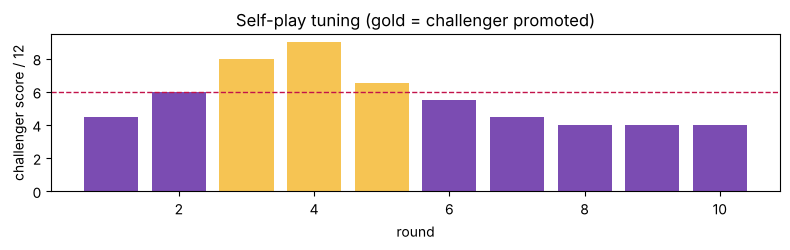

In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
if HISTORY and plt:
    fig, ax = plt.subplots(figsize=(8, 2.6))
    scores = [h[2] for h in HISTORY]
    colours = ['#f6c453' if h[3] else '#7b4cb2' for h in HISTORY]
    ax.bar(range(1, len(scores) + 1), scores, color=colours)
    ax.axhline(6, color='#c2134a', lw=1, ls='--')
    ax.set_xlabel('round'); ax.set_ylabel('challenger score / 12')
    ax.set_title('Self-play tuning (gold = challenger promoted)')
    plt.tight_layout(); plt.show()

## Part 3. The soundtrack

Every note in MateCheck is synthesized right here with NumPy and SciPy. No samples, no presets. The toolkit has band-limited oscillators, additive harps, harpsichords, pianos and marimbas, FM bells and electric piano, formant-filtered choirs, detuned saw pads, brass with a moving filter, synthesized drums, rain, thunder and wind, plus a convolution reverb.

For the story and the matches I wanted the sound of a long adventure: the big, hopeful openings of the travelling-crew shows I grew up on, where every new island or village gets its own tune. So there is a second kit for that: taiko and the small shime drum, a plucked koto, a breathy bamboo flute with a scoop into each note, accordion, overdriven power chords, French horn, staccato strings, risers, impacts and crashes.

| Cue | Where it plays |
|---|---|
| `hall_theme` | The landing page: royal synthwave in D minor with a harpsichord flourish and a brass fanfare |
| `op_theme` | The prologue overture, 150 BPM: koto intro, the band crashes in, flute verse, a brass chorus on the title drop, one last hit. The pan across the realm is cut to its bars |
| `story_adventure` | Act one, the old realm: taiko, koto and bamboo flute in D dorian |
| `story_lament` | Act two, the lonely king: rain, cello and piano in A minor |
| `story_heavens` | Act three, the voice from the heavens: choir, bells and shimmer |
| `wish_granted` | The moment the wish is granted: reversed cymbal, timpani roll, a blazing D major chord |
| `story_cliffhanger`, `cliff_hit` | The ending: a tritone drone and heartbeat, then *dun, dun, DUN* |
| `tutorial_theme` | The lessons: marimba and soft strings |
| `play_voyage`, `play_caravan`, `play_forest`, `play_skyship`, `play_village`, `play_summit` | The journey: six exploration themes (a sea shanty, a desert caravan, a glowing forest, a sky voyage, a hidden village, a mountain view). During a match each one plays for about a minute, then the next crossfades in, in a fresh shuffled order every lap |
| `play_clash` | The battle cue. When a king is in check, dawn is close, someone is nearly home or your clock runs low, the journey cuts to this and comes back once things calm down |
| `victory`, `defeat`, `curtain` | Stingers |

Looping cues fold their reverb tail back over the start so they loop without a seam. The MP3 encoder adds 1105 samples of silence at the front, so the exact length of every cue goes into `manifest.js` and the browser skips that lead-in when it loops. Browsers won't fetch files when a page is opened straight from disk, so the same MP3s are also packed into `soundbank.js` as base64 for that case.

In [8]:
# ---- tiny synth toolkit -----------------------------------------------------
# Everything here is plain NumPy/SciPy. Mono signals are 1-D float arrays,
# stereo buses are (2, n) arrays. Times are in seconds.

SR = 44100
_rng = np.random.default_rng(2026)


def secs(t):
    return int(round(t * SR))


def hz(note):
    """'A4' -> 440.0, also accepts MIDI numbers."""
    if isinstance(note, (int, float, np.integer, np.floating)):
        return 440.0 * 2 ** ((float(note) - 69) / 12)
    names = {'C': 0, 'D': 2, 'E': 4, 'F': 5, 'G': 7, 'A': 9, 'B': 11}
    n = names[note[0]]
    rest = note[1:]
    while rest and rest[0] in '#b':
        n += 1 if rest[0] == '#' else -1
        rest = rest[1:]
    midi = n + 12 * (int(rest) + 1)
    return 440.0 * 2 ** ((midi - 69) / 12)


def t_axis(dur):
    return np.arange(secs(dur)) / SR


# ---- envelopes -----------------------------------------------------------------
def adsr(dur, a=0.01, d=0.1, s=0.7, r=0.2):
    """Envelope covering `dur` seconds of hold plus `r` seconds of release."""
    n_hold, n_rel = secs(dur), secs(r)
    na, nd = min(secs(a), n_hold), min(secs(d), max(n_hold - secs(a), 0))
    ns = max(n_hold - na - nd, 0)
    env = np.concatenate([
        np.linspace(0, 1, na, endpoint=False),
        np.linspace(1, s, nd, endpoint=False),
        np.full(ns, s),
    ])
    last = env[-1] if len(env) else 0.0
    return np.concatenate([env, np.linspace(last, 0, n_rel)])


def expdecay(dur, tau):
    return np.exp(-t_axis(dur) / tau)


# ---- oscillators ------------------------------------------------------------------
def _phase(freq, n, phase0=0.0):
    f = np.full(n, float(freq)) if np.isscalar(freq) else np.asarray(freq, dtype=float)[:n]
    return (phase0 + np.cumsum(f) / SR) % 1.0, f / SR


def saw(freq, dur, phase0=None):
    """Band-limited sawtooth (polyBLEP)."""
    n = secs(dur)
    ph, dt = _phase(freq, n, _rng.random() if phase0 is None else phase0)
    y = 2 * ph - 1
    m = ph < dt
    t = ph[m] / dt[m]
    y[m] -= t + t - t * t - 1
    m = ph > 1 - dt
    t = (ph[m] - 1) / dt[m]
    y[m] -= t * t + t + t + 1
    return y


def square(freq, dur, width=0.5):
    p0 = _rng.random()
    return 0.5 * (saw(freq, dur, p0) - saw(freq, dur, (p0 + width) % 1.0))


def sine(freq, dur, phase0=0.0):
    n = secs(dur)
    ph, _ = _phase(freq, n, phase0)
    return np.sin(2 * np.pi * ph)


def vibrato(f0, dur, rate=5.5, depth=0.004, delay=0.25):
    t = t_axis(dur)
    ramp = np.clip((t - delay) / 0.4, 0, 1)
    return f0 * (1 + depth * ramp * np.sin(2 * np.pi * rate * t))


def noise(dur):
    return _rng.standard_normal(secs(dur))


def pink(dur):
    n = secs(dur)
    white = _rng.standard_normal(n)
    b = [0.049922035, -0.095993537, 0.050612699, -0.004408786]
    a = [1, -2.494956002, 2.017265875, -0.522189400]
    return signal.lfilter(b, a, white) * 3.5


def brown(dur):
    y = np.cumsum(_rng.standard_normal(secs(dur)))
    y = signal.sosfilt(signal.butter(1, 20, 'high', fs=SR, output='sos'), y)
    return y / (np.abs(y).max() + 1e-9)


# ---- filters ------------------------------------------------------------------------
def lp(x, fc, order=2):
    return signal.sosfilt(signal.butter(order, min(fc, SR * 0.45), 'low', fs=SR, output='sos'), x)


def hp(x, fc, order=2):
    return signal.sosfilt(signal.butter(order, fc, 'high', fs=SR, output='sos'), x)


def bp(x, lo, hi, order=2):
    return signal.sosfilt(signal.butter(order, [lo, min(hi, SR * 0.45)], 'band', fs=SR, output='sos'), x)


def lp_sweep(x, cutoffs, block=256):
    """Low-pass with a moving cutoff (one value per sample), done in small blocks."""
    y = np.empty_like(x)
    zi = np.zeros((1, 2))
    for i in range(0, len(x), block):
        fc = float(np.clip(cutoffs[min(i + block // 2, len(cutoffs) - 1)], 30, SR * 0.45))
        sos = signal.butter(2, fc, 'low', fs=SR, output='sos')
        y[i:i + block], zi = signal.sosfilt(sos, x[i:i + block], zi=zi)
    return y


# ---- instruments ------------------------------------------------------------------------
def additive(f0, dur, partials, decay_base=1.2, decay_slope=0.6, inharm=0.0, attack=0.003):
    """Sum of decaying partials - plucks, harps, harpsichords, marimbas, pianos."""
    t = t_axis(dur)
    y = np.zeros_like(t)
    for k, amp in enumerate(partials, start=1):
        fk = f0 * k * np.sqrt(1 + inharm * k * k)
        if fk > SR * 0.45:
            break
        y += amp * np.sin(2 * np.pi * fk * t + _rng.random() * 6.283) * np.exp(-t * (decay_base + decay_slope * k))
    y *= np.clip(t / attack, 0, 1)
    return y


def harp(note, dur=2.5):
    f = hz(note)
    return additive(f, dur, [1, 0.5, 0.28, 0.16, 0.09, 0.05, 0.03], decay_base=1.1, decay_slope=0.9)


def harpsichord(note, dur=1.6):
    f = hz(note)
    parts = [0.7, 0.9, 0.8, 0.55, 0.6, 0.35, 0.4, 0.25, 0.2, 0.15, 0.12, 0.08]
    a = additive(f, dur, parts, decay_base=2.2, decay_slope=0.55)
    b = additive(f * 1.0018, dur, parts, decay_base=2.4, decay_slope=0.6)   # second string, slightly off
    pluck = hp(noise(0.012), 3000) * 0.08
    y = 0.55 * (a + b)
    y[:len(pluck)] += pluck
    return y


def marimba(note, dur=1.2):
    f = hz(note)
    t = t_axis(dur)
    y = np.sin(2 * np.pi * f * t) * np.exp(-t * 3.2)
    y += 0.35 * np.sin(2 * np.pi * f * 3.93 * t) * np.exp(-t * 14)
    y += 0.12 * np.sin(2 * np.pi * f * 9.2 * t) * np.exp(-t * 30)
    return y * np.clip(t / 0.002, 0, 1)


def piano(note, dur=3.0):
    f = hz(note)
    y = additive(f, dur, [1, 0.55, 0.3, 0.22, 0.12, 0.08, 0.05, 0.03], decay_base=0.7, decay_slope=0.55, inharm=0.0004)
    hammer = lp(noise(0.02), 2500) * np.linspace(1, 0, secs(0.02)) * 0.05
    y[:len(hammer)] += hammer
    return y


def music_box(note, dur=2.0):
    f = hz(note)
    t = t_axis(dur)
    y = np.sin(2 * np.pi * f * t) * np.exp(-t * 2.2) + 0.25 * np.sin(2 * np.pi * f * 4.1 * t) * np.exp(-t * 9)
    return y * np.clip(t / 0.001, 0, 1)


def fm_bell(note, dur=4.0, ratio=3.5, index=2.6, tau=1.4):
    f = hz(note)
    t = t_axis(dur)
    mod = index * np.exp(-t / (tau * 0.5)) * np.sin(2 * np.pi * f * ratio * t)
    y = np.sin(2 * np.pi * f * t + mod) * np.exp(-t / tau)
    return y * np.clip(t / 0.002, 0, 1)


def rhodes(note, dur=2.5, vel=0.8):
    f = hz(note)
    t = t_axis(dur)
    idx = (1.2 + 1.8 * vel) * np.exp(-t * 3)
    y = np.sin(2 * np.pi * f * t + idx * np.sin(2 * np.pi * f * t))
    tine = 0.15 * vel * np.sin(2 * np.pi * f * 14 * t) * np.exp(-t * 40)
    y = (y + tine) * np.exp(-t * 0.9) * (1 + 0.12 * np.sin(2 * np.pi * 4.5 * t))
    return y * np.clip(t / 0.003, 0, 1)


def pluck(note, dur=0.5, bright=4000):
    """Synth pluck: square wave through a fast-closing low-pass."""
    f = hz(note)
    x = square(f, dur, 0.4) * 0.8 + saw(f, dur) * 0.3
    t = t_axis(dur)
    cut = 300 + bright * np.exp(-t * 18)
    return lp_sweep(x, cut) * np.exp(-t * 5)


def supersaw(notes, dur, cutoff=1800, attack=0.6, release=1.2, voices=5, spread=0.012):
    """Lush detuned saw pad for a whole chord."""
    total = dur + release
    y = np.zeros(secs(total))
    dets = np.linspace(-spread, spread, voices)
    for nt in notes:
        f = hz(nt)
        for dv in dets:
            y += saw(f * (1 + dv), total)
    y /= max(1, len(notes) * voices) ** 0.5 * 2.2
    y = lp(y, cutoff)
    return y * adsr(dur, attack, 0.4, 0.85, release)[:len(y)]


def strings(notes, dur, attack=0.8, release=1.5, cutoff=2600):
    total = dur + release
    y = np.zeros(secs(total))
    for nt in notes:
        f = hz(nt)
        for dv in (-0.004, 0.0, 0.005):
            y += saw(vibrato(f * (1 + dv), total, rate=5.0 + _rng.random(), depth=0.003), total)
    y = lp(y, cutoff) / (len(notes) * 3) ** 0.5 / 2.2
    return y * adsr(dur, attack, 0.5, 0.9, release)[:len(y)]


def cello(note, dur, release=0.8):
    f = hz(note)
    total = dur + release
    x = saw(vibrato(f, total, rate=5.2, depth=0.006, delay=0.3), total)
    x = lp(x, 1400) + 0.35 * bp(x, 250, 900)
    bow = bp(noise(total), 900, 3200) * 0.02
    return (x + bow) * adsr(dur, 0.25, 0.3, 0.85, release)[:secs(total)]


def flute(note, dur, release=0.25):
    f = hz(note)
    total = dur + release
    fv = vibrato(f, total, rate=5.6, depth=0.005, delay=0.18)
    y = sine(fv, total) + 0.18 * sine(fv * 2, total) + 0.05 * sine(fv * 3, total)
    breath = bp(noise(total), f * 1.5, f * 4) * 0.05
    return (y + breath) * adsr(dur, 0.06, 0.1, 0.85, release)[:secs(total)]


def brass(note, dur, release=0.3, bright=1.0):
    f = hz(note)
    total = dur + release
    t = t_axis(total)
    x = saw(vibrato(f, total, rate=5.0, depth=0.003, delay=0.35), total) * 0.7
    x += saw(f * 1.003, total) * 0.3
    cut = 500 + bright * (2600 * (1 - np.exp(-t / 0.05)) * np.exp(-t / 1.6) + 900)
    return lp_sweep(x, cut) * adsr(dur, 0.03, 0.2, 0.8, release)[:len(t)]


VOWEL_AH = [(730, 1.0, 90), (1090, 0.5, 110), (2440, 0.25, 160)]
VOWEL_OO = [(300, 1.0, 60), (870, 0.35, 90), (2240, 0.1, 140)]


def choir(notes, dur, vowel=VOWEL_AH, attack=1.2, release=2.0, voices=3):
    total = dur + release
    y = np.zeros(secs(total))
    for nt in notes:
        f = hz(nt)
        for v in range(voices):
            src = saw(vibrato(f * (1 + (v - 1) * 0.006), total, rate=4.8 + _rng.random(), depth=0.006, delay=0.2), total)
            for fc, amp, bw in vowel:
                y += amp * bp(src, fc - bw, fc + bw)
    y += bp(noise(total), 2000, 6000) * 0.02 * len(notes)
    y /= (len(notes) * voices) ** 0.5 * 1.5
    return y * adsr(dur, attack, 0.5, 0.9, release)[:len(y)]


def sub_bass(note, dur, release=0.2):
    f = hz(note)
    total = dur + release
    y = np.tanh(1.6 * sine(f, total)) * 0.8 + 0.2 * sine(2 * f, total)
    return y * adsr(dur, 0.01, 0.1, 0.9, release)[:secs(total)]


def synth_bass(note, dur, release=0.08):
    f = hz(note)
    total = dur + release
    t = t_axis(total)
    x = saw(f, total) * 0.6 + sine(f / 2, total) * 0.7
    x = lp_sweep(x, 250 + 1400 * np.exp(-t * 14))
    return x * adsr(dur, 0.004, 0.08, 0.75, release)[:len(t)]


# ---- percussion ------------------------------------------------------------------------
def kick(dur=0.45, punch=1.0):
    t = t_axis(dur)
    f = 45 + 110 * np.exp(-t * 28)
    ph = np.cumsum(f) / SR
    y = np.sin(2 * np.pi * ph) * np.exp(-t * 7)
    click = hp(noise(0.006), 2500) * 0.25 * punch
    y[:len(click)] += click
    return np.tanh(1.4 * y)


def snare(dur=0.35):
    t = t_axis(dur)
    tone = np.sin(2 * np.pi * 185 * t) * np.exp(-t * 22)
    rattle = bp(noise(dur), 1500, 9000) * np.exp(-t * 14)
    return 0.55 * tone + 0.8 * rattle


def hat(dur=0.08, open_=False):
    d = 0.35 if open_ else dur
    t = t_axis(d)
    return hp(noise(d), 7500) * np.exp(-t * (9 if open_ else 55)) * 0.5


def shaker(dur=0.12):
    t = t_axis(dur)
    env = np.minimum(t / 0.03, 1) * np.exp(-t * 30)
    return bp(noise(dur), 5000, 12000) * env * 0.5


def tambourine(dur=0.25):
    t = t_axis(dur)
    jingle = sum(np.sin(2 * np.pi * f * t) for f in (5200, 6700, 8100, 9600)) / 4
    return (hp(noise(dur), 6000) * 0.6 + jingle * 0.4) * np.exp(-t * 16) * 0.6


def hand_drum(dur=0.4, pitch=110):
    t = t_axis(dur)
    f = pitch * (1 + 0.6 * np.exp(-t * 40))
    y = np.sin(2 * np.pi * np.cumsum(f) / SR) * np.exp(-t * 10)
    slap = bp(noise(0.03), 800, 3000) * 0.3
    y[:len(slap)] += slap
    return y


def timpani(note='D2', dur=3.0, vel=1.0):
    f = hz(note)
    t = t_axis(dur)
    ff = f * (1 + 0.04 * np.exp(-t * 6))
    ph = np.cumsum(ff) / SR
    y = np.sin(2 * np.pi * ph) * np.exp(-t * 1.4)
    y += 0.5 * np.sin(2 * np.pi * ph * 1.5) * np.exp(-t * 2.5)
    y += 0.25 * np.sin(2 * np.pi * ph * 1.98) * np.exp(-t * 3.5)
    mallet = lp(noise(0.04), 1800) * np.linspace(1, 0, secs(0.04)) * 0.5
    y[:len(mallet)] += mallet
    return y * vel


def cymbal(dur=4.0, reverse=False):
    t = t_axis(dur)
    y = hp(noise(dur), 4000) * np.exp(-t * 1.3) + 0.4 * bp(noise(dur), 2500, 6000) * np.exp(-t * 2.5)
    y *= 0.45
    return y[::-1].copy() if reverse else y


def drum_roll(dur=3.0, start_rate=10, end_rate=26, crescendo=True):
    y = np.zeros(secs(dur) + secs(0.4))
    t = 0.0
    while t < dur:
        k = t / dur
        rate = start_rate + (end_rate - start_rate) * k
        vel = (0.15 + 0.85 * k ** 1.6) if crescendo else 0.7
        hit = snare(0.25) * vel * (0.85 + 0.3 * _rng.random())
        i = secs(t)
        y[i:i + len(hit)] += hit[:len(y) - i]
        t += 1.0 / rate
    return y


# ---- ambience -------------------------------------------------------------------------
def rain(dur):
    bed = lp(pink(dur), 3500) * 0.18 + hp(noise(dur), 6000) * 0.03
    drops = np.zeros(secs(dur))
    for _ in range(int(dur * 25)):
        i = _rng.integers(0, len(drops) - 2000)
        d = hp(noise(0.01), 3000) * np.exp(-np.arange(secs(0.01)) / 60) * _rng.uniform(0.05, 0.25)
        drops[i:i + len(d)] += d
    return bed + drops


def thunder(dur=6.0):
    t = t_axis(dur)
    env = np.exp(-t / 1.6) * (0.6 + 0.4 * np.abs(np.sin(2 * np.pi * 0.9 * t + _rng.random())))
    crack = hp(noise(0.25), 800) * np.exp(-np.arange(secs(0.25)) / 1500) * 0.6
    y = lp(brown(dur), 180) * env * 2.2
    y[:len(crack)] += crack
    return y


def wind(dur, lo=300, hi=1200):
    t = t_axis(dur)
    y = np.zeros(secs(dur))
    base = pink(dur)
    for k in range(3):
        sweep = lo + (hi - lo) * (0.5 + 0.5 * np.sin(2 * np.pi * (0.05 + 0.03 * k) * t + k))
        y += lp_sweep(base, sweep) * 0.3
    return hp(y, 120)


# ---- mixing -----------------------------------------------------------------------------
def reverb_ir(seconds=2.8, damp=5000, pre=0.02, seed=11):
    r = np.random.default_rng(seed)
    n = secs(seconds)
    t = np.arange(n) / SR
    env = np.exp(-6.9 * t / seconds)
    ir = np.zeros((2, n + secs(pre)))
    for ch in range(2):
        x = r.standard_normal(n) * env
        x = lp(x, damp) * 0.7 + x * 0.3 * np.exp(-t * 8)
        ir[ch, secs(pre):] = x
    # a few early reflections
    for d, g in ((0.011, 0.5), (0.019, 0.35), (0.027, 0.3), (0.041, 0.2)):
        ir[0, secs(d)] += g
        ir[1, secs(d * 1.13)] += g
    return ir / np.sqrt((ir ** 2).sum(axis=1, keepdims=True))


class Mix:
    """A stereo mixing desk with one reverb send. Loops fold their tails back to the start."""

    def __init__(self, length, tail=6.0, loop=True):
        self.n = secs(length)
        self.tail = secs(tail)
        self.loop = loop
        self.dry = np.zeros((2, self.n + self.tail))
        self.send = np.zeros((2, self.n + self.tail))

    def add(self, sig, at, gain=1.0, pan=0.0, wet=0.25):
        sig = np.asarray(sig)
        i = secs(at)
        if i >= self.dry.shape[1]:
            return
        if sig.ndim == 1:
            l = np.cos((pan + 1) * np.pi / 4)
            r = np.sin((pan + 1) * np.pi / 4)
            st = np.vstack([sig * l, sig * r]) * np.sqrt(2)
        else:
            st = sig
        end = min(i + st.shape[1], self.dry.shape[1])
        self.dry[:, i:end] += st[:, :end - i] * gain
        if wet:
            self.send[:, i:end] += st[:, :end - i] * gain * wet

    def render(self, ir, wet_level=1.0, master=0.9, width=1.0):
        out = self.dry.copy()
        for ch in range(2):
            out[ch] += signal.fftconvolve(self.send[ch], ir[ch])[:out.shape[1]] * wet_level
        if width != 1.0:
            mid = (out[0] + out[1]) / 2
            side = (out[0] - out[1]) / 2 * width
            out = np.vstack([mid + side, mid - side])
        if self.loop:
            out[:, :self.tail] += out[:, self.n:self.n + self.tail]
            out = out[:, :self.n]
        out = hp(out, 25)
        peak = np.abs(out).max() + 1e-9
        out = np.tanh(out / peak * 1.15) / np.tanh(1.15) * master
        return out


def write_mp3(path, stereo, kbps=128):
    import lameenc
    pcm = (np.clip(stereo.T, -1, 1) * 32767).astype('<i2').tobytes()
    enc = lameenc.Encoder()
    enc.set_bit_rate(kbps)
    enc.set_in_sample_rate(SR)
    enc.set_channels(2)
    enc.set_quality(2)
    data = enc.encode(pcm) + enc.flush()
    with open(path, 'wb') as fh:
        fh.write(data)
    return len(data)


# ---- adventure kit: festival drums, koto, flute and a rock band, for overtures and long journeys ---------
def taiko(dur=1.2, pitch=62, vel=1.0):
    """Big festival drum: a dropping boom, a skin slap and a short room."""
    t = t_axis(dur)
    f = pitch * (1 + 0.8 * np.exp(-t * 30))
    body = np.sin(2 * np.pi * np.cumsum(f) / SR) * np.exp(-t * 5.5)
    body += 0.3 * np.sin(2 * np.pi * np.cumsum(f * 1.6) / SR) * np.exp(-t * 9)
    slap = bp(noise(0.05), 300, 2500) * np.exp(-np.arange(secs(0.05)) / 300) * 0.5
    body[:len(slap)] += slap
    return np.tanh(1.5 * body) * vel


def shime(dur=0.15):
    """Small high-tuned drum for fast patterns."""
    t = t_axis(dur)
    y = np.sin(2 * np.pi * 420 * t) * np.exp(-t * 35) + bp(noise(dur), 1500, 6000) * np.exp(-t * 50) * 0.4
    return y * 0.6


def koto(note, dur=1.6):
    """Plucked silk string: bright attack, quick decay, a little bend."""
    f = hz(note)
    t = t_axis(dur)
    bend = f * (1 + 0.012 * np.exp(-t * 25))
    ph = np.cumsum(bend) / SR
    y = np.zeros_like(t)
    for k, a in enumerate([1, 0.6, 0.45, 0.3, 0.22, 0.12, 0.08], start=1):
        if f * k > SR * 0.45:
            break
        y += a * np.sin(2 * np.pi * k * ph) * np.exp(-t * (2.0 + 1.1 * k))
    pick = hp(noise(0.008), 4000) * 0.15
    y[:len(pick)] += pick
    return y * np.clip(t / 0.002, 0, 1)


def shakuhachi(note, dur, release=0.3):
    """Breathy bamboo flute with a pitch scoop into each note."""
    f = hz(note)
    total = dur + release
    t = t_axis(total)
    scoop = f * (1 - 0.04 * np.exp(-t * 9))
    fv = scoop * (1 + 0.006 * np.clip((t - 0.3) / 0.5, 0, 1) * np.sin(2 * np.pi * 5.2 * t))
    tone = sine(fv, total) + 0.25 * sine(fv * 2, total) + 0.08 * sine(fv * 3, total)
    breath = bp(noise(total), f * 0.8, f * 5) * (0.12 + 0.1 * np.exp(-t * 6))
    return (tone * 0.8 + breath) * adsr(dur, 0.09, 0.2, 0.8, release)[:len(t)]


def accordion(notes, dur, release=0.15):
    """Two slightly detuned reeds per note with a bellows wobble."""
    total = dur + release
    t = t_axis(total)
    y = np.zeros(len(t))
    for nt in notes:
        f = hz(nt)
        y += square(f, total, 0.3) * 0.5 + saw(f * 1.004, total) * 0.4
    y = lp(y, 2600) / max(1, len(notes)) ** 0.5
    y *= 1 + 0.08 * np.sin(2 * np.pi * 5.5 * t)
    return y * adsr(dur, 0.04, 0.1, 0.85, release)[:len(t)]


def power_chord(root, dur, mute=False):
    """Distorted guitar: root, fifth and octave through a soft clipper."""
    f = hz(root)
    total = dur + 0.05
    t = t_axis(total)
    x = saw(f, total) + saw(f * 1.5, total) * 0.8 + saw(f * 2, total) * 0.6 + saw(f * 1.003, total) * 0.5
    x = np.tanh(x * 3.5)
    x = lp(x, 2200 if not mute else 900)
    x = x + 0.4 * bp(x, 700, 1800)
    env = np.exp(-t * (12 if mute else 0.6)) * adsr(dur, 0.004, 0.05, 0.9, 0.05)[:len(t)]
    return x * env * 0.5


def horn(note, dur, release=0.4):
    return brass(note, dur, release=release, bright=0.55)


def staccato_strings(notes, dur=0.18):
    return strings(notes, dur, attack=0.01, release=0.12, cutoff=3200)


def riser(dur=2.0):
    t = t_axis(dur)
    x = lp_sweep(noise(dur), 300 + 9000 * (t / dur) ** 2) * (t / dur) ** 1.5
    tone = sine(200 * 2 ** (3 * t / dur), dur) * (t / dur) * 0.2
    return x * 0.4 + tone


def impact(dur=3.0):
    """Orchestral hit with a sub drop under it."""
    t = t_axis(dur)
    sub = np.sin(2 * np.pi * np.cumsum(55 * (1 + np.exp(-t * 6))) / SR) * np.exp(-t * 1.8)
    crash = cymbal(dur) * 0.5
    return np.tanh(sub * 1.6) * 0.9 + crash + taiko(dur, 48) * 0.6


def crash(dur=3.0):
    return cymbal(dur) * 0.8

In [9]:
# ---- the MateCheck soundtrack ------------------------------------------------------
# Each function returns a finished stereo buffer. Loops are cut so the end flows
# straight back into the start (reverb tails are folded over the loop point).


def grid(bpm):
    return 60.0 / bpm


def hall_theme():
    """Landing page: royal synthwave in D minor, 100 BPM, 16 bars."""
    b = grid(100)
    bar = 4 * b
    mix = Mix(16 * bar, tail=5)
    chords = [['D4', 'F4', 'A4'], ['D4', 'F4', 'Bb4'], ['C4', 'F4', 'A4'], ['C4', 'E4', 'G4'],
              ['D4', 'F4', 'A4'], ['D4', 'F4', 'Bb4'], ['D4', 'G4', 'Bb4'], ['C#4', 'E4', 'A4']]
    roots = ['D2', 'Bb1', 'F2', 'C2', 'D2', 'Bb1', 'G1', 'A1']
    for i, ch in enumerate(chords):
        t0 = i * 2 * bar
        pad = supersaw(ch + [ch[0].replace('4', '3')], 2 * bar - 0.05, cutoff=1500, attack=0.4, release=1.0)
        # gentle pump on every beat
        tt = np.arange(len(pad)) / SR
        pad *= 0.72 + 0.28 * np.clip(((tt % b) / (b * 0.6)), 0, 1)
        mix.add(pad, t0, gain=0.55, wet=0.35)
        for e in range(16):  # eighth-note bass, octave pumping
            nt = roots[i] if e % 2 == 0 else roots[i][:-1] + str(int(roots[i][-1]) + 1)
            mix.add(synth_bass(nt, b / 2 * 0.8), t0 + e * b / 2, gain=0.42 if e % 2 == 0 else 0.3, wet=0.02)
        # sixteenth arpeggio with a dotted-eighth echo
        tones = [ch[0], ch[1], ch[2], ch[0].replace('4', '5'), ch[2], ch[1]]
        for s16 in range(32):
            nt = tones[s16 % len(tones)].replace('4', '5') if i >= 4 else tones[s16 % len(tones)]
            pl = pluck(nt, 0.35, bright=3200)
            at = t0 + s16 * b / 4
            pan = -0.35 if s16 % 2 else 0.35
            mix.add(pl, at, gain=0.13, pan=pan, wet=0.25)
            mix.add(pl, at + 0.75 * b, gain=0.05, pan=-pan, wet=0.4)
    # harpsichord flourish over the first eight bars - the "royal" in retro-royal
    figure = [0, 2, 1, 2, 0, 2, 1, 2]
    for i in range(4):
        ch = chords[i]
        for k in range(16):
            nt = ch[figure[k % 8]].replace('4', '5')
            mix.add(harpsichord(nt, 0.9), i * 2 * bar + k * b / 2, gain=0.16, pan=-0.2, wet=0.3)
    # drums: bars 5-16 full, 1-4 hats only
    for bi in range(16):
        t0 = bi * bar
        for e in range(8):
            mix.add(hat(open_=(e == 7 and bi % 2)), t0 + e * b / 2, gain=0.22 if e % 2 else 0.14, pan=0.25, wet=0.05)
        if bi >= 4:
            mix.add(kick(), t0, gain=0.8, wet=0.02)
            mix.add(kick(), t0 + 2 * b, gain=0.8, wet=0.02)
            if bi % 2:
                mix.add(kick(), t0 + 2.5 * b, gain=0.5, wet=0.02)
            mix.add(snare(), t0 + b, gain=0.45, wet=0.7)
            mix.add(snare(), t0 + 3 * b, gain=0.45, wet=0.7)
    # brass lead fanfare, bars 9-16
    melody = [('A4', 1), ('D5', 1), ('F5', 1), ('E5', .5), ('D5', .5), ('A5', 2), ('G5', 1), ('F5', 1),
              ('F5', 1.5), ('G5', .5), ('A5', 1), ('Bb5', 1), ('A5', 2), ('F5', 2),
              ('G5', 1), ('Bb5', 1), ('D6', 2), ('C6', 1), ('Bb5', 1), ('A5', 2),
              ('E5', 1), ('A5', 1), ('C#6', 2), ('A5', 3), (None, 1)]
    t = 8 * bar
    for nt, d in melody:
        if nt:
            mix.add(brass(nt, d * b * 0.92), t, gain=0.24, pan=0.1, wet=0.4)
            mix.add(brass(nt.replace('5', '4').replace('6', '5'), d * b * 0.92, bright=0.6), t, gain=0.1, pan=-0.2, wet=0.4)
        t += d * b
    return mix.render(reverb_ir(2.4, 6000), wet_level=0.9, master=0.88)



def story_lament():
    """The lonely king: rain, a mournful cello and a soft piano, A minor, 66 BPM."""
    b = grid(66)
    bar = 4 * b
    mix = Mix(12 * bar, tail=7)
    prog = [['A2', 'E3', 'A3', 'C4'], ['F2', 'C3', 'A3', 'C4'], ['C3', 'G3', 'C4', 'E4'], ['E2', 'B2', 'G#3', 'B3'],
            ['A2', 'E3', 'A3', 'C4'], ['D3', 'A3', 'D4', 'F4'], ['F2', 'C3', 'A3', 'C4'], ['E2', 'B2', 'G#3', 'B3'],
            ['A2', 'E3', 'A3', 'C4'], ['F2', 'C3', 'A3', 'C4'], ['D3', 'A3', 'D4', 'F4'], ['E2', 'B2', 'G#3', 'D4']]
    for i, ch in enumerate(prog):
        t0 = i * bar
        order = [0, 1, 2, 3, 2, 1, 2, 3]
        for k in range(8):
            mix.add(piano(ch[order[k]], 2.6), t0 + k * b / 2, gain=0.2 * (0.9 if k % 2 else 1.0), pan=-0.15, wet=0.45)
        mix.add(strings([ch[1], ch[2]], bar - 0.1, attack=1.0, release=1.4, cutoff=1500), t0, gain=0.16, wet=0.5)
    melody = [('A3', 2), ('C4', 1), ('B3', 1), ('A3', 3), ('F3', 1), ('G3', 2), ('E3', 1), ('G3', 1),
              ('G#3', 2), ('B3', 1), ('E4', 1), ('C4', 2), ('B3', 1), ('A3', 1), ('F4', 2), ('E4', 1), ('D4', 1),
              ('C4', 2), ('A3', 1), ('C4', 1), ('B3', 3), ('G#3', 1), ('A3', 1), ('E4', 2), ('D4', 1),
              ('C4', 2), ('A3', 2), ('D4', 1), ('F4', 1), ('E4', 1), ('D4', 1), ('E4', 2), ('G#3', 2)]
    t = 0.0
    for nt, d in melody:
        mix.add(cello(nt, d * b * 0.97, release=0.6), t, gain=0.38, pan=0.1, wet=0.35)
        t += d * b
    for at, nt in ((2.5, 'E6'), (4.25, 'C6'), (6.5, 'A5'), (9.25, 'B5'), (10.5, 'E6')):
        mix.add(music_box(nt, 2.5), at * bar, gain=0.06, pan=0.55, wet=0.6)
    r = rain(12 * bar + 7)
    mix.add(np.vstack([r, np.roll(r, secs(0.37))]), 0, gain=0.55, wet=0.05)
    mix.add(thunder(7), 3.2 * bar, gain=0.5, pan=-0.3, wet=0.3)
    mix.add(thunder(6), 8.6 * bar, gain=0.35, pan=0.4, wet=0.3)
    return mix.render(reverb_ir(3.4, 4500), wet_level=1.0, master=0.82)


def story_heavens():
    """The voice from the heavens: choir, bells and shimmer, D lydian, ~27 s loop."""
    b = grid(70)
    bar = 4 * b
    mix = Mix(8 * bar, tail=8)
    chords = [['D3', 'A3', 'F#4', 'A4'], ['G3', 'D4', 'B4', 'C#5'], ['E3', 'B3', 'G4', 'D5'], ['A3', 'E4', 'C#5', 'E5']]
    for i, ch in enumerate(chords):
        t0 = i * 2 * bar
        mix.add(choir(ch, 2 * bar, attack=1.6, release=2.5), t0, gain=0.5, wet=0.6)
        mix.add(supersaw([ch[0], ch[2]], 2 * bar, cutoff=900, attack=1.5, release=2.0), t0, gain=0.2, wet=0.5)
        mix.add(sub_bass(ch[0].replace('3', '1'), 2 * bar, release=1.0), t0, gain=0.25, wet=0.0)
    scale = ['D6', 'E6', 'F#6', 'G#6', 'A6', 'B6', 'C#7', 'D7']
    r = np.random.default_rng(5)
    for k in range(40):
        at = r.uniform(0, 8 * bar)
        mix.add(fm_bell(scale[r.integers(0, len(scale))], 3.5, ratio=3.5, index=1.8, tau=1.1), at,
                gain=r.uniform(0.04, 0.1), pan=r.uniform(-0.8, 0.8), wet=0.7)
    t = t_axis(8 * bar + 8)
    shimmer = sum(np.sin(2 * np.pi * hz(n) * t) * (0.5 + 0.5 * np.sin(2 * np.pi * (0.11 + 0.07 * i) * t + i))
                  for i, n in enumerate(['A6', 'D7', 'F#7', 'C#7']))
    mix.add(shimmer * 0.03, 0, gain=1.0, wet=0.8)
    return mix.render(reverb_ir(4.5, 7000), wet_level=1.1, master=0.82)


def wish_granted():
    """Stinger: reverse cymbal, timpani roll, then a blazing D major chord."""
    mix = Mix(10.0, tail=0.1, loop=False)
    mix.add(cymbal(2.6, reverse=True), 0.0, gain=0.9, wet=0.3)
    roll = np.zeros(secs(2.7))
    for k in range(int(2.6 * 14)):
        hit = timpani('D2', 1.0, vel=0.2 + 0.8 * (k / (2.6 * 14)) ** 1.5)
        i = secs(k / 14)
        roll[i:i + len(hit)] += hit[:len(roll) - i]
    mix.add(roll, 0.0, gain=0.35, wet=0.3)
    hit = 2.6
    mix.add(timpani('D2', 4.0), hit, gain=0.8, wet=0.4)
    mix.add(cymbal(6.0), hit, gain=0.6, wet=0.4)
    mix.add(choir(['D3', 'A3', 'D4', 'F#4', 'A4', 'D5'], 4.5, attack=0.05, release=2.5), hit, gain=0.6, wet=0.6)
    for k, nt in enumerate(['D4', 'F#4', 'A4', 'D5']):
        mix.add(brass(nt, 4.0, release=1.5), hit, gain=0.18, pan=-0.4 + 0.25 * k, wet=0.5)
    for k, nt in enumerate(['D6', 'E6', 'F#6', 'A6', 'B6', 'D7', 'E7', 'F#7', 'A7']):
        mix.add(fm_bell(nt, 3.0, index=1.5), hit + 0.15 + k * 0.08, gain=0.09, pan=-0.6 + 0.15 * k, wet=0.7)
    return mix.render(reverb_ir(4.0, 7000), wet_level=1.0, master=0.9)


def story_cliffhanger():
    """Suspense bed: a tritone drone, a slow heartbeat, glassy harmonics, reversed piano."""
    b = grid(60)
    bar = 4 * b
    mix = Mix(6 * bar, tail=6)
    total = 6 * bar + 6
    t = t_axis(total)
    drone = lp(saw(hz('D1'), total) + saw(hz('Ab1'), total) * 0.7, 220) * (0.6 + 0.4 * np.sin(2 * np.pi * 0.07 * t))
    mix.add(drone * 0.5, 0, gain=1.0, wet=0.3)
    glass = (np.sin(2 * np.pi * hz('E6') * t) + 0.7 * np.sin(2 * np.pi * hz('Bb6') * t)) * (0.5 + 0.5 * np.sin(2 * np.pi * 6 * t)) * 0.03
    mix.add(glass * np.clip(t / 6, 0, 1), 0, gain=1.0, pan=0.3, wet=0.7)
    for k in range(6 * 4):
        mix.add(kick(0.35, punch=0.2), k * b, gain=0.45, wet=0.15)
        mix.add(kick(0.3, punch=0.1), k * b + 0.28, gain=0.28, wet=0.15)
    for at, nt in ((1.5, 'D5'), (3.2, 'Ab4'), (5.0, 'C#5')):
        p = piano(nt, 3.0)[::-1].copy()
        mix.add(p, at * bar, gain=0.2, pan=-0.4, wet=0.5)
    mix.add(wind(total, 200, 900), 0, gain=0.25, wet=0.3)
    return mix.render(reverb_ir(3.8, 4000), wet_level=0.9, master=0.8)


def cliff_hit():
    """Dun... dun... DUUUN."""
    mix = Mix(8.0, tail=0.1, loop=False)
    for at, notes, dur in ((0.0, ['D2', 'A2', 'D3'], 0.55), (0.8, ['D2', 'A2', 'D3'], 0.55), (1.6, ['Eb2', 'Bb2', 'Eb3', 'A3'], 4.5)):
        for nt in notes:
            mix.add(brass(nt, dur, release=1.2, bright=0.8), at, gain=0.3, wet=0.5)
        mix.add(timpani(notes[0], 3.5), at, gain=0.9, wet=0.4)
    mix.add(choir(['D4', 'Eb4', 'A4'], 4.0, vowel=VOWEL_OO, attack=0.3, release=2.0), 1.6, gain=0.4, wet=0.6)
    mix.add(cymbal(5.0), 1.6, gain=0.4, wet=0.5)
    return mix.render(reverb_ir(4.0, 5000), wet_level=0.9, master=0.9)


def tutorial_theme():
    """Curious and light: marimba and soft keys in F major, 104 BPM, 16 bars."""
    b = grid(104)
    bar = 4 * b
    mix = Mix(16 * bar, tail=4)
    chords = [['F3', 'A3', 'C4', 'E4'], ['D3', 'F3', 'A3', 'C4'], ['Bb2', 'D3', 'F3', 'A3'], ['C3', 'E3', 'G3', 'A3'],
              ['F3', 'A3', 'C4', 'E4'], ['A2', 'C3', 'E3', 'G3'], ['Bb2', 'D3', 'F3', 'A3'], ['C3', 'F3', 'G3', 'C4']]
    for i, ch in enumerate(chords):
        t0 = i * 2 * bar
        mix.add(strings([n.replace('3', '4') if n[-1] == '3' else n for n in ch[1:]], 2 * bar - 0.1, attack=0.6, release=1.0, cutoff=1800), t0, gain=0.14, wet=0.4)
        pattern = [0, 2, 1, 3, 2, 1, 3, 2]
        for k in range(16):
            nt = ch[pattern[k % 8]]
            nt = nt[:-1] + str(int(nt[-1]) + 2)
            mix.add(marimba(nt, 1.0), t0 + k * b / 2, gain=0.22 if k % 2 == 0 else 0.15, pan=(-0.3 if k % 2 else 0.3), wet=0.3)
        for k in range(4):
            mix.add(sub_bass(ch[0].replace('3', '2').replace('2', '2'), b * 0.5), t0 + k * b * 2, gain=0.3, wet=0.0)
    for bi in range(16):
        t0 = bi * bar
        mix.add(kick(0.3, punch=0.3), t0, gain=0.35, wet=0.05)
        mix.add(kick(0.3, punch=0.3), t0 + 2.5 * b, gain=0.25, wet=0.05)
        mix.add(shaker(), t0 + b, gain=0.25, pan=0.3, wet=0.1)
        mix.add(shaker(), t0 + 3 * b, gain=0.25, pan=0.3, wet=0.1)
        for e in range(8):
            mix.add(shaker(0.06), t0 + e * b / 2 + b / 4, gain=0.08, pan=-0.3, wet=0.05)
    return mix.render(reverb_ir(2.0, 6000), wet_level=0.8, master=0.8)





def victory():
    mix = Mix(8.0, tail=0.1, loop=False)
    b = grid(120)
    trip = b / 3
    for k in range(3):
        mix.add(brass('A4', trip * 0.9), k * trip, gain=0.35, wet=0.3)
    seq = [('D5', b, 1 * b), ('F#5', b * 0.5, 2 * b), ('A5', b * 0.5, 2.5 * b), ('D6', 4.0, 3 * b)]
    for nt, d, at in seq:
        mix.add(brass(nt, d, release=1.2), at, gain=0.35, wet=0.4)
        mix.add(brass(nt.replace('5', '4').replace('6', '5'), d, release=1.2, bright=0.6), at, gain=0.2, wet=0.4)
    big = 3 * b
    mix.add(timpani('D2', 3.0), big, gain=0.8, wet=0.4)
    mix.add(cymbal(5.0), big, gain=0.55, wet=0.4)
    mix.add(choir(['D3', 'A3', 'D4', 'F#4', 'A4'], 3.5, attack=0.1, release=2.0), big, gain=0.45, wet=0.5)
    for k, nt in enumerate(['D6', 'F#6', 'A6', 'D7', 'F#7', 'A7']):
        mix.add(fm_bell(nt, 2.5, index=1.4), big + 0.1 + k * 0.07, gain=0.08, pan=-0.5 + 0.2 * k, wet=0.6)
    mix.add(timpani('A1', 1.0, vel=0.6), 0, gain=0.4, wet=0.3)
    return mix.render(reverb_ir(3.0, 7000), wet_level=0.9, master=0.92)


def defeat():
    mix = Mix(7.0, tail=0.1, loop=False)
    b = grid(70)
    for k, nt in enumerate(['Bb4', 'A4', 'F4', 'D4']):
        d = b * (0.9 if k < 3 else 3.0)
        mix.add(brass(nt, d, release=1.0, bright=0.5), k * b, gain=0.32, wet=0.5)
        mix.add(cello(nt.replace('4', '3'), d), k * b, gain=0.2, wet=0.5)
    mix.add(timpani('D2', 3.5, vel=0.7), 3 * b, gain=0.6, wet=0.4)
    mix.add(choir(['D3', 'F3', 'A3'], 3.0, vowel=VOWEL_OO, attack=0.5, release=2.0), 3 * b, gain=0.3, wet=0.6)
    return mix.render(reverb_ir(3.5, 4000), wet_level=0.9, master=0.88)


def curtain():
    """Snare roll swelling into a soft boom while the velvet sweeps."""
    mix = Mix(5.0, tail=0.1, loop=False)
    mix.add(drum_roll(2.6, 12, 30), 0.0, gain=0.35, wet=0.35)
    mix.add(timpani('A1', 2.5), 2.6, gain=0.7, wet=0.4)
    mix.add(cymbal(3.0), 2.6, gain=0.3, wet=0.5)
    t = t_axis(3.2)
    sweep = lp_sweep(pink(3.2), 300 + 2500 * np.sin(np.pi * t / 3.2) ** 2) * np.sin(np.pi * t / 3.2) * 0.5
    mix.add(sweep, 0.4, gain=0.6, pan=-0.2, wet=0.3)
    return mix.render(reverb_ir(2.5, 5000), wet_level=0.8, master=0.85)


def op_theme():
    """The overture for the story's prologue: 150 BPM, 24 bars (38.4 s). The pan across the realm is cut
    to these bars: intro 0-3, the band crashes in at bar 4, verse 8-15, title drop and chorus at bar 16,
    the final hit at bar 22."""
    b = grid(150)
    bar = 4 * b
    mix = Mix(24 * bar + 4, tail=0.1, loop=False)
    # intro: koto arpeggio over wind and a soft pad, a riser into bar 4
    mix.add(wind(4 * bar + 2, 300, 1500), 0, gain=0.25, wet=0.3)
    arp = ['E4', 'B4', 'E5', 'G5', 'B5', 'G5', 'E5', 'B4']
    for k in range(32):
        mix.add(koto(arp[k % 8], 1.4), k * b / 2, gain=0.2 + 0.1 * (k / 32), pan=(-0.3 if k % 2 else 0.3), wet=0.4)
    mix.add(strings(['E4', 'B4', 'G4'], 4 * bar, attack=2.0, release=1.0, cutoff=1500), 0, gain=0.18, wet=0.5)
    mix.add(riser(2 * bar), 2 * bar, gain=0.6, wet=0.3)
    mix.add(drum_roll(bar, 10, 28), 3 * bar, gain=0.3, wet=0.3)
    verse = [('E2', ['E4', 'G4', 'B4']), ('C3', ['E4', 'G4', 'C5']), ('D3', ['F#4', 'A4', 'D5']), ('B2', ['F#4', 'A4', 'D#5'])]
    chorus = [('G2', ['G4', 'B4', 'D5']), ('D3', ['F#4', 'A4', 'D5']), ('E2', ['E4', 'G4', 'B4']), ('C3', ['E4', 'G4', 'C5']),
              ('G2', ['G4', 'B4', 'D5']), ('D3', ['F#4', 'A4', 'D5'])]
    # bars 4-15: the band
    for bi in range(4, 16):
        root, pad = verse[(bi - 4) % 4]
        t0 = bi * bar
        if bi == 4:
            mix.add(impact(3.0), t0, gain=0.9, wet=0.4)
        for e in range(8):
            mix.add(power_chord(root, b / 2 * 0.9, mute=(bi < 8 or e % 2 == 1)), t0 + e * b / 2, gain=0.42, pan=(-0.25 if e % 2 else 0.25), wet=0.1)
            mix.add(synth_bass(root.replace('3', '2').replace('2', '1') if root[-1] == '2' else root.replace('3', '2'), b / 2 * 0.8), t0 + e * b / 2, gain=0.35, wet=0.0)
        mix.add(staccato_strings(pad), t0, gain=0.18, wet=0.3)
        mix.add(staccato_strings(pad), t0 + 1.5 * b, gain=0.14, wet=0.3)
        mix.add(taiko(1.0, 60), t0, gain=0.55, wet=0.25)
        if bi >= 8:
            mix.add(kick(), t0, gain=0.75, wet=0.02); mix.add(kick(), t0 + 1.5 * b, gain=0.6, wet=0.02); mix.add(kick(), t0 + 2 * b, gain=0.75, wet=0.02)
            mix.add(snare(), t0 + b, gain=0.5, wet=0.4); mix.add(snare(), t0 + 3 * b, gain=0.5, wet=0.4)
            for e in range(8):
                mix.add(hat(), t0 + e * b / 2, gain=0.2 if e % 2 else 0.12, pan=0.3, wet=0.05)
        else:
            for e in range(4):
                mix.add(taiko(0.6, 90), t0 + e * b + b / 2, gain=0.3, pan=0.2, wet=0.2)
            for e in range(16):
                mix.add(shime(), t0 + e * b / 4, gain=0.18 if e % 4 else 0.3, pan=-0.3, wet=0.1)
    mix.add(riser(bar), 15 * bar, gain=0.6, wet=0.3)
    mix.add(drum_roll(bar, 12, 32), 15 * bar, gain=0.35, wet=0.3)
    verse_mel = [('E5', 1.5), ('G5', .5), ('B5', 2), ('A5', 1), ('G5', 1), ('E5', 2), ('F#5', 1.5), ('A5', .5), ('D6', 1), ('C6', 1),
                 ('B5', 2), ('F#5', 1), ('A5', 1), ('G5', 1), ('B5', 1), ('E6', 2), ('D6', 1), ('C6', 1), ('B5', 1), ('G5', 1),
                 ('A5', 2), ('F#5', 1), ('D5', 1), ('D#5', 2), ('F#5', 2)]
    t = 8 * bar
    for nt, d in verse_mel:
        mix.add(shakuhachi(nt, d * b * 0.95), t, gain=0.3, pan=0.1, wet=0.35)
        mix.add(horn(nt.replace('5', '4').replace('6', '5'), d * b * 0.9), t, gain=0.1, pan=-0.2, wet=0.35)
        t += d * b
    # bars 16-21: title drop and chorus in G major
    for i, (root, pad) in enumerate(chorus):
        bi = 16 + i
        t0 = bi * bar
        mix.add(crash(3.0), t0, gain=0.45 if i % 2 == 0 else 0.3, wet=0.3)
        if i == 0:
            mix.add(impact(3.5), t0, gain=1.0, wet=0.45)
        for e in range(8):
            mix.add(power_chord(root, b / 2 * 0.95), t0 + e * b / 2, gain=0.45, pan=(-0.3 if e % 2 else 0.3), wet=0.12)
            mix.add(synth_bass(root.replace('3', '2').replace('2', '1') if root[-1] == '2' else root.replace('3', '2'), b / 2 * 0.8), t0 + e * b / 2, gain=0.38, wet=0.0)
        mix.add(strings(pad, bar - 0.05, attack=0.1, release=0.6, cutoff=3200), t0, gain=0.25, wet=0.4)
        for e in range(4):
            mix.add(kick(), t0 + e * b, gain=0.75, wet=0.02)
            mix.add(taiko(0.8, 70), t0 + e * b, gain=0.25, wet=0.2)
        mix.add(snare(), t0 + b, gain=0.55, wet=0.45); mix.add(snare(), t0 + 3 * b, gain=0.55, wet=0.45)
        for e in range(8):
            mix.add(hat(open_=(e == 7)), t0 + e * b / 2, gain=0.2, pan=0.3, wet=0.05)
    hook = [('B4', 1), ('D5', 1), ('G5', 1.5), ('F#5', .5), ('A5', 2), ('F#5', 1), ('D5', 1), ('E5', 1), ('G5', 1), ('B5', 1.5), ('A5', .5),
            ('G5', 2), ('E5', 1), ('C5', 1), ('D5', 1), ('G5', 1), ('A5', 1), ('B5', 1), ('A5', 1.5), ('G5', .5), ('F#5', 1), ('D5', 1)]
    t = 16 * bar
    for nt, d in hook:
        mix.add(brass(nt, d * b * 0.92, release=0.3), t, gain=0.3, pan=0.05, wet=0.4)
        mix.add(brass(nt.replace('5', '4').replace('4', '4'), d * b * 0.92, release=0.3, bright=0.6), t, gain=0.12, pan=-0.3, wet=0.4)
        mix.add(shakuhachi(nt.replace('4', '5').replace('5', '6') if nt[-1] == '4' else nt, d * b * 0.9), t, gain=0.12, pan=0.35, wet=0.4)
        t += d * b
    # bar 22: the last hit, ringing out
    end = 22 * bar
    mix.add(impact(5.0), end, gain=1.0, wet=0.5)
    mix.add(power_chord('G2', 2 * bar), end, gain=0.45, wet=0.3)
    mix.add(brass('G5', 2 * bar, release=1.5), end, gain=0.3, wet=0.5)
    mix.add(brass('D5', 2 * bar, release=1.5), end, gain=0.2, wet=0.5)
    mix.add(strings(['G4', 'B4', 'D5', 'G5'], 2 * bar, attack=0.05, release=2.0, cutoff=3500), end, gain=0.3, wet=0.5)
    mix.add(fm_bell('G6', 4.0), end + 0.05, gain=0.12, wet=0.6)
    return mix.render(reverb_ir(2.4, 6500), wet_level=0.85, master=0.86)


def story_adventure():
    """World-building theme for the old realm: taiko, koto and a bamboo flute, D dorian, 104 BPM, 16 bars."""
    b = grid(104)
    bar = 4 * b
    mix = Mix(16 * bar, tail=5)
    prog = [['D3', 'A3', 'F4'], ['C3', 'G3', 'E4'], ['Bb2', 'F3', 'D4'], ['C3', 'G3', 'E4']]
    for i in range(8):
        ch = prog[i % 4]
        t0 = i * 2 * bar
        mix.add(strings([n[:-1] + str(int(n[-1]) + 1) for n in ch], 2 * bar - 0.1, attack=0.8, release=1.2, cutoff=2400), t0, gain=0.2, wet=0.45)
        mix.add(sub_bass(ch[0].replace('3', '2').replace('Bb2', 'Bb1'), 2 * bar - 0.2, release=0.4), t0, gain=0.25, wet=0.0)
        pat = [0, 1, 2, 1, 2, 0, 1, 2]
        for k in range(16):
            nt = ch[pat[k % 8]]
            nt = nt[:-1] + str(int(nt[-1]) + 1)
            mix.add(koto(nt, 1.2), t0 + k * b / 2, gain=0.17, pan=(-0.35 if k % 2 else 0.35), wet=0.35)
    for bi in range(16):
        t0 = bi * bar
        mix.add(taiko(1.2, 58), t0, gain=0.45, wet=0.3)
        mix.add(taiko(0.8, 75, 0.7), t0 + 2.5 * b, gain=0.3, wet=0.3)
        if bi % 2 == 1:
            mix.add(taiko(0.6, 95, 0.6), t0 + 3.5 * b, gain=0.25, wet=0.3)
        for e in range(8):
            mix.add(shime(), t0 + e * b / 2, gain=0.08 if e % 2 else 0.13, pan=-0.4, wet=0.1)
    melody = [('D5', 1.5), ('E5', .5), ('F5', 1), ('A5', 1), ('G5', 2), ('E5', 2), ('F5', 1.5), ('G5', .5), ('A5', 1), ('C6', 1), ('A5', 4),
              ('A5', 1), ('C6', 1), ('D6', 2), ('C6', 1), ('A5', 1), ('G5', 2), ('F5', 1), ('E5', 1), ('C5', 1), ('E5', 1), ('D5', 4),
              ('F5', 1), ('G5', 1), ('A5', 2), ('G5', 1), ('E5', 1), ('C5', 2), ('D5', 1.5), ('E5', .5), ('F5', 1), ('A5', 1), ('G5', 4),
              ('A5', 1), ('G5', 1), ('F5', 1), ('E5', 1), ('D5', 2), ('C5', 2), ('D5', 8)]
    t = 0.0
    for nt, d in melody:
        mix.add(shakuhachi(nt, d * b * 0.95), t, gain=0.3, pan=0.1, wet=0.45)
        t += d * b
    return mix.render(reverb_ir(3.0, 6000), wet_level=0.95, master=0.85)


def play_voyage():
    """Gameplay: a calm sea shanty in 6/8, accordion and plucked strings, D major."""
    b = grid(96)      # dotted-quarter pulse
    bar = 2 * b
    mix = Mix(24 * bar, tail=4)
    prog = [['D4', 'F#4', 'A4'], ['G3', 'B3', 'D4'], ['A3', 'C#4', 'E4'], ['D4', 'F#4', 'A4'],
            ['B3', 'D4', 'F#4'], ['G3', 'B3', 'D4'], ['E3', 'G3', 'B3'], ['A3', 'C#4', 'E4']]
    for i in range(24):
        ch = prog[i % 8]
        t0 = i * bar
        mix.add(accordion(ch, b * 0.6), t0 + b / 3, gain=0.12, pan=-0.2, wet=0.3)
        mix.add(accordion(ch, b * 0.6), t0 + b + b / 3, gain=0.1, pan=-0.2, wet=0.3)
        mix.add(sub_bass(ch[0][:-1] + '2', b * 0.6), t0, gain=0.28, wet=0.0)
        mix.add(sub_bass(ch[2][:-1] + '2', b * 0.5), t0 + b, gain=0.2, wet=0.0)
        for k, nt in enumerate([ch[0], ch[1], ch[2], ch[1], ch[2], ch[1]]):
            mix.add(koto(nt[:-1] + str(int(nt[-1]) + 1), 1.0), t0 + k * b / 3, gain=0.08, pan=0.35, wet=0.35)
        mix.add(hand_drum(pitch=100), t0, gain=0.25, wet=0.15)
        mix.add(hand_drum(0.2, pitch=160), t0 + b, gain=0.12, wet=0.15)
    mel = [('A5', 1), ('F#5', .33), ('A5', .67), ('D6', 1), ('B5', 1), ('A5', 1), ('F#5', 1), ('E5', 2),
           ('F#5', 1), ('A5', 1), ('B5', 1), ('A5', 1), ('F#5', 1), ('E5', 1), ('D5', 2)]
    for rep in (4, 16):
        t = rep * bar
        for nt, d in mel:
            mix.add(flute(nt, d * b * 0.95), t, gain=0.14, pan=0.15, wet=0.45)
            t += d * b
    r = np.random.default_rng(9)
    waves = lp(pink(24 * bar + 4), 700) * (0.5 + 0.5 * np.sin(2 * np.pi * t_axis(24 * bar + 4) / 7.3)) * 0.12
    mix.add(waves, 0, gain=1.0, wet=0.2)
    for _ in range(5):
        mix.add(fm_bell(['A6', 'D7', 'F#6'][r.integers(0, 3)], 2.0, ratio=2.0, index=0.8), r.uniform(0, 24 * bar), gain=0.04, pan=r.uniform(-.7, .7), wet=0.7)
    return mix.render(reverb_ir(2.6, 5000), wet_level=0.85, master=0.8)


def play_village():
    """Gameplay: a quiet hidden village, koto and bamboo flute on A minor pentatonic, 76 BPM."""
    b = grid(76)
    bar = 4 * b
    mix = Mix(14 * bar, tail=6)
    prog = [['A2', 'E3', 'C4'], ['F2', 'C3', 'A3'], ['G2', 'D3', 'B3'], ['E2', 'B2', 'G3']]
    for i in range(14):
        ch = prog[(i // 2) % 4]
        t0 = i * bar
        if i % 2 == 0:
            mix.add(strings([n[:-1] + str(int(n[-1]) + 1) for n in ch[1:]], 2 * bar - 0.1, attack=1.5, release=2.0, cutoff=1600), t0, gain=0.16, wet=0.5)
            mix.add(sub_bass(ch[0], 2 * bar - 0.3, release=0.8), t0, gain=0.22, wet=0.0)
        for k, nt in enumerate([ch[0], ch[1], ch[2], ch[1]]):
            nt2 = nt[:-1] + str(int(nt[-1]) + 2)
            mix.add(koto(nt2, 1.8), t0 + k * b + (b / 2 if k % 2 else 0), gain=0.15, pan=(-0.3 if k % 2 else 0.3), wet=0.4)
        mix.add(taiko(1.5, 55, 0.5), t0, gain=0.25, wet=0.35)
    mel = [('E5', 2), ('D5', 1), ('C5', 1), ('A4', 3), ('G4', 1), ('A4', 2), ('C5', 1), ('D5', 1), ('E5', 4),
           ('G5', 2), ('E5', 1), ('D5', 1), ('C5', 2), ('D5', 1), ('E5', 1), ('A4', 6)]
    t = 2 * bar
    for nt, d in mel:
        mix.add(shakuhachi(nt, d * b * 0.95), t, gain=0.22, pan=0.1, wet=0.5)
        t += d * b
    mix.add(wind(14 * bar + 6, 200, 900), 0, gain=0.1, wet=0.3)
    r = np.random.default_rng(31)
    for _ in range(8):
        mix.add(fm_bell(['A6', 'C7', 'E7', 'G6'][r.integers(0, 4)], 3.0, ratio=3.0, index=0.9, tau=1.3), r.uniform(0, 14 * bar), gain=0.04, pan=r.uniform(-.7, .7), wet=0.8)
    return mix.render(reverb_ir(4.0, 5000), wet_level=1.0, master=0.78)


def play_summit():
    """Gameplay: the view from the mountain, wide strings and a slow horn, G major, 72 BPM."""
    b = grid(72)
    bar = 4 * b
    mix = Mix(16 * bar, tail=6)
    prog = [['G3', 'D4', 'B4'], ['E3', 'B3', 'G4'], ['C3', 'G3', 'E4'], ['D3', 'A3', 'F#4']]
    for i in range(8):
        ch = prog[i % 4]
        t0 = i * 2 * bar
        mix.add(strings(ch + [ch[1][:-1] + str(int(ch[1][-1]) + 1)], 2 * bar - 0.1, attack=1.4, release=2.0, cutoff=2200), t0, gain=0.28, wet=0.55)
        mix.add(sub_bass(ch[0].replace('3', '2'), 2 * bar - 0.3, release=0.8), t0, gain=0.22, wet=0.0)
        mix.add(timpani(ch[0].replace('3', '2'), 3.0, vel=0.4), t0, gain=0.2, wet=0.4)
        for k in range(8):
            nt = ch[k % 3]
            mix.add(harp(nt[:-1] + str(int(nt[-1]) + 1), 2.0), t0 + k * b, gain=0.12, pan=(-0.3 if k % 2 else 0.3), wet=0.45)
    mel = [('D5', 2), ('G5', 2), ('F#5', 1), ('E5', 1), ('D5', 2), ('B4', 2), ('C5', 1), ('D5', 1), ('E5', 4), ('D5', 4),
           ('G5', 2), ('A5', 2), ('B5', 3), ('A5', 1), ('G5', 2), ('E5', 2), ('F#5', 2), ('D5', 6)]
    t = 4 * bar
    for nt, d in mel:
        mix.add(horn(nt.replace('5', '4'), d * b * 0.95), t, gain=0.22, pan=0.1, wet=0.5)
        t += d * b
    mix.add(wind(16 * bar + 6, 300, 1200), 0, gain=0.07, wet=0.3)
    return mix.render(reverb_ir(4.2, 5500), wet_level=1.0, master=0.8)


def _oct(n, k):
    """shift a note name by k octaves: _oct('F#4', 1) -> 'F#5'"""
    return n[:-1] + str(int(n[-1]) + k)


def play_caravan():
    """Gameplay: a caravan crossing the dunes to a market town, D hijaz, hand drums and plucks, 108 BPM."""
    b = grid(108)
    bar = 4 * b
    mix = Mix(16 * bar, tail=4)
    prog = [('D2', ['D4', 'F#4', 'A4']), ('D2', ['D4', 'F#4', 'A4']), ('C2', ['C4', 'Eb4', 'G4']), ('D2', ['D4', 'F#4', 'A4']),
            ('G1', ['G3', 'Bb3', 'D4']), ('Eb2', ['Eb4', 'G4', 'Bb4']), ('C2', ['C4', 'Eb4', 'G4']), ('D2', ['D4', 'F#4', 'A4'])]
    for i in range(16):
        root, ch = prog[i % 8]
        t0 = i * bar
        # doumbek-style groove: dum . tek tek dum . tek .
        for pos, kind in [(0, 'dum'), (1, 'tek'), (1.5, 'tek'), (2, 'dum'), (3, 'tek'), (3.5, 'ka')]:
            if kind == 'dum':
                mix.add(hand_drum(0.5, pitch=85), t0 + pos * b, gain=0.4, wet=0.15)
            else:
                mix.add(hand_drum(0.15, pitch=320), t0 + pos * b, gain=0.16 if kind == 'tek' else 0.1, pan=0.3, wet=0.15)
        mix.add(tambourine(), t0 + 1 * b, gain=0.08, pan=-0.4, wet=0.2)
        mix.add(tambourine(), t0 + 3 * b, gain=0.08, pan=-0.4, wet=0.2)
        mix.add(sub_bass(root, b * 0.8), t0, gain=0.3, wet=0.0)
        mix.add(sub_bass(root, b * 0.4), t0 + 2.5 * b, gain=0.2, wet=0.0)
        # oud-ish plucks on the off-beats
        for k, nt in enumerate([ch[0], ch[2], ch[1], ch[2], ch[0], ch[2], ch[1], ch[2]]):
            mix.add(pluck(nt, 0.6, bright=2600), t0 + k * b / 2, gain=0.12 if k % 2 else 0.17, pan=-0.25, wet=0.3)
        if i >= 4:
            mix.add(strings([_oct(n, 1) for n in ch], bar - 0.1, attack=0.6, release=0.8, cutoff=2000), t0, gain=0.1, wet=0.45)
    mel = [('A5', 1), ('Bb5', .5), ('A5', .5), ('G5', 1), ('F#5', 1), ('G5', .5), ('A5', .5), ('Bb5', 1), ('A5', 2),
           ('D6', 1), ('C6', .5), ('Bb5', .5), ('A5', 1), ('G5', 1), ('F#5', .5), ('G5', .5), ('Eb5', 1), ('D5', 2),
           ('F#5', 1), ('G5', 1), ('A5', 1), ('Bb5', 1), ('C6', 1.5), ('Bb5', .5), ('A5', 2),
           ('G5', 1), ('F#5', 1), ('Eb5', 1), ('F#5', .5), ('G5', .5), ('D5', 4)]
    for rep in (2, 10):
        t = rep * bar
        for nt, d in mel:
            mix.add(shakuhachi(nt, d * b * 0.92), t, gain=0.22, pan=0.15, wet=0.45)
            t += d * b
    mix.add(wind(16 * bar + 4, 250, 900), 0, gain=0.08, wet=0.3)
    return mix.render(reverb_ir(2.4, 5200), wet_level=0.8, master=0.8)


def play_skyship():
    """Gameplay: setting sail across the clouds, bright strings and brass, F major, 124 BPM."""
    b = grid(124)
    bar = 4 * b
    mix = Mix(16 * bar, tail=4)
    prog = [('F2', ['F4', 'A4', 'C5']), ('C2', ['E4', 'G4', 'C5']), ('D2', ['D4', 'F4', 'A4']), ('Bb1', ['D4', 'F4', 'Bb4']),
            ('F2', ['F4', 'A4', 'C5']), ('C2', ['E4', 'G4', 'C5']), ('Bb1', ['D4', 'F4', 'Bb4']), ('C2', ['E4', 'G4', 'C5'])]
    for i in range(16):
        root, ch = prog[i % 8]
        t0 = i * bar
        # driving string ostinato in eighths
        for e in range(8):
            mix.add(staccato_strings([ch[e % 3], _oct(ch[0], 1)] if e % 2 == 0 else [ch[(e + 1) % 3]]), t0 + e * b / 2, gain=0.13, pan=(-0.3 if e % 2 else 0.3), wet=0.3)
        mix.add(strings([_oct(n, -1) for n in ch], bar - 0.05, attack=0.3, release=0.6, cutoff=1800), t0, gain=0.13, wet=0.4)
        for e in range(4):
            mix.add(synth_bass(root, b * 0.8), t0 + e * b, gain=0.26, wet=0.0)
        if i >= 2:
            mix.add(kick(punch=0.7), t0, gain=0.45, wet=0.02); mix.add(kick(punch=0.7), t0 + 2 * b, gain=0.4, wet=0.02)
            mix.add(snare(), t0 + b, gain=0.22, wet=0.35); mix.add(snare(), t0 + 3 * b, gain=0.22, wet=0.35)
            for e in range(8):
                mix.add(shaker(), t0 + e * b / 2, gain=0.1 if e % 2 else 0.06, pan=0.4, wet=0.05)
        if i % 4 == 0:
            mix.add(timpani(root.replace('1', '2'), 2.5, vel=0.5), t0, gain=0.25, wet=0.4)
            mix.add(crash(2.5), t0, gain=0.12, wet=0.3)
    hook = [('C5', 1), ('F5', 1), ('G5', 1), ('A5', 1), ('C6', 2), ('A5', 1), ('G5', 1), ('F5', 1.5), ('G5', .5), ('A5', 1), ('D5', 1), ('F5', 4),
            ('Bb5', 1), ('A5', 1), ('G5', 1), ('F5', 1), ('A5', 2), ('G5', 2), ('F5', 1), ('E5', 1), ('F5', 1), ('G5', 1), ('C5', 4)]
    for rep, inst in ((4, 'brass'), (12, 'flute')):
        t = rep * bar
        for nt, d in hook:
            if inst == 'brass':
                mix.add(brass(nt, d * b * 0.92), t, gain=0.22, pan=0.05, wet=0.4)
                mix.add(horn(_oct(nt, -1), d * b * 0.92), t, gain=0.1, pan=-0.25, wet=0.4)
            else:
                mix.add(flute(_oct(nt, 1) if nt[-1] == '5' and nt[0] in 'CDE' else nt, d * b * 0.92), t, gain=0.17, pan=0.15, wet=0.45)
                mix.add(brass(nt, d * b * 0.92), t, gain=0.12, pan=-0.1, wet=0.4)
            t += d * b
    mix.add(wind(16 * bar + 4, 500, 2500), 0, gain=0.06, wet=0.2)
    return mix.render(reverb_ir(2.2, 6500), wet_level=0.8, master=0.8)


def play_forest():
    """Gameplay: lost in an old forest of glowing roots, marimba and music box, E minor, 84 BPM."""
    b = grid(84)
    bar = 4 * b
    mix = Mix(16 * bar, tail=6)
    prog = [['E3', 'B3', 'G4'], ['C3', 'G3', 'E4'], ['A2', 'E3', 'C4'], ['B2', 'F#3', 'D#4']]
    for i in range(16):
        ch = prog[(i // 2) % 4]
        t0 = i * bar
        pat = [0, 2, 1, 2, 0, 2, 1, 2]
        for k in range(8):
            mix.add(marimba(_oct(ch[pat[k]], 1), 0.8), t0 + k * b / 2, gain=0.14 if k % 2 else 0.18, pan=(-0.35 if k % 2 else 0.2), wet=0.4)
        if i % 2 == 0:
            mix.add(choir([_oct(n, 1) for n in ch[1:]], 2 * bar - 0.2, attack=1.6, release=2.0), t0, gain=0.11, wet=0.6)
            mix.add(sub_bass(ch[0].replace('3', '2'), 2 * bar - 0.3, release=0.8), t0, gain=0.2, wet=0.0)
        mix.add(hand_drum(0.5, pitch=70), t0, gain=0.2, wet=0.3)
        mix.add(hand_drum(0.3, pitch=110), t0 + 2.5 * b, gain=0.12, wet=0.3)
        mix.add(shaker(), t0 + 1.5 * b, gain=0.06, pan=0.4, wet=0.2)
        mix.add(shaker(), t0 + 3.5 * b, gain=0.06, pan=0.4, wet=0.2)
    mel = [('B5', 1.5), ('A5', .5), ('G5', 1), ('E5', 1), ('F#5', 2), ('D#5', 2), ('E5', 1), ('G5', 1), ('B5', 1), ('E6', 1), ('D6', 2), ('B5', 2),
           ('C6', 1.5), ('B5', .5), ('A5', 1), ('G5', 1), ('E5', 2), ('C5', 2), ('D#5', 1), ('F#5', 1), ('A5', 1), ('B5', 1), ('E5', 4)]
    for rep, inst in ((4, 'flute'), (12, 'box')):
        t = rep * bar
        for nt, d in mel:
            if inst == 'flute':
                mix.add(flute(nt, d * b * 0.92), t, gain=0.16, pan=0.1, wet=0.55)
            else:
                mix.add(music_box(_oct(nt, 1), 1.6), t, gain=0.1, pan=0.25, wet=0.6)
                mix.add(shakuhachi(nt, d * b * 0.9), t, gain=0.14, pan=-0.1, wet=0.55)
            t += d * b
    r = np.random.default_rng(77)
    for _ in range(10):
        mix.add(fm_bell(['E7', 'B6', 'G6', 'D#7'][r.integers(0, 4)], 2.5, ratio=2.7, index=1.0, tau=1.0), r.uniform(0, 16 * bar), gain=0.035, pan=r.uniform(-.8, .8), wet=0.8)
    mix.add(wind(16 * bar + 6, 150, 700), 0, gain=0.09, wet=0.3)
    return mix.render(reverb_ir(4.0, 4800), wet_level=1.0, master=0.78)


def play_clash():
    """Gameplay, when it gets tense (a royal in check, the clock or dawn running out): C minor, 138 BPM."""
    b = grid(138)
    bar = 4 * b
    mix = Mix(16 * bar, tail=3)
    prog = [('C2', ['C4', 'Eb4', 'G4']), ('Ab1', ['C4', 'Eb4', 'Ab4']), ('Bb1', ['D4', 'F4', 'Bb4']), ('G1', ['D4', 'G4', 'B4'])]
    for i in range(16):
        root, ch = prog[(i // 2) % 4] if i < 8 else prog[i % 4]
        t0 = i * bar
        for e in range(16):
            if e % 4 != 3:
                mix.add(staccato_strings([ch[0], ch[2]] if e % 2 == 0 else [ch[1]]), t0 + e * b / 4, gain=0.1 if e % 2 else 0.14, pan=(-0.3 if e % 2 else 0.3), wet=0.25)
        for e in range(8):
            mix.add(power_chord(root.replace('1', '2'), b / 2 * 0.85, mute=True), t0 + e * b / 2, gain=0.22, pan=(-0.2 if e % 2 else 0.2), wet=0.05)
            mix.add(synth_bass(root, b / 2 * 0.8), t0 + e * b / 2, gain=0.24, wet=0.0)
        mix.add(taiko(1.0, 58), t0, gain=0.5, wet=0.25)
        mix.add(taiko(0.7, 62), t0 + 1.5 * b, gain=0.32, wet=0.25)
        mix.add(taiko(1.0, 58), t0 + 2 * b, gain=0.42, wet=0.25)
        mix.add(taiko(0.6, 90), t0 + 3 * b, gain=0.3, wet=0.25)
        mix.add(taiko(0.6, 90), t0 + 3.5 * b, gain=0.3, wet=0.25)
        mix.add(snare(), t0 + b, gain=0.3, wet=0.4); mix.add(snare(), t0 + 3 * b, gain=0.3, wet=0.4)
        if i % 4 == 0:
            mix.add(crash(2.5), t0, gain=0.15, wet=0.3)
        if i >= 8:
            mix.add(brass(_oct(ch[2], 0), b * 0.4), t0, gain=0.16, wet=0.3)
            mix.add(brass(_oct(ch[2], 0), b * 0.4), t0 + 1.5 * b, gain=0.16, wet=0.3)
    mel = [('G5', 2), ('Ab5', 1), ('G5', 1), ('F5', 2), ('Eb5', 2), ('D5', 1), ('Eb5', 1), ('F5', 1), ('G5', 1), ('C5', 4),
           ('Eb5', 2), ('F5', 1), ('G5', 1), ('Ab5', 2), ('Bb5', 2), ('B5', 2), ('D6', 2), ('C6', 4)]
    t = 8 * bar
    for nt, d in mel:
        mix.add(horn(_oct(nt, -1), d * b * 0.92), t, gain=0.2, pan=-0.1, wet=0.4)
        mix.add(strings([nt], d * b * 0.92, attack=0.05, release=0.3, cutoff=3500), t, gain=0.14, pan=0.2, wet=0.4)
        t += d * b
    return mix.render(reverb_ir(2.0, 6000), wet_level=0.7, master=0.8)


TRACKS = {
    'hall_theme': hall_theme,
    'op_theme': op_theme,
    'story_adventure': story_adventure,
    'story_lament': story_lament,
    'story_heavens': story_heavens,
    'wish_granted': wish_granted,
    'story_cliffhanger': story_cliffhanger,
    'cliff_hit': cliff_hit,
    'tutorial_theme': tutorial_theme,
    'play_voyage': play_voyage,
    'play_village': play_village,
    'play_summit': play_summit,
    'play_caravan': play_caravan,
    'play_skyship': play_skyship,
    'play_forest': play_forest,
    'play_clash': play_clash,
    'victory': victory,
    'defeat': defeat,
    'curtain': curtain,
}

In [10]:
AUDIO = ROOT / 'assets/audio'
LOOPS = {'hall_theme', 'story_adventure', 'story_lament', 'story_heavens', 'story_cliffhanger', 'tutorial_theme',
         'play_voyage', 'play_caravan', 'play_forest', 'play_skyship', 'play_village', 'play_summit', 'play_clash'}
# a little levelling so no theme jumps out when the journey moves on
GAIN = {'story_adventure': 0.85, 'tutorial_theme': 0.85, 'play_voyage': 0.85, 'play_village': 0.9, 'play_summit': 0.82,
        'play_caravan': 0.95, 'play_skyship': 0.85, 'play_forest': 0.8, 'play_clash': 0.9}

if RENDER_AUDIO:
    manifest, bank = {'rate': SR, 'delay': 1105, 'tracks': {}}, {}
    print(f"{'cue':18s} {'length':>7s} {'peak':>5s} {'loudness':>9s} {'size':>7s}")
    for name, compose_fn in TRACKS.items():
        stereo = compose_fn()
        size = write_mp3(AUDIO / (name + '.mp3'), stereo)
        manifest['tracks'][name] = {'samples': int(stereo.shape[1]), 'loop': name in LOOPS, 'gain': GAIN.get(name, 1.0)}
        bank[name] = base64.b64encode((AUDIO / (name + '.mp3')).read_bytes()).decode('ascii')
        rms = 20 * np.log10(np.sqrt((stereo ** 2).mean()) + 1e-9)
        print(f'{name:18s} {stereo.shape[1] / SR:6.1f}s {np.abs(stereo).max():5.2f} {rms:7.1f} dB {size / 1024:5.0f} KB')
    (AUDIO / 'manifest.js').write_text(
        '/* MateCheck audio manifest - written by MateCheck.ipynb. Exact lengths keep the loops gapless. */\n'
        'window.MateCheckAudioManifest = ' + json.dumps(manifest, indent=1) + ';\n')
    (AUDIO / 'soundbank.js').write_text(
        '/* MateCheck sound bank - the MP3 cues as base64, used when the game is opened from disk (file://). Written by MateCheck.ipynb. */\n'
        'window.MateCheckSoundBank = {\n' + ',\n'.join('"%s": "%s"' % kv for kv in bank.items()) + '\n};\n')
    print(f"\nsound bank: {(AUDIO / 'soundbank.js').stat().st_size / 1e6:.1f} MB")
else:
    print('Keeping the cues already in assets/audio.')

cue                 length  peak  loudness    size


hall_theme           38.4s  0.88   -14.4 dB   600 KB


op_theme             42.5s  0.86   -17.9 dB   664 KB


story_adventure      36.9s  0.85   -12.9 dB   578 KB


story_lament         43.6s  0.82   -14.1 dB   682 KB


...

play_forest          45.7s  0.78   -12.9 dB   715 KB


play_clash           27.8s  0.80   -14.4 dB   436 KB


victory               8.1s  0.92   -17.9 dB   127 KB


defeat                7.1s  0.88   -14.0 dB   111 KB


curtain               5.1s  0.85   -19.5 dB    80 KB

sound bank: 11.9 MB


In [11]:
# Have a listen (works when Jupyter is running from the MateCheck folder)
from IPython.display import Audio, display
display(Audio(url='assets/audio/op_theme.mp3'))

## Part 4. Writing the web build

From here on, every cell writes one file that `index.html` loads. Edit a cell, run it again, refresh the browser.

`index.html` itself stays as the main file: the landing page, the theatre and the game screen are laid out there, and it pulls in the scripts in this order: engine, weights, brain, pieces, audio manifest, sound, board, theatre, tutorial, game, main. Scripts are plain files (no modules, no build step), so the game also runs when you double-click `index.html`.

### Fonts

Limelight (the marquee lettering) and Chakra Petch (everything else) are embedded as data URIs, because Chrome refuses to load font files from `file://`. Both are under the SIL Open Font License; the licence texts sit next to the font files.

In [12]:
FONTS = ROOT / 'assets/fonts'
faces = [('Limelight', 'limelight-latin-400-normal.woff2', 400, 'normal')]
faces += [('Chakra Petch', f'chakra-petch-latin-{w}-normal.woff2', w, 'normal') for w in (400, 500, 600, 700)]
faces += [('Chakra Petch', 'chakra-petch-latin-400-italic.woff2', 400, 'italic')]
css = ('/* MateCheck fonts, embedded so they load even from file:// (written by MateCheck.ipynb).\n'
       '   Limelight (c) Sorkin Type, Chakra Petch (c) Cadson Demak - SIL Open Font License 1.1, see assets/fonts. */\n')
for family, file, weight, style in faces:
    data = base64.b64encode((FONTS / file).read_bytes()).decode()
    css += ("@font-face { font-family: '%s'; font-style: %s; font-weight: %d; font-display: swap; "
            "src: url(data:font/woff2;base64,%s) format('woff2'); }\n" % (family, style, weight, data))
(ROOT / 'assets/css/fonts.css').write_text(css)
print('assets/css/fonts.css', round(len(css) / 1024), 'KB')

assets/css/fonts.css 97 KB


### The rules engine (`assets/js/engine.js`)

In [13]:
%%writefile assets/js/engine.js
/*
 * MateCheck - rules engine
 * Copyright (c) 2026 Swayam Shakya
 * Released under the MIT License (see LICENSE in the project root)
 *
 * How the reversed realm works, in one breath:
 *   - both sides begin with only a King and a Queen
 *   - every move may "rally": a fallen comrade rises on the square you just left,
 *     as long as that square is on your muster ground (ranks 3-4 for white, 5-6 for black)
 *   - pieces that reach their starting square are sealed there for good
 *   - pawns march backwards, home to their own second rank
 *   - only the royals still strike: a king or queen can banish an enemy comrade
 *     back to its reserve; risen comrades never strike and never give check
 *   - comrades shield each other: in its own half of the board, a comrade standing
 *     next to a friendly piece can't be banished
 *   - no piece ever enters the enemy's court (their two home ranks)
 *   - check still exists, but checkmate does not: no move may corner a king
 *   - first army to stand complete in the classic opening setup wins (MateCheck!)
 *
 * Board layout: a1 = 0, b1 = 1 ... h8 = 63.
 * Pieces are small ints, positive for white, negative for black.
 *
 * The whole thing lives inside one factory function on purpose: the computer's worker
 * rebuilds the engine from this function's source text, so nothing in here may
 * reach for outside variables.
 */
(function (root, factory) {
  'use strict';
  var api = factory();
  api.factory = factory;
  if (typeof module === 'object' && module.exports) module.exports = api;
  else root.MateCheckEngine = api;
}(typeof self !== 'undefined' ? self : this, function buildMateCheckEngine() {
  'use strict';

  var WHITE = 1, BLACK = -1;
  var PAWN = 1, KNIGHT = 2, BISHOP = 3, ROOK = 4, QUEEN = 5, KING = 6;
  var RECALL = 1 << 15;
  var PASS = 1 << 16;                 // only offered when nothing else is legal
  var DEFAULT_MAX_PLY = 200;          // "dawn" - 100 moves each

  // reserve slots (bishops are tied to a square colour, just like real chess)
  var S_PAWN = 0, S_KNIGHT = 1, S_LIGHT_B = 2, S_DARK_B = 3, S_ROOK = 4, S_QUEEN = 5;
  var SLOT_LETTERS = 'PNLDRQ';

  var FILES = 'abcdefgh';
  var LETTER = ['', 'P', 'N', 'B', 'R', 'Q', 'K'];
  var NAMES = ['', 'pawn', 'knight', 'bishop', 'rook', 'queen', 'king'];

  function fileOf(s) { return s & 7; }
  function rankOf(s) { return s >> 3; }
  function isLight(s) { return ((s & 7) + (s >> 3)) & 1; }
  function sqName(s) { return FILES[s & 7] + ((s >> 3) + 1); }
  function parseSq(name) {
    if (typeof name !== 'string' || name.length !== 2) return -1;
    var f = FILES.indexOf(name[0]), r = name.charCodeAt(1) - 49;
    return (f < 0 || r < 0 || r > 7) ? -1 : r * 8 + f;
  }

  // ---- home squares -------------------------------------------------------
  var BACK_ROW = [ROOK, KNIGHT, BISHOP, QUEEN, KING, BISHOP, KNIGHT, ROOK];
  var HOME_W = new Int8Array(64), HOME_B = new Int8Array(64);
  for (var f0 = 0; f0 < 8; f0++) {
    HOME_W[f0] = BACK_ROW[f0];
    HOME_W[8 + f0] = PAWN;
    HOME_B[56 + f0] = BACK_ROW[f0];
    HOME_B[48 + f0] = PAWN;
  }
  function homeTable(color) { return color === WHITE ? HOME_W : HOME_B; }

  // a piece standing on its own starting square is sealed (kings and queens never are)
  function sealedAt(piece, sq) {
    if (piece === 0) return false;
    var t = piece > 0 ? piece : -piece;
    if (t >= QUEEN) return false;
    return (piece > 0 ? HOME_W[sq] : HOME_B[sq]) === t;
  }

  // the two home ranks of a side (where its army stands at the start of real chess)
  function inHomeRanks(color, sq) {
    var r = sq >> 3;
    return color === WHITE ? r <= 1 : r >= 6;
  }

  // the muster ground: the two ranks just in front of home - the only place the fallen rise
  function inMuster(color, sq) {
    var r = sq >> 3;
    return color === WHITE ? (r === 2 || r === 3) : (r === 4 || r === 5);
  }

  // ---- precomputed geometry ----------------------------------------------
  var KNIGHT_T = [], KING_T = [], RAYS = [];
  var PAWN_ATT_W = [], PAWN_ATT_B = [];   // squares a pawn must stand on to hit sq
  var DIRS = [[1, 0], [-1, 0], [0, 1], [0, -1], [1, 1], [1, -1], [-1, 1], [-1, -1]];
  var KN = [[1, 2], [2, 1], [2, -1], [1, -2], [-1, -2], [-2, -1], [-2, 1], [-1, 2]];

  (function precompute() {
    for (var s = 0; s < 64; s++) {
      var f = s & 7, r = s >> 3, i, nf, nr, list;
      list = [];
      for (i = 0; i < 8; i++) {
        nf = f + KN[i][0]; nr = r + KN[i][1];
        if (nf >= 0 && nf < 8 && nr >= 0 && nr < 8) list.push(nr * 8 + nf);
      }
      KNIGHT_T[s] = list;
      list = [];
      for (i = 0; i < 8; i++) {
        nf = f + DIRS[i][0]; nr = r + DIRS[i][1];
        if (nf >= 0 && nf < 8 && nr >= 0 && nr < 8) list.push(nr * 8 + nf);
      }
      KING_T[s] = list;
      for (i = 0; i < 8; i++) {
        var ray = [];
        nf = f + DIRS[i][0]; nr = r + DIRS[i][1];
        while (nf >= 0 && nf < 8 && nr >= 0 && nr < 8) {
          ray.push(nr * 8 + nf);
          nf += DIRS[i][0]; nr += DIRS[i][1];
        }
        RAYS[s * 8 + i] = ray;
      }
      // pawns march backwards and banish diagonally backwards.
      // A white pawn on (f, r) hits (f +- 1, r - 1), so it hits sq from (f -+ 1, r + 1).
      var w = [], b = [];
      if (r < 7) {
        if (f > 0) w.push(s + 7);
        if (f < 7) w.push(s + 9);
      }
      if (r > 0) {
        if (f > 0) b.push(s - 9);
        if (f < 7) b.push(s - 7);
      }
      PAWN_ATT_W[s] = w;
      PAWN_ATT_B[s] = b;
    }
  }());

  // ---- zobrist keys (deterministic, so hashes match across threads) --------
  var seed = 0x9e3779b9 | 0;
  function rnd32() {
    seed ^= seed << 13; seed ^= seed >>> 17; seed ^= seed << 5;
    return seed | 0;
  }
  var Z_PIECE_LO = new Int32Array(13 * 64), Z_PIECE_HI = new Int32Array(13 * 64);
  var Z_RES_LO = new Int32Array(12 * 10), Z_RES_HI = new Int32Array(12 * 10);
  for (var zi = 0; zi < 13 * 64; zi++) { Z_PIECE_LO[zi] = rnd32(); Z_PIECE_HI[zi] = rnd32(); }
  for (zi = 0; zi < 12 * 10; zi++) { Z_RES_LO[zi] = rnd32(); Z_RES_HI[zi] = rnd32(); }
  var Z_SIDE_LO = rnd32(), Z_SIDE_HI = rnd32();

  function slotFor(piece, sq) {
    var t = piece > 0 ? piece : -piece;
    switch (t) {
      case PAWN: return S_PAWN;
      case KNIGHT: return S_KNIGHT;
      case BISHOP: return isLight(sq) ? S_LIGHT_B : S_DARK_B;
      case ROOK: return S_ROOK;
      case QUEEN: return S_QUEEN;
      default: return -1;
    }
  }

  // ---- battlefields ---------------------------------------------------------
  var BATTLEFIELDS = {
    'last-stand': {
      name: 'The Last Stand',
      blurb: 'Both kings shield their queens near home. Quick to learn, tight to master.',
      white: { K: 'd3', Q: 'd2' }, black: { K: 'd6', Q: 'd7' }
    },
    'crossroads': {
      name: 'Crossroads',
      blurb: 'The royals meet in open country. Expect early raids.',
      white: { K: 'b3', Q: 'e3' }, black: { K: 'g6', Q: 'd6' }
    },
    'long-road': {
      name: 'The Long Road',
      blurb: 'Each royal pair wakes up deep in enemy land and must march home.',
      white: { K: 'b6', Q: 'f5' }, black: { K: 'g3', Q: 'c4' }
    }
  };
  var FULL_RESERVE = [8, 2, 1, 1, 2, 0];

  // ---- the position ---------------------------------------------------------
  var STACK = 1024;

  function Position() {
    this.board = new Int8Array(64);
    this.reserve = new Int8Array(12);   // white slots 0..5, black 6..11
    this.kings = new Int8Array(2);      // [white king sq, black king sq]
    this.side = WHITE;
    this.ply = 0;
    this.maxPly = DEFAULT_MAX_PLY;
    this.clock = 0;                     // plies since something irreversible happened
    this.hashLo = 0;
    this.hashHi = 0;
    this.sp = 0;
    this.uMove = new Int32Array(STACK);
    this.uCap = new Int8Array(STACK);
    this.uClock = new Int16Array(STACK);
    this.uHashLo = new Int32Array(STACK);
    this.uHashHi = new Int32Array(STACK);
  }

  Position.prototype.clear = function () {
    this.board.fill(0);
    this.reserve.fill(0);
    this.kings[0] = this.kings[1] = -1;
    this.side = WHITE;
    this.ply = 0;
    this.clock = 0;
    this.sp = 0;
  };

  Position.prototype.rehash = function () {
    var lo = 0, hi = 0, s, p, i;
    for (s = 0; s < 64; s++) {
      p = this.board[s];
      if (p !== 0) { lo ^= Z_PIECE_LO[(p + 6) * 64 + s]; hi ^= Z_PIECE_HI[(p + 6) * 64 + s]; }
    }
    for (i = 0; i < 12; i++) {
      lo ^= Z_RES_LO[i * 10 + this.reserve[i]];
      hi ^= Z_RES_HI[i * 10 + this.reserve[i]];
    }
    if (this.side === BLACK) { lo ^= Z_SIDE_LO; hi ^= Z_SIDE_HI; }
    this.hashLo = lo; this.hashHi = hi;
  };

  Position.prototype.findKings = function () {
    this.kings[0] = this.kings[1] = -1;
    for (var s = 0; s < 64; s++) {
      if (this.board[s] === KING) this.kings[0] = s;
      else if (this.board[s] === -KING) this.kings[1] = s;
    }
  };

  Position.prototype.setupBattlefield = function (id, maxPly) {
    var bf = BATTLEFIELDS[id] || BATTLEFIELDS['last-stand'];
    this.clear();
    this.board[parseSq(bf.white.K)] = KING;
    this.board[parseSq(bf.white.Q)] = QUEEN;
    this.board[parseSq(bf.black.K)] = -KING;
    this.board[parseSq(bf.black.Q)] = -QUEEN;
    for (var i = 0; i < 6; i++) { this.reserve[i] = FULL_RESERVE[i]; this.reserve[6 + i] = FULL_RESERVE[i]; }
    this.maxPly = maxPly || DEFAULT_MAX_PLY;
    this.findKings();
    this.rehash();
    return this;
  };

  // Compact text form: "<board> <side> <white reserve> <black reserve> <ply> <maxPly>"
  // board is FEN-like (rank 8 first), reserve looks like P8N2L1D1R2Q0
  Position.prototype.toString = function () {
    var out = '', r, f, empty, p;
    for (r = 7; r >= 0; r--) {
      empty = 0;
      for (f = 0; f < 8; f++) {
        p = this.board[r * 8 + f];
        if (p === 0) { empty++; continue; }
        if (empty) { out += empty; empty = 0; }
        out += p > 0 ? LETTER[p] : LETTER[-p].toLowerCase();
      }
      if (empty) out += empty;
      if (r) out += '/';
    }
    return out + ' ' + (this.side === WHITE ? 'w' : 'b') + ' ' +
      this.reserveString(WHITE) + ' ' + this.reserveString(BLACK) + ' ' + this.ply + ' ' + this.maxPly;
  };

  Position.prototype.reserveString = function (color) {
    var base = color === WHITE ? 0 : 6, s = '';
    for (var i = 0; i < 6; i++) s += SLOT_LETTERS[i] + this.reserve[base + i];
    return s;
  };

  Position.prototype.load = function (text) {
    var parts = String(text).trim().split(/\s+/);
    this.clear();
    var rows = parts[0].split('/');
    if (rows.length !== 8) throw new Error('bad board: ' + parts[0]);
    for (var i = 0; i < 8; i++) {
      var r = 7 - i, f = 0, row = rows[i];
      for (var j = 0; j < row.length; j++) {
        var ch = row[j];
        if (ch >= '1' && ch <= '8') { f += ch.charCodeAt(0) - 48; continue; }
        var t = LETTER.indexOf(ch.toUpperCase());
        if (t < 1 || f > 7) throw new Error('bad board: ' + parts[0]);
        this.board[r * 8 + f] = ch === ch.toUpperCase() ? t : -t;
        f++;
      }
    }
    this.side = parts[1] === 'b' ? BLACK : WHITE;
    readReserve(this.reserve, 0, parts[2] || 'P0N0L0D0R0Q0');
    readReserve(this.reserve, 6, parts[3] || 'P0N0L0D0R0Q0');
    this.ply = parts[4] ? parseInt(parts[4], 10) || 0 : 0;
    this.maxPly = parts[5] ? parseInt(parts[5], 10) || DEFAULT_MAX_PLY : DEFAULT_MAX_PLY;
    this.findKings();
    this.rehash();
    return this;
  };

  function readReserve(arr, base, text) {
    for (var i = 0; i < 6; i++) arr[base + i] = 0;
    var re = /([PNLDRQ])(\d)/g, m;
    while ((m = re.exec(text))) arr[base + SLOT_LETTERS.indexOf(m[1])] = parseInt(m[2], 10);
  }

  Position.prototype.clone = function () {
    var p = new Position();
    p.board.set(this.board);
    p.reserve.set(this.reserve);
    p.kings.set(this.kings);
    p.side = this.side; p.ply = this.ply; p.maxPly = this.maxPly; p.clock = this.clock;
    p.hashLo = this.hashLo; p.hashHi = this.hashHi;
    p.sp = this.sp;
    p.uMove.set(this.uMove); p.uCap.set(this.uCap); p.uClock.set(this.uClock);
    p.uHashLo.set(this.uHashLo); p.uHashHi.set(this.uHashHi);
    return p;
  };

  // ---- attacks ----------------------------------------------------------------
  // Only the royals still strike in the reversed realm, so only a king or a
  // queen can attack a square (and so give check).
  Position.prototype.attacked = function (sq, by) {
    var b = this.board, a, i, ray, p;
    var k = by * KING, q = by * QUEEN;
    a = KING_T[sq];
    for (i = 0; i < a.length; i++) if (b[a[i]] === k) return true;
    var base = sq * 8;
    for (var d = 0; d < 8; d++) {
      ray = RAYS[base + d];
      for (i = 0; i < ray.length; i++) {
        p = b[ray[i]];
        if (p !== 0) {
          if (p === q) return true;
          break;
        }
      }
    }
    return false;
  };

  Position.prototype.inCheck = function (color) {
    var ks = this.kings[color === WHITE ? 0 : 1];
    return ks >= 0 && this.attacked(ks, -color);
  };

  // royals of `by` that hit `sq` (for the UI and the tutorial)
  Position.prototype.attackersOf = function (sq, by) {
    var list = [], b = this.board, a, i, ray, p, base = sq * 8;
    a = KING_T[sq];
    for (i = 0; i < a.length; i++) if (b[a[i]] === by * KING) list.push(a[i]);
    for (var d = 0; d < 8; d++) {
      ray = RAYS[base + d];
      for (i = 0; i < ray.length; i++) {
        p = b[ray[i]];
        if (p !== 0) {
          if (p === by * QUEEN) list.push(ray[i]);
          break;
        }
      }
    }
    return list;
  };

  // ---- rally helpers ----------------------------------------------------------
  // bitmask of piece types (bit = 1 << type) that may rise on `sq` for `color`
  Position.prototype.rallyMask = function (color, sq) {
    if (!inMuster(color, sq)) return 0;
    var base = color === WHITE ? 0 : 6, res = this.reserve, r = sq >> 3, mask = 0;
    if (res[base + S_PAWN] > 0 && r !== 0 && r !== 7) mask |= 1 << PAWN;
    if (res[base + S_KNIGHT] > 0) mask |= 1 << KNIGHT;
    if (res[base + (isLight(sq) ? S_LIGHT_B : S_DARK_B)] > 0) mask |= 1 << BISHOP;
    if (res[base + S_ROOK] > 0) mask |= 1 << ROOK;
    if (res[base + S_QUEEN] > 0) mask |= 1 << QUEEN;
    return mask;
  };

  Position.prototype.rallyTypes = function (color, sq) {
    var mask = this.rallyMask(color, sq), out = [];
    for (var t = PAWN; t <= QUEEN; t++) if (mask & (1 << t)) out.push(t);
    return out;
  };

  // ---- move generation ------------------------------------------------------------
  // Legal means: your own king is not left attacked, and the enemy king is not
  // left attacked with no way out (the realm has outlawed checkmate).
  Position.prototype._addMove = function (out, from, to, us, kingMoving, depth) {
    if (inHomeRanks(-us, to)) return;              // the enemy court is off limits to everyone
    var b = this.board, cap = b[to], piece = b[from];
    var ks = kingMoving ? to : this.kings[us === WHITE ? 0 : 1];
    var eks = this.kings[us === WHITE ? 1 : 0];
    var mask = this.rallyMask(us, from);
    b[to] = piece; b[from] = 0;
    var illegal = this.attacked(ks, -us);
    var shieldOk = !illegal;
    if (illegal && mask) {
      // a comrade rising on the vacated square can still shield the king
      b[from] = us * PAWN;
      shieldOk = !this.attacked(ks, -us);
      b[from] = 0;
    }
    if (!shieldOk) { b[from] = piece; b[to] = cap; return; }
    // which variants give check? (only those need the expensive "is it mate?" look)
    var checks = 0, t, m = from | (to << 6);
    if (depth > 0 && eks >= 0) {
      if (!illegal && this.attacked(eks, us)) checks |= 1;
      for (t = PAWN; t <= QUEEN; t++) {
        if (!(mask & (1 << t))) continue;
        b[from] = us * t;
        if (this.attacked(eks, us)) checks |= 1 << t;
        b[from] = 0;
      }
    }
    b[from] = piece; b[to] = cap;
    if (!illegal && (!(checks & 1) || this._escapes(m, depth - 1))) out.push(m);
    for (t = PAWN; t <= QUEEN; t++) {
      if (!(mask & (1 << t))) continue;
      var mv = m | (t << 12);
      if (!(checks & (1 << t)) || this._escapes(mv, depth - 1)) out.push(mv);
    }
  };

  // After move m, can the side being checked get out of it with a move that
  // is itself legal? The question nests (an escape might corner the other
  // king), so it is asked a few levels deep and then trusted.
  Position.prototype._escapes = function (m, depth) {
    this.make(m);
    var bufs = this._escBufs || (this._escBufs = [[], [], [], [], []]);
    var buf = bufs[depth];
    this._generate(buf, depth, true);
    var ok = buf.length > 0;
    this.unmake();
    return ok;
  };

  Position.prototype._canTake = function (sq, us) {
    var p = this.board[sq];
    if (p === 0) return true;
    if (p * us > 0) return false;                  // own piece
    if (p === -us * KING) return false;            // kings are never banished
    if (sealedAt(p, sq)) return false;             // sealed pieces are untouchable
    return p === -us * QUEEN || !this.shielded(sq);
  };

  // a comrade in its own half with a friendly piece on a neighbouring square is shielded
  Position.prototype.shielded = function (sq) {
    var p = this.board[sq], b = this.board;
    if (p === 0) return false;
    var t = p > 0 ? p : -p;
    if (t === QUEEN || t === KING) return false;
    if (p > 0 ? (sq >> 3) > 3 : (sq >> 3) < 4) return false;   // out in enemy land: exposed
    var n = KING_T[sq];
    for (var i = 0; i < n.length; i++) if (b[n[i]] * p > 0) return true;
    return false;
  };

  var MATE_DEPTH = 3;

  Position.prototype.legalMoves = function (out) {
    out = out || [];
    this._generate(out, MATE_DEPTH, false);
    // never leave a king stuck in check: if every escape was filtered, allow them
    if (out.length === 0 && this.inCheck(this.side)) this._generate(out, 0, false);
    if (out.length === 0) out.push(PASS);
    return out;
  };

  Position.prototype._generate = function (out, depth, firstOnly) {
    out.length = 0;
    var b = this.board, us = this.side, home = homeTable(us);
    var s, pc, t, i, list, ray, d, a;
    for (s = 0; s < 64; s++) {
      pc = b[s] * us;
      if (pc <= 0) continue;
      if (pc < QUEEN && home[s] === pc) continue;  // sealed - it stays put forever
      switch (pc) {
        case PAWN: {
          var back = s - 8 * us, r = s >> 3, f = s & 7;
          if (back < 0 || back > 63) break;
          if (b[back] === 0) {
            this._addMove(out, s, back, us, false, depth);
            // the reverse of the opening double step
            if ((us === WHITE && r === 3) || (us === BLACK && r === 4)) {
              var two = back - 8 * us;
              if (b[two] === 0) this._addMove(out, s, two, us, false, depth);
            }
          }
          if (f > 0 && b[back - 1] === 0) this._addMove(out, s, back - 1, us, false, depth);
          if (f < 7 && b[back + 1] === 0) this._addMove(out, s, back + 1, us, false, depth);
          break;
        }
        case KNIGHT:
          list = KNIGHT_T[s];
          for (i = 0; i < list.length; i++) if (b[list[i]] === 0) this._addMove(out, s, list[i], us, false, depth);
          break;
        case KING:
          list = KING_T[s];
          for (i = 0; i < list.length; i++) {
            if (this._canTake(list[i], us)) this._addMove(out, s, list[i], us, true, depth);
          }
          break;
        default: {
          var d0 = pc === BISHOP ? 4 : 0;
          var d1 = pc === ROOK ? 4 : 8;
          for (d = d0; d < d1; d++) {
            ray = RAYS[s * 8 + d];
            for (i = 0; i < ray.length; i++) {
              t = ray[i];
              a = b[t];
              if (a === 0) { this._addMove(out, s, t, us, false, depth); continue; }
              // only the queen may strike what stands in her way
              if (pc === QUEEN && this._canTake(t, us)) this._addMove(out, s, t, us, false, depth);
              break;
            }
          }
        }
      }
      // recall: send a weary comrade back to the reserve
      if (pc !== KING) {
        var keep = b[s];
        b[s] = 0;
        var safe = !this.attacked(this.kings[us === WHITE ? 0 : 1], -us);
        b[s] = keep;
        if (safe) {
          var rm = s | (s << 6) | RECALL;
          // stepping aside can uncover a check on the enemy king - that must not be mate either
          var eks = this.kings[us === WHITE ? 1 : 0];
          if (depth > 0 && eks >= 0) {
            b[s] = 0;
            var disc = this.attacked(eks, us);
            b[s] = keep;
            if (!disc || this._escapes(rm, depth - 1)) out.push(rm);
          } else out.push(rm);
        }
      }
      if (firstOnly && out.length) return out;
    }
    return out;
  };

  // ---- make / unmake ------------------------------------------------------------------
  Position.prototype._res = function (slot, delta) {
    var c = this.reserve[slot];
    this.hashLo ^= Z_RES_LO[slot * 10 + c]; this.hashHi ^= Z_RES_HI[slot * 10 + c];
    c += delta;
    this.reserve[slot] = c;
    this.hashLo ^= Z_RES_LO[slot * 10 + c]; this.hashHi ^= Z_RES_HI[slot * 10 + c];
  };

  Position.prototype._toggle = function (p, sq) {
    this.hashLo ^= Z_PIECE_LO[(p + 6) * 64 + sq];
    this.hashHi ^= Z_PIECE_HI[(p + 6) * 64 + sq];
  };

  Position.prototype.make = function (m) {
    var from = m & 63, to = (m >> 6) & 63, rally = (m >> 12) & 7;
    var b = this.board, us = this.side, n = this.sp;
    var ourBase = us === WHITE ? 0 : 6;
    this.uMove[n] = m;
    this.uHashLo[n] = this.hashLo;
    this.uHashHi[n] = this.hashHi;
    this.uClock[n] = this.clock;
    var pc = b[from];
    if (m & PASS) {
      this.uCap[n] = 0;
      this.clock++;
    } else if (m & RECALL) {
      this.uCap[n] = pc;
      b[from] = 0;
      this._toggle(pc, from);
      this._res(ourBase + slotFor(pc, from), 1);
      this.clock = 0;
    } else {
      var cap = b[to];
      this.uCap[n] = cap;
      if (cap !== 0) {
        this._toggle(cap, to);
        this._res((us === WHITE ? 6 : 0) + slotFor(cap, to), 1);
      }
      this._toggle(pc, from);
      b[from] = 0;
      b[to] = pc;
      this._toggle(pc, to);
      if (pc === us * KING) this.kings[us === WHITE ? 0 : 1] = to;
      if (rally !== 0) {
        var rp = us * rally;
        this._res(ourBase + slotFor(rp, from), -1);
        b[from] = rp;
        this._toggle(rp, from);
      }
      if (cap !== 0 || rally !== 0 || pc === us * PAWN || sealedAt(pc, to)) this.clock = 0;
      else this.clock++;
    }
    this.side = -us;
    this.hashLo ^= Z_SIDE_LO; this.hashHi ^= Z_SIDE_HI;
    this.ply++;
    this.sp = n + 1;
  };

  Position.prototype.unmake = function () {
    var n = --this.sp;
    var m = this.uMove[n], from = m & 63, to = (m >> 6) & 63, rally = (m >> 12) & 7;
    var b = this.board;
    this.side = -this.side;
    var us = this.side, ourBase = us === WHITE ? 0 : 6;
    if (m & PASS) {
      // nothing moved
    } else if (m & RECALL) {
      var rp0 = this.uCap[n];
      b[from] = rp0;
      this.reserve[ourBase + slotFor(rp0, from)]--;
    } else {
      if (rally !== 0) this.reserve[ourBase + slotFor(us * rally, from)]++;
      var pc = b[to], cap = this.uCap[n];
      b[from] = pc;
      b[to] = cap;
      if (cap !== 0) this.reserve[(us === WHITE ? 6 : 0) + slotFor(cap, to)]--;
      if (pc === us * KING) this.kings[us === WHITE ? 0 : 1] = from;
    }
    this.hashLo = this.uHashLo[n];
    this.hashHi = this.uHashHi[n];
    this.clock = this.uClock[n];
    this.ply--;
  };

  // ---- formation & outcome ----------------------------------------------------------------
  Position.prototype.formationScore = function (color) {
    var home = homeTable(color), b = this.board, n = 0;
    for (var s = 0; s < 64; s++) if (home[s] !== 0 && b[s] === color * home[s]) n++;
    return n;
  };

  // comrades (pawns, knights, bishops, rooks) standing on the board: 0 to 14.
  // This is the score of the Grand Revival ending.
  Position.prototype.revivedCount = function (color) {
    var b = this.board, n = 0, p;
    for (var s = 0; s < 64; s++) { p = b[s] * color; if (p > 0 && p < QUEEN) n++; }
    return n;
  };

  // the Grand Revival score: one point for every comrade risen onto the board, and one
  // more for every piece standing on its home square (so a sealed rook counts twice). 0 to 30.
  Position.prototype.revivalScore = function (color) {
    return this.revivedCount(color) + this.formationScore(color);
  };

  Position.prototype.formationComplete = function (color) {
    return this.formationScore(color) === 16;
  };

  Position.prototype.sealedCount = function (color) {
    var b = this.board, n = 0;
    for (var s = 0; s < 64; s++) if (b[s] * color > 0 && sealedAt(b[s], s)) n++;
    return n;
  };

  Position.prototype.piecesOnBoard = function (color) {
    var n = 0;
    for (var s = 0; s < 64; s++) if (this.board[s] * color > 0) n++;
    return n;
  };

  Position.prototype.repetitions = function () {
    var count = 0, n = this.sp;
    for (var i = n - 2; i >= 0 && i >= n - this.clock; i -= 2) {
      if (this.uHashLo[i] === this.hashLo && this.uHashHi[i] === this.hashHi) count++;
    }
    return count;
  };

  // outcome from the point of view of the position as it stands now
  Position.prototype.outcome = function () {
    var mover = -this.side;
    if (this.formationComplete(mover)) return { over: true, winner: mover, reason: 'matecheck' };
    if (this.formationComplete(this.side)) return { over: true, winner: this.side, reason: 'matecheck' };
    if (this.ply >= this.maxPly) {
      var w = this.formationScore(WHITE), bl = this.formationScore(BLACK);
      if (w === bl) {
        w = this.piecesOnBoard(WHITE); bl = this.piecesOnBoard(BLACK);
      }
      return { over: true, winner: w > bl ? WHITE : (bl > w ? BLACK : 0), reason: 'dawn' };
    }
    return { over: false, winner: 0, reason: '' };
  };

  // ---- describing moves -------------------------------------------------------------------
  function decode(m) {
    return {
      from: m & 63,
      to: (m >> 6) & 63,
      rally: (m >> 12) & 7,
      recall: (m & RECALL) !== 0,
      pass: (m & PASS) !== 0
    };
  }

  function encode(from, to, rally, recall) {
    if (recall) return from | (from << 6) | RECALL;
    return from | (to << 6) | ((rally || 0) << 12);
  }

  // full details of a legal move, read before it is played
  Position.prototype.describe = function (m) {
    var d = decode(m), b = this.board, us = this.side;
    if (d.pass) { d.piece = 0; d.color = us; d.captured = 0; d.seals = false; d.kingHome = d.queenHome = false; return d; }
    d.piece = b[d.from];
    d.color = us;
    d.captured = d.recall ? 0 : b[d.to];
    d.seals = !d.recall && sealedAt(d.piece, d.to);
    d.rallySeals = false;
    d.kingHome = !d.recall && d.piece === us * KING && homeTable(us)[d.to] === KING;
    d.queenHome = !d.recall && d.piece === us * QUEEN && homeTable(us)[d.to] === QUEEN;
    return d;
  };

  // a short readable notation: Qd2-c2, Nf3xe5, "Qd2-c2 ^N" when a knight rises, "@Bc4" for recall
  Position.prototype.notation = function (m) {
    var d = this.describe(m), t = Math.abs(d.piece), txt;
    if (d.pass) return 'pass';
    if (d.recall) {
      txt = '@' + LETTER[t] + sqName(d.from);
    } else {
      txt = (t === PAWN ? '' : LETTER[t]) + sqName(d.from) + (d.captured ? 'x' : '-') + sqName(d.to);
      if (d.rally) txt += ' ^' + LETTER[d.rally];
    }
    this.make(m);
    var oc = this.outcome();
    if (oc.over && oc.reason === 'matecheck') txt += ' *';
    else if (this.inCheck(this.side)) txt += '+';
    this.unmake();
    return txt;
  };

  // parse the notation above back into a move from the current position
  Position.prototype.parseMove = function (text) {
    var moves = this.legalMoves([]);
    var clean = String(text).replace(/[+#*]/g, '').trim();
    if (clean === 'pass') return moves[0] === PASS ? PASS : 0;
    for (var i = 0; i < moves.length; i++) {
      var n = this.notation(moves[i]).replace(/[+#*]/g, '').trim();
      if (n === clean) return moves[i];
    }
    return 0;
  };

  Position.prototype.homeSquares = function (color) {
    var home = homeTable(color), list = [];
    for (var s = 0; s < 64; s++) if (home[s]) list.push({ sq: s, type: home[s], filled: this.board[s] === color * home[s] });
    return list;
  };

  Position.prototype.reserveOf = function (color) {
    var base = color === WHITE ? 0 : 6, r = this.reserve;
    return {
      pawn: r[base + S_PAWN], knight: r[base + S_KNIGHT],
      lightBishop: r[base + S_LIGHT_B], darkBishop: r[base + S_DARK_B],
      rook: r[base + S_ROOK], queen: r[base + S_QUEEN],
      total: r[base] + r[base + 1] + r[base + 2] + r[base + 3] + r[base + 4] + r[base + 5]
    };
  };

  Position.prototype.history = function () {
    var list = [];
    for (var i = 0; i < this.sp; i++) list.push(this.uMove[i]);
    return list;
  };

  function newGame(battlefield, maxPly) {
    return new Position().setupBattlefield(battlefield || 'last-stand', maxPly);
  }

  return {
    WHITE: WHITE, BLACK: BLACK,
    PAWN: PAWN, KNIGHT: KNIGHT, BISHOP: BISHOP, ROOK: ROOK, QUEEN: QUEEN, KING: KING,
    RECALL: RECALL, PASS: PASS,
    DEFAULT_MAX_PLY: DEFAULT_MAX_PLY,
    LETTER: LETTER, NAMES: NAMES,
    BATTLEFIELDS: BATTLEFIELDS,
    HOME_W: HOME_W, HOME_B: HOME_B,
    KNIGHT_T: KNIGHT_T, KING_T: KING_T, RAYS: RAYS,
    Position: Position,
    newGame: newGame,
    sealedAt: sealedAt,
    inHomeRanks: inHomeRanks,
    inMuster: inMuster,
    homeTable: homeTable,
    isLight: isLight,
    fileOf: fileOf, rankOf: rankOf,
    sqName: sqName, parseSq: parseSq,
    decode: decode, encode: encode
  };
}));

Overwriting assets/js/engine.js


### The computer opponent (`assets/js/brain.js`)

In [14]:
%%writefile assets/js/brain.js
/*
 * MateCheck - the computer opponent
 * Copyright (c) 2026 Swayam Shakya
 * Released under the MIT License
 *
 * Negamax with alpha-beta, iterative deepening, a transposition table,
 * killer/history ordering and a short quiescence search over banishing moves.
 *
 * Inside the tree it uses its own pseudo-legal generator: a move is tried,
 * thrown away if it leaves our king hanging, and a position where the side to
 * move is in check with no way out is treated as the result of an illegal
 * (cornering) move. The root always uses the engine's full legal list, so the
 * computer never actually plays anything the rules forbid.
 *
 * The evaluation asks one question: how close is each army to standing home?
 * Weights live in assets/js/weights.js and come out of the self-play tuning
 * in MateCheck.ipynb.
 *
 * The factory must stay self-contained - the worker rebuilds it from source.
 */
(function (root, factory) {
  'use strict';
  var api = { factory: factory };
  if (typeof module === 'object' && module.exports) module.exports = api;
  else root.MateCheckBrain = api;
}(typeof self !== 'undefined' ? self : this, function buildMateCheckBrain(E, weights) {
  'use strict';

  var WHITE = E.WHITE, BLACK = E.BLACK;
  var PAWN = E.PAWN, KNIGHT = E.KNIGHT, BISHOP = E.BISHOP, ROOK = E.ROOK, QUEEN = E.QUEEN, KING = E.KING;
  var RECALL = E.RECALL, PASS = E.PASS;
  var HOME_W = E.HOME_W, HOME_B = E.HOME_B;
  var KNIGHT_T = E.KNIGHT_T, KING_T = E.KING_T, RAYS = E.RAYS;

  var DEFAULTS = {
    work: 30,          // value of one move of progress
    queen: 160,        // having the queen on the board (best fighter, best rallier)
    muster: 8,         // a piece on the muster ground that can still raise a comrade
    royalEarly: 0.35,  // how much the royals' walk home counts before the army is in
    squatted: 1,       // extra moves needed when an enemy sits on a free home square
    noRallier: 2,      // extra moves when the reserve is full but nobody can raise it
    check: 8,
    tempo: 10,
    courtIdle: 1.5     // a royal idling in its own court while comrades still wait
  };
  var W = {};
  function setWeights(w) {
    var k;
    for (k in DEFAULTS) W[k] = DEFAULTS[k];
    if (w) for (k in w) if (Object.prototype.hasOwnProperty.call(DEFAULTS, k)) W[k] = w[k];
  }
  setWeights(weights);

  var WIN = 100000;
  var WIN_BOUND = WIN - 1000;
  var DAWN_WIN = 50000;
  var INF = 1000000;
  var CAP = 16;                         // "this piece will never get home"

  function isLight(s) { return ((s & 7) + (s >> 3)) & 1; }

  // ---- path maps --------------------------------------------------------------------
  // For a side and a pattern of its sealed pieces ("walls") we build, per piece
  // type, a map of how many moves a piece on any square still needs to reach a
  // free home square of its kind, walking around the walls. Sealed pieces never
  // move again, so walls only grow and the cache stays tiny over a game.
  var SEAL_SQS = { 1: [], '-1': [] };
  for (var s0 = 0; s0 < 64; s0++) {
    if (HOME_W[s0] && HOME_W[s0] < QUEEN) SEAL_SQS[1].push(s0);
    if (HOME_B[s0] && HOME_B[s0] < QUEEN) SEAL_SQS[-1].push(s0);
  }
  var MUSTER = { 1: [], '-1': [] };
  for (s0 = 0; s0 < 64; s0++) {
    if (E.inMuster(WHITE, s0)) MUSTER[1].push(s0);
    if (E.inMuster(BLACK, s0)) MUSTER[-1].push(s0);
  }
  var mapCache = { 1: new Map(), '-1': new Map() };

  function wallKey(b, color) {
    var list = SEAL_SQS[color], home = color === WHITE ? HOME_W : HOME_B, key = 0;
    for (var i = 0; i < list.length; i++) if (b[list[i]] === color * home[list[i]]) key |= 1 << i;
    return key;
  }

  function popcount(x) { var n = 0; while (x) { x &= x - 1; n++; } return n; }

  function buildMaps(color, key) {
    var home = color === WHITE ? HOME_W : HOME_B, list = SEAL_SQS[color];
    var wall = new Uint8Array(64), i, s, t;
    for (i = 0; i < list.length; i++) if (key & (1 << i)) wall[list[i]] = 1;
    var maps = [null];
    for (t = PAWN; t <= KING; t++) {
      var dist = new Int8Array(64).fill(CAP), queue = [], head = 0;
      for (s = 0; s < 64; s++) if (home[s] === t && !wall[s]) { dist[s] = 0; queue.push(s); }
      while (head < queue.length) {
        var c = queue[head++], nd = dist[c] + 1, k, n, ray;
        if (nd >= CAP) continue;
        switch (t) {
          case PAWN: {
            // walk the pawn's (backward) moves in reverse: who could step onto c?
            var f = c & 7, r = c >> 3, fwd = color === WHITE ? 8 : -8, preds = [];
            if (r + fwd / 8 >= 1 && r + fwd / 8 <= 6) {
              preds.push(c + fwd);
              if (f > 0) preds.push(c + fwd - 1);
              if (f < 7) preds.push(c + fwd + 1);
              // reverse double step: home rank pawn square reached from two ranks away
              if ((color === WHITE && r === 1) || (color === BLACK && r === 6)) {
                if (!wall[c + fwd]) preds.push(c + 2 * fwd);
              }
            }
            for (k = 0; k < preds.length; k++) {
              n = preds[k];
              if (n < 0 || n > 63 || wall[n] || dist[n] <= nd) continue;
              dist[n] = nd; queue.push(n);
            }
            break;
          }
          case KNIGHT:
            for (k = 0; k < KNIGHT_T[c].length; k++) {
              n = KNIGHT_T[c][k];
              if (wall[n] || dist[n] <= nd) continue;
              dist[n] = nd; queue.push(n);
            }
            break;
          case KING:
            for (k = 0; k < KING_T[c].length; k++) {
              n = KING_T[c][k];
              if (wall[n] || dist[n] <= nd || E.inHomeRanks(-color, n)) continue;
              dist[n] = nd; queue.push(n);
            }
            break;
          default: {
            var d0 = t === BISHOP ? 4 : 0, d1 = t === ROOK ? 4 : 8;
            for (k = d0; k < d1; k++) {
              ray = RAYS[c * 8 + k];
              for (var j = 0; j < ray.length; j++) {
                n = ray[j];
                if (wall[n]) break;
                if (dist[n] > nd) { dist[n] = nd; queue.push(n); }
              }
            }
          }
        }
      }
      maps.push(dist);
    }
    // cheapest way back for each reserve slot: rise on the best muster square, then walk
    var muster = [CAP, CAP, CAP, CAP, CAP, CAP], ms = MUSTER[color];
    for (i = 0; i < ms.length; i++) {
      s = ms[i];
      var rr = s >> 3;
      if (rr !== 0 && rr !== 7) muster[0] = Math.min(muster[0], maps[PAWN][s]);
      muster[1] = Math.min(muster[1], maps[KNIGHT][s]);
      if (isLight(s)) muster[2] = Math.min(muster[2], maps[BISHOP][s]);
      else muster[3] = Math.min(muster[3], maps[BISHOP][s]);
      muster[4] = Math.min(muster[4], maps[ROOK][s]);
      muster[5] = Math.min(muster[5], maps[QUEEN][s]);
    }
    // A home square nothing can reach any more (a1 once a2 and b1 are sealed, say)
    // means one piece can never finish, wherever it stands right now.
    var locked = 0;
    for (s = 0; s < 64; s++) {
      t = home[s];
      if (!t || t >= QUEEN || wall[s]) continue;
      if (!opensOut(s, t, color, wall)) locked++;
    }
    return { maps: maps, muster: muster, sealed: popcount(key), locked: locked };
  }

  // can a piece of type t still walk into home square h from outside the court?
  function opensOut(h, t, color, wall) {
    var seen = new Uint8Array(64), queue = [h], head = 0, c, k, n, ray, j;
    seen[h] = 1;
    while (head < queue.length) {
      c = queue[head++];
      if (!E.inHomeRanks(color, c)) return true;
      var next = [];
      if (t === PAWN) {
        var fwd = color === WHITE ? 8 : -8, f = c & 7;
        if (c + fwd >= 0 && c + fwd < 64) {
          next.push(c + fwd);
          if (f > 0) next.push(c + fwd - 1);
          if (f < 7) next.push(c + fwd + 1);
        }
      } else if (t === KNIGHT) next = KNIGHT_T[c];
      else {
        for (k = (t === BISHOP ? 4 : 0); k < (t === ROOK ? 4 : 8); k++) {
          ray = RAYS[c * 8 + k];
          for (j = 0; j < ray.length; j++) { if (wall[ray[j]]) break; next.push(ray[j]); }
        }
      }
      for (k = 0; k < next.length; k++) {
        n = next[k];
        if (!seen[n] && !wall[n]) { seen[n] = 1; queue.push(n); }
      }
    }
    return false;
  }

  function getMaps(b, color) {
    var key = wallKey(b, color), cache = mapCache[color], m = cache.get(key);
    if (!m) {
      if (cache.size > 4096) cache.clear();
      m = buildMaps(color, key);
      cache.set(key, m);
    }
    return m;
  }

  // ---- evaluation ----------------------------------------------------------------------
  // "Work" is the number of moves an army still needs to stand complete at home.
  var SLOT_TYPE = [PAWN, KNIGHT, BISHOP, BISHOP, ROOK, QUEEN];

  function sideScore(pos, color) {
    var b = pos.board, home = color === WHITE ? HOME_W : HOME_B;
    var M = getMaps(b, color), maps = M.maps;
    var res = pos.reserve, base = color === WHITE ? 0 : 6;
    var work = 0, royal = 0, musterPieces = 0, queenOn = false, s, p, i, rd;
    for (s = 0; s < 64; s++) {
      p = b[s] * color;
      if (p <= 0) continue;
      if (p < QUEEN && home[s] === p) continue;              // sealed: nothing left to do
      if (E.inMuster(color, s)) musterPieces++;
      if (p === KING || p === QUEEN) {
        if (p === QUEEN) queenOn = true;
        rd = maps[p][s];
        if (rd >= CAP) work += CAP;                 // walled out of its home square for good
        else royal += rd;
      } else work += maps[p][s];
    }
    var reserveLeft = 0;
    for (i = 0; i < 5; i++) {
      var n = res[base + i];
      if (n) { reserveLeft += n; work += n * (1 + M.muster[i]); }
    }
    if (res[base + 5]) {
      reserveLeft++;
      if (M.muster[5] >= CAP) work += CAP; else royal += 1 + M.muster[5];
    }
    // enemy pieces squatting on home squares we still need
    var list = SEAL_SQS[color];
    for (i = 0; i < list.length; i++) {
      p = b[list[i]];
      if (p * color < 0) work += W.squatted;
    }
    if (reserveLeft > 0 && musterPieces === 0) work += W.noRallier;
    work += M.locked * CAP;
    // the royals feel home's pull as the army fills in...
    var phase = M.sealed / 14;
    work += royal * (W.royalEarly + (1 - W.royalEarly) * phase);
    // ...but a royal back in its own court can't raise anyone, so while comrades
    // still wait in the reserve, sitting at home costs a little
    if (reserveLeft > 0) {
      var ks2 = pos.kings[color === WHITE ? 0 : 1];
      if (ks2 >= 0 && E.inHomeRanks(color, ks2)) work += W.courtIdle;
      for (s = 0; s < 64; s++) if (b[s] === color * QUEEN && E.inHomeRanks(color, s)) work += W.courtIdle;
    }
    var sc = -work * W.work;
    if (queenOn) sc += W.queen;
    if (reserveLeft > 0) sc += W.muster * Math.min(musterPieces, reserveLeft, 3);
    return sc;
  }

  // Grand Revival: the revival score (comrades risen + pieces home) is worth something by
  // itself, and more as the clock runs down (the caller passes the weight with each request)
  var REVIVE = 0, REVIVAL = false;

  function evaluate(pos) {
    var e = sideScore(pos, WHITE) - sideScore(pos, BLACK);
    if (REVIVE) e += REVIVE * (pos.revivalScore(WHITE) - pos.revivalScore(BLACK));
    var v = (pos.side === WHITE ? e : -e) + W.tempo;
    if (pos.inCheck(pos.side)) v -= W.check;
    return v;
  }

  // moves still needed by `color` (handy for the UI and for the notebook's analysis)
  function workLeft(pos, color) {
    var b = pos.board, home = color === WHITE ? HOME_W : HOME_B, M = getMaps(b, color), maps = M.maps;
    var res = pos.reserve, base = color === WHITE ? 0 : 6, work = 0, s, p;
    for (s = 0; s < 64; s++) {
      p = b[s] * color;
      if (p <= 0 || (p < QUEEN && home[s] === p)) continue;
      work += maps[p][s];
    }
    for (var i = 0; i < 6; i++) work += res[base + i] * (1 + M.muster[i]);
    return work;
  }

  // ---- fast pseudo-legal generator ------------------------------------------------------
  var rankBuf = new Int8Array(6);

  // rally types for a square, most useful first (the queen always comes back first)
  function rallyRank(pos, color, sq, out, M) {
    var mask = pos.rallyMask(color, sq), n = 0, gains = [0, 0, 0, 0, 0, 0];
    if (!mask) return 0;
    var light = isLight(sq);
    for (var t = PAWN; t <= QUEEN; t++) {
      if (!(mask & (1 << t))) continue;
      var slot = t === PAWN ? 0 : t === KNIGHT ? 1 : t === BISHOP ? (light ? 2 : 3) : t === ROOK ? 4 : 5;
      var g = t === QUEEN ? 1000 : (1 + M.muster[slot]) - M.maps[t][sq];
      var j = n++;
      while (j > 0 && gains[j - 1] < g) { gains[j] = gains[j - 1]; out[j] = out[j - 1]; j--; }
      gains[j] = g; out[j] = t;
    }
    return n;
  }

  function canTake(b, sq, us) {
    var p = b[sq];
    if (p === 0) return true;
    if (p * us > 0 || p === -us * KING) return false;
    if (E.sealedAt(p, sq)) return false;
    if (p === -us * QUEEN) return true;
    if (p > 0 ? (sq >> 3) > 3 : (sq >> 3) < 4) return true;               // exposed in enemy land
    var n = KING_T[sq];
    for (var i = 0; i < n.length; i++) if (b[n[i]] * p > 0) return false;   // shielded by a friend
    return true;
  }

  // width: how many rally variants per origin square
  function genMoves(pos, out, width, capsOnly) {
    out.length = 0;
    var b = pos.board, us = pos.side, home = us === WHITE ? HOME_W : HOME_B;
    var s, pc, i, t, list, ray, d, n, k, m;
    var M = capsOnly ? null : getMaps(b, us);
    for (s = 0; s < 64; s++) {
      pc = b[s] * us;
      if (pc <= 0) continue;
      if (pc < QUEEN && home[s] === pc) continue;
      n = capsOnly ? 0 : rallyRank(pos, us, s, rankBuf, M);
      if (n > width) n = width;
      var startLen = out.length;
      switch (pc) {
        case PAWN: {
          var back = s - 8 * us, r = s >> 3, f = s & 7;
          if (back < 0 || back > 63) break;
          if (!capsOnly && b[back] === 0) {
            out.push(s | (back << 6));
            if ((us === WHITE && r === 3) || (us === BLACK && r === 4)) {
              var two = back - 8 * us;
              if (b[two] === 0) out.push(s | (two << 6));
            }
          }
          if (capsOnly) break;
          if (f > 0 && b[back - 1] === 0) out.push(s | ((back - 1) << 6));
          if (f < 7 && b[back + 1] === 0) out.push(s | ((back + 1) << 6));
          break;
        }
        case KNIGHT:
          if (capsOnly) break;
          list = KNIGHT_T[s];
          for (i = 0; i < list.length; i++) if (b[list[i]] === 0) out.push(s | (list[i] << 6));
          break;
        case KING:
          list = KING_T[s];
          for (i = 0; i < list.length; i++) {
            t = list[i];
            if (capsOnly ? (b[t] !== 0 && canTake(b, t, us)) : canTake(b, t, us)) out.push(s | (t << 6));
          }
          break;
        default: {
          if (capsOnly && pc !== QUEEN) break;
          var d0 = pc === BISHOP ? 4 : 0, d1 = pc === ROOK ? 4 : 8;
          for (d = d0; d < d1; d++) {
            ray = RAYS[s * 8 + d];
            for (i = 0; i < ray.length; i++) {
              t = ray[i];
              if (b[t] === 0) { if (!capsOnly) out.push(s | (t << 6)); continue; }
              if (pc === QUEEN && canTake(b, t, us)) out.push(s | (t << 6));
              break;
            }
          }
        }
      }
      // nobody enters the enemy court: drop those targets
      var w = startLen;
      for (i = startLen; i < out.length; i++) {
        t = (out[i] >> 6) & 63;
        if (us === WHITE ? t < 48 : t > 15) out[w++] = out[i];
      }
      out.length = w;
      // turn the bare moves of this piece into rally variants
      if (n > 0) {
        var endLen = out.length;
        for (i = startLen; i < endLen; i++) {
          m = out[i];
          out[i] = m | (rankBuf[0] << 12);
          for (k = 1; k < n; k++) out.push(m | (rankBuf[k] << 12));
        }
      }
      if (!capsOnly && pc !== KING) out.push(s | (s << 6) | RECALL);
    }
    return out;
  }

  // ---- search ---------------------------------------------------------------------------------
  var VALUE = [0, 100, 300, 320, 500, 900, 0];

  function Searcher() {
    var size = 1 << 18;
    this.ttMask = size - 1;
    this.ttLo = new Int32Array(size);
    this.ttHi = new Int32Array(size);
    this.ttScore = new Int32Array(size);
    this.ttMove = new Int32Array(size);
    this.ttDepth = new Int8Array(size);
    this.ttFlag = new Int8Array(size);
    this.killers = new Int32Array(128 * 2);
    this.hist = new Int32Array(64 * 64);
    this.nodes = 0;
    this.stopAt = 0;
    this.stopped = false;
    this.moves = [];
    this.scores = [];
    for (var i = 0; i < 128; i++) { this.moves.push([]); this.scores.push([]); }
  }

  Searcher.prototype.clear = function () {
    this.ttFlag.fill(0);
    this.killers.fill(0);
    this.hist.fill(0);
  };

  Searcher.prototype.orderScore = function (pos, m, ply, ttMove) {
    if (m === ttMove) return 1 << 26;
    if (m & (RECALL | PASS)) return -100000;
    var b = pos.board, from = m & 63, to = (m >> 6) & 63, rally = (m >> 12) & 7;
    var pc = b[from], t = pc < 0 ? -pc : pc, sc = 0, cap = b[to];
    if (cap !== 0) sc += 1000000 + VALUE[cap < 0 ? -cap : cap] * 10 - t;
    if (t < QUEEN && E.sealedAt(pc, to)) sc += 500000 + VALUE[t];
    if (rally) sc += 20000 + VALUE[rally];
    if (this.killers[ply * 2] === m) sc += 150000;
    else if (this.killers[ply * 2 + 1] === m) sc += 140000;
    sc += this.hist[from * 64 + to];
    return sc;
  };

  function sortBy(moves, scores, n) {
    for (var i = 1; i < n; i++) {
      var m = moves[i], s = scores[i], j = i - 1;
      while (j >= 0 && scores[j] < s) { moves[j + 1] = moves[j]; scores[j + 1] = scores[j]; j--; }
      moves[j + 1] = m; scores[j + 1] = s;
    }
  }

  Searcher.prototype.timeUp = function () {
    if ((++this.nodes & 2047) === 0 && Date.now() > this.stopAt) this.stopped = true;
    return this.stopped;
  };

  // was the move just made legal for the mover? (own king safe)
  function moverSafe(pos) {
    var mover = -pos.side;
    var ks = pos.kings[mover === WHITE ? 0 : 1];
    return !pos.attacked(ks, pos.side);
  }

  // A draw is worth a little less than nothing to the computer ("contempt"), so it
  // keeps playing for the win instead of steering into early repetitions.
  var CONTEMPT = 60;
  var rootSide = WHITE;
  function drawScore(pos) { return pos.side === rootSide ? -CONTEMPT : CONTEMPT; }

  // checks done right after a move: a completed formation, or dawn
  function afterMove(pos, ply) {
    var mover = -pos.side, b = pos.board;
    var home = mover === WHITE ? HOME_W : HOME_B, full = true, s;
    for (s = 0; s < 64 && full; s++) if (home[s] && b[s] !== mover * home[s]) full = false;
    if (full) return -(WIN - ply);
    // repeating a position is treated as going nowhere: the computer only does it
    // when everything else is worse (the game itself never ends on repetition)
    if (pos.clock >= 4 && pos.repetitions() >= 1) return drawScore(pos);
    if (pos.ply >= pos.maxPly) {
      var a, c;
      if (REVIVAL) {
        // the Grand Revival is decided by the revival score, then by pieces home
        a = pos.revivalScore(pos.side); c = pos.revivalScore(mover);
        if (a === c) { a = pos.formationScore(pos.side); c = pos.formationScore(mover); }
        if (a === c) return drawScore(pos);
        return a > c ? (DAWN_WIN - ply) : -(DAWN_WIN - ply);
      }
      a = pos.formationScore(pos.side); c = pos.formationScore(mover);
      if (a === c) {
        a = pos.piecesOnBoard(pos.side); c = pos.piecesOnBoard(mover);
        if (a === c) return drawScore(pos);
      }
      return a > c ? (DAWN_WIN - ply) : -(DAWN_WIN - ply);
    }
    return null;
  }

  Searcher.prototype.quiesce = function (pos, alpha, beta, ply, qd) {
    if (this.timeUp()) return 0;
    var stand = evaluate(pos);
    if (stand >= beta) return stand;
    if (stand > alpha) alpha = stand;
    if (qd <= 0 || ply >= 120) return alpha;
    var moves = this.moves[ply], scores = this.scores[ply], b = pos.board, i, n;
    genMoves(pos, moves, 0, true);
    n = moves.length;
    for (i = 0; i < n; i++) {
      var v = b[(moves[i] >> 6) & 63], a = b[moves[i] & 63];
      scores[i] = VALUE[v < 0 ? -v : v] * 10 - (a < 0 ? -a : a);
    }
    sortBy(moves, scores, n);
    for (i = 0; i < n; i++) {
      var m = moves[i];
      pos.make(m);
      if (!moverSafe(pos)) { pos.unmake(); continue; }
      var term = afterMove(pos, ply + 1);
      var sc = term !== null ? -term : -this.quiesce(pos, -beta, -alpha, ply + 1, qd - 1);
      pos.unmake();
      if (this.stopped) return 0;
      if (sc >= beta) return sc;
      if (sc > alpha) alpha = sc;
    }
    return alpha;
  };

  Searcher.prototype.search = function (pos, depth, alpha, beta, ply) {
    if (this.timeUp()) return 0;
    if (ply >= 100) return evaluate(pos);
    var inCheck = pos.inCheck(pos.side);
    // checks are answered one ply deeper, but only a few times per line
    if (depth <= 0 && (!inCheck || ply > 24)) return this.quiesce(pos, alpha, beta, ply, 6);
    if (depth < 0) depth = 0;
    var alpha0 = alpha, ttMove = 0, i = pos.hashLo & this.ttMask;
    if (this.ttFlag[i] !== 0 && this.ttLo[i] === pos.hashLo && this.ttHi[i] === pos.hashHi) {
      ttMove = this.ttMove[i];
      if (this.ttDepth[i] >= depth && ply > 0) {
        var ts = this.ttScore[i], tf = this.ttFlag[i];
        if (tf === 1) return ts;
        if (tf === 2 && ts >= beta) return ts;
        if (tf === 3 && ts <= alpha) return ts;
      }
    }
    var moves = this.moves[ply], scores = this.scores[ply];
    genMoves(pos, moves, ply < 2 ? 3 : 2, false);
    var n = moves.length;
    for (i = 0; i < n; i++) scores[i] = this.orderScore(pos, moves[i], ply, ttMove);
    sortBy(moves, scores, n);

    var best = -INF, bestMove = 0, legal = 0;
    for (i = 0; i < n; i++) {
      var m = moves[i];
      pos.make(m);
      if (!moverSafe(pos)) { pos.unmake(); continue; }
      legal++;
      var term = afterMove(pos, ply + 1), sc;
      if (term !== null) sc = -term;
      else if (legal === 1) sc = -this.search(pos, depth - 1, -beta, -alpha, ply + 1);
      else {
        var quiet = pos.uCap[pos.sp - 1] === 0 && !((m >> 12) & 7);
        var red = (depth >= 3 && legal > 6 && !inCheck && quiet) ? 1 : 0;
        sc = -this.search(pos, depth - 1 - red, -alpha - 1, -alpha, ply + 1);
        if (sc > alpha && sc < beta && !this.stopped) sc = -this.search(pos, depth - 1, -beta, -alpha, ply + 1);
      }
      pos.unmake();
      if (this.stopped) return 0;
      if (sc > best) { best = sc; bestMove = m; }
      if (sc > alpha) alpha = sc;
      if (alpha >= beta) {
        if (pos.board[(m >> 6) & 63] === 0 && !(m & RECALL)) {
          var kslot = ply * 2;
          if (this.killers[kslot] !== m) { this.killers[kslot + 1] = this.killers[kslot]; this.killers[kslot] = m; }
          this.hist[(m & 63) * 64 + ((m >> 6) & 63)] += depth * depth;
        }
        break;
      }
    }
    if (legal === 0) {
      // in check with no way out: the previous move cornered us, which the realm forbids
      if (inCheck) return WIN - ply;
      // nothing to do at all: the turn passes
      pos.make(PASS);
      var ps = -this.search(pos, depth - 1, -beta, -alpha, ply + 1);
      pos.unmake();
      return ps;
    }
    var flag = best <= alpha0 ? 3 : (best >= beta ? 2 : 1);
    var j = pos.hashLo & this.ttMask;
    if (!(this.ttFlag[j] !== 0 && this.ttDepth[j] > depth && this.ttLo[j] === pos.hashLo)) {
      this.ttLo[j] = pos.hashLo; this.ttHi[j] = pos.hashHi;
      this.ttDepth[j] = depth; this.ttFlag[j] = flag; this.ttScore[j] = best; this.ttMove[j] = bestMove;
    }
    return best;
  };

  // Root search. With `exactAll` every move gets a full-window search so its
  // score is exact (the beginner needs honest alternatives to slip into);
  // otherwise it is a normal PVS root and only some scores are exact.
  Searcher.prototype.root = function (pos, depth, list, exactAll) {
    var alpha = -INF, beta = INF;
    for (var i = 0; i < list.length; i++) {
      var m = list[i].move;
      pos.make(m);
      var term = afterMove(pos, 1), sc, exact = true;
      if (term !== null) sc = -term;
      else if (i === 0 || exactAll) sc = -this.search(pos, depth - 1, -beta, exactAll ? INF : -alpha, 1);
      else {
        sc = -this.search(pos, depth - 1, -alpha - 1, -alpha, 1);
        if (sc > alpha && !this.stopped) sc = -this.search(pos, depth - 1, -beta, -alpha, 1);
        else exact = false;                 // failed low: only an upper bound
      }
      pos.unmake();
      if (this.stopped) return false;
      list[i].score = exact ? sc : Math.min(sc, alpha) - 1;
      list[i].exact = exact;
      if (sc > alpha) alpha = sc;
    }
    return true;
  };

  var LEVELS = {
    beginner: { maxDepth: 2, timeMs: 500, noise: 45, slipChance: 0.35, slipWindow: 140 },
    expert: { maxDepth: 8, timeMs: 1200, noise: 4, slipChance: 0, slipWindow: 0 }
  };

  function makeRng(seed) {
    var s = (seed >>> 0) || 0x2545f491;
    return function () {
      s ^= s << 13; s ^= s >>> 17; s ^= s << 5;
      return (s >>> 0) / 4294967296;
    };
  }

  var shared = null, lastMode = 'false:0';

  function think(pos, options) {
    options = options || {};
    var level = LEVELS[options.level] || LEVELS.expert;
    var maxDepth = options.maxDepth || level.maxDepth;
    var timeMs = options.timeMs || level.timeMs;
    var rand = makeRng(options.seed || (Date.now() & 0x7fffffff));
    REVIVAL = options.ending === 'revival';
    REVIVE = REVIVAL ? (+options.revive || 0) : 0;
    var S = shared || (shared = new Searcher());
    var modeKey = REVIVAL + ':' + REVIVE;
    if (modeKey !== lastMode) { S.clear(); lastMode = modeKey; }   // stored scores used other rules
    S.killers.fill(0);
    for (var h = 0; h < S.hist.length; h++) S.hist[h] >>= 3;
    S.nodes = 0; S.stopped = false;
    var started = Date.now();
    S.stopAt = started + timeMs;
    rootSide = pos.side;

    var legal = pos.legalMoves([]);
    if (legal.length === 1) return { move: legal[0], score: 0, depth: 0, nodes: 0, ms: 0 };

    // an immediate MateCheck needs no thought
    for (var i = 0; i < legal.length; i++) {
      pos.make(legal[i]);
      var done = pos.formationComplete(-pos.side);
      pos.unmake();
      if (done) return { move: legal[i], score: WIN, depth: 1, nodes: legal.length, ms: Date.now() - started };
    }

    var list = legal.map(function (m) { return { move: m, score: -INF, order: S.orderScore(pos, m, 0, 0) }; });
    list.sort(function (a, b) { return b.order - a.order; });

    var finished = null, depthDone = 0;
    var exactAll = (options.slipChance != null ? options.slipChance : level.slipChance) > 0;
    for (var depth = 1; depth <= maxDepth; depth++) {
      var trial = list.map(function (r) { return { move: r.move, score: -INF, exact: false }; });
      if (!S.root(pos, depth, trial, exactAll)) break;
      trial.sort(function (a, b) { return b.score - a.score; });
      finished = trial;
      list = trial;
      depthDone = depth;
      if (Math.abs(trial[0].score) >= WIN_BOUND) break;
      if (Date.now() - started > timeMs * 0.45) break;
    }
    if (!finished) finished = list;

    // A touch of variety: pick among moves whose scores are exact and close to
    // the best. The beginner sometimes widens that window into a real slip.
    var pick = finished[0];
    if (Math.abs(pick.score) < DAWN_WIN - 1000) {
      var noise = options.noise != null ? options.noise : level.noise;
      var slip = options.slipChance != null ? options.slipChance : level.slipChance;
      var windowSize = (slip > 0 && rand() < slip) ? level.slipWindow : noise * 2;
      var top = pick.score, bestNoisy = -INF;
      for (i = 0; i < finished.length; i++) {
        var c = finished[i];
        if (c.score < top - windowSize) break;
        if (!c.exact) continue;
        var nv = c.score + (rand() * 2 - 1) * (windowSize > noise * 2 ? windowSize / 2 : noise);
        if (nv > bestNoisy) { bestNoisy = nv; pick = c; }
      }
    }
    return { move: pick.move, score: pick.score, depth: depthDone, nodes: S.nodes, ms: Date.now() - started };
  }

  return {
    think: think,
    evaluate: evaluate,
    workLeft: workLeft,
    setWeights: setWeights,
    weights: W,
    LEVELS: LEVELS,
    clearMemory: function () { if (shared) shared.clear(); }
  };
}));

Overwriting assets/js/brain.js


### Piece artwork (`assets/js/pieces.js`)

Original SVG pieces on a 100 x 100 grid: ivory with a plum outline, onyx with a gilt edge.

In [15]:
%%writefile assets/js/pieces.js
/*
 * MateCheck - piece artwork
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Hand-drawn SVG pieces on a 100x100 grid. Ivory pieces get a plum outline,
 * onyx pieces get a gilt edge. Gradients live in one hidden <svg> that is
 * injected once, so every piece can point at them.
 */
(function (root) {
  'use strict';

  var BASE = '<path d="M27 80h46l5 7H22z"/><path d="M20 87h60a3 3 0 0 1 3 3v3H17v-3a3 3 0 0 1 3-3z"/>';

  var SHAPES = {
    1: { // pawn
      body: '<circle cx="50" cy="27" r="11.5"/>' +
            '<path d="M38 40h24a3.2 3.2 0 0 1 0 6.4H38a3.2 3.2 0 0 1 0-6.4z"/>' +
            '<path d="M42.5 46.4C42 60 36.5 70 31 80h38c-5.5-10-11-20-11.5-33.6z"/>' + BASE,
      detail: '<path d="M44 22a7 7 0 0 1 6-4" />'
    },
    2: { // knight
      body: '<path d="M69 80H30c0-10 4.5-18 12.5-25-6 1.4-12 3-16.4.2-5.3-3.3-5.6-8.8-1.5-12.8L39.5 28c1-8.2 6.2-14.4 13.3-16.4l3.2 6.2c13.3 3 21.2 16 19.2 32.2C74.2 63 70 70.6 69 80z"/>' + BASE,
      detail: '<circle cx="43.5" cy="31" r="2.6" class="fill"/><circle cx="28.5" cy="48.8" r="1.6" class="fill"/>' +
              '<path d="M57.5 21c8 5.6 11.6 15.8 10.6 27.4"/><path d="M47 54.5c4-1.6 7.4-4.6 9.4-8.6"/>'
    },
    3: { // bishop
      body: '<circle cx="50" cy="12.5" r="5.2"/>' +
            '<path d="M50 18c12.4 7.6 16.6 21.6 10.4 34H39.6C33.4 39.6 37.6 25.6 50 18z"/>' +
            '<path d="M37 52h26a3.2 3.2 0 0 1 0 6.4H37a3.2 3.2 0 0 1 0-6.4z"/>' +
            '<path d="M41.5 58.4C41 66.8 36.5 73.6 32 80h36c-4.5-6.4-9-13.2-9.5-21.6z"/>' + BASE,
      detail: '<path d="M55.5 28.5 45.5 41"/>'
    },
    4: { // rook
      body: '<path d="M29 15h9v6.5h7V15h10v6.5h7V15h9v15l-6.5 6.5h-29L29 30z"/>' +
            '<path d="M36.5 36.5h27L66 75H34z"/>' +
            '<path d="M31 75h38v5H31z"/>' + BASE,
      detail: '<path d="M37 45h26"/><path d="M50 52v12"/>'
    },
    5: { // queen
      body: '<circle cx="21" cy="24" r="4.6"/><circle cx="35.5" cy="15.5" r="4.6"/><circle cx="50" cy="12" r="4.8"/>' +
            '<circle cx="64.5" cy="15.5" r="4.6"/><circle cx="79" cy="24" r="4.6"/>' +
            '<path d="M21.5 28 31.5 56h37l10-28-14.5 14L59 20.5l-9 19.5-9-19.5-5.5 21.5z"/>' +
            '<path d="M31 56h38a3.2 3.2 0 0 1 0 6.4H31a3.2 3.2 0 0 1 0-6.4z"/>' +
            '<path d="M35.5 62.4c0 7-3.4 12.4-7.5 17.6h44c-4.1-5.2-7.5-10.6-7.5-17.6z"/>' + BASE,
      detail: '<circle cx="50" cy="59.2" r="2.2" class="gem"/>'
    },
    6: { // king
      body: '<path d="M46 4h8v7.5h7.5v8H54V27h-8v-7.5h-7.5v-8H46z"/>' +
            '<path d="M29.5 46C25.8 33.5 36 25.6 50 28c14-2.4 24.2 5.5 20.5 18z"/>' +
            '<path d="M30 46h40a3.2 3.2 0 0 1 0 6.4H30a3.2 3.2 0 0 1 0-6.4z"/>' +
            '<path d="M35 52.4C35 64 31 72.4 27 80h46c-4-7.6-8-16-8-27.6z"/>' + BASE,
      detail: '<path d="M38 38c7-3.4 17-3.4 24 0"/><circle cx="50" cy="49.2" r="2.2" class="gem"/>'
    }
  };

  var NAMES = ['', 'Pawn', 'Knight', 'Bishop', 'Rook', 'Queen', 'King'];

  function ensureDefs() {
    if (typeof document === 'undefined' || document.getElementById('mc-piece-defs')) return;
    var holder = document.createElementNS('http://www.w3.org/2000/svg', 'svg');
    holder.setAttribute('id', 'mc-piece-defs');
    holder.setAttribute('aria-hidden', 'true');
    holder.setAttribute('width', '0');
    holder.setAttribute('height', '0');
    holder.style.position = 'absolute';
    holder.innerHTML =
      '<defs>' +
      '<linearGradient id="mc-ivory" x1="0" y1="0" x2="0.35" y2="1">' +
      '<stop offset="0" stop-color="#fffaf0"/><stop offset="0.55" stop-color="#f6e5c2"/><stop offset="1" stop-color="#dcb979"/></linearGradient>' +
      '<linearGradient id="mc-onyx" x1="0" y1="0" x2="0.35" y2="1">' +
      '<stop offset="0" stop-color="#5a3a78"/><stop offset="0.5" stop-color="#2a1340"/><stop offset="1" stop-color="#12071c"/></linearGradient>' +
      '<linearGradient id="mc-ghost" x1="0" y1="0" x2="0" y2="1">' +
      '<stop offset="0" stop-color="#f6c453" stop-opacity="0.55"/><stop offset="1" stop-color="#f6c453" stop-opacity="0.2"/></linearGradient>' +
      '</defs>';
    document.body.insertBefore(holder, document.body.firstChild);
  }

  // type: 1..6, color: 1 white / -1 black, variant: '' | 'ghost'
  function svg(type, color, variant) {
    var shape = SHAPES[type];
    if (!shape) return '';
    var ghost = variant === 'ghost';
    var cls = ghost ? 'mc-svg ghost' : (color > 0 ? 'mc-svg ivory' : 'mc-svg onyx');
    return '<svg class="' + cls + '" viewBox="0 0 100 100" aria-hidden="true" focusable="false">' +
      '<g class="body">' + shape.body + '</g>' +
      (ghost ? '' : '<g class="detail">' + shape.detail + '</g>') +
      '</svg>';
  }

  root.MateCheckPieces = { svg: svg, ensureDefs: ensureDefs, NAMES: NAMES };
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/pieces.js


### Sound (`assets/js/sound.js`)

In [16]:
%%writefile assets/js/sound.js
/*
 * MateCheck - sound
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Music: MP3 cues rendered by MateCheck.ipynb, decoded with the Web Audio API
 * and looped sample-accurately (the encoder's 1105-sample lead-in is skipped).
 * Over http(s) the MP3 files are fetched; opened straight from disk (file://)
 * browsers block fetch, so a base64 sound bank is loaded instead.
 *
 * Effects: synthesized live with oscillators and noise. No files needed.
 */
(function (root) {
  'use strict';

  var manifest = root.MateCheckAudioManifest || { rate: 44100, delay: 1105, tracks: {} };
  var BASE = 'assets/audio/';
  var store = (function () {
    try { var k = '__mc'; root.localStorage.setItem(k, '1'); root.localStorage.removeItem(k); return root.localStorage; } catch (e) { return null; }
  }());

  function readPref(key, fallback) {
    if (!store) return fallback;
    try { var v = store.getItem('matecheck.' + key); return v === null ? fallback : JSON.parse(v); } catch (e) { return fallback; }
  }
  function writePref(key, value) {
    if (!store) return;
    try { store.setItem('matecheck.' + key, JSON.stringify(value)); } catch (e) { /* storage full or blocked */ }
  }

  var ctx = null, master = null, musicBus = null, sfxBus = null, duckGain = null, noiseBuf = null;
  var prefs = {
    music: readPref('musicVol', 0.7),
    sfx: readPref('sfxVol', 0.8),
    muted: readPref('muted', false)
  };
  var decoded = {};        // name -> Promise<AudioBuffer>
  var lru = [];            // recently used music, so memory stays reasonable on phones
  var current = null;      // { name, src, gain }
  var playlistTimer = null;
  var bankPromise = null;
  var listeners = [];
  var wantMusic = null;    // remembered while the context is still locked

  function supported() { return !!(root.AudioContext || root.webkitAudioContext); }

  function ensure() {
    if (ctx || !supported()) return ctx;
    var AC = root.AudioContext || root.webkitAudioContext;
    try { ctx = new AC({ latencyHint: 'interactive' }); } catch (e) { ctx = new AC(); }
    master = ctx.createGain();
    master.gain.value = prefs.muted ? 0 : 1;
    var comp = ctx.createDynamicsCompressor();
    comp.threshold.value = -10; comp.ratio.value = 3; comp.attack.value = 0.005; comp.release.value = 0.2;
    master.connect(comp); comp.connect(ctx.destination);
    musicBus = ctx.createGain(); musicBus.gain.value = prefs.music * 0.9;
    duckGain = ctx.createGain(); duckGain.gain.value = 1;
    musicBus.connect(duckGain); duckGain.connect(master);
    sfxBus = ctx.createGain(); sfxBus.gain.value = prefs.sfx;
    sfxBus.connect(master);
    noiseBuf = ctx.createBuffer(1, ctx.sampleRate, ctx.sampleRate);
    var d = noiseBuf.getChannelData(0);
    for (var i = 0; i < d.length; i++) d[i] = Math.random() * 2 - 1;
    // whenever the browser lets the sound through, start whatever was asked for meanwhile
    ctx.onstatechange = function () {
      if (ctx.state === 'running' && wantMusic) { var w = wantMusic; wantMusic = null; music(w.name, w.opts); }
      emit('state', state());
    };
    return ctx;
  }

  // 'running', 'locked' (waiting for the browser's permission) or 'unsupported'
  function state() {
    if (!supported()) return 'unsupported';
    if (!ctx) return 'locked';
    return ctx.state === 'running' ? 'running' : 'locked';
  }

  // Browsers only allow sound once the page has been touched, unless they already trust the
  // site (Chrome and Edge remember sites where you played sound before, Firefox and Safari
  // have a per-site autoplay setting). So: try right away, and if the browser says not yet,
  // keep listening for the very first click, tap or key press anywhere and start then.
  function autoplayAllowed() {
    try {
      if (navigator.getAutoplayPolicy) return navigator.getAutoplayPolicy('audiocontext') === 'allowed';
    } catch (e) { /* older browsers */ }
    return null;   // unknown: just try
  }

  function unlock() {
    if (!ensure()) return Promise.resolve();
    var p = ctx.state !== 'running' ? ctx.resume() : Promise.resolve();
    return p.then(function () {
      if (ctx.state === 'running' && wantMusic) { var w = wantMusic; wantMusic = null; music(w.name, w.opts); }
    }, function () {});
  }

  var GESTURES = ['pointerdown', 'pointerup', 'touchend', 'keydown', 'click'];
  var listening = false;
  function onGesture() {
    unlock().then(function () {
      if (ctx && ctx.state === 'running') stopListening();
    });
  }
  function stopListening() {
    if (!listening) return;
    listening = false;
    GESTURES.forEach(function (g) { document.removeEventListener(g, onGesture, true); });
  }
  function listen() {
    if (listening || typeof document === 'undefined') return;
    listening = true;
    GESTURES.forEach(function (g) { document.addEventListener(g, onGesture, true); });
  }

  // Ask the browser, without making a fuss, whether sound may start before a click: play a
  // hundredth of a second of silence. Browsers without getAutoplayPolicy answer this way.
  var SILENCE = 'data:audio/wav;base64,UklGRnQAAABXQVZFZm10IBAAAAABAAEAQB8AAEAfAAABAAgAZGF0YVAAAACAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgA==';
  function probeAutoplay() {
    var policy = autoplayAllowed();
    if (policy !== null) return Promise.resolve(policy);
    return new Promise(function (resolve) {
      try {
        var a = new Audio(SILENCE);
        var p = a.play();
        if (p && typeof p.then === 'function') p.then(function () { a.pause(); resolve(true); }, function () { resolve(false); });
        else resolve(false);
      } catch (e) { resolve(false); }
    });
  }

  // called once when the page opens: fetch the first cue, then play it as soon as allowed
  function autostart(name, opts) {
    if (!supported()) return;
    prefetch([name]);
    listen();
    wantMusic = { name: name, opts: opts || {} };
    probeAutoplay().then(function (ok) { if (ok && wantMusic) unlock(); });
  }

  // ---- loading -------------------------------------------------------------------
  function loadBank() {
    if (root.MateCheckSoundBank) return Promise.resolve(root.MateCheckSoundBank);
    if (bankPromise) return bankPromise;
    bankPromise = new Promise(function (resolve, reject) {
      var s = document.createElement('script');
      s.src = BASE + 'soundbank.js';
      s.async = true;
      s.onload = function () { root.MateCheckSoundBank ? resolve(root.MateCheckSoundBank) : reject(new Error('sound bank empty')); };
      s.onerror = function () { reject(new Error('sound bank missing')); };
      document.head.appendChild(s);
    });
    return bankPromise;
  }

  function b64ToBuffer(b64) {
    var bin = atob(b64), n = bin.length, bytes = new Uint8Array(n);
    for (var i = 0; i < n; i++) bytes[i] = bin.charCodeAt(i);
    return bytes.buffer;
  }

  function fetchBytes(name) {
    var url = BASE + name + '.mp3';
    if (location.protocol === 'file:' || typeof fetch !== 'function') {
      return loadBank().then(function (bank) {
        if (!bank[name]) throw new Error('no ' + name + ' in bank');
        return b64ToBuffer(bank[name]);
      });
    }
    return fetch(url).then(function (r) {
      if (!r.ok) throw new Error(r.status + ' ' + url);
      return r.arrayBuffer();
    }).catch(function () {
      return loadBank().then(function (bank) { return b64ToBuffer(bank[name]); });
    });
  }

  function decode(ab) {
    return new Promise(function (resolve, reject) {
      var done = false;
      var p = ctx.decodeAudioData(ab, function (buf) { if (!done) { done = true; resolve(buf); } }, function (e) { if (!done) { done = true; reject(e); } });
      if (p && typeof p.then === 'function') p.then(function (buf) { if (!done) { done = true; resolve(buf); } }, function (e) { if (!done) { done = true; reject(e); } });
    });
  }

  // download (but don't decode) cues ahead of time: needs no audio context, so it can
  // happen before the browser allows sound, and the first note plays without a wait
  var raw = {};
  function prefetch(names) {
    names.forEach(function (n) {
      if (raw[n] || decoded[n]) return;
      raw[n] = fetchBytes(n);
      raw[n].catch(function () { delete raw[n]; });
    });
  }

  function load(name) {
    if (!ensure()) return Promise.reject(new Error('no audio'));
    if (!decoded[name]) {
      var bytes = raw[name] || fetchBytes(name);
      delete raw[name];
      decoded[name] = bytes.then(decode);
      decoded[name].catch(function () { delete decoded[name]; });
    }
    touch(name);
    return decoded[name];
  }

  function touch(name) {
    var meta = manifest.tracks[name];
    if (!meta || !meta.loop) return;
    var i = lru.indexOf(name);
    if (i >= 0) lru.splice(i, 1);
    lru.push(name);
    while (lru.length > 4) {
      var old = lru.shift();
      if (current && current.name === old) { lru.push(old); break; }
      delete decoded[old];
    }
  }

  // loop window inside a decoded buffer, skipping the MP3 lead-in
  function loopWindow(name, buf) {
    var meta = manifest.tracks[name] || {};
    var trueDur = meta.samples ? meta.samples / manifest.rate : buf.duration;
    var lead = manifest.delay / manifest.rate;
    var extra = buf.duration - trueDur;
    if (extra < 0.005) lead = 0;
    else if (extra < lead) lead = extra;
    return { start: lead, end: Math.min(buf.duration, lead + trueDur) };
  }

  // ---- music --------------------------------------------------------------------------
  function music(name, opts) {
    opts = opts || {};
    if (!supported()) return Promise.resolve();
    if (!ctx) { wantMusic = { name: name, opts: opts }; prefetch([name]); return Promise.resolve(); }   // no sound allowed yet
    if (ctx.state !== 'running') {
      // not allowed to sound yet: remember the request and get the cue decoded meanwhile
      wantMusic = { name: name, opts: opts };
      load(name).catch(function () {});
      return Promise.resolve();
    }
    if (current && current.name === name && !opts.restart) return Promise.resolve();
    var fade = opts.fade == null ? 1.6 : opts.fade;
    var token = {};
    music.token = token;
    return load(name).then(function (buf) {
      if (music.token !== token) return;               // somebody asked for another track meanwhile
      var win = loopWindow(name, buf);
      var src = ctx.createBufferSource();
      src.buffer = buf;
      var meta = manifest.tracks[name] || {};
      src.loop = meta.loop !== false;
      src.loopStart = win.start;
      src.loopEnd = win.end;
      var g = ctx.createGain();
      var now = ctx.currentTime;
      var target = (meta.gain || 1) * (opts.gain || 1);
      g.gain.setValueAtTime(0.0001, now);
      g.gain.exponentialRampToValueAtTime(target, now + Math.max(0.05, fade));
      src.connect(g); g.connect(musicBus);
      src.start(now, win.start);
      stopCurrent(fade);
      current = { name: name, src: src, gain: g };
      emit('music', name);
    }).catch(function (e) { if (root.console) console.warn('[sound] ' + name + ': ' + e.message); });
  }

  function stopCurrent(fade) {
    if (!current) return;
    var c = current;
    current = null;
    var now = ctx.currentTime;
    try {
      c.gain.gain.cancelScheduledValues(now);
      c.gain.gain.setValueAtTime(Math.max(0.0001, c.gain.gain.value), now);
      c.gain.gain.exponentialRampToValueAtTime(0.0001, now + Math.max(0.05, fade));
      c.src.stop(now + Math.max(0.05, fade) + 0.05);
    } catch (e) { /* already stopped */ }
  }

  function stopMusic(fade) {
    stopPlaylist();
    wantMusic = null;
    music.token = {};
    if (ctx) stopCurrent(fade == null ? 1.2 : fade);
  }

  // ---- the journey: gameplay music that keeps travelling ---------------------------------------
  // Each exploration track plays for about a minute, then the next one crossfades in. The order is
  // shuffled, never repeats back to back, and a tense moment can cut to a battle cue and back.
  var journey = null;
  function trackSecs(name) {
    var meta = manifest.tracks[name];
    return meta && meta.samples ? meta.samples / manifest.rate : 45;
  }
  function shuffled(list, avoidFirst) {
    var a = list.slice();
    for (var i = a.length - 1; i > 0; i--) { var j = Math.floor(Math.random() * (i + 1)); var t = a[i]; a[i] = a[j]; a[j] = t; }
    if (a.length > 1 && a[0] === avoidFirst) { a.push(a.shift()); }
    return a;
  }
  function journeyNext() {
    var j = journey;
    if (!j || j.tense) return;
    if (j.i >= j.order.length) { j.order = shuffled(j.names, j.last); j.i = 0; }
    var name = j.order[j.i++];
    j.last = name;
    music(name, { fade: j.first ? 2.5 : 4 });
    j.first = false;
    var secs = trackSecs(name);
    var stay = secs * Math.max(1, Math.round(j.stay / secs));
    playlistTimer = setTimeout(journeyNext, Math.max(20, stay - 2) * 1000);
  }
  function playlist(names, opts) {
    stopPlaylist();
    opts = opts || {};
    journey = { names: names.slice(), order: shuffled(names, null), i: 0, last: null, tense: null, battle: opts.battle || null, stay: opts.stay || 60, first: true };
    journeyNext();
  }
  // switch the journey into (or out of) its battle cue
  function setTension(on) {
    var j = journey;
    if (!j || !j.battle || !!j.tense === !!on) return;
    if (on) {
      if (playlistTimer) { clearTimeout(playlistTimer); playlistTimer = null; }
      j.tense = true;
      music(j.battle, { fade: 1.4 });
    } else {
      j.tense = null;
      journeyNext();
    }
  }
  function stopPlaylist() { if (playlistTimer) { clearTimeout(playlistTimer); playlistTimer = null; } journey = null; }

  // one-shot musical cue (stingers), with the music ducked underneath
  function sting(name, opts) {
    opts = opts || {};
    if (!supported() || !ctx) return Promise.resolve(0);
    return load(name).then(function (buf) {
      var win = loopWindow(name, buf);
      var src = ctx.createBufferSource();
      src.buffer = buf;
      var g = ctx.createGain();
      g.gain.value = opts.gain || 1;
      src.connect(g); g.connect(sfxBus);
      var now = ctx.currentTime;
      src.start(now, win.start, win.end - win.start);
      var duck = opts.duck == null ? 0.35 : opts.duck;
      var len = win.end - win.start;
      duckGain.gain.cancelScheduledValues(now);
      duckGain.gain.setValueAtTime(duckGain.gain.value, now);
      duckGain.gain.linearRampToValueAtTime(duck, now + 0.25);
      duckGain.gain.setValueAtTime(duck, now + Math.max(0.3, len - 1.5));
      duckGain.gain.linearRampToValueAtTime(1, now + len + 0.5);
      return len;
    }).catch(function () { return 0; });
  }

  function preload(names) {
    if (!supported()) return;
    if (!ctx) { prefetch(names); return; }
    names.forEach(function (n) { load(n).catch(function () {}); });
  }

  // ---- synthesized effects -------------------------------------------------------------
  function env(g, t, a, peak, decay) {
    g.gain.setValueAtTime(0.0001, t);
    g.gain.exponentialRampToValueAtTime(peak, t + a);
    g.gain.exponentialRampToValueAtTime(0.0001, t + a + decay);
  }

  function tone(type, freq, t, a, peak, decay, dest, glideTo) {
    var o = ctx.createOscillator(), g = ctx.createGain();
    o.type = type;
    o.frequency.setValueAtTime(freq, t);
    if (glideTo) o.frequency.exponentialRampToValueAtTime(glideTo, t + a + decay);
    env(g, t, a, peak, decay);
    o.connect(g); g.connect(dest || sfxBus);
    o.start(t); o.stop(t + a + decay + 0.05);
  }

  function noiseHit(t, dur, peak, type, freq, q, dest, sweepTo) {
    var s = ctx.createBufferSource(), f = ctx.createBiquadFilter(), g = ctx.createGain();
    s.buffer = noiseBuf;
    f.type = type || 'bandpass';
    f.frequency.setValueAtTime(freq || 1200, t);
    if (sweepTo) f.frequency.exponentialRampToValueAtTime(sweepTo, t + dur);
    f.Q.value = q || 1;
    env(g, t, Math.min(0.01, dur / 4), peak, dur);
    s.connect(f); f.connect(g); g.connect(dest || sfxBus);
    s.start(t, Math.random() * 0.5); s.stop(t + dur + 0.05);
  }

  var SFX = {
    move: function (t) {
      noiseHit(t, 0.09, 0.5, 'bandpass', 1400, 2.5);
      tone('sine', 240, t, 0.004, 0.35, 0.12, null, 150);
    },
    rally: function (t) {
      [783.99, 987.77, 1318.5].forEach(function (f, i) { tone('triangle', f, t + i * 0.06, 0.01, 0.16, 0.5); });
      noiseHit(t, 0.5, 0.06, 'highpass', 5000, 0.7, null, 9000);
    },
    seal: function (t) {
      tone('sine', 880, t, 0.005, 0.22, 1.4);
      tone('sine', 1318.5, t, 0.005, 0.12, 1.1);
      tone('sine', 2637, t + 0.01, 0.005, 0.05, 0.6);
      tone('sine', 110, t, 0.005, 0.3, 0.25, null, 70);
    },
    banish: function (t) {
      tone('sawtooth', 620, t, 0.01, 0.12, 0.45, null, 70);
      noiseHit(t, 0.45, 0.25, 'bandpass', 3000, 0.8, null, 200);
    },
    check: function (t) {
      tone('square', 880, t, 0.005, 0.09, 0.12);
      tone('square', 660, t + 0.14, 0.005, 0.09, 0.18);
    },
    recall: function (t) {
      noiseHit(t, 0.35, 0.18, 'bandpass', 400, 1.2, null, 4000);
      tone('triangle', 1046.5, t + 0.05, 0.02, 0.1, 0.3, null, 523);
    },
    select: function (t) { tone('sine', 1250, t, 0.002, 0.08, 0.06); },
    invalid: function (t) { tone('square', 120, t, 0.005, 0.08, 0.16, null, 90); },
    click: function (t) { tone('triangle', 900, t, 0.002, 0.07, 0.05); },
    turn: function (t) { tone('sine', 1046.5, t, 0.01, 0.07, 0.25); tone('sine', 1568, t + 0.08, 0.01, 0.05, 0.3); },
    tick: function (t) { noiseHit(t, 0.012, 0.05, 'highpass', 6000, 0.7); },
    whoosh: function (t) { noiseHit(t, 1.2, 0.3, 'bandpass', 200, 0.9, null, 2400); },
    thunder: function (t) {
      noiseHit(t, 2.6, 0.7, 'lowpass', 300, 0.7, null, 60);
      noiseHit(t + 0.05, 0.3, 0.4, 'highpass', 1500, 0.7);
    },
    hint: function (t) { tone('sine', 1567.98, t, 0.01, 0.06, 0.4); tone('sine', 2093, t + 0.1, 0.01, 0.05, 0.4); }
  };

  function sfx(name) {
    if (!ctx || prefs.muted || ctx.state !== 'running') return;   // effects never wake the audio up
    var f = SFX[name];
    if (f) f(ctx.currentTime + 0.005);
  }

  // ---- narrator (optional, uses the browser's own voices) -------------------------------------
  var narrator = { on: readPref('narrator', false) };
  function speak(text, style) {
    if (!narrator.on || prefs.muted || !root.speechSynthesis) return;
    try {
      var u = new SpeechSynthesisUtterance(text.replace(/[“”"]/g, ''));
      u.rate = style === 'heaven' ? 0.8 : 0.95;
      u.pitch = style === 'heaven' ? 0.6 : (style === 'king' ? 0.85 : 1);
      u.volume = 0.9;
      var voices = root.speechSynthesis.getVoices();
      var en = voices.filter(function (v) { return /^en(-|_)/i.test(v.lang); });
      if (en.length) u.voice = en.find ? (en.find(function (v) { return /UK|GB|Daniel|Google UK/i.test(v.name); }) || en[0]) : en[0];
      root.speechSynthesis.speak(u);
    } catch (e) { /* speech is a bonus, never a blocker */ }
  }
  function hush() { try { if (root.speechSynthesis) root.speechSynthesis.cancel(); } catch (e) { /* ignore */ } }

  // ---- settings ------------------------------------------------------------------------------
  function setMusicVolume(v) {
    prefs.music = v; writePref('musicVol', v);
    if (musicBus) musicBus.gain.setTargetAtTime(v * 0.9, ctx.currentTime, 0.05);
  }
  function setSfxVolume(v) {
    prefs.sfx = v; writePref('sfxVol', v);
    if (sfxBus) sfxBus.gain.setTargetAtTime(v, ctx.currentTime, 0.05);
  }
  function setMuted(m) {
    prefs.muted = !!m; writePref('muted', prefs.muted);
    if (master) master.gain.setTargetAtTime(prefs.muted ? 0 : 1, ctx.currentTime, 0.05);
    if (prefs.muted) hush();
    emit('muted', prefs.muted);
  }
  function setNarrator(on) { narrator.on = !!on; writePref('narrator', narrator.on); if (!on) hush(); }

  function on(fn) { listeners.push(fn); }
  function emit(type, value) { listeners.forEach(function (fn) { try { fn(type, value); } catch (e) { /* ignore */ } }); }

  // pause audio when the tab is hidden, resume when it comes back
  if (typeof document !== 'undefined') {
    document.addEventListener('visibilitychange', function () {
      if (!ctx) return;
      if (document.hidden) ctx.suspend().catch(function () {});
      else ctx.resume().catch(function () {});
    });
  }

  root.MateCheckSound = {
    supported: supported,
    unlock: unlock,
    autostart: autostart,
    prefetch: prefetch,
    state: state,
    music: music,
    stopMusic: stopMusic,
    playlist: playlist,
    setTension: setTension,
    endJourney: stopPlaylist,
    sting: sting,
    sfx: sfx,
    preload: preload,
    speak: speak,
    hush: hush,
    setMusicVolume: setMusicVolume,
    setSfxVolume: setSfxVolume,
    setMuted: setMuted,
    setNarrator: setNarrator,
    prefs: prefs,
    narrator: narrator,
    current: function () { return current ? current.name : null; },
    on: on,
    readPref: readPref,
    writePref: writePref
  };
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/sound.js


### The board (`assets/js/board.js`)

In [17]:
%%writefile assets/js/board.js
/*
 * MateCheck - the board you touch
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Renders a Position, animates moves (slide, rise, seal, banish, recall),
 * and turns clicks / drags into moves. Rally choices go through a small picker
 * that pops up on the square being left.
 */
(function (root) {
  'use strict';

  var E = root.MateCheckEngine, P = root.MateCheckPieces;
  var NAMES = ['', 'Pawn', 'Knight', 'Bishop', 'Rook', 'Queen', 'King'];

  function el(tag, cls, html) {
    var n = document.createElement(tag);
    if (cls) n.className = cls;
    if (html != null) n.innerHTML = html;
    return n;
  }

  function zoneOf(rank) {
    if (rank <= 1 || rank >= 6) return 'c';
    return rank <= 3 ? 'w' : 'b';
  }

  function Board(node, opts) {
    this.node = node;
    this.opts = opts || {};
    this.flipped = false;
    this.userSide = 1;
    this.enabled = false;
    this.pos = null;
    this.map = {};             // square -> piece element
    this.legal = [];
    this.byFrom = {};
    this.selected = -1;
    this.picker = null;
    this.drag = null;
    this.hint = null;
    this.lastMove = null;
    this.checkSq = -1;
    this.build();
  }

  Board.prototype.build = function () {
    P.ensureDefs();
    var n = this.node;
    n.classList.add('mc-board');
    n.innerHTML = '';
    this.grid = el('div', 'grid');
    this.sqEls = [];
    for (var i = 0; i < 64; i++) {
      var s = el('div', 'sq');
      s.dataset.sq = String(i);
      this.sqEls[i] = s;
    }
    n.appendChild(this.grid);
    this.arrows = document.createElementNS('http://www.w3.org/2000/svg', 'svg');
    this.arrows.setAttribute('class', 'arrow-layer');
    this.arrows.setAttribute('viewBox', '0 0 800 800');
    this.arrows.setAttribute('preserveAspectRatio', 'none');
    n.appendChild(this.arrows);
    this.layer = el('div', 'pieces');
    n.appendChild(this.layer);
    this.waveEl = el('div', 'board-wave');
    n.appendChild(this.waveEl);
    this.layout();
    if (this.opts.interactive) this.bindInput();
  };

  // display coordinates for a square
  Board.prototype.xy = function (sq) {
    var f = sq & 7, r = sq >> 3;
    return this.flipped ? { x: 7 - f, y: r } : { x: f, y: 7 - r };
  };

  Board.prototype.layout = function () {
    var g = this.grid;
    g.innerHTML = '';
    var order = [];
    for (var y = 0; y < 8; y++) {
      for (var x = 0; x < 8; x++) {
        var f = this.flipped ? 7 - x : x, r = this.flipped ? y : 7 - y;
        order.push(r * 8 + f);
      }
    }
    for (var i = 0; i < 64; i++) {
      var sq = order[i], s = this.sqEls[sq], file = sq & 7, rank = sq >> 3;
      var cls = 'sq ' + (((file + rank) & 1) ? 'light' : 'dark') + ' z' + zoneOf(rank);
      var above = this.flipped ? rank - 1 : rank + 1;
      if (above >= 0 && above <= 7 && zoneOf(above) !== zoneOf(rank)) cls += ' edge-top';
      else if (above >= 0 && above <= 7 && ((rank === 3 && above === 4) || (rank === 4 && above === 3))) cls += ' edge-mid';
      s.className = cls;
      var coords = '';
      if ((i >> 3) === 7) coords += '<span class="coord f">' + 'abcdefgh'[file] + '</span>';
      if ((i & 7) === 0) coords += '<span class="coord r">' + (rank + 1) + '</span>';
      s.innerHTML = coords;
      g.appendChild(s);
    }
    this.placeAll();
    this.refreshGhosts();
  };

  Board.prototype.setFlipped = function (f) {
    if (this.flipped === !!f) return;
    this.flipped = !!f;
    this.layout();
    this.refreshMarks();
  };

  Board.prototype.setOptions = function (o) {
    this.node.classList.toggle('no-ghosts', o.ghosts === false);
    this.node.classList.toggle('no-coords', o.coords === false);
  };

  // ---- pieces ----------------------------------------------------------------------
  Board.prototype.makePiece = function (code, sq) {
    var p = el('div', 'pc', P.svg(Math.abs(code), code > 0 ? 1 : -1));
    p.dataset.code = String(code);
    this.place(p, sq);
    this.layer.appendChild(p);
    return p;
  };

  Board.prototype.place = function (p, sq) {
    var c = this.xy(sq);
    p.style.setProperty('--x', c.x);
    p.style.setProperty('--y', c.y);
    p.dataset.sq = String(sq);
  };

  Board.prototype.placeAll = function () {
    for (var k in this.map) if (Object.prototype.hasOwnProperty.call(this.map, k)) this.place(this.map[k], +k);
  };

  Board.prototype.decorate = function (p, sq) {
    var code = +p.dataset.code;
    p.classList.toggle('sealed', E.sealedAt(code, sq));
    p.classList.toggle('mine', !!this.opts.interactive && (code > 0 ? 1 : -1) === this.userSide);
    var name = (code > 0 ? 'White ' : 'Black ') + NAMES[Math.abs(code)].toLowerCase() + ' on ' + E.sqName(sq);
    p.setAttribute('aria-label', name);
  };

  // full redraw without animation (new game, undo, load)
  Board.prototype.setPosition = function (pos) {
    this.pos = pos;
    this.closePicker();
    var keep = {};
    for (var sq = 0; sq < 64; sq++) {
      var code = pos.board[sq], cur = this.map[sq];
      if (code === 0) continue;
      if (cur && +cur.dataset.code === code) { keep[sq] = cur; delete this.map[sq]; }
    }
    for (var k in this.map) if (Object.prototype.hasOwnProperty.call(this.map, k)) this.map[k].remove();
    this.map = keep;
    for (sq = 0; sq < 64; sq++) {
      var c = pos.board[sq];
      if (c === 0) continue;
      if (!this.map[sq]) this.map[sq] = this.makePiece(c, sq);
      this.decorate(this.map[sq], sq);
    }
    this.refreshGhosts();
    this.refreshMarks();
  };

  Board.prototype.refreshGhosts = function () {
    if (!this.pos) return;
    for (var sq = 0; sq < 64; sq++) {
      var s = this.sqEls[sq], g = s.querySelector('.ghost');
      var want = 0;
      var hw = E.HOME_W[sq], hb = E.HOME_B[sq];
      if (this.pos.board[sq] === 0) want = hw ? hw : (hb ? -hb : 0);
      if (!want) { if (g) g.remove(); continue; }
      if (g && +g.dataset.code === want) continue;
      if (g) g.remove();
      g = el('div', 'ghost', P.svg(Math.abs(want), want > 0 ? 1 : -1, 'ghost'));
      g.dataset.code = String(want);
      if ((want > 0 ? 1 : -1) !== this.userSide) g.style.opacity = '0.22';
      s.appendChild(g);
    }
  };

  // animate one move. `d` is pos.describe(move) taken BEFORE the move; `pos` is the position AFTER it.
  Board.prototype.playMove = function (d, pos) {
    var self = this;
    this.pos = pos;
    this.closePicker();
    this.clearSelection();
    if (d.pass) { this.lastMove = null; this.refreshMarks(); return 300; }
    var p = this.map[d.from];
    if (d.recall) {
      if (p) {
        p.classList.add('recalled');
        delete this.map[d.from];
        setTimeout(function () { p.remove(); }, 560);
      }
      this.fx(d.from, 'ring', 'var(--rally)');
    } else {
      var victim = this.map[d.to];
      if (victim && victim !== p) {
        victim.classList.add('banished');
        setTimeout(function () { victim.remove(); }, 560);
        this.fx(d.to, 'spark', 'var(--orchid)');
      }
      if (p) {
        delete this.map[d.from];
        this.map[d.to] = p;
        p.classList.remove('dragging');
        p.style.removeProperty('translate');
        // longer trips take a little longer, and every piece lifts off the board as it travels
        var df = Math.abs((d.to & 7) - (d.from & 7)), dr = Math.abs((d.to >> 3) - (d.from >> 3));
        var dur = Math.min(0.46, 0.22 + 0.035 * Math.max(df, dr));
        p.style.setProperty('--dur', dur + 's');
        p.classList.toggle('leap', Math.abs(d.piece) === 2);
        p.classList.remove('moving'); void p.offsetWidth;
        p.classList.add('moving');
        clearTimeout(p._moveTimer);
        p._moveTimer = setTimeout(function () { p.classList.remove('moving', 'leap'); }, dur * 1000 + 60);
        this.place(p, d.to);
        this.decorate(p, d.to);
        if (d.seals) {
          setTimeout(function () {
            p.classList.add('just-sealed');
            self.fx(d.to, 'ring', 'var(--gilt)');
            self.fx(d.to, 'spark', 'var(--gilt)');
            setTimeout(function () { p.classList.remove('just-sealed'); }, 900);
          }, 260);
        }
      }
      if (d.rally) {
        var risen = this.makePiece(d.color * d.rally, d.from);
        risen.classList.add('rising');
        this.map[d.from] = risen;
        this.decorate(risen, d.from);
        this.fx(d.from, 'ring', 'var(--rally)');
        setTimeout(function () { risen.classList.remove('rising'); }, 800);
      }
    }
    // re-sync anything the animation did not cover
    for (var sq = 0; sq < 64; sq++) {
      var code = pos.board[sq], cur = this.map[sq];
      if (code === 0 && cur && !cur.classList.contains('banished') && !cur.classList.contains('recalled')) { cur.remove(); delete this.map[sq]; }
      else if (code !== 0 && (!cur || +cur.dataset.code !== code)) {
        if (cur) cur.remove();
        this.map[sq] = this.makePiece(code, sq);
      }
      if (this.map[sq]) this.decorate(this.map[sq], sq);
    }
    this.lastMove = d.recall ? { from: d.from, to: d.from } : { from: d.from, to: d.to };
    this.refreshGhosts();
    this.refreshMarks();
    return d.seals || d.rally ? 650 : 360;
  };

  Board.prototype.fx = function (sq, kind, color) {
    var c = this.xy(sq), f = el('div', 'fx ' + kind);
    f.style.setProperty('--x', c.x);
    f.style.setProperty('--y', c.y);
    f.style.setProperty('--c', color);
    if (kind === 'spark') {
      var html = '';
      for (var i = 0; i < 10; i++) {
        var a = (i / 10) * Math.PI * 2 + Math.random() * 0.4, r = 40 + Math.random() * 40;
        html += '<i style="--dx:' + (Math.cos(a) * r).toFixed(1) + 'px;--dy:' + (Math.sin(a) * r).toFixed(1) + 'px"></i>';
      }
      f.innerHTML = html;
    }
    this.node.appendChild(f);
    setTimeout(function () { f.remove(); }, 1000);
  };

  Board.prototype.wave = function () {
    var w = this.waveEl;
    w.classList.remove('go');
    void w.offsetWidth;
    w.classList.add('go');
  };

  // ---- marks: last move, check, hint, selection --------------------------------------------
  Board.prototype.refreshMarks = function () {
    for (var i = 0; i < 64; i++) this.sqEls[i].classList.remove('last', 'hint-from', 'hint-to', 'shield-mark');
    if (this.lastMove) {
      this.sqEls[this.lastMove.from].classList.add('last');
      this.sqEls[this.lastMove.to].classList.add('last');
    }
    for (var k in this.map) if (Object.prototype.hasOwnProperty.call(this.map, k)) this.map[k].classList.remove('in-check');
    if (this.pos) {
      var side = this.pos.side, ks = this.pos.kings[side === 1 ? 0 : 1];
      if (ks >= 0 && this.pos.inCheck(side) && this.map[ks]) this.map[ks].classList.add('in-check');
    }
    this.drawArrow();
  };

  Board.prototype.showHint = function (m) {
    this.hint = m ? E.decode(m) : null;
    this.refreshMarks();
    if (this.hint) {
      this.sqEls[this.hint.from].classList.add('hint-from');
      this.sqEls[this.hint.recall ? this.hint.from : this.hint.to].classList.add('hint-to');
    }
  };

  Board.prototype.drawArrow = function () {
    var svg = this.arrows;
    svg.innerHTML = '';
    var h = this.hint;
    if (!h || h.recall || h.pass) return;
    var a = this.xy(h.from), b = this.xy(h.to);
    var x1 = a.x * 100 + 50, y1 = a.y * 100 + 50, x2 = b.x * 100 + 50, y2 = b.y * 100 + 50;
    var ang = Math.atan2(y2 - y1, x2 - x1), len = 26;
    var tx = x2 - Math.cos(ang) * 18, ty = y2 - Math.sin(ang) * 18;
    var p1 = (tx - Math.cos(ang - 0.45) * len) + ',' + (ty - Math.sin(ang - 0.45) * len);
    var p2 = (tx - Math.cos(ang + 0.45) * len) + ',' + (ty - Math.sin(ang + 0.45) * len);
    svg.innerHTML = '<line x1="' + x1 + '" y1="' + y1 + '" x2="' + (tx - Math.cos(ang) * 14) + '" y2="' + (ty - Math.sin(ang) * 14) + '" style="stroke-width:14"/>' +
      '<polygon points="' + tx + ',' + ty + ' ' + p1 + ' ' + p2 + '"/>';
  };

  Board.prototype.setLegal = function (moves, enabled) {
    this.legal = moves || [];
    this.enabled = !!enabled;
    this.byFrom = {};
    for (var i = 0; i < this.legal.length; i++) {
      var m = this.legal[i], d = E.decode(m);
      if (d.pass) continue;
      (this.byFrom[d.from] = this.byFrom[d.from] || []).push(m);
    }
    if (!this.enabled) this.clearSelection();
  };

  Board.prototype.clearSelection = function () {
    if (this.selected >= 0 && this.map[this.selected]) this.map[this.selected].classList.remove('selected');
    this.selected = -1;
    for (var i = 0; i < 64; i++) this.sqEls[i].classList.remove('sel', 'target', 'take', 'seal', 'shield-mark');
    if (this.opts.onSelect) this.opts.onSelect(-1, []);
  };

  Board.prototype.select = function (sq) {
    this.clearSelection();
    var list = this.byFrom[sq];
    if (!list || !list.length) return false;
    this.selected = sq;
    this.sqEls[sq].classList.add('sel');
    if (this.map[sq]) this.map[sq].classList.add('selected');
    var pos = this.pos, piece = pos.board[sq];
    for (var i = 0; i < list.length; i++) {
      var d = E.decode(list[i]);
      if (d.recall) continue;
      var s = this.sqEls[d.to];
      s.classList.add('target');
      if (pos.board[d.to] !== 0) s.classList.add('take');
      if (E.sealedAt(piece, d.to)) s.classList.add('seal');
    }
    // when a royal is picked, show which enemy comrades are shielded from it
    var t = Math.abs(piece);
    if (t === 5 || t === 6) {
      for (var q = 0; q < 64; q++) {
        var c = pos.board[q];
        if (c * piece < 0 && Math.abs(c) < 5 && !E.sealedAt(c, q) && pos.shielded(q)) this.sqEls[q].classList.add('shield-mark');
      }
    }
    if (this.opts.onSelect) this.opts.onSelect(sq, list);
    if (root.MateCheckSound) root.MateCheckSound.sfx('select');
    return true;
  };

  // ---- turning input into moves -------------------------------------------------------------
  Board.prototype.tryMove = function (from, to) {
    var list = this.byFrom[from] || [], cands = [];
    for (var i = 0; i < list.length; i++) {
      var d = E.decode(list[i]);
      if (!d.recall && d.to === to) cands.push(list[i]);
    }
    if (!cands.length) return false;
    if (cands.length === 1) { this.commit(cands[0]); return true; }
    var auto = this.opts.autoRally && this.opts.autoRally();
    if (auto && this.opts.pickRally) { this.commit(this.opts.pickRally(cands)); return true; }
    this.openPicker(from, to, cands);
    return true;
  };

  Board.prototype.commit = function (m) {
    this.closePicker();
    if (this.opts.onMove) this.opts.onMove(m);
  };

  Board.prototype.openPicker = function (from, to, cands) {
    var self = this;
    this.closePicker();
    var best = this.opts.pickRally ? this.opts.pickRally(cands) : cands[cands.length - 1];
    var c = this.xy(from), color = this.pos.side;
    var box = el('div', 'rally-picker' + (c.y >= 5 ? ' above' : ''));
    box.setAttribute('role', 'dialog');
    box.setAttribute('aria-label', 'Choose who rises on ' + E.sqName(from));
    box.style.left = ((c.x + 0.5) * 12.5) + '%';
    box.style.top = ((c.y + (c.y >= 5 ? 0 : 1)) * 12.5) + '%';
    var html = '<p>Who rises on ' + E.sqName(from) + '?</p><div class="opts">';
    var noneMove = 0, k = 0, keyMap = {};
    for (var i = 0; i < cands.length; i++) {
      var r = (cands[i] >> 12) & 7;
      if (!r) { noneMove = cands[i]; continue; }
      k++;
      keyMap[k] = cands[i];
      html += '<button type="button" class="rally-opt' + (cands[i] === best ? ' best' : '') + '" data-m="' + cands[i] + '"><kbd>' + k + '</kbd>' +
        P.svg(r, color) + '<small>' + NAMES[r] + '</small></button>';
    }
    html += '</div>';
    if (noneMove) html += '<button type="button" class="rally-none" data-m="' + noneMove + '">Nobody rises this time</button>';
    box.innerHTML = html;
    box.addEventListener('click', function (e) {
      var b = e.target.closest('[data-m]');
      if (b) self.commit(+b.dataset.m);
    });
    this.node.appendChild(box);
    this.sqEls[to].classList.add('sel');
    this.picker = { box: box, keys: keyMap, none: noneMove, best: best };
    var first = box.querySelector('.best') || box.querySelector('.rally-opt');
    if (first) first.focus({ preventScroll: true });
    this.pickerKey = function (e) {
      if (!self.picker) return;
      if (e.key === 'Escape') { e.preventDefault(); self.closePicker(); self.clearSelection(); }
      else if (e.key === 'Enter' && document.activeElement && !document.activeElement.dataset.m) { e.preventDefault(); self.commit(self.picker.best); }
      else if (e.key === '0' && self.picker.none) { self.commit(self.picker.none); }
      else if (self.picker.keys[e.key]) { self.commit(self.picker.keys[e.key]); }
    };
    document.addEventListener('keydown', this.pickerKey);
  };

  Board.prototype.closePicker = function () {
    if (!this.picker) return;
    this.picker.box.remove();
    this.picker = null;
    document.removeEventListener('keydown', this.pickerKey);
  };

  Board.prototype.squareAt = function (clientX, clientY) {
    var r = this.node.getBoundingClientRect();
    var x = Math.floor((clientX - r.left) / r.width * 8), y = Math.floor((clientY - r.top) / r.height * 8);
    if (x < 0 || x > 7 || y < 0 || y > 7) return -1;
    var f = this.flipped ? 7 - x : x, rk = this.flipped ? y : 7 - y;
    return rk * 8 + f;
  };

  Board.prototype.bindInput = function () {
    var self = this;
    this.node.addEventListener('pointerdown', function (e) {
      if (e.button !== undefined && e.button !== 0) return;
      if (self.picker && !e.target.closest('.rally-picker')) { self.closePicker(); self.clearSelection(); return; }
      if (e.target.closest('.rally-picker')) return;
      if (!self.enabled) return;
      var sq = self.squareAt(e.clientX, e.clientY);
      if (sq < 0) return;
      if (self.selected >= 0 && sq !== self.selected && self.tryMove(self.selected, sq)) { e.preventDefault(); return; }
      var own = self.byFrom[sq];
      if (own && own.length) {
        e.preventDefault();
        var wasSelected = self.selected === sq;
        self.select(sq);
        var p = self.map[sq];
        if (p) {
          self.drag = { sq: sq, p: p, x0: e.clientX, y0: e.clientY, moved: false, wasSelected: wasSelected, id: e.pointerId };
          try { self.node.setPointerCapture(e.pointerId); } catch (err) { /* old browsers */ }
        }
      } else if (self.selected >= 0) {
        self.clearSelection();
        if (root.MateCheckSound) root.MateCheckSound.sfx('invalid');
      }
    });
    this.node.addEventListener('pointermove', function (e) {
      var d = self.drag;
      if (!d) return;
      var dx = e.clientX - d.x0, dy = e.clientY - d.y0;
      if (!d.moved && Math.abs(dx) + Math.abs(dy) < 6) return;
      d.moved = true;
      d.p.classList.add('dragging');
      d.p.style.translate = dx + 'px ' + dy + 'px';
      self.node.classList.add('drag-over');
    });
    function end(e) {
      var d = self.drag;
      if (!d) return;
      self.drag = null;
      self.node.classList.remove('drag-over');
      try { self.node.releasePointerCapture(d.id); } catch (err) { /* ignore */ }
      if (d.moved) {
        d.p.classList.remove('dragging');
        d.p.style.removeProperty('translate');
        var to = e.type === 'pointercancel' ? -1 : self.squareAt(e.clientX, e.clientY);
        if (to >= 0 && to !== d.sq && self.tryMove(d.sq, to)) return;
        if (to !== d.sq && root.MateCheckSound) root.MateCheckSound.sfx('invalid');
      } else if (d.wasSelected) {
        self.clearSelection();
      }
    }
    this.node.addEventListener('pointerup', end);
    this.node.addEventListener('pointercancel', end);
    // keyboard: arrows move a focus ring, Enter/Space selects or moves
    this.node.tabIndex = 0;
    this.node.setAttribute('role', 'application');
    this.node.setAttribute('aria-label', 'MateCheck board. Use arrow keys to move the cursor, Enter to pick a piece or a square.');
    this.cursor = -1;
    this.node.addEventListener('keydown', function (e) {
      if (self.picker) return;
      var keys = { ArrowUp: [0, -1], ArrowDown: [0, 1], ArrowLeft: [-1, 0], ArrowRight: [1, 0] };
      if (keys[e.key]) {
        e.preventDefault();
        if (self.cursor < 0) self.cursor = self.userSide === 1 ? 4 : 60;
        var c = self.xy(self.cursor), nx = Math.max(0, Math.min(7, c.x + keys[e.key][0])), ny = Math.max(0, Math.min(7, c.y + keys[e.key][1]));
        var f = self.flipped ? 7 - nx : nx, rk = self.flipped ? ny : 7 - ny;
        self.setCursor(rk * 8 + f);
      } else if ((e.key === 'Enter' || e.key === ' ') && self.cursor >= 0 && self.enabled) {
        e.preventDefault();
        if (self.selected >= 0 && self.cursor !== self.selected && self.tryMove(self.selected, self.cursor)) return;
        if (self.byFrom[self.cursor]) self.select(self.cursor); else self.clearSelection();
      } else if (e.key === 'Escape') {
        self.clearSelection();
      }
    });
  };

  Board.prototype.setCursor = function (sq) {
    if (this.cursor >= 0) this.sqEls[this.cursor].style.outline = '';
    this.cursor = sq;
    var s = this.sqEls[sq];
    s.style.outline = '3px solid var(--rally)';
    s.style.outlineOffset = '-3px';
  };

  root.MateCheckBoard = Board;
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/board.js


### The theatre and the story (`assets/js/theatre.js`)

The prologue is a long pan across the realm, timed to the bars of `op_theme` (one bar is 1.6 seconds at 150 BPM): place names fade in as the camera passes them, and the title lands on the chorus. The three acts and the cliffhanger after it are typed line by line; Next, Space or a click hurries them along.

In [18]:
%%writefile assets/js/theatre.js
/*
 * MateCheck - the theatre: curtains and the story of the king who never won
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Scenes are plain DOM + SVG layers animated with CSS. The prologue is cut to
 * the bars of its overture (150 BPM, so one bar is 1.6 s); after that a small
 * step runner types each line, swaps music between acts and lets the viewer
 * press Next (or Space / Enter / click) to hurry along, or skip the whole show.
 */
(function (root) {
  'use strict';

  var S = root.MateCheckSound, P = root.MateCheckPieces;
  var BAR = 1.6;

  function $(id) { return document.getElementById(id); }
  function el(tag, cls, html) {
    var n = document.createElement(tag);
    if (cls) n.className = cls;
    if (html != null) n.innerHTML = html;
    return n;
  }
  function rnd(a, b) { return a + Math.random() * (b - a); }

  // a skyline of rook-shaped towers, built from numbers so it always spans the width
  function castlePaths(fill, glow) {
    var towers = [[40, 70, 110], [150, 90, 150], [270, 60, 95], [370, 110, 200], [520, 80, 130], [640, 130, 230], [820, 80, 140], [930, 100, 180], [1070, 70, 120], [1160, 60, 90]];
    var d = 'M0 300V210H1200V300Z', lights = '';
    towers.forEach(function (t) {
      var x = t[0] - t[1] / 2, w = t[1], top = 300 - t[2], m = w / 5;
      d += 'M' + x + ' 300V' + top + 'h' + m + 'v-14h' + m + 'v14h' + m + 'v-14h' + m + 'v14h' + m + 'V300Z';
      lights += '<rect x="' + (t[0] - 6) + '" y="' + (top + 26) + '" width="12" height="18" rx="6"/>';
    });
    d += 'M640 ' + (300 - 230 - 14) + 'v-50h3v50z';
    return '<path fill="' + (fill || '#3a1252') + '" d="' + d + '"/><path class="banner" fill="#c2134a" d="M643 36l38 10-38 10z"/>' +
      '<g class="windows" fill="' + (glow || '#f6c453') + '" opacity=".85">' + lights + '</g>';
  }
  function castle(fill, glow) {
    return '<svg class="castle" viewBox="0 0 1200 300" preserveAspectRatio="xMidYMax slice">' + castlePaths(fill, glow) + '</svg>';
  }

  var SHADOW_KING = '<svg viewBox="0 0 100 100"><g fill="#050007">' +
    '<path d="M46 4h8v7.5h7.5v8H54V27h-8v-7.5h-7.5v-8H46z"/>' +
    '<path d="M29.5 46C25.8 33.5 36 25.6 50 28c14-2.4 24.2 5.5 20.5 18z"/>' +
    '<path d="M30 46h40v6.4H30z"/><path d="M35 52.4C35 64 31 72.4 27 80h46c-4-7.6-8-16-8-27.6z"/>' +
    '<path d="M27 80h46l5 7H22z"/><path d="M17 87h66v6H17z"/></g>' +
    '<circle class="eye" cx="43" cy="38" r="2.2"/><circle class="eye" cx="57" cy="38" r="2.2"/></svg>';

  function figure(type, color, leftPct, scale, cls) {
    var f = el('div', 'figure' + (cls ? ' ' + cls : ''), P.svg(type, color));
    f.style.left = leftPct + '%';
    if (scale) f.style.width = 'calc(clamp(56px, 9vw, 110px) * ' + scale + ')';
    return f;
  }

  function motes(kind, n) {
    var html = '';
    for (var i = 0; i < n; i++) {
      html += '<i class="' + kind + '" style="left:' + rnd(0, 100).toFixed(1) + '%;--d:' + rnd(5, 11).toFixed(2) + 's;--del:-' + rnd(0, 11).toFixed(2) + 's;--s:' + rnd(0.5, 1.3).toFixed(2) + ';--x:' + rnd(-90, 90).toFixed(0) + 'px"></i>';
    }
    return '<div class="motes">' + html + '</div>';
  }

  // the inside of a piece's svg, so it can be placed inside a bigger drawing
  function pieceInner(type, color) {
    return P.svg(type, color).replace(/^<svg[^>]*>/, '').replace(/<\/svg>\s*$/, '');
  }

  // the long panorama for the prologue: shore, fields, the capital, the peaks
  function panorama() {
    var hills = 'M0 260';
    for (var x = 0; x <= 3600; x += 120) {
      hills += 'Q' + (x + 60) + ' ' + (190 + 40 * Math.sin(x / 260)).toFixed(1) + ' ' + (x + 120) + ' ' + (225 + 25 * Math.cos(x / 340)).toFixed(1);
    }
    hills += 'V300H0Z';
    var px = [[2500, 70], [2650, 20], [2800, 90], [2950, 10], [3120, 60], [3300, 30], [3480, 80], [3600, 120]];
    var peaks = 'M2300 300L' + px.map(function (p) { return p[0] + ' ' + p[1]; }).join('L') + 'V300Z';
    var snow = px.map(function (p) { return 'M' + (p[0] - 22) + ' ' + (p[1] + 34) + 'L' + p[0] + ' ' + p[1] + 'L' + (p[0] + 22) + ' ' + (p[1] + 34) + 'L' + (p[0] + 8) + ' ' + (p[1] + 26) + 'L' + (p[0] - 6) + ' ' + (p[1] + 36) + 'Z'; }).join('');
    var waves = '';
    for (var w = 0; w < 9; w++) waves += '<path class="wave" style="animation-duration:' + (2 + w % 3 * 0.6) + 's" d="M' + (w * 90) + ' ' + (232 + (w % 3) * 16) + 'q20 -10 40 0t40 0" />';
    var marchers = '';
    [[1, 1060], [1, 1120], [2, 1190], [3, 1260], [4, 1330], [1, 1400], [5, 1470], [6, 1540]].forEach(function (m, i) {
      marchers += '<g transform="translate(' + m[1] + ' 214) scale(.5)"><g class="marcher" style="animation-delay:' + (i * 0.12) + 's">' + pieceInner(m[0], 1) + '</g></g>';
    });
    [[1, 2010], [2, 2080], [4, 2150], [6, 2220]].forEach(function (m, i) {
      marchers += '<g transform="translate(' + m[1] + ' 214) scale(.5)"><g class="marcher" style="animation-delay:' + (i * 0.12) + 's">' + pieceInner(m[0], -1) + '</g></g>';
    });
    var checker = '';
    for (var c = 0; c < 60; c++) {
      checker += '<rect x="' + (900 + c * 45) + '" y="262" width="45" height="19" fill="' + (c % 2 ? '#e7d8f4' : '#7b4cb2') + '"/>' +
        '<rect x="' + (900 + c * 45) + '" y="281" width="45" height="19" fill="' + (c % 2 ? '#7b4cb2' : '#e7d8f4') + '"/>';
    }
    return '<svg class="pano" viewBox="0 0 3600 300" preserveAspectRatio="xMinYMax meet">' +
      '<defs><linearGradient id="seaG" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#3fb6c9"/><stop offset="1" stop-color="#1b4f7a"/></linearGradient>' +
      '<linearGradient id="hillG" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#6c3fa0"/><stop offset="1" stop-color="#2d0f45"/></linearGradient></defs>' +
      '<path d="' + peaks + '" fill="#241034"/><path d="' + snow + '" fill="#efe6ff" opacity=".9"/>' +
      '<path d="' + hills + '" fill="url(#hillG)" opacity=".85"/>' +
      '<rect x="0" y="220" width="820" height="80" fill="url(#seaG)"/><g class="waves" stroke="#d8f6ff" stroke-width="3" fill="none" opacity=".7">' + waves + '</g>' +
      '<path d="M700 300Q760 236 900 232L1200 230V300Z" fill="#f0dfbd"/>' +
      '<g class="ship"><path d="M126 214l38 -58 4 58z" fill="#fff8ec" stroke="#5a2a14" stroke-width="2"/><path d="M168 156v58" stroke="#5a2a14" stroke-width="3"/><path d="M96 214h100l-14 18h-72z" fill="#5a2a14"/></g>' +
      '<g transform="translate(1480 -8) scale(.95)">' + castlePaths('#2b0d40', '#ffd27a') + '</g>' +
      '<g opacity=".6">' + checker + '</g>' + marchers + '</svg>';
  }

  function birds() {
    var s = '';
    for (var i = 0; i < 5; i++) {
      s += '<svg class="bird" style="top:' + rnd(12, 30).toFixed(0) + '%;animation-duration:' + rnd(14, 22).toFixed(1) + 's;animation-delay:-' + rnd(0, 14).toFixed(1) + 's;width:' + rnd(18, 30).toFixed(0) + 'px" viewBox="0 0 40 16"><path d="M0 8q10 -10 20 0q10 -10 20 0" stroke="#2b0a3d" stroke-width="3" fill="none"/></svg>';
    }
    return s;
  }

  // ---- scene builders ---------------------------------------------------------------------
  var BUILD = {
    realm: function (sc) {
      sc.appendChild(el('div', 'sky sky-dawn'));
      sc.appendChild(el('div', 'sun-disc'));
      sc.appendChild(el('div', 'layer clouds', '<span></span><span></span><span></span><span></span>'));
      sc.appendChild(el('div', 'layer birds', birds()));
      sc.appendChild(el('div', 'layer pan-track', panorama()));
      sc.appendChild(el('div', 'layer', motes('mote gold', 26)));
      var places = el('div', 'place-names');
      [['The Ivory Shore', 'where the light pieces are born'], ['The Sixty-Four Fields', 'where every battle is fought'], ['Castle Ivory', 'home of a king who never won'], ['The Ebony Peaks', 'where the dark court waits']].forEach(function (p, i) {
        var n = el('div', 'place', '<b>' + p[0] + '</b><small>' + p[1] + '</small>');
        n.dataset.i = i;
        places.appendChild(n);
      });
      sc.appendChild(places);
      sc.appendChild(el('div', 'title-drop', '<div class="rays"></div><div class="shock"></div><div class="shock two"></div>' +
        '<div class="title-words"><span class="kicker">A tale of the backwards realm</span><span class="word">MateCheck</span><span class="tag">Rebuild. Rally. Reign.</span></div>'));
    },
    kingdom: function (sc) {
      sc.appendChild(el('div', 'sky')).style.background = 'linear-gradient(180deg, #4b1d7a 0%, #b03a7a 38%, #ff8f6b 62%, #ffd58a 78%)';
      var sun = el('div', 'layer');
      sun.style.background = 'radial-gradient(circle at 70% 58%, rgba(255,240,190,.95) 0 6vmin, rgba(255,200,120,.5) 9vmin, transparent 22vmin)';
      sc.appendChild(sun);
      sc.appendChild(el('div', 'layer clouds slow', '<span></span><span></span><span></span>'));
      sc.appendChild(el('div', 'layer castle-wrap', castle()));
      sc.appendChild(el('div', 'floor'));
      sc.appendChild(el('div', 'layer', motes('mote gold', 16)));
      // light court on the left, dark court on the right
      var cast = [[1, 1, 9, 'army'], [2, 1, 18, 'army'], [5, 1, 29, 'queen'], [6, 1, 39, 'king'],
                  [6, -1, 62, 'foe'], [3, -1, 71, 'foe'], [4, -1, 81, 'foe'], [1, -1, 91, 'foe']];
      cast.forEach(function (c, i) {
        var f = figure(c[0], c[1], c[2], c[3] === 'king' ? 1.05 : 0.85, 'bob');
        f.style.animationDelay = (i * 0.21) + 's';
        f.dataset.role = c[3];
        sc.appendChild(f);
      });
      sc.appendChild(el('div', 'clash-flash'));
    },
    lonely: function (sc) {
      sc.appendChild(el('div', 'sky')).style.background = 'linear-gradient(180deg, #05070f 0%, #101a3a 55%, #1f2a52 100%)';
      sc.appendChild(el('div', 'stars'));
      sc.appendChild(el('div', 'moon'));
      var fl = el('div', 'floor');
      fl.style.setProperty('--sat', '0.25');
      fl.style.setProperty('--bright', '0.55');
      sc.appendChild(fl);
      [[1, 12], [2, 24], [5, 64], [3, 76], [4, 88]].forEach(function (g) {
        var f = figure(g[0], 1, g[1], 0.8, 'ghostly');
        f.dataset.role = 'ghost';
        sc.appendChild(f);
      });
      var king = figure(6, 1, 46, 1.5, 'alone');
      king.dataset.role = 'king';
      sc.appendChild(king);
      var tears = el('div', 'layer');
      tears.innerHTML = '<span class="tear" style="left:49.4%;bottom:36%"></span><span class="tear" style="left:51.6%;bottom:37%;animation-delay:.7s"></span>';
      tears.style.opacity = '0';
      tears.dataset.role = 'tears';
      sc.appendChild(tears);
      sc.appendChild(el('div', 'rain'));
      sc.appendChild(el('div', 'puddle'));
      sc.appendChild(el('div', 'lightning'));
    },
    heavens: function (sc) {
      var sky = el('div', 'sky');
      sky.style.background = 'linear-gradient(180deg, #120a2a 0%, #3b2a6e 45%, #7a5aa8 100%)';
      sky.style.transition = 'background 3s';
      sc.appendChild(sky);
      sc.appendChild(el('div', 'heaven-glow'));
      sc.appendChild(el('div', 'beams'));
      sc.appendChild(el('div', 'layer', motes('mote light', 30)));
      sc.appendChild(el('div', 'floor'));
      sc.appendChild(el('div', 'clock'));
      var king = figure(6, 1, 43, 1.2, '');
      king.dataset.role = 'king';
      sc.appendChild(king);
      var queen = figure(5, 1, 54, 1.1, '');
      queen.style.opacity = '0';
      queen.dataset.role = 'queen';
      sc.appendChild(queen);
      sc.appendChild(el('div', 'rewind-lines'));
      sc.appendChild(el('div', 'whiteout'));
    },
    cliff: function (sc) {
      sc.appendChild(el('div', 'sky')).style.background = 'radial-gradient(ellipse at 50% 100%, #2a0410 0%, #0a0105 55%, #000 100%)';
      sc.appendChild(el('div', 'layer', motes('mote ember', 22)));
      var sk = el('div', 'shadow-king', SHADOW_KING);
      sk.dataset.role = 'shadow';
      sc.appendChild(sk);
      sc.appendChild(el('div', 'to-be-continued', '<span>To be continued...</span>'));
    }
  };

  // ---- the script ----------------------------------------------------------------------------
  // the prologue runs on the clock of its overture: [bar, text]
  var PROLOGUE = [
    [0.6, 'Long ago, before anyone thought to count the moves, there was the Chess Kingdom.'],
    [4.6, 'Sixty-four lands of light and shadow, from the Ivory Shore to the Ebony Peaks.'],
    [8.6, 'Every dawn, two courts marched out to meet each other. Every dusk, one king fell.'],
    [12.6, 'That was the law. And nobody ever thought to question it.']
  ];
  // place names fade in as the camera passes each land (seconds into the overture)
  var PLACES = [1.0, 7.4, 13.2, 19.6];
  var TITLE_BAR = 16, HIT_BAR = 22, PROLOGUE_END_BAR = 25;

  // the acts: { scene, music, act, title, lines: [ [text, speaker, effect] ] }
  var SCRIPT = [
    { scene: 'kingdom', music: 'story_adventure', act: 'Act one', title: 'The Old Realm', lines: [
      ['Long ago! In the chess kingdom, life was normal and real.', 'narrator'],
      ['Players met across the sixty-four squares every day, conquering the opponent\'s king and the entire board.', 'narrator', 'march'],
      ['Glory went to the bold. Songs were sung for the clever. And the fallen... were simply swept off the board.', 'narrator'],
      ['But in one quiet corner of the realm lived a king who had never won a single game.', 'narrator'],
      ['Stay behind me, my king. Whatever happens, don\'t look back.', 'queen'],
      ['Seren, wait! Not again...!', 'king', 'battle'],
      ['Live, my king. Live, and play again.', 'queen', 'queenFalls']
    ] },
    { scene: 'lonely', music: 'story_lament', act: 'Act two', title: 'The King Who Never Won', lines: [
      ['The game went the way it always went.', 'narrator', 'rain'],
      ['Sad and lonely, he watched his army fall again, until he was the only one left to cry.', 'narrator', 'tears'],
      ['I am done with this chess... and with every one of its rules!', 'king'],
      ['I don\'t want to be alone. I don\'t want my army to die.', 'king'],
      ['My queen always leaves me. In every game, she is the first one they take.', 'king'],
      ['I want to build an army with her. Pawns, rooks, bishops and knights... they aren\'t pieces to me. They are my friends. My comrades. I don\'t want to lose them anymore.', 'king'],
      ['So hear me, heavens! Make my wish come true, and let it ring through the whole chess realm!', 'king', 'storm']
    ] },
    { scene: 'heavens', music: 'story_heavens', act: 'Act three', title: 'A Voice From the Heavens', lines: [
      ['The moment he wished it, the clouds tore open, and a voice older than the board itself answered.', 'narrator', 'open'],
      ['Little king. You would trade every victory, just to keep your friends?', 'heaven'],
      ['Every victory. Every time.', 'king'],
      ['Then so be it.', 'heaven', 'grant'],
      ['From this day on, the realm runs backwards. No piece shall fall forever, and every battle will end where it once began.', 'heaven', 'reverse'],
      ['Kings and queens shall stand alone at first. Bring the others home, square by square, and the board will remember them.', 'heaven'],
      ['And so the chess realm was changed forever. One by one, the fallen began to rise.', 'narrator', 'rise'],
      ['...My king? You called us back?', 'queen'],
      ['This time, nobody gets left behind.', 'king']
    ] },
    { scene: 'cliff', music: 'story_cliffhanger', lines: [
      ['But far beyond the edge of the board, on a square no map has ever shown, something stirred.', 'narrator', 'shadow'],
      ['An old law, older than any king, had not been granted a wish.', 'narrator'],
      ['Rebuild your little army, Ivory King. Line them up nicely, every one of them, back where they belong...', 'shadow'],
      ['Checkmate... does not forget.', 'shadow', 'continued']
    ] }
  ];

  var SPEAKERS = { king: 'The King', queen: 'The Queen', heaven: 'The Voice', shadow: '???' };

  // ---- runner ---------------------------------------------------------------------------------
  function Theatre() {
    this.node = $('theatre');
    this.stage = $('storyStage');
    this.timers = [];
    this.running = false;
    this.bind();
  }

  Theatre.prototype.bind = function () {
    var self = this;
    $('skipStoryBtn').addEventListener('click', function () { self.skip(); });
    $('storyNextBtn').addEventListener('click', function () { self.advance(); });
    var nb = $('narratorBtn');
    var paint = function () { nb.setAttribute('aria-pressed', String(S.narrator.on)); nb.textContent = 'Narrator: ' + (S.narrator.on ? 'on' : 'off'); };
    paint();
    nb.addEventListener('click', function () { S.setNarrator(!S.narrator.on); paint(); });
    this.stage.addEventListener('click', function () { self.advance(); });
    document.addEventListener('keydown', function (e) {
      if (!self.running) return;
      if (e.key === ' ' || e.key === 'Enter' || e.key === 'ArrowRight') { e.preventDefault(); self.advance(); }
      else if (e.key === 'Escape') { e.preventDefault(); self.skip(); }
    });
  };

  Theatre.prototype.later = function (fn, ms) {
    var self = this, t = setTimeout(function () {
      var i = self.timers.indexOf(t);
      if (i >= 0) self.timers.splice(i, 1);
      if (self.running) fn();
    }, ms);
    this.timers.push(t);
    return t;
  };

  Theatre.prototype.clearTimers = function () {
    this.timers.forEach(clearTimeout);
    this.timers = [];
    this.waitTimer = null;
    if (this.typer) { clearInterval(this.typer); this.typer = null; }
  };

  // shake the whole stage for a beat
  Theatre.prototype.shake = function (big) {
    var n = this.stage;
    n.classList.remove('shake', 'shake-big'); void n.offsetWidth;
    n.classList.add(big ? 'shake-big' : 'shake');
  };

  // close the curtain, run `mid` while it is shut, then open it again
  Theatre.prototype.curtainSwap = function (mid, done) {
    var self = this;
    this.node.classList.add('curtains-closed');
    S.sfx('whoosh');
    this.later(function () {
      if (mid) mid();
      self.later(function () {
        self.node.classList.remove('curtains-closed');
        S.sfx('whoosh');
        if (done) self.later(done, 900);
      }, 500);
    }, 1850);
  };

  // the whole show: resolves when the story ends or is skipped
  Theatre.prototype.play = function () {
    var self = this;
    this.clearTimers();
    this.running = true;
    this.node.hidden = false;
    this.node.classList.add('curtains-closed');
    this.stage.innerHTML = '';
    this.scene = null;
    this.mode = 'intro';
    $('storyNextBtn').hidden = false;
    S.preload(['op_theme', 'story_adventure', 'story_lament', 'story_heavens', 'wish_granted', 'story_cliffhanger', 'cliff_hit']);
    S.stopMusic(1.0);
    return new Promise(function (resolve) {
      self.resolve = resolve;
      S.sting('curtain', { duck: 1 });
      self.later(function () { self.prologue(); }, 1700);
    });
  };

  // ---- the prologue: a long pan across the realm, cut to the overture ---------------------------
  Theatre.prototype.prologue = function () {
    var self = this;
    this.mode = 'prologue';
    this.act = -1;
    var sc = el('div', 'scene letterbox prologue');
    BUILD.realm(sc);
    var box = el('div', 'narration');
    sc.appendChild(box);
    this.stage.appendChild(sc);
    this.scene = sc;
    requestAnimationFrame(function () { sc.classList.add('on'); });
    this.node.classList.remove('curtains-closed');
    S.sfx('whoosh');

    var started = false;
    var go = function () {
      if (started || self.mode !== 'prologue') return;
      started = true;
      sc.classList.add('rolling');
      var ms = function (bar) { return bar * BAR * 1000; };
      PROLOGUE.forEach(function (p) {
        self.later(function () { self.typeLine(p[1], 'narrator', true); }, ms(p[0]));
      });
      PLACES.forEach(function (at, i) {
        self.later(function () {
          var places = sc.querySelectorAll('.place');
          for (var k = 0; k < places.length; k++) places[k].classList.toggle('show', +places[k].dataset.i === i);
        }, at * 1000);
      });
      self.later(function () {
        box.classList.add('gone');
        var pl = sc.querySelector('.place.show');
        if (pl) pl.classList.remove('show');
        sc.querySelector('.title-drop').classList.add('on');
        self.shake(true);
      }, ms(TITLE_BAR));
      self.later(function () { sc.classList.add('hit'); self.shake(false); }, ms(HIT_BAR));
      self.later(function () { self.endPrologue(); }, ms(PROLOGUE_END_BAR));
    };
    S.music('op_theme', { fade: 0.05, restart: true }).then(function () { if (self.running) go(); });
    this.later(go, 2600);       // no sound (or still decoding): run on the plain clock
  };

  Theatre.prototype.endPrologue = function () {
    if (this.mode !== 'prologue') return;
    this.mode = 'acts';
    this.clearTimers();
    this.act = -1;
    this.nextAct();
  };

  Theatre.prototype.nextAct = function () {
    var self = this;
    this.act++;
    if (this.act >= SCRIPT.length) { this.finale(); return; }
    var a = SCRIPT[this.act];
    var build = function () {
      self.stage.innerHTML = '';
      var sc = el('div', 'scene letterbox scene-' + a.scene);
      BUILD[a.scene](sc);
      if (a.title) sc.appendChild(el('div', 'scene-title', '<small>' + a.act + '</small><span>' + a.title + '</span><i class="title-rule"></i>'));
      sc.appendChild(el('div', 'narration'));
      self.stage.appendChild(sc);
      self.scene = sc;
      S.music(a.music, { fade: 2.2 });
      requestAnimationFrame(function () { sc.classList.add('on'); });
    };
    var start = function () {
      var t = self.scene.querySelector('.scene-title');
      if (t) {
        self.later(function () { t.classList.add('show'); S.sfx('seal'); }, 300);
        self.later(function () { t.classList.remove('show'); }, 3600);
      }
      self.line = -1;
      self.later(function () { self.nextLine(); }, t ? 3900 : 1200);
    };
    this.curtainSwap(build, start);
  };

  Theatre.prototype.nextLine = function () {
    var a = SCRIPT[this.act];
    this.line++;
    if (this.line >= a.lines.length) { this.nextAct(); return; }
    var ln = a.lines[this.line];
    if (ln[2]) this.effect(ln[2]);
    this.typeLine(ln[0], ln[1], false);
  };

  // type a line into the narration box; `timed` lines (the prologue) don't wait for the viewer
  Theatre.prototype.typeLine = function (text, who, timed) {
    var self = this, box = this.scene.querySelector('.narration');
    if (this.typer) { clearInterval(this.typer); this.typer = null; }
    box.className = 'narration' + (who !== 'narrator' ? ' speech who-' + who : '');
    box.innerHTML = '';
    if (SPEAKERS[who]) box.appendChild(el('span', 'speaker', SPEAKERS[who]));
    var out = el('span', 'line');
    box.appendChild(out);
    box.appendChild(el('span', 'caret'));
    void box.offsetWidth;
    box.classList.add('pop');
    // the piece that is talking steps forward
    var all = this.scene.querySelectorAll('[data-role]');
    for (var k = 0; k < all.length; k++) all[k].classList.toggle('talking', all[k].dataset.role === who);
    var i = 0;
    this.typing = true;
    this.fullText = text;
    this.timed = timed;
    S.speak(text, who === 'heaven' ? 'heaven' : (who === 'narrator' ? 'narrator' : 'king'));
    var speed = who === 'heaven' || who === 'shadow' ? 44 : (timed ? 34 : 28);
    this.typer = setInterval(function () {
      i++;
      out.textContent = text.slice(0, i);
      if (i % 3 === 0 && who !== 'heaven' && !timed) S.sfx('tick');
      if (i >= text.length) self.doneTyping();
    }, speed);
  };

  Theatre.prototype.doneTyping = function () {
    var self = this;
    if (this.typer) { clearInterval(this.typer); this.typer = null; }
    this.typing = false;
    var box = this.scene.querySelector('.narration');
    var out = box.querySelector('.line');
    if (out) out.textContent = this.fullText;
    box.classList.add('done');
    if (this.timed) return;
    var hold = Math.max(2400, this.fullText.length * 52);
    if (S.narrator.on) hold += 1500;
    this.waitTimer = this.later(function () { self.waitTimer = null; self.nextLine(); }, hold);
  };

  // Next / click / space: finish the line, or move on if it is already finished
  Theatre.prototype.advance = function () {
    if (!this.running || !this.scene) return;
    S.sfx('click');
    if (this.mode === 'prologue') { S.hush(); this.endPrologue(); return; }
    if (this.typing) { this.doneTyping(); return; }
    if (this.waitTimer) {
      clearTimeout(this.waitTimer);
      var i = this.timers.indexOf(this.waitTimer);
      if (i >= 0) this.timers.splice(i, 1);
      this.waitTimer = null;
      S.hush();
      this.nextLine();
    }
  };

  Theatre.prototype.effect = function (name) {
    var sc = this.scene, self = this;
    var q = function (sel) { return sc.querySelector(sel); };
    var all = function (sel) { return Array.prototype.slice.call(sc.querySelectorAll(sel)); };
    var flashClash = function () {
      var c = q('.clash-flash');
      if (!c) return;
      c.classList.remove('on'); void c.offsetWidth; c.classList.add('on');
    };
    var bolt = function () {
      var l = q('.lightning');
      if (!l) return;
      l.classList.remove('flash'); void l.offsetWidth; l.classList.add('flash');
      S.sfx('thunder');
      self.shake(false);
    };
    switch (name) {
      case 'march':
        all('[data-role="foe"]').forEach(function (f, i) {
          f.classList.remove('bob');
          f.classList.add('advance');
          f.style.animationDelay = (i * 0.15) + 's';
        });
        break;
      case 'battle':
        sc.classList.add('battle');
        self.later(function () { flashClash(); self.shake(true); S.sfx('banish'); }, 500);
        all('[data-role="army"]').forEach(function (f, i) {
          self.later(function () { f.classList.remove('bob'); f.classList.add('fall'); S.sfx('banish'); }, 1000 + i * 520);
        });
        self.later(function () { var s = q('.sky'); s.style.transition = 'filter 3s'; s.style.filter = 'saturate(.55) brightness(.7) hue-rotate(-20deg)'; }, 1200);
        break;
      case 'queenFalls':
        self.later(function () {
          var qn = q('[data-role="queen"]');
          qn.classList.remove('bob', 'talking');
          qn.classList.add('fall', 'slow');
          flashClash();
          self.shake(false);
          S.sfx('check');
        }, 2200);
        break;
      case 'rain':
        q('.rain').classList.add('on');
        q('.puddle').classList.add('on');
        break;
      case 'tears':
        q('[data-role="tears"]').style.transition = 'opacity 1.5s';
        q('[data-role="tears"]').style.opacity = '1';
        all('[data-role="ghost"]').forEach(function (g, i) { self.later(function () { g.classList.add('fade-up'); }, 1200 + i * 500); });
        break;
      case 'storm':
        sc.classList.add('storming');
        self.later(bolt, 1200);
        self.later(bolt, 3600);
        var k = q('[data-role="king"]');
        k.style.transition = 'transform 1.2s cubic-bezier(.34,1.56,.64,1)';
        self.later(function () { k.style.transform = 'translateY(-8%) scale(1.08)'; }, 900);
        break;
      case 'open':
        q('.heaven-glow').classList.add('on');
        self.later(function () { q('.beams').classList.add('on'); }, 800);
        self.later(function () { q('.sky').style.background = 'linear-gradient(180deg, #ffe9b0 0%, #f6c453 30%, #b06ab3 75%, #4b1d7a 100%)'; }, 600);
        break;
      case 'grant':
        S.sting('wish_granted', { duck: 0.4 });
        self.later(function () { var w = q('.whiteout'); w.classList.remove('flash'); void w.offsetWidth; w.classList.add('flash'); self.shake(false); }, 2500);
        break;
      case 'reverse':
        q('.clock').classList.add('on');
        q('.rewind-lines').classList.add('on');
        S.sfx('recall');
        self.later(function () { q('.rewind-lines').classList.remove('on'); }, 3800);
        break;
      case 'rise':
        var queen = q('[data-role="queen"]');
        queen.classList.add('rise');
        queen.style.opacity = '1';
        S.sfx('rally');
        [[1, 12], [2, 21], [3, 30], [4, 72], [3, 81], [1, 90]].forEach(function (c, i) {
          self.later(function () {
            var f = figure(c[0], 1, c[1], 0.75, 'rise');
            sc.insertBefore(f, q('.rewind-lines'));
            S.sfx(i % 2 ? 'rally' : 'seal');
          }, 1400 + i * 650);
        });
        break;
      case 'shadow':
        self.later(function () { q('.shadow-king').classList.add('on'); }, 600);
        break;
      case 'continued':
        self.later(function () {
          q('.to-be-continued').classList.add('on');
          self.shake(true);
          S.stopMusic(0.4);
          S.sting('cliff_hit', { duck: 1 });
        }, 3200);
        break;
    }
  };

  Theatre.prototype.finale = function () {
    var self = this;
    this.later(function () {
      var card = el('div', 'title-card', '<div class="rays"></div><div class="card-words"><p class="next">Next time</p><div class="big">Your Reign Begins</div><p class="sub">Rally the fallen. Bring them home. Call MateCheck.</p></div>');
      self.stage.appendChild(card);
      requestAnimationFrame(function () { card.classList.add('on'); });
      S.music('hall_theme', { fade: 2 });
      self.later(function () { self.end(); }, 4400);
    }, 5200);
  };

  Theatre.prototype.skip = function () {
    if (!this.running) return;
    S.hush();
    this.clearTimers();
    this.end();
  };

  Theatre.prototype.end = function () {
    var self = this;
    if (!this.running) return;
    this.running = false;
    this.mode = '';
    this.clearTimers();
    S.hush();
    $('storyNextBtn').hidden = true;
    this.node.classList.add('curtains-closed');
    S.sfx('whoosh');
    setTimeout(function () {
      self.stage.innerHTML = '';
      self.scene = null;
      if (self.resolve) { var r = self.resolve; self.resolve = null; r(); }
    }, 1900);
  };

  // fold the theatre away (after the game screen is underneath)
  Theatre.prototype.hide = function () {
    var self = this;
    this.node.classList.add('revealing');
    this.node.classList.remove('curtains-closed');
    S.sfx('whoosh');
    setTimeout(function () {
      self.node.hidden = true;
      self.node.classList.remove('revealing');
      self.node.classList.add('curtains-closed');
    }, 1900);
  };

  Theatre.SCRIPT = SCRIPT;
  Theatre.PROLOGUE = PROLOGUE;
  root.MateCheckTheatre = Theatre;
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/theatre.js


### The tutorial (`assets/js/tutorial.js`)

In [19]:
%%writefile assets/js/tutorial.js
/*
 * MateCheck - the tutorial
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Twelve short lessons played on the real board. Each lesson is a position,
 * a few lines of text and (usually) a task. "Show me" finds a move that solves
 * the task by simply trying every legal move against the lesson's goal.
 */
(function (root) {
  'use strict';

  var E = root.MateCheckEngine, S = root.MateCheckSound;
  function $(id) { return document.getElementById(id); }

  var LESSONS = [
    {
      title: 'Welcome to the reversed realm',
      fen: '8/3q4/3k4/8/8/3K4/3Q4/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q0 0 200',
      locked: true,
      text: ['In real chess you start with sixteen pieces and often end with a lonely king. Here it is the other way round.',
        'Both sides begin with <b>only a king and a queen</b>. The other fourteen pieces have fallen and wait in your <b>reserve</b>, shown in your panel.',
        'Your goal is <b>MateCheck</b>: all sixteen of your pieces standing on their classic starting squares. The golden ghosts on the board show where each one belongs.']
    },
    {
      title: 'Four bands on the board',
      fen: '4k3/8/8/8/8/3QK3/8/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q1 0 200',
      locked: true,
      text: ['Look at the colours. The gold bands at both ends are the <b>courts</b>: each army\'s two home ranks.',
        'Teal is <b>White\'s muster ground</b> (ranks 3 and 4). Pink is <b>Black\'s muster ground</b> (ranks 6 and 5). Fallen pieces can only rise on their own muster ground.',
        'One more law: <b>nobody ever enters the enemy\'s court</b>. Black\'s home ranks are off limits to you, and yours to Black.']
    },
    {
      title: 'Rally the fallen',
      fen: '4k3/8/8/8/8/3QK3/8/8 w P8N2L1D1R2Q0 P8N2L1D1R2Q1 0 200',
      text: ['Every time one of your pieces <b>leaves a square on your muster ground</b>, a comrade from the reserve can rise on the square it just left.',
        'After you pick where to move, a small picker asks <b>who rises</b>. The highlighted choice is usually the smartest.'],
      task: 'Move your queen anywhere and raise a comrade on d3.',
      done: 'A comrade rises! Most good moves in MateCheck raise someone.',
      goal: function (d) { return d.rally > 0 && d.from === E.parseSq('d3'); }
    },
    {
      title: 'Sealing',
      fen: '4k3/8/8/8/4K3/2N1P3/8/8 w P7N1L1D1R2Q1 P8N2L1D1R2Q1 0 200',
      text: ['When a pawn, knight, bishop or rook reaches <b>its own starting square</b>, it is <b>sealed</b>: it never moves again and can never be banished.',
        'Sealed pieces glow gold and carry a small lock.'],
      task: 'Seal a piece: step the pawn from e3 to e2, or hop the knight from c3 to b1.',
      done: 'Sealed for good. One fewer piece to worry about.',
      goal: function (d) { return d.seals; }
    },
    {
      title: 'Pawns walk backwards',
      fen: '4k3/8/8/8/3P4/8/8/4K3 w P7N2L1D1R2Q1 P8N2L1D1R2Q1 0 200',
      text: ['Pawns march <b>back toward their own second rank</b>: one square straight back, or one square diagonally back.',
        'From the <b>fourth rank</b> a pawn may jump <b>two squares straight back</b>, the mirror image of the usual opening double step.'],
      task: 'Jump the pawn on d4 two squares back to d2.',
      done: 'Home in one move. Raising pawns on the fourth rank saves time.',
      goal: function (d) { return Math.abs(d.piece) === 1 && d.from === E.parseSq('d4') && d.to === E.parseSq('d2'); }
    },
    {
      title: 'Chains of comrades',
      fen: '4k3/8/8/8/8/2P5/8/4K3 w P7N2L1D1R2Q1 P8N2L1D1R2Q1 0 200',
      text: ['Here is the rhythm that wins games: a comrade <b>steps home from the muster ground</b> and, in the same move, <b>raises the next comrade</b> behind it.',
        'One move, two jobs done. Strong players keep a chain like this running.'],
      task: 'Seal the pawn on c3 at c2 and raise another comrade on c3 in the same move.',
      done: 'That is the chain. Seal and rally, seal and rally.',
      goal: function (d) { return d.seals && d.rally > 0; }
    },
    {
      title: 'Bishops keep their colour',
      fen: '4k3/8/8/8/8/2K5/8/8 w P8N2L1D1R2Q1 P8N2L1D1R2Q1 0 200',
      text: ['Your reserve holds one <b>light-square bishop</b> and one <b>dark-square bishop</b>. Each can only rise on a square of its own colour.',
        'The light one belongs on f1 and the dark one on c1 (for Black: c8 is light, f8 is dark).'],
      task: 'Move your king off c3 and raise a bishop there. c3 is dark, so only the dark-square bishop can rise.',
      done: 'The dark-square bishop is up. It can never reach f1, only c1.',
      goal: function (d) { return d.rally === 3; }
    },
    {
      title: 'Leave a gate open',
      fen: '4k3/8/8/8/8/3R4/PPP1PPPP/4K3 w P1N2L1D1R1Q1 P8N2L1D1R2Q1 0 200',
      text: ['Sealed pawns never move again. If your whole pawn wall seals early, <b>rooks, bishops and royals can never reach the back rank</b>. Only knights can jump in.',
        'Here a single gate is open on d2. Use it before it closes. In real games: <b>fill your back rank first</b>.'],
      task: 'Bring the rook through the d2 gate and home to a1. It takes two moves.',
      done: 'Home through the gate. Always plan the last few pieces before you close the wall.',
      goal: function (d) { return Math.abs(d.piece) === 4 && d.seals; }
    },
    {
      title: 'Only royals strike',
      fen: '4k3/8/5pp1/8/3n4/8/8/3QK3 w P8N2L1D1R2Q0 P6N1L1D1R2Q1 0 200',
      text: ['Nobody dies in the reversed realm. Only <b>kings and queens</b> can move onto an enemy comrade, and that <b>banishes</b> it back to its reserve. Other pieces never capture and never give check.',
        'But comrades <b>shield each other</b>: in its own half, a comrade with a friend on a neighbouring square cannot be banished. Select your queen to see the shield marks on f6 and g6.',
        'The knight on d4 is alone in your half, so it is fair game.'],
      task: 'Banish the black knight on d4 with your queen.',
      done: 'Banished. It goes back to Black\'s reserve and must rise again.',
      goal: function (d) { return !!d.captured; }
    },
    {
      title: 'Check, but never checkmate',
      fen: '6nk/8/6K1/8/8/8/8/3Q4 w P8N2L1D1R2Q0 P8N1L1D1R2Q1 30 200',
      locked: true,
      text: ['Check still exists. You can never leave your own king attacked, and a checked king must get out of it.',
        'Checkmate, though, is <b>outlawed</b>. Here Queen d1 to h5 would trap the black king with no escape, so the move is simply not allowed. Kings can be hunted and harried, never cornered.',
        'Royal checks are still useful: they force your opponent to spend a move on their king.']
    },
    {
      title: 'Recall a stuck comrade',
      fen: '4k3/8/8/8/8/1P6/PPP5/4K3 w P4N2L1D1R2Q1 P8N2L1D1R2Q1 0 200',
      text: ['Pawns cannot step sideways or forwards, so a pawn can get stuck. Here the b3 pawn has no free square behind it.',
        'Instead of moving, you can <b>recall</b> one of your unsealed comrades: it goes back to the reserve and can rise again somewhere better.'],
      task: 'Select the pawn on b3 and press the Recall button under the board.',
      done: 'Recalled. It waits in the reserve for a better square.',
      goal: function (d) { return d.recall; }
    },
    {
      title: 'Dawn, and you are ready',
      fen: 'rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w P0N0L0D0R0Q0 P0N0L0D0R0Q0 0 200',
      locked: true,
      text: ['This is what you are building: the classic starting position. The first army to stand like this calls <b>MateCheck</b> and wins.',
        'If nobody manages it, <b>dawn breaks after 100 moves each</b> and whoever has more pieces home wins. Stalling never saves you: dawn always comes.',
        'Prefer a race against the clock? Pick <b>the Grand Revival</b> when you set up a match. When time runs out, the revival is counted: one point for every comrade back on the board, one more for every piece home.',
        'Last advice: raise pieces close to home, keep a chain running, guard your muster ground with your king, and raid with your queen when the computer leaves comrades alone.']
    }
  ];

  function Tutorial(game, onFinish) {
    this.game = game;
    this.onFinish = onFinish;
    this.i = 0;
    this.solved = false;
    this.bind();
  }

  Tutorial.prototype.bind = function () {
    var self = this;
    $('coachNext').addEventListener('click', function () { self.next(); });
    $('coachBack').addEventListener('click', function () { if (self.i > 0) self.show(self.i - 1); });
    $('coachHint').addEventListener('click', function () { self.showMe(); });
    $('coachSkip').addEventListener('click', function () { self.finish(true); });
  };

  Tutorial.prototype.start = function (index) {
    $('coach').hidden = false;
    document.body.classList.add('in-tutorial');
    S.music('tutorial_theme', { fade: 2 });
    this.show(index || 0);
  };

  Tutorial.prototype.show = function (i) {
    var self = this, L = LESSONS[i];
    this.i = i;
    this.solved = !!L.locked;
    $('coachProgress').textContent = 'Lesson ' + (i + 1) + ' of ' + LESSONS.length;
    $('coachTitle').textContent = L.title;
    $('coachText').innerHTML = L.text.map(function (t) { return '<p>' + t + '</p>'; }).join('');
    var task = $('coachTask');
    task.textContent = L.task || '';
    task.className = 'coach-task';
    $('coachBack').disabled = i === 0;
    $('coachHint').hidden = !!L.locked;
    $('coachNext').textContent = i === LESSONS.length - 1 ? 'Start playing' : 'Next';
    this.refreshNext();
    this.game.loadLesson(L.fen, {
      locked: !!L.locked,
      onMove: function (d, pos) { self.check(d, pos); },
      reset: function () { self.show(self.i); }
    });
    this.game.status(L.locked ? 'Read on, then press Next.' : 'Your move. Undo resets the lesson.');
    // on small screens keep the board in view above the coach
    if (root.innerWidth <= 860) {
      var board = $('board');
      setTimeout(function () { board.scrollIntoView({ block: 'start', behavior: 'smooth' }); }, 120);
    }
  };

  Tutorial.prototype.refreshNext = function () {
    $('coachNext').disabled = !this.solved;
  };

  Tutorial.prototype.check = function (d, pos) {
    var L = LESSONS[this.i];
    if (!L.goal || this.solved) return;
    if (L.goal(d, pos)) {
      this.solved = true;
      var task = $('coachTask');
      task.textContent = L.done;
      task.className = 'coach-task done';
      this.refreshNext();
      this.game.board.showHint(0);
      setTimeout(function () { S.sfx('hint'); }, 500);
      $('coachNext').focus({ preventScroll: true });
    } else {
      this.game.status('Not quite. Try again, or press Show me. Undo resets the lesson.');
    }
  };

  // find any legal move that would solve this lesson and point at it
  Tutorial.prototype.showMe = function () {
    var L = LESSONS[this.i], pos = this.game.pos;
    if (!L.goal) return;
    var moves = pos.legalMoves([]);
    for (var i = 0; i < moves.length; i++) {
      var d = pos.describe(moves[i]);
      pos.make(moves[i]);
      var ok = L.goal(d, pos);
      pos.unmake();
      if (ok) {
        this.game.board.showHint(moves[i]);
        if (d.recall) this.game.board.select(d.from);
        this.game.status('Try this: ' + this.game.prettyNotation(pos.notation(moves[i])) + '.');
        S.sfx('hint');
        return;
      }
    }
    this.game.status('Undo resets the lesson, then try again.');
  };

  Tutorial.prototype.next = function () {
    if (!this.solved) return;
    S.sfx('click');
    if (this.i < LESSONS.length - 1) this.show(this.i + 1);
    else this.finish(false);
  };

  Tutorial.prototype.finish = function (skipped) {
    $('coach').hidden = true;
    document.body.classList.remove('in-tutorial');
    S.writePref('tutorialDone', true);
    this.game.leave();
    if (this.onFinish) this.onFinish(skipped);
  };

  Tutorial.LESSONS = LESSONS;
  root.MateCheckTutorial = Tutorial;
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/tutorial.js


### The match (`assets/js/game.js`)

Turns, the computer's worker, the two endings (MateCheck at Dawn and the Grand Revival, with its live revival score), the chess clock (untimed, 15+10, 10+0, 5+3 or 3+2, with a snapshot per move so Undo puts the time back too), resigning, saving, and the music director that keeps the journey moving and calls in the battle cue.

In [20]:
%%writefile assets/js/game.js
/*
 * MateCheck - the match
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Runs a game against the computer: turns, the computer's worker, panels, the move
 * log, undo, hints, saving, and the end-of-game ceremony. The tutorial borrows
 * the same board through "lesson mode".
 */
(function (root) {
  'use strict';

  var E = root.MateCheckEngine, B = root.MateCheckBrain, P = root.MateCheckPieces, S = root.MateCheckSound;
  var Board = root.MateCheckBoard;
  var WEIGHTS = root.MateCheckWeights || null;
  var NAMES = ['', 'pawn', 'knight', 'bishop', 'rook', 'queen', 'king'];
  var LEVEL_NAMES = { beginner: 'Beginner-friendly', expert: 'Expert Courtroom' };
  // the journey: exploration music that keeps moving while you play, and a battle cue for tense moments
  var GAMEPLAY_TRACKS = ['play_voyage', 'play_caravan', 'play_forest', 'play_skyship', 'play_village', 'play_summit'];
  var BATTLE_TRACK = 'play_clash';
  var TRACK_TITLES = {
    play_voyage: 'The Open Sea', play_caravan: 'The Dune Road', play_forest: 'Rootlight Forest',
    play_skyship: 'Above the Clouds', play_village: 'The Hidden Village', play_summit: 'The Ebony Peaks',
    play_clash: 'Steel and Thunder', hall_theme: 'The Grand Hall', tutorial_theme: 'First Lessons'
  };
  // chess clocks: base minutes + increment seconds
  var CLOCKS = {
    none: null,
    '15+10': { base: 15 * 60000, inc: 10000, name: 'Rapid 15 + 10' },
    '10+0': { base: 10 * 60000, inc: 0, name: 'Rapid 10 + 0' },
    '5+3': { base: 5 * 60000, inc: 3000, name: 'Blitz 5 + 3' },
    '3+2': { base: 3 * 60000, inc: 2000, name: 'Blitz 3 + 2' }
  };
  // how a match is decided when nobody calls MateCheck
  var ENDINGS = {
    matecheck: { name: 'MateCheck at Dawn' },
    revival: { name: 'The Grand Revival' }
  };
  var TENSE_HOLD = 20000;
  function now() { return root.performance && performance.now ? performance.now() : Date.now(); }
  function fmtClock(ms) {
    ms = Math.max(0, ms);
    if (ms < 20000) return (Math.floor(ms / 100) / 10).toFixed(1);
    var t = Math.ceil(ms / 1000), m = Math.floor(t / 60), sec = t % 60;
    return m + ':' + (sec < 10 ? '0' : '') + sec;
  }

  function $(id) { return document.getElementById(id); }
  function cap(s) { return s.charAt(0).toUpperCase() + s.slice(1); }
  function sideName(c) { return c === 1 ? 'White' : 'Black'; }

  // ---- the computer, preferably in a worker ------------------------------------------------
  function Opponent() {
    this.seq = 0;
    this.pending = {};
    this.worker = null;
    this.local = null;
    try {
      var src = [
        'var MateCheckEngine = (' + E.factory.toString() + ')();',
        'var brain = (' + B.factory.toString() + ')(MateCheckEngine, ' + JSON.stringify(WEIGHTS) + ');',
        'onmessage = function (e) {',
        '  var d = e.data;',
        '  try {',
        '    var pos = new MateCheckEngine.Position().load(d.start);',
        '    for (var i = 0; i < d.moves.length; i++) pos.make(d.moves[i]);',
        '    var r = brain.think(pos, d.opts);',
        '    postMessage({ id: d.id, move: r.move, score: r.score, depth: r.depth, nodes: r.nodes, ms: r.ms });',
        '  } catch (err) { postMessage({ id: d.id, error: String(err && err.message || err) }); }',
        '};'
      ].join('\n');
      var url = URL.createObjectURL(new Blob([src], { type: 'text/javascript' }));
      this.worker = new Worker(url);
      var self = this;
      this.worker.onmessage = function (e) { self.resolve(e.data); };
      this.worker.onerror = function () { self.fallback(); };
    } catch (e) {
      this.fallback();
    }
  }

  Opponent.prototype.fallback = function () {
    if (this.worker) { try { this.worker.terminate(); } catch (e) { /* ignore */ } }
    this.worker = null;
    if (!this.local) this.local = B.factory(E, WEIGHTS);
    // re-run anything that was waiting on the dead worker
    var waiting = this.pending;
    this.pending = {};
    for (var id in waiting) if (Object.prototype.hasOwnProperty.call(waiting, id)) this.run(waiting[id]);
  };

  Opponent.prototype.ask = function (start, moves, opts) {
    var self = this;
    return new Promise(function (resolve) {
      var job = { id: ++self.seq, start: start, moves: moves, opts: opts, resolve: resolve };
      self.run(job);
    });
  };

  Opponent.prototype.run = function (job) {
    this.pending[job.id] = job;
    if (this.worker) {
      this.worker.postMessage({ id: job.id, start: job.start, moves: job.moves, opts: job.opts });
      return;
    }
    var self = this;
    setTimeout(function () {
      var pos = new E.Position().load(job.start);
      for (var i = 0; i < job.moves.length; i++) pos.make(job.moves[i]);
      var r = self.local.think(pos, job.opts);
      self.resolve({ id: job.id, move: r.move, score: r.score, depth: r.depth });
    }, 30);
  };

  Opponent.prototype.resolve = function (data) {
    var job = this.pending[data.id];
    if (!job) return;
    delete this.pending[data.id];
    job.resolve(data);
  };

  // ---- persistence ---------------------------------------------------------------------------
  var readPref = S.readPref, writePref = S.writePref;

  // ---- the game -------------------------------------------------------------------------------
  function Game() {
    var self = this;
    this.opponent = new Opponent();
    this.settings = readPref('settings', { level: 'beginner', side: 1, field: 'last-stand', clock: '10+0', ending: 'matecheck' });
    if (!(this.settings.clock in CLOCKS)) this.settings.clock = '10+0';
    if (!(this.settings.ending in ENDINGS)) this.settings.ending = 'matecheck';
    this.clock = null;
    this.tenseUntil = 0;
    this.view = readPref('view', { ghosts: true, coords: true, autoRally: false });
    this.mode = 'idle';
    this.pos = null;
    this.start = '';
    this.log = [];
    this.thinking = false;
    this.token = 0;
    this.over = null;
    this.stats = null;
    this.lesson = null;
    this.board = new Board($('board'), {
      interactive: true,
      onMove: function (m) { self.userMove(m); },
      onSelect: function (sq, list) { self.onSelect(sq, list); },
      pickRally: function (cands) { return self.bestRally(cands); },
      autoRally: function () { return self.view.autoRally; }
    });
    this.board.setOptions(this.view);
    this.bindUi();
    setInterval(function () { self.tick(); }, 100);
    document.addEventListener('visibilitychange', function () {
      // a casual game shouldn't be lost on time because the tab was in the background
      if (document.hidden) self.pauseClock();
      else self.resumeClock();
    });
  }

  Game.prototype.bindUi = function () {
    var self = this;
    $('newGameBtn').addEventListener('click', function () { self.openNewGame(); });
    $('undoBtn').addEventListener('click', function () { self.undo(); });
    $('hintBtn').addEventListener('click', function () { self.hint(); });
    $('rulesBtn').addEventListener('click', function () { self.openRules(); });
    $('resignBtn').addEventListener('click', function () {
      if (self.mode !== 'match' || self.over) return;
      $('resignDialog').showModal();
    });
    $('resignConfirm').addEventListener('click', function () {
      $('resignDialog').close();
      if (self.mode !== 'match' || self.over) return;
      self.token++;
      self.thinking = false;
      self.finish({ over: true, winner: -self.settings.side, reason: 'resign' });
    });
    S.on(function (type, name) {
      if (type !== 'music' || !TRACK_TITLES[name]) return;
      var np = $('nowPlaying');
      np.querySelector('span').textContent = TRACK_TITLES[name];
      np.classList.remove('show'); void np.offsetWidth; np.classList.add('show');
      np.classList.toggle('battle', name === BATTLE_TRACK);
    });
    $('settingsBtn').addEventListener('click', function () { self.openSettings(); });
    $('menuToggle').addEventListener('click', function () {
      var bar = this.closest('.bar-actions'), open = !bar.classList.contains('open');
      bar.classList.toggle('open', open);
      this.setAttribute('aria-expanded', String(open));
    });
    document.addEventListener('click', function (e) {
      var bar = document.querySelector('.bar-actions.open');
      if (bar && !e.target.closest('.bar-actions')) { bar.classList.remove('open'); $('menuToggle').setAttribute('aria-expanded', 'false'); }
    });
    ['newGameBtn', 'rulesBtn', 'tutorialBtn', 'storyBtn', 'resignBtn'].forEach(function (id) { $(id).classList.add('collapsible'); });
    document.querySelectorAll('dialog [data-close]').forEach(function (b) {
      b.addEventListener('click', function () { b.closest('dialog').close(); });
    });
    document.querySelectorAll('dialog').forEach(function (d) {
      d.addEventListener('click', function (e) { if (e.target === d) d.close(); });
    });
    // result dialog
    $('resultAgain').addEventListener('click', function () { $('resultDialog').close(); self.newMatch(self.settings); });
    $('resultSettings').addEventListener('click', function () { $('resultDialog').close(); self.openNewGame(); });
    $('resultReview').addEventListener('click', function () { $('resultDialog').close(); });
    // settings dialog
    var mv = $('musicVol'), sv = $('sfxVol');
    mv.value = Math.round(S.prefs.music * 100);
    sv.value = Math.round(S.prefs.sfx * 100);
    mv.addEventListener('input', function () { S.setMusicVolume(mv.value / 100); });
    sv.addEventListener('input', function () { S.setSfxVolume(sv.value / 100); });
    sv.addEventListener('change', function () { S.sfx('seal'); });
    $('muteAll').checked = !!S.prefs.muted;
    $('muteAll').addEventListener('change', function () { S.setMuted(this.checked); });
    $('showGhosts').checked = this.view.ghosts !== false;
    $('showCoords').checked = this.view.coords !== false;
    $('autoRally').checked = !!this.view.autoRally;
    $('showGhosts').addEventListener('change', function () { self.view.ghosts = this.checked; self.saveView(); });
    $('showCoords').addEventListener('change', function () { self.view.coords = this.checked; self.saveView(); });
    $('autoRally').addEventListener('change', function () { self.view.autoRally = this.checked; self.saveView(); });
    S.on(function (type, v) { if (type === 'muted') { $('settingsBtn').classList.toggle('muted', v); $('muteAll').checked = v; } });
    $('settingsBtn').classList.toggle('muted', !!S.prefs.muted);
    // new game dialog
    $('newGameForm').addEventListener('submit', function (e) {
      var btn = e.submitter;
      if (!btn || btn.value !== 'start') return;
      var f = new FormData(this);
      self.settings = { level: f.get('level'), side: +f.get('side'), field: f.get('field'), clock: f.get('clock') || 'none', ending: f.get('ending') || 'matecheck' };
      writePref('settings', self.settings);
      self.newMatch(self.settings);
    });
    // keyboard shortcuts
    document.addEventListener('keydown', function (e) {
      if (self.mode !== 'match' || document.querySelector('dialog[open]')) return;
      if (e.target && /INPUT|TEXTAREA|SELECT/.test(e.target.tagName)) return;
      if ((e.ctrlKey || e.metaKey) && e.key.toLowerCase() === 'z') { e.preventDefault(); self.undo(); }
      else if (e.key === 'h' || e.key === 'H') self.hint();
    });
  };

  Game.prototype.saveView = function () {
    writePref('view', this.view);
    this.board.setOptions(this.view);
  };

  // ---- starting things ---------------------------------------------------------------------------
  Game.prototype.newMatch = function (settings) {
    settings = settings || this.settings;
    this.settings = settings;
    this.mode = 'match';
    this.lesson = null;
    this.token++;
    this.thinking = false;
    this.over = null;
    this.asked = this.awaiting = -1;
    this.pos = E.newGame(settings.field);
    this.start = this.pos.toString();
    this.log = [];
    this.stats = { 1: { rallies: 0, banished: 0, recalls: 0, seals: 0 }, '-1': { rallies: 0, banished: 0, recalls: 0, seals: 0 }, takebacks: 0, hints: 0 };
    this.board.userSide = settings.side;
    this.board.setFlipped(settings.side === -1);
    this.board.lastMove = null;
    this.board.showHint(0);
    this.board.setPosition(this.pos);
    this.initClock(settings.clock, null);
    this.revivalPly = -1; this.revivalPrev = {}; this.revivalNow = {};
    this.tenseUntil = 0;
    this.calmUntil = now() + 30000;
    $('matchLabel').textContent = this.matchLabel(settings);
    this.renderAll();
    this.save();
    S.playlist(GAMEPLAY_TRACKS, { battle: BATTLE_TRACK, stay: 60 });
    if (settings.ending === 'revival') this.status('The Grand Revival: raise every comrade and bring them home. When time runs out, the bigger revival wins.');
    else this.status(settings.side === 1 ? 'Your move. Step off your muster ground and let a comrade rise.' : 'The computer opens the game.');
    this.next();
  };

  Game.prototype.resume = function () {
    var s = readPref('save', null);
    if (!s || !s.start) return false;
    try {
      var pos = new E.Position().load(s.start);
      var log = [];
      for (var i = 0; i < s.moves.length; i++) {
        var legal = pos.legalMoves([]);
        if (legal.indexOf(s.moves[i]) < 0) throw new Error('bad save');
        log.push(this.entry(pos, s.moves[i]));
        pos.make(s.moves[i]);
      }
      this.settings = s.settings;
      if (!(this.settings.clock in CLOCKS)) this.settings.clock = 'none';
      if (!(this.settings.ending in ENDINGS)) this.settings.ending = 'matecheck';
      this.mode = 'match';
      this.lesson = null;
      this.token++;
      this.thinking = false;
      this.over = null;
      this.asked = this.awaiting = -1;
      this.pos = pos;
      this.start = s.start;
      this.log = log;
      this.stats = s.stats;
      this.board.userSide = s.settings.side;
      this.board.setFlipped(s.settings.side === -1);
      this.board.showHint(0);
      this.board.setPosition(pos);
      this.initClock(this.settings.clock, s.clock);
      this.tenseUntil = 0;
      this.calmUntil = now() + 30000;
      $('matchLabel').textContent = this.matchLabel(this.settings);
      this.renderAll();
      S.playlist(GAMEPLAY_TRACKS, { battle: BATTLE_TRACK, stay: 60 });
      this.status('Welcome back. The match is where you left it.');
      this.next();
      return true;
    } catch (e) {
      writePref('save', null);
      return false;
    }
  };

  Game.prototype.hasSave = function () {
    var s = readPref('save', null);
    return !!(s && s.start && s.moves && s.moves.length);
  };

  Game.prototype.save = function () {
    if (this.mode !== 'match') return;
    if (this.over) { writePref('save', null); return; }
    var c = this.clock;
    writePref('save', { v: 2, start: this.start, moves: this.pos.history(), settings: this.settings, stats: this.stats,
      clock: c ? { left: { 1: this.remaining(1), '-1': this.remaining(-1) }, hist: c.hist } : null });
  };

  Game.prototype.matchLabel = function (st) {
    var c = CLOCKS[st.clock];
    return (E.BATTLEFIELDS[st.field] || {}).name + ', against ' + LEVEL_NAMES[st.level] +
      (st.ending === 'revival' ? ' \u00b7 Grand Revival' : '') + (c ? ' \u00b7 ' + c.name : '');
  };

  // ---- the chess clock ---------------------------------------------------------------------------
  Game.prototype.initClock = function (kind, saved) {
    var preset = CLOCKS[kind];
    if (!preset) { this.clock = null; return; }
    var n = this.pos.history().length;
    this.clock = { base: preset.base, inc: preset.inc, left: { 1: preset.base, '-1': preset.base }, side: 0, since: 0, paused: 0, hist: [], warned: 99 };
    if (saved && saved.left) {
      this.clock.left = { 1: +saved.left[1], '-1': +saved.left['-1'] };
      this.clock.hist = Array.isArray(saved.hist) ? saved.hist.slice(0, n + 1) : [];
    }
    if (!this.clock.hist.length) this.clock.hist[0] = { 1: preset.base, '-1': preset.base };
    this.clock.hist[n] = { 1: this.clock.left[1], '-1': this.clock.left['-1'] };
  };

  Game.prototype.remaining = function (side) {
    var c = this.clock;
    if (!c) return Infinity;
    return c.left[side] - (c.side === side ? now() - c.since : 0);
  };

  Game.prototype.runClock = function (side) {
    var c = this.clock;
    if (!c || this.over || this.mode !== 'match') return;
    if (document.hidden) { c.paused = side; return; }
    c.side = side;
    c.since = now();
    c.warned = 99;
  };

  Game.prototype.stopClock = function () {
    var c = this.clock;
    if (!c || !c.side) return;
    c.left[c.side] -= now() - c.since;
    c.side = 0;
  };

  // the mover hits the clock: time used is charged, the increment is added, and a snapshot is kept for undo
  Game.prototype.punchClock = function (mover) {
    var c = this.clock;
    if (!c) return;
    this.stopClock();
    c.paused = 0;
    c.left[mover] += c.inc;
    c.hist[this.pos.history().length] = { 1: c.left[1], '-1': c.left['-1'] };
  };

  Game.prototype.pauseClock = function () {
    var c = this.clock;
    if (!c || !c.side) return;
    var side = c.side;
    this.stopClock();
    c.paused = side;
    this.save();
  };

  Game.prototype.resumeClock = function () {
    var c = this.clock;
    if (!c || !c.paused || this.over || this.mode !== 'match') return;
    var side = c.paused;
    c.paused = 0;
    if (this.pos.side === side) this.runClock(side);
  };

  Game.prototype.tick = function () {
    var c = this.clock;
    if (this.mode === 'match' && !this.over) {
      if (this.tenseUntil && now() > this.tenseUntil && !this.isTense()) { this.tenseUntil = 0; this.calmUntil = now() + 45000; S.setTension(false); }
    }
    if (!c || this.mode !== 'match') return;
    var me = this.settings.side;
    [1, -1].forEach(function (side) {
      var faces = document.querySelectorAll('.clock-face[data-side="' + side + '"]');
      var left = this.remaining(side);
      for (var k = 0; k < faces.length; k++) this.paintFace(faces[k], side, left);
    }, this);
    if (!c.side || this.over) return;
    var left = this.remaining(c.side);
    if (c.side === me && left < 10000) {
      var whole = Math.ceil(left / 1000);
      if (whole < c.warned) { c.warned = whole; S.sfx('tick'); }
    }
    if (c.side === me && left < 30000 && !this.tenseUntil) this.tense();
    if (left <= 0) this.flag(c.side);
  };

  Game.prototype.paintFace = function (face, side, left) {
    var c = this.clock;
    face.querySelector('.clock-time').textContent = fmtClock(left);
    face.classList.toggle('running', c.side === side);
    face.classList.toggle('low', left < 30000);
    face.classList.toggle('critical', left < 10000);
    var bar = face.querySelector('.clock-bar i');
    if (bar) bar.style.transform = 'scaleX(' + Math.max(0, Math.min(1, left / c.base)).toFixed(3) + ')';
  };

  Game.prototype.clockHtml = function (color, label) {
    return '<div class="clock-face" data-side="' + color + '" role="timer" aria-label="' + label + '">' +
      '<svg viewBox="0 0 24 24" aria-hidden="true"><circle cx="12" cy="13" r="8"/><path d="M12 9v4l2.5 2.5M9 2h6"/></svg>' +
      '<span class="clock-time">' + fmtClock(this.remaining(color)) + '</span><span class="clock-bar"><i></i></span></div>';
  };

  Game.prototype.flag = function (side) {
    var c = this.clock;
    this.stopClock();
    c.left[side] = 0;
    this.token++;
    this.thinking = false;
    this.awaiting = -1;
    if (this.settings.ending === 'revival') this.finish(this.judgeRevival(side));
    else this.finish({ over: true, winner: -side, reason: 'time' });
  };

  // ---- the Grand Revival ---------------------------------------------------------------------------
  // When time runs out (or dawn breaks) the revival is counted: one point for every comrade risen
  // onto the board, one more for every piece standing home. Level scores go to the army with more
  // pieces home; still level, a fallen flag decides, otherwise it is a draw.
  Game.prototype.judgeRevival = function (flagged) {
    var pos = this.pos, w = pos.revivalScore(1), b = pos.revivalScore(-1), tie = '';
    var winner = w > b ? 1 : (b > w ? -1 : 0);
    if (!winner) {
      w = pos.formationScore(1); b = pos.formationScore(-1);
      winner = w > b ? 1 : (b > w ? -1 : 0);
      if (winner) tie = 'home';
    }
    if (!winner && flagged) { winner = -flagged; tie = 'clock'; }
    return { over: true, winner: winner, reason: 'revival', flagged: flagged || 0, tie: tie };
  };

  // the computer cares more about the count as the clock runs down
  Game.prototype.reviveWeight = function () {
    if (this.settings.ending !== 'revival') return 0;
    var pressure = this.clock && Math.min(this.remaining(1), this.remaining(-1)) < 60000;
    var late = this.pos.ply >= 160;
    return pressure || late ? 40 : 15;
  };

  // ---- music that follows the game -------------------------------------------------------------------
  // a check is a passing storm: it only calls the battle cue if the music has been calm for a while.
  // A close finish, dawn on the horizon or a low clock always does.
  Game.prototype.isTense = function () {
    var pos = this.pos;
    if (!pos || this.over) return false;
    if ((pos.inCheck(1) || pos.inCheck(-1)) && (this.tenseUntil || now() > (this.calmUntil || 0))) return true;
    if (pos.ply >= 170) return true;                                   // dawn is close
    if (pos.formationScore(1) >= 13 || pos.formationScore(-1) >= 13) return true;   // someone is nearly home
    if (this.clock && this.remaining(this.settings.side) < 30000) return true;
    return false;
  };

  Game.prototype.tense = function () {
    if (!this.tenseUntil) S.setTension(true);
    this.tenseUntil = now() + TENSE_HOLD;
  };

  // ---- turn flow ---------------------------------------------------------------------------------
  Game.prototype.next = function () {
    var self = this;
    if (this.mode !== 'match' || this.over) return;
    var oc = this.pos.outcome();
    if (oc.over && oc.reason === 'dawn' && this.settings.ending === 'revival') oc = this.judgeRevival(0);
    if (oc.over) { this.finish(oc); return; }
    var legal = this.pos.legalMoves([]);
    var myTurn = this.pos.side === this.settings.side;
    this.renderPanels();
    if (this.isTense()) this.tense();
    if (!this.clock || this.clock.side !== this.pos.side) this.runClock(this.pos.side);
    if (myTurn) {
      this.awaiting = this.pos.ply;               // the only moment a move from you is accepted
      this.board.setLegal(legal, true);
      this.renderActions(legal);
      if (legal.length === 1 && legal[0] === E.PASS) this.status('You have no legal move, so your turn passes.', 'check');
      else if (this.pos.inCheck(this.pos.side)) { this.status('Check! Get your king out of the queen\'s line.', 'check'); }
      S.sfx('turn');
    } else {
      if (this.asked === this.pos.ply) return;     // already thinking about this very turn
      this.asked = this.pos.ply;
      this.awaiting = -1;
      this.board.setLegal([], false);
      this.renderActions([]);
      this.thinking = true;
      this.renderPanels();
      var token = this.token, started = Date.now(), askedAt = this.pos.ply;
      var lvl = this.settings.level;
      this.opponent.ask(this.start, this.pos.history(), { level: lvl, seed: (Date.now() ^ (this.pos.ply * 2654435761)) >>> 0, ending: this.settings.ending, revive: this.reviveWeight() }).then(function (r) {
        if (token !== self.token || self.mode !== 'match' || self.pos.ply !== askedAt) return;
        var wait = Math.max(0, (lvl === 'beginner' ? 700 : 450) - (Date.now() - started));
        setTimeout(function () {
          if (token !== self.token || self.pos.ply !== askedAt || self.over) return;
          self.thinking = false;
          var legalNow = self.pos.legalMoves([]);
          var m = r && !r.error && legalNow.indexOf(r.move) >= 0 ? r.move : legalNow[0];
          self.play(m, false);
        }, wait);
      });
    }
  };

  Game.prototype.userMove = function (m) {
    if (this.mode === 'lesson') { this.lessonMove(m); return; }
    if (this.mode !== 'match' || this.over || this.thinking || this.pos.side !== this.settings.side) return;
    if (this.awaiting !== this.pos.ply) return;       // the last move is still landing
    if (this.pos.outcome().over) return;
    if (this.pos.legalMoves([]).indexOf(m) < 0) return;
    this.board.showHint(0);
    this.play(m, true);
  };

  Game.prototype.play = function (m, byUser) {
    var self = this, pos = this.pos;
    this.awaiting = -1;
    var d = pos.describe(m);
    var entry = this.entry(pos, m);
    var mover = pos.side;
    pos.make(m);
    this.punchClock(mover);
    this.log.push(entry);
    var st = this.stats[mover];
    if (d.rally) st.rallies++;
    if (d.captured) st.banished++;
    if (d.recall) st.recalls++;
    if (d.seals) st.seals++;
    var wait = this.board.playMove(d, pos);
    this.sounds(d, pos);
    this.renderLog();
    this.renderPanels(d);
    this.save();
    if (!byUser) this.status(this.describeMove(d, mover));
    else this.status(d.seals ? 'Sealed. That ' + NAMES[Math.abs(d.piece)] + ' is home for good.' : '', d.seals ? 'good' : '');
    setTimeout(function () { self.next(); }, Math.min(wait, 380));
  };

  Game.prototype.sounds = function (d, pos) {
    if (d.pass) return;
    if (d.recall) S.sfx('recall');
    else if (d.captured) S.sfx('banish');
    else S.sfx('move');
    if (d.rally) setTimeout(function () { S.sfx('rally'); }, 120);
    if (d.seals) setTimeout(function () { S.sfx('seal'); }, 280);
    if (pos.inCheck(pos.side)) setTimeout(function () { S.sfx('check'); }, 200);
  };

  Game.prototype.describeMove = function (d, mover) {
    if (d.pass) return sideName(mover) + ' has no legal move and passes.';
    var who = mover === this.settings.side ? 'You' : 'The computer';
    var piece = NAMES[Math.abs(d.piece)];
    if (d.recall) return who + ' recalled the ' + piece + ' from ' + E.sqName(d.from) + '.';
    var txt = who + ' moved the ' + piece + ' to ' + E.sqName(d.to);
    if (d.captured) txt += ', banishing ' + (mover === this.settings.side ? 'its' : 'your') + ' ' + NAMES[Math.abs(d.captured)];
    if (d.rally) txt += ', and a ' + NAMES[d.rally] + ' rose on ' + E.sqName(d.from);
    if (d.seals) txt += '. It is sealed at home';
    txt += '.';
    if (this.pos.inCheck(this.pos.side)) txt += ' Check!';
    return txt;
  };

  // pick the rally a sensible player would usually want: the piece that ends up closest to home
  Game.prototype.bestRally = function (cands) {
    var best = cands[0], bestScore = -1e9, pos = this.pos;
    for (var i = 0; i < cands.length; i++) {
      var r = (cands[i] >> 12) & 7;
      if (!r) continue;
      var d = E.decode(cands[i]);
      var sc = r === 5 ? 100 : 0;
      var homes = pos.homeSquares(pos.side).filter(function (h) { return h.type === r && !h.filled; });
      var dist = 9;
      homes.forEach(function (h) {
        var df = Math.abs((h.sq & 7) - (d.from & 7)), dr = Math.abs((h.sq >> 3) - (d.from >> 3));
        dist = Math.min(dist, Math.max(df, dr));
      });
      sc += 20 - dist * 3 + (r === 1 ? 2 : 0);
      if (sc > bestScore) { bestScore = sc; best = cands[i]; }
    }
    return best;
  };

  // ---- undo / hint ----------------------------------------------------------------------------------
  Game.prototype.undo = function () {
    if (this.mode === 'lesson') { if (this.lesson) this.lesson.reset(); return; }
    if (this.mode !== 'match') return;
    var me = this.settings.side, pos = this.pos;
    if (pos.sp === 0) { this.toast('Nothing to take back yet.'); return; }
    this.token++;
    this.thinking = false;
    this.asked = this.awaiting = -1;
    if (this.over) this.over = null;
    var undone = 0;
    // step back to the last position where it was your turn, undoing at least one of your moves
    do {
      pos.unmake();
      this.log.pop();
      undone++;
    } while (pos.sp > 0 && (pos.side !== me || undone < 1));
    this.stats.takebacks++;
    this.recountStats();
    if (this.clock) {
      var c = this.clock, n = pos.history().length;
      c.side = 0;
      c.paused = 0;
      c.hist.length = n + 1;
      var snap = c.hist[n] || { 1: c.base, '-1': c.base };
      c.left = { 1: snap[1], '-1': snap['-1'] };
    }
    this.board.lastMove = null;
    this.board.showHint(0);
    this.board.setPosition(pos);
    this.renderLog();
    this.save();
    this.status('Move taken back.');
    S.sfx('recall');
    this.next();
  };

  Game.prototype.recountStats = function () {
    var probe = new E.Position().load(this.start), moves = this.pos.history();
    var st = { 1: { rallies: 0, banished: 0, recalls: 0, seals: 0 }, '-1': { rallies: 0, banished: 0, recalls: 0, seals: 0 } };
    for (var i = 0; i < moves.length; i++) {
      var d = probe.describe(moves[i]), s = st[probe.side];
      if (d.rally) s.rallies++;
      if (d.captured) s.banished++;
      if (d.recall) s.recalls++;
      if (d.seals) s.seals++;
      probe.make(moves[i]);
    }
    st.takebacks = this.stats.takebacks;
    st.hints = this.stats.hints;
    this.stats = st;
  };

  Game.prototype.hint = function () {
    var self = this;
    if (this.mode !== 'match' || this.over || this.thinking || this.pos.side !== this.settings.side) return;
    var token = this.token;
    this.status('Consulting the royal advisers...');
    $('hintBtn').disabled = true;
    this.opponent.ask(this.start, this.pos.history(), { level: 'expert', timeMs: 900, noise: 0, ending: this.settings.ending, revive: this.reviveWeight() }).then(function (r) {
      $('hintBtn').disabled = false;
      if (token !== self.token || !r || !r.move) return;
      self.stats.hints++;
      self.board.showHint(r.move);
      S.sfx('hint');
      self.status('Hint: ' + self.prettyNotation(self.pos.notation(r.move)) + '.');
    });
  };

  // ---- the end -----------------------------------------------------------------------------------------
  Game.prototype.finish = function (oc) {
    var self = this;
    this.stopClock();
    this.over = oc;
    this.board.setLegal([], false);
    this.renderActions([]);
    this.renderPanels();
    writePref('save', null);
    var me = this.settings.side, won = oc.winner === me, lost = oc.winner === -me;
    var wf = this.pos.formationScore(me), tf = this.pos.formationScore(-me);
    var kicker, title, text;
    if (oc.reason === 'matecheck') {
      kicker = won ? 'MateCheck!' : 'MateCheck for the computer';
      title = won ? 'Your army stands complete' : 'The court is back in line';
      text = won ? 'Every one of your sixteen pieces is home on its starting square. The lonely king finally has his army back.'
        : 'The computer stood its whole army home first. Next time, seal your back rank earlier and keep a gate open for your royals.';
    } else if (oc.reason === 'time') {
      kicker = 'The flag falls';
      title = won ? 'The computer ran out of time' : 'Your time ran out';
      text = (won ? 'Its clock hit zero first. ' : 'Your clock hit zero first. ') + 'Pieces home when time ran out: you ' + wf + ', the computer ' + tf + '.';
    } else if (oc.reason === 'revival') {
      var ws = this.pos.revivalScore(me), ts = this.pos.revivalScore(-me);
      kicker = oc.flagged ? (oc.flagged === me ? 'Your clock ran out. The revival is counted' : 'The computer\'s clock ran out. The revival is counted')
        : 'Dawn breaks. The revival is counted';
      title = won ? 'Your revival was greater' : (lost ? 'The computer revived more' : 'An even revival');
      text = 'Revival score (comrades risen + pieces home): you ' + ws + ', the computer ' + ts + '.';
      if (oc.tie === 'home') text += ' Level on score, so pieces home decided it: you ' + wf + ', the computer ' + tf + '.';
      else if (oc.tie === 'clock') text += ' Level on everything, so the army with time left on its clock takes it.';
      else if (!oc.winner) text += ' Level on score and on pieces home.';
    } else if (oc.reason === 'resign') {
      kicker = 'You laid down your crown';
      title = 'The computer takes this one';
      text = 'Resigning is no shame. Even the lonely king played again the next morning. Pieces home: you ' + wf + ', the computer ' + tf + '.';
    } else if (oc.reason === 'dawn') {
      kicker = 'Dawn breaks after 100 moves';
      title = won ? 'Victory at dawn' : (lost ? 'Defeat at dawn' : 'A draw at dawn');
      text = 'Pieces home at sunrise: you ' + wf + ', the computer ' + tf + '.';
    } else {
      kicker = 'No legal moves for either army';
      title = 'A quiet draw';
      text = 'The realm has nothing left to do.';
    }
    $('resultKicker').textContent = kicker;
    $('resultTitle').textContent = title;
    $('resultText').textContent = text;
    var st = this.stats[me];
    $('resultStats').innerHTML =
      (this.settings.ending === 'revival'
        ? '<div><dt>Revival score</dt><dd>' + this.pos.revivalScore(me) + ' / 30</dd></div>'
        : '<div><dt>Your moves</dt><dd>' + this.log.filter(function (e) { return e.side === me; }).length + '</dd></div>') +
      '<div><dt>Comrades rallied</dt><dd>' + st.rallies + '</dd></div>' +
      '<div><dt>Pieces home</dt><dd>' + wf + ' / 16</dd></div>';
    this.status(title + '.', won ? 'good' : (lost ? 'check' : ''));
    S.stopMusic(1.5);
    if (won) { this.board.wave(); S.sting('victory'); }
    else if (lost) S.sting('defeat');
    else S.sting('cliff_hit', { gain: 0.6 });
    setTimeout(function () {
      if (self.over === oc) $('resultDialog').showModal();
      S.music('hall_theme', { fade: 3 });
    }, won ? 2200 : 1600);
  };

  // ---- rendering ---------------------------------------------------------------------------------------
  Game.prototype.status = function (text, kind) {
    var s = $('statusLine');
    s.textContent = text || '';
    s.className = 'status-line' + (kind ? ' ' + kind : '');
  };

  Game.prototype.toast = function (text) {
    var t = $('toast');
    t.textContent = text;
    t.hidden = false;
    clearTimeout(this.toastTimer);
    this.toastTimer = setTimeout(function () { t.hidden = true; }, 2600);
  };

  Game.prototype.renderAll = function () {
    this.renderPanels();
    this.renderLog();
    this.renderActions([]);
  };

  Game.prototype.panelHtml = function (color, isMe) {
    var pos = this.pos;
    var lvl = this.settings.level;
    var active = !this.over && pos.side === color;
    var name = isMe ? 'You' : 'The computer';
    var sub = sideName(color) + (isMe ? '' : ', ' + LEVEL_NAMES[lvl]);
    if (this.mode === 'lesson') { name = isMe ? 'You' : 'A sleepy opponent'; sub = sideName(color); }
    var html = '<div class="panel compactable' + (active ? ' active' : '') + (active && !isMe && this.thinking ? ' thinking-now' : '') + '">';
    html += '<div class="panel-head"><div class="avatar ' + (color === 1 ? 'white' : 'black') + '">' + P.svg(6, color) + '</div>' +
      '<div class="who"><b>' + name + '</b><small>' + sub + '</small> <span class="thinking" aria-label="thinking"><i></i><i></i><i></i></span></div>' +
      '<span class="turn-dot" aria-hidden="true"></span></div>' +
      (this.clock && this.mode === 'match' ? this.clockHtml(color, isMe ? 'Your clock' : 'Computer clock') : '');
    // formation map, drawn the way that army sees its own home rows on screen
    var homes = pos.homeSquares(color), filled = 0;
    homes.forEach(function (h) { if (h.filled) filled++; });
    var rows = color === 1 ? [[8, 15], [0, 7]] : [[56, 63], [48, 55]];
    if (this.board.flipped) rows = color === 1 ? [[0, 7], [8, 15]] : [[48, 55], [56, 63]];
    var cells = '';
    for (var r = 0; r < 2; r++) {
      for (var i = 0; i < 8; i++) {
        var f = this.board.flipped ? 7 - i : i;
        var sq = rows[r][0] + f;
        var home = color === 1 ? E.HOME_W[sq] : E.HOME_B[sq];
        var isFilled = pos.board[sq] === color * home;
        cells += '<span class="fm-cell' + (isFilled ? ' filled' : '') + '" data-sq="' + sq + '" title="' + E.sqName(sq) + '">' + P.svg(home, color) + '</span>';
      }
    }
    if (this.mode === 'match' && this.settings.ending === 'revival') html += this.revivalHtml(color);
    html += '<div class="formation"><div class="formation-top"><span>Pieces home</span><b>' + filled + ' / 16</b></div><div class="formation-map">' + cells + '</div></div>';
    // the reserve
    var res = pos.reserveOf(color);
    var slots = [['pawn', 1, ''], ['knight', 2, ''], ['lightBishop', 3, 'bl'], ['darkBishop', 3, 'bd'], ['rook', 4, ''], ['queen', 5, '']];
    var tray = '';
    slots.forEach(function (s) {
      var n = res[s[0]];
      if (!n) return;
      var label = s[0] === 'lightBishop' ? 'light-square bishop' : (s[0] === 'darkBishop' ? 'dark-square bishop' : s[0]);
      tray += '<span class="rs ' + s[2] + '" title="' + n + ' ' + label + (n > 1 ? 's' : '') + ' waiting">' + P.svg(s[1], color) + (n > 1 ? '<b>' + n + '</b>' : '') + '</span>';
    });
    html += '<div class="reserve"><div class="reserve-title"><span>In the reserve</span><span>' + res.total + '</span></div><div class="reserve-tray">' +
      (tray || '<span class="reserve-empty">Everyone has risen.</span>') + '</div></div>';
    html += '</div>';
    return html;
  };

  Game.prototype.revivalHtml = function (color) {
    var pos = this.pos, risen = pos.revivedCount(color), home = pos.formationScore(color), score = risen + home;
    var other = pos.revivalScore(-color);
    // compare with the score before the last move, so a rise or a loss can be flashed
    if (this.revivalPly !== pos.ply) { this.revivalPrev = this.revivalNow || {}; this.revivalNow = {}; this.revivalPly = pos.ply; }
    this.revivalNow[color] = score;
    var prev = this.revivalPrev[color];
    var cls = 'revival' + (score > other ? ' leading' : '') + (prev != null && score > prev ? ' up' : (prev != null && score < prev ? ' down' : ''));
    return '<div class="' + cls + '" title="Grand Revival score: comrades risen plus pieces home">' +
      '<div class="revival-top"><span>Revival</span><b>' + score + ' / 30</b></div>' +
      '<div class="revival-bar"><i class="risen" style="width:' + (risen / 30 * 100).toFixed(1) + '%"></i><i class="home" style="width:' + (home / 30 * 100).toFixed(1) + '%"></i></div>' +
      '<small><span class="k-risen">' + risen + ' risen</span> \u00b7 <span class="k-home">' + home + ' home</span>' + (score > other ? ' \u00b7 <b>leading</b>' : '') + '</small></div>';
  };

  Game.prototype.renderPanels = function (lastDesc) {
    if (!this.pos) return;
    var me = this.mode === 'lesson' ? 1 : this.settings.side;
    $('panelPlayer').innerHTML = this.panelHtml(me, true);
    $('panelOpponent').innerHTML = this.panelHtml(-me, false);
    // on phones your own panel sits below the fold, so your clock is repeated under the board
    var mc = $('mobileClock'), want = this.clock && this.mode === 'match';
    if (!want) mc.innerHTML = '';
    else if (!mc.firstChild) mc.innerHTML = this.clockHtml(me, 'Your clock');
    else mc.firstChild.dataset.side = String(me);
    $('mobileRevival').innerHTML = this.mode === 'match' && this.settings.ending === 'revival' ? this.revivalHtml(me) : '';
    if (lastDesc && lastDesc.seals) {
      var cell = document.querySelector('.fm-cell[data-sq="' + lastDesc.to + '"]');
      if (cell) { cell.classList.add('pop'); setTimeout(function () { cell.classList.remove('pop'); }, 450); }
    }
  };

  Game.prototype.entry = function (pos, m) {
    return { text: pos.notation(m), d: pos.describe(m), side: pos.side };
  };

  Game.prototype.prettyNotation = function (t) {
    return t.replace(' ^', ' rally ').replace('@', 'recall ').replace(' *', ' MateCheck');
  };

  Game.prototype.renderLog = function () {
    var ol = $('moveLog');
    var html = '', first = this.start ? (new E.Position().load(this.start)).side : 1;
    var list = this.log.slice();
    if (first === -1) list.unshift(null);
    for (var i = 0; i < list.length; i += 2) {
      html += '<li><span class="n">' + (i / 2 + 1) + '.</span>' + this.logCell(list[i], i === list.length - 1) + this.logCell(list[i + 1], i + 1 === list.length - 1) + '</li>';
    }
    ol.innerHTML = html;
    ol.scrollTop = ol.scrollHeight;
  };

  Game.prototype.logCell = function (e, last) {
    if (!e) return '<span class="mv"></span>';
    var t = e.text.replace(/&/g, '&amp;').replace(/</g, '&lt;');
    t = t.replace(/ \^([PNBRQ])/, ' <span class="r">↑$1</span>').replace(/x/, '<span class="x">x</span>').replace(/^@/, '<span class="r">↺</span>').replace(' *', ' <span class="s">★</span>');
    if (e.d.seals) t += ' <span class="s" title="sealed">◆</span>';
    return '<span class="mv' + (last ? ' last' : '') + '">' + t + '</span>';
  };

  Game.prototype.renderActions = function (legal) {
    var row = $('actionRow'), self = this;
    row.innerHTML = '';
    if (legal.length === 1 && legal[0] === E.PASS) {
      var b = document.createElement('button');
      b.className = 'action-btn';
      b.textContent = 'Pass the turn';
      b.addEventListener('click', function () { self.userMove(E.PASS); });
      row.appendChild(b);
    }
  };

  Game.prototype.onSelect = function (sq, list) {
    var row = $('actionRow'), self = this;
    if (this.mode !== 'match' && this.mode !== 'lesson') return;
    var old = row.querySelector('.recall-btn');
    if (old) old.remove();
    if (sq < 0) return;
    var rec = list.filter(function (m) { return (m & E.RECALL) !== 0; })[0];
    if (!rec) return;
    var b = document.createElement('button');
    b.className = 'action-btn warn recall-btn';
    b.textContent = 'Recall this ' + NAMES[Math.abs(this.pos.board[sq])] + ' to the reserve';
    b.addEventListener('click', function () { self.board.clearSelection(); self.userMove(rec); });
    row.appendChild(b);
  };

  // ---- dialogs -----------------------------------------------------------------------------------
  Game.prototype.openNewGame = function () {
    var s = this.settings, form = $('newGameForm');
    form.querySelector('input[name="level"][value="' + s.level + '"]').checked = true;
    form.querySelector('input[name="side"][value="' + s.side + '"]').checked = true;
    var ck = form.querySelector('input[name="clock"][value="' + (s.clock || 'none') + '"]');
    if (ck) ck.checked = true;
    var en = form.querySelector('input[name="ending"][value="' + (s.ending || 'matecheck') + '"]');
    if (en) en.checked = true;
    var list = $('fieldList'), html = '';
    Object.keys(E.BATTLEFIELDS).forEach(function (id) {
      var bf = E.BATTLEFIELDS[id];
      html += '<label class="choice field-choice"><input type="radio" name="field" value="' + id + '"' + (id === s.field ? ' checked' : '') + '>' +
        '<span><b>' + bf.name + '</b><small>' + bf.blurb + '</small></span>' + miniBoard(bf) + '</label>';
    });
    list.innerHTML = html;
    $('newGameDialog').showModal();
  };

  function miniBoard(bf) {
    var cells = '';
    var pieces = {};
    pieces[bf.white.K] = [6, 1]; pieces[bf.white.Q] = [5, 1]; pieces[bf.black.K] = [6, -1]; pieces[bf.black.Q] = [5, -1];
    for (var r = 7; r >= 0; r--) {
      for (var f = 0; f < 8; f++) {
        var name = 'abcdefgh'[f] + (r + 1), p = pieces[name];
        var fill = ((f + r) & 1) ? '#e7d8f4' : '#7b4cb2';
        cells += '<rect x="' + f + '" y="' + (7 - r) + '" width="1" height="1" fill="' + fill + '"/>';
        if (p) cells += '<circle cx="' + (f + 0.5) + '" cy="' + (7.5 - r) + '" r="0.36" fill="' + (p[1] > 0 ? '#fff3dc' : '#2a1340') + '" stroke="' + (p[1] > 0 ? '#2a0e44' : '#f6c453') + '" stroke-width="0.1"/>' +
          '<text x="' + (f + 0.5) + '" y="' + (7.64 - r) + '" font-size="0.42" text-anchor="middle" font-weight="700" fill="' + (p[1] > 0 ? '#2a0e44' : '#f6c453') + '">' + (p[0] === 6 ? 'K' : 'Q') + '</text>';
      }
    }
    return '<svg class="mini" viewBox="0 0 8 8" aria-hidden="true">' + cells + '</svg>';
  }

  Game.prototype.openRules = function () {
    $('rulesBody').innerHTML = RULES.map(function (r) { return '<section><h3>' + r[0] + '</h3><p>' + r[1] + '</p></section>'; }).join('');
    $('rulesDialog').showModal();
  };

  Game.prototype.openSettings = function () { $('settingsDialog').showModal(); };

  var RULES = [
    ['The goal', 'Be the first to have all sixteen of your pieces standing on their classic starting squares. That is MateCheck, and it wins on the spot.'],
    ['The start', 'Each side begins with only a king and a queen. Pawns, knights, bishops and rooks wait in the reserve.'],
    ['Rally', 'When one of your pieces leaves a square on your muster ground (ranks 3 and 4 for White, 6 and 5 for Black), you may raise one reserve piece on the square it just left.'],
    ['Sealing', 'A pawn, knight, bishop or rook that reaches its own starting square is sealed. It never moves again and can never be banished.'],
    ['Pawns', 'Pawns walk backwards: one square straight or diagonal toward their own second rank. From the fourth rank (fifth for Black) a pawn may jump two squares straight back.'],
    ['Bishops', 'Bishops are tied to a colour. The reserve holds a light-square bishop and a dark-square bishop, and each can only rise on its own colour.'],
    ['Only royals strike', 'Kings and queens can move onto an enemy comrade to banish it back to its reserve. Other pieces never capture and never give check.'],
    ['Shields', 'A comrade in its own half of the board that has a friendly piece on any neighbouring square cannot be banished.'],
    ['Courts are closed', 'No piece may step into the enemy\'s two home ranks.'],
    ['Check, never checkmate', 'You may not leave your king attacked. A move that would leave the enemy king with no way out is not allowed at all.'],
    ['Recall', 'Instead of moving, you may send one of your own unsealed comrades (or your queen) back to the reserve. Handy when a piece is stuck.'],
    ['Dawn', 'After 100 moves each, dawn breaks and the side with more pieces home wins. Equal counts go to whoever has more pieces on the board; equal again is a draw.'],
    ['The Grand Revival', 'An optional ending you can pick when you set up a match. MateCheck still wins on the spot, but if a clock runs out (or dawn breaks) nobody loses on time: the revival is counted instead. Each army scores one point for every comrade risen onto the board and one more for every piece standing home, up to 30. The higher score wins; level scores go to the army with more pieces home, and if that is level too, a fallen flag loses. Banishing an enemy comrade knocks its score down, so the royals matter right to the end.'],
    ['Clocks', 'With a time control, your clock runs on your turn and the increment is added after each move. In the classic ending, running out of time loses. In the Grand Revival, it ends the match and the revival is counted.'],
    ['Gates', 'Sealed pawns never move again. Fill your back rank first, and keep a gate open for your king and queen.']
  ];

  // ---- lesson mode (used by the tutorial) --------------------------------------------------------------
  Game.prototype.loadLesson = function (fen, lesson) {
    if (this.mode === 'match' && !this.over) { this.pauseClock(); this.save(); }
    if (this.clock) this.clock.side = 0;
    S.endJourney();
    this.mode = 'lesson';
    this.lesson = lesson;
    this.token++;
    this.thinking = false;
    this.over = null;
    this.pos = new E.Position().load(fen);
    this.start = this.pos.toString();
    this.log = [];
    this.stats = { 1: { rallies: 0, banished: 0, recalls: 0, seals: 0 }, '-1': { rallies: 0, banished: 0, recalls: 0, seals: 0 }, takebacks: 0, hints: 0 };
    this.board.userSide = 1;
    this.board.setFlipped(false);
    this.board.lastMove = null;
    this.board.showHint(0);
    this.board.setPosition(this.pos);
    $('matchLabel').textContent = 'Tutorial';
    this.renderAll();
    this.lessonTurn();
  };

  Game.prototype.lessonTurn = function () {
    if (this.pos.side !== 1) this.pos.make(E.PASS);    // the opponent sleeps through lessons
    var legal = this.pos.legalMoves([]);
    this.board.setLegal(this.lesson && this.lesson.locked ? [] : legal, !(this.lesson && this.lesson.locked));
    this.renderPanels();
  };

  Game.prototype.lessonMove = function (m) {
    var pos = this.pos, d = pos.describe(m);
    if (pos.legalMoves([]).indexOf(m) < 0) return;
    var mover = pos.side;
    var entry = this.entry(pos, m);
    pos.make(m);
    this.log.push(entry);
    this.board.playMove(d, pos);
    this.sounds(d, pos);
    this.renderLog();
    if (this.lesson && this.lesson.onMove) this.lesson.onMove(d, pos, mover);
    var self = this;
    setTimeout(function () { if (self.mode === 'lesson') self.lessonTurn(); }, 350);
  };

  Game.prototype.leave = function () {
    if (this.mode === 'match' && !this.over) { this.pauseClock(); this.save(); }
    if (this.clock) this.clock.side = 0;
    this.token++;
    this.thinking = false;
    this.mode = 'idle';
    this.board.setLegal([], false);
  };

  root.MateCheckGame = Game;
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/game.js


### Screen flow and the landing page demo (`assets/js/main.js`)

In [21]:
%%writefile assets/js/main.js
/*
 * MateCheck - bootstrap and screen flow
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Landing page -> (Play) -> curtains and story -> game screen -> tutorial
 * (first visit) or a new match. Also runs the little demo game on the hero.
 */
(function (root) {
  'use strict';

  var E = root.MateCheckEngine, B = root.MateCheckBrain, P = root.MateCheckPieces, S = root.MateCheckSound;
  var NAMES = ['', 'pawn', 'knight', 'bishop', 'rook', 'queen', 'king'];

  function $(id) { return document.getElementById(id); }
  var reduceMotion = root.matchMedia && root.matchMedia('(prefers-reduced-motion: reduce)').matches;

  var game, theatre, tutorial, demo;

  // ---- landing: the title swaps "Check" and "Mate" into place -----------------------------------
  function titleSwap() {
    var h = document.querySelector('.title-swap');
    if (!h || reduceMotion) return;
    var mate = h.querySelector('.half-mate'), check = h.querySelector('.half-check');
    var wm = mate.getBoundingClientRect().width, wc = check.getBoundingClientRect().width;
    // start as "Check" + "Mate" (the old word), end as "Mate" + "Check"
    h.style.setProperty('--to-right', wc + 'px');
    h.style.setProperty('--to-left', -wm + 'px');
    h.classList.add('is-swapping');
  }

  function stepArt() {
    var arts = {
      crown: '<div style="display:flex;gap:10px;height:76px">' + '<div style="width:68px">' + P.svg(6, 1) + '</div><div style="width:68px">' + P.svg(5, 1) + '</div></div>',
      rally: '<div style="position:relative;width:84px;height:84px;border-radius:10px;border:2px dashed #22d3c5;display:grid;place-items:center;box-shadow:0 0 24px rgba(34,211,197,.35) inset;overflow:hidden">' +
        '<div class="pc rising" style="position:relative;width:70px;height:70px;transform:none">' + P.svg(2, 1) + '</div></div>',
      seal: '<div class="pc sealed" style="position:relative;width:84px;height:84px;transform:none">' + P.svg(4, 1) + '</div>',
      win: '<div style="display:grid;grid-template-columns:repeat(8,1fr);gap:2px;width:92%">' +
        [4, 2, 3, 5, 6, 3, 2, 4].map(function (t) { return '<div>' + P.svg(t, 1) + '</div>'; }).join('') +
        [1, 1, 1, 1, 1, 1, 1, 1].map(function (t) { return '<div>' + P.svg(t, 1) + '</div>'; }).join('') + '</div>'
    };
    document.querySelectorAll('.step-art').forEach(function (n) { n.innerHTML = arts[n.dataset.art] || ''; });
  }

  // ---- the demo game on the hero board ------------------------------------------------------------
  function Demo(node, caption) {
    this.board = new root.MateCheckBoard(node, { interactive: false });
    this.board.setOptions({ ghosts: true, coords: false });
    this.caption = caption;
    this.brain = B.factory(E, root.MateCheckWeights || null);
    this.timer = null;
    this.running = false;
    this.fields = Object.keys(E.BATTLEFIELDS);
    this.round = 0;
    this.reset();
  }

  Demo.prototype.reset = function () {
    this.pos = E.newGame(this.fields[this.round++ % this.fields.length]);
    this.board.lastMove = null;
    this.board.setPosition(this.pos);
    this.caption.textContent = 'A live demo game: ' + E.BATTLEFIELDS[this.fields[(this.round - 1) % this.fields.length]].name + '.';
  };

  Demo.prototype.start = function () {
    if (this.running) return;
    this.running = true;
    this.tick(900);
  };

  Demo.prototype.stop = function () {
    this.running = false;
    clearTimeout(this.timer);
  };

  Demo.prototype.tick = function (delay) {
    var self = this;
    clearTimeout(this.timer);
    this.timer = setTimeout(function () {
      if (!self.running) return;
      var oc = self.pos.outcome();
      if (oc.over || self.pos.ply > 160) {
        if (oc.reason === 'matecheck') {
          self.caption.textContent = (oc.winner === 1 ? 'White' : 'Black') + ' calls MateCheck! Every piece is home.';
          self.board.wave();
        }
        self.timer = setTimeout(function () { self.reset(); self.tick(1200); }, 3200);
        return;
      }
      var r = self.brain.think(self.pos, { level: 'expert', maxDepth: 2, timeMs: 80, seed: self.pos.ply * 7919 + self.round });
      var d = self.pos.describe(r.move), mover = self.pos.side;
      self.pos.make(r.move);
      self.board.playMove(d, self.pos);
      self.caption.textContent = describe(d, mover, self.pos);
      self.tick(d.rally || d.seals ? 1500 : 1150);
    }, delay);
  };

  function describe(d, mover, pos) {
    var who = mover === 1 ? 'White' : 'Black';
    if (d.pass) return who + ' passes.';
    if (d.recall) return who + ' recalls a ' + NAMES[Math.abs(d.piece)] + '.';
    var t = who + '\'s ' + NAMES[Math.abs(d.piece)];
    if (d.seals) t += ' reaches home and is sealed';
    else if (d.captured) t += ' banishes a ' + NAMES[Math.abs(d.captured)];
    else t += ' moves to ' + E.sqName(d.to);
    if (d.rally) t += ', and a ' + NAMES[d.rally] + ' rises behind it';
    return t + '. (' + pos.formationScore(mover) + ' of 16 home)';
  }

  // ---- sound toggle on the landing page -------------------------------------------------------------
  function paintSound() {
    var b = $('landingSound'), on = !S.prefs.muted;
    b.setAttribute('aria-pressed', String(on));
    b.querySelector('.sound-label').textContent = on ? 'Sound on' : 'Sound off';
  }

  var audioStarted = false;
  function firstGesture() {
    if (audioStarted) return;
    audioStarted = true;
    S.unlock();
    if (document.body.classList.contains('screen-landing') && !S.current()) S.music('hall_theme', { fade: 2.5 });
  }

  // a friendly nudge for browsers that hold the music back until the page is touched
  function soundHint() {
    var hint = $('soundHint');
    var paint = function () {
      var show = S.state() === 'locked' && !S.prefs.muted && document.body.classList.contains('screen-landing');
      hint.hidden = !show;
    };
    S.on(function (type) { if (type === 'state' || type === 'muted' || type === 'music') paint(); });
    hint.addEventListener('click', function () { S.unlock(); hint.hidden = true; });
    setTimeout(paint, 1400);
  }

  // ---- screens ----------------------------------------------------------------------------------
  function setScreen(name) {
    document.body.classList.remove('screen-landing', 'screen-theatre', 'screen-game');
    document.body.classList.add('screen-' + name);
  }

  function showLanding() {
    game.leave();
    S.stopMusic(1);
    $('game').hidden = true;
    $('coach').hidden = true;
    $('landing').hidden = false;
    setScreen('landing');
    $('resumeBtn').hidden = !game.hasSave();
    demo.start();
    root.scrollTo(0, 0);
    S.music('hall_theme', { fade: 2 });
  }

  function enterGame() {
    demo.stop();
    $('landing').hidden = true;
    var g = $('game');
    g.hidden = false;
    g.classList.remove('enter');
    void g.offsetWidth;
    g.classList.add('enter');
    setScreen('game');
  }

  function afterStory() {
    enterGame();
    theatre.hide();
    var tutorialDone = S.readPref('tutorialDone', false);
    if (!tutorialDone) {
      setTimeout(function () { tutorial.start(0); }, 1300);
    } else if (game.mode !== 'match') {
      // returning players pick their opponent and battlefield (closing the dialog keeps the last ones)
      setTimeout(function () { game.openNewGame(); }, 1300);
    }
  }

  function playShow() {
    S.unlock();
    audioStarted = true;
    demo.stop();
    setScreen('theatre');
    theatre.play().then(afterStory);
  }

  // ---- boot ------------------------------------------------------------------------------------------
  function boot() {
    P.ensureDefs();
    stepArt();
    game = new root.MateCheckGame();
    theatre = new root.MateCheckTheatre();
    tutorial = new root.MateCheckTutorial(game, function () {
      if (game.mode === 'match') return;
      if (!(game.hasSave() && game.resume())) game.openNewGame();
    });
    demo = new Demo($('demoBoard'), $('demoCaption'));
    root.MateCheck = { game: game, theatre: theatre, tutorial: tutorial, demo: demo, showLanding: showLanding };

    requestAnimationFrame(function () { setTimeout(titleSwap, 250); });
    paintSound();
    // the hall theme starts on its own if the browser allows it, otherwise on the first touch
    S.autostart('hall_theme', { fade: 2.5 });
    soundHint();
    setTimeout(function () { S.prefetch(['curtain', 'op_theme']); }, 2500);
    $('resumeBtn').hidden = !game.hasSave();

    // the demo only runs while the hero is on screen
    if ('IntersectionObserver' in root) {
      new IntersectionObserver(function (entries) {
        entries.forEach(function (e) {
          if (!document.body.classList.contains('screen-landing')) return;
          if (e.isIntersecting) demo.start(); else demo.stop();
        });
      }, { threshold: 0.2 }).observe($('demoBoard'));
    } else demo.start();

    document.addEventListener('pointerdown', firstGesture, { once: false, capture: true });
    document.addEventListener('keydown', firstGesture, { capture: true });

    $('landingSound').addEventListener('click', function () {
      S.setMuted(!S.prefs.muted);
      paintSound();
      if (!S.prefs.muted) S.music('hall_theme', { fade: 1.5 });
    });

    $('playBtn').addEventListener('click', playShow);
    $('resumeBtn').addEventListener('click', function () {
      S.unlock();
      enterGame();
      if (!game.resume()) game.newMatch(game.settings);
    });
    $('homeBtn').addEventListener('click', showLanding);
    $('storyBtn').addEventListener('click', function () {
      game.leave();
      $('coach').hidden = true;
      setScreen('theatre');
      theatre.play().then(function () {
        setScreen('game');
        theatre.hide();
        if (!game.resume()) game.newMatch(game.settings);
      });
    });
    $('tutorialBtn').addEventListener('click', function () { tutorial.start(0); });

    // closing the set-up dialog without choosing still leaves you with a match to play
    $('newGameDialog').addEventListener('close', function () {
      if (game.mode !== 'match' && !$('game').hidden && $('coach').hidden) game.newMatch(game.settings);
    });
  }

  if (document.readyState === 'loading') document.addEventListener('DOMContentLoaded', boot);
  else boot();
}(typeof self !== 'undefined' ? self : this));

Overwriting assets/js/main.js


### The look (`assets/css/matecheck.css`)

Gold always means home or sealed, teal means rising, crimson means danger, orchid marks a banishment.

In [22]:
%%writefile assets/css/matecheck.css
/*
 * MateCheck - stylesheet
 * Copyright (c) 2026 Swayam Shakya. MIT License.
 *
 * Velvet, gilt and a little neon: a theatre that has seen the future.
 * Gold always means "home / sealed", teal means "rising / rally",
 * crimson means "danger / check", orchid marks a banishment.
 */

/* fonts live in fonts.css (embedded, so they also load when the page is opened from disk) */

/* ---------- tokens ---------- */
:root {
  --night: #170524;
  --velvet: #2b0a3d;
  --velvet-2: #3d1356;
  --plum: #5a2483;
  --curtain: #c2134a;
  --curtain-deep: #6e0a2b;
  --gilt: #f6c453;
  --gilt-soft: #ffe2a0;
  --gilt-deep: #b98219;
  --rally: #22d3c5;
  --rally-deep: #0f8f86;
  --orchid: #ff5fa2;
  --danger: #ff4d6d;
  --ivory: #fff3dc;
  --ivory-dim: #d8c6e6;
  --muted: #a993c2;
  --paper: #f7ecd6;
  --paper-ink: #2a0e44;
  --sq-light: #e7d8f4;
  --sq-dark: #7b4cb2;

  --font-display: 'Limelight', 'Didot', 'Georgia', serif;
  --font-ui: 'Chakra Petch', 'Segoe UI', system-ui, sans-serif;

  --radius-s: 6px;
  --radius-m: 14px;
  --radius-l: 26px;
  --ease-stage: cubic-bezier(.65, 0, .25, 1);
  --ease-spring: cubic-bezier(.34, 1.56, .64, 1);
  --shadow-deep: 0 24px 60px -20px rgba(8, 0, 16, .8);
}

/* ---------- base ---------- */
*, *::before, *::after { box-sizing: border-box; }
html { scroll-behavior: smooth; -webkit-text-size-adjust: 100%; }
body {
  margin: 0;
  min-height: 100vh;
  font-family: var(--font-ui);
  font-size: 17px;
  line-height: 1.55;
  color: var(--ivory);
  background-color: var(--night);
  background-image:
    radial-gradient(1200px 700px at 50% -10%, rgba(194, 19, 74, .28), transparent 70%),
    radial-gradient(900px 600px at 100% 30%, rgba(34, 211, 197, .10), transparent 70%),
    radial-gradient(800px 600px at 0% 70%, rgba(255, 95, 162, .10), transparent 70%),
    linear-gradient(180deg, var(--velvet) 0%, var(--night) 100%);
  background-attachment: fixed;
  -webkit-font-smoothing: antialiased;
}
img, svg { display: block; max-width: 100%; }
button, input, select { font: inherit; color: inherit; }
button { cursor: pointer; }
a { color: var(--gilt); text-underline-offset: 3px; }
a:hover { color: var(--gilt-soft); }
code { font-family: 'Chakra Petch', ui-monospace, monospace; font-weight: 600; color: var(--gilt-soft); }
h1, h2, h3 { line-height: 1.15; margin: 0; }
p { margin: 0; }
:focus-visible { outline: 3px solid var(--rally); outline-offset: 3px; border-radius: 4px; }
[hidden] { display: none !important; }

.skip-link {
  position: absolute; left: 12px; top: -60px; z-index: 100;
  background: var(--gilt); color: var(--paper-ink); padding: 10px 16px; border-radius: var(--radius-s);
  font-weight: 700; text-decoration: none; transition: top .2s;
}
.skip-link:focus { top: 12px; }

.noscript { position: fixed; inset: auto 0 0 0; padding: 16px; text-align: center; background: var(--curtain); color: #fff; }

/* buttons */
.btn {
  --bg: transparent;
  display: inline-flex; align-items: center; justify-content: center; gap: 10px;
  min-height: 52px; padding: 0 28px;
  border-radius: 999px; border: 2px solid transparent;
  font-weight: 700; font-size: 1.05rem; letter-spacing: .02em;
  text-decoration: none; background: var(--bg); color: var(--ivory);
  transition: transform .18s var(--ease-spring), box-shadow .2s, background .2s, color .2s;
}
.btn:active { transform: scale(.97); }
.btn-primary {
  --bg: linear-gradient(180deg, #ffd977 0%, var(--gilt) 45%, #e0a22c 100%);
  color: var(--paper-ink);
  box-shadow: 0 0 0 3px rgba(246, 196, 83, .25), 0 10px 30px -8px rgba(246, 196, 83, .65), inset 0 -3px 0 rgba(120, 70, 0, .35);
}
.btn-primary:hover { color: var(--paper-ink); transform: translateY(-2px); box-shadow: 0 0 0 4px rgba(246, 196, 83, .35), 0 16px 34px -8px rgba(246, 196, 83, .8), inset 0 -3px 0 rgba(120, 70, 0, .35); }
.btn-ghost { border-color: rgba(255, 243, 220, .35); color: var(--ivory); }
.btn-ghost:hover { border-color: var(--gilt); color: var(--gilt-soft); }
.btn-small { min-height: 40px; padding: 0 18px; font-size: .95rem; }
.btn:disabled { opacity: .4; cursor: not-allowed; transform: none; box-shadow: none; }


/* ---------- piece artwork ---------- */
.mc-svg.ivory .body { fill: url(#mc-ivory); stroke: #2a0e44; stroke-width: 2.6; stroke-linejoin: round; }
.mc-svg.ivory .detail { fill: none; stroke: #2a0e44; stroke-width: 2.4; stroke-linecap: round; }
.mc-svg.onyx .body { fill: url(#mc-onyx); stroke: #f6c453; stroke-width: 2.4; stroke-linejoin: round; }
.mc-svg.onyx .detail { fill: none; stroke: #f6c453; stroke-width: 2.2; stroke-linecap: round; }
.mc-svg.ivory .detail .fill { fill: #2a0e44; stroke: none; }
.mc-svg.onyx .detail .fill { fill: #f6c453; stroke: none; }
.mc-svg .detail .gem { fill: #c2134a; stroke: none; }
.mc-svg.onyx .detail .gem { fill: #22d3c5; }
.mc-svg.ghost .body { fill: url(#mc-ghost); stroke: #f6c453; stroke-width: 1.6; stroke-dasharray: 4 3; opacity: .8; }

/* ======================================================================
   LANDING
   ====================================================================== */
.topbar {
  position: sticky; top: 0; z-index: 30;
  display: flex; align-items: center; gap: 24px;
  padding: 12px clamp(16px, 4vw, 48px);
  background: linear-gradient(180deg, rgba(23, 5, 36, .92), rgba(23, 5, 36, .72));
  backdrop-filter: blur(10px);
  border-bottom: 1px solid rgba(246, 196, 83, .18);
}
.brand { display: inline-flex; align-items: center; gap: 10px; text-decoration: none; color: var(--ivory); font-family: var(--font-display); font-size: 1.35rem; }
.brand:hover { color: var(--gilt-soft); }
.topnav { display: flex; gap: 22px; margin-left: auto; }
.topnav a { color: var(--ivory-dim); text-decoration: none; font-weight: 500; }
.topnav a:hover { color: var(--gilt); }
.sound-pill {
  display: inline-flex; align-items: center; gap: 8px; padding: 7px 14px;
  border-radius: 999px; border: 1px solid rgba(34, 211, 197, .5); background: rgba(34, 211, 197, .08);
  font-size: .9rem; font-weight: 600; color: var(--rally);
}
.sound-pill[aria-pressed="false"] { color: var(--muted); border-color: rgba(169, 147, 194, .4); background: transparent; }
.sound-bars { display: inline-flex; align-items: flex-end; gap: 2px; height: 14px; }
.sound-bars i { width: 3px; background: currentColor; border-radius: 2px; height: 40%; animation: eq 1.1s ease-in-out infinite; }
.sound-bars i:nth-child(2) { animation-delay: -.4s; }
.sound-bars i:nth-child(3) { animation-delay: -.8s; }
.sound-pill[aria-pressed="false"] .sound-bars i { animation: none; height: 25%; }
@keyframes eq { 0%, 100% { height: 25%; } 50% { height: 100%; } }

/* ---------- hero: a stage ---------- */
.hero { position: relative; padding: clamp(18px, 3vw, 36px) clamp(12px, 3vw, 40px) 0; }
.proscenium {
  position: relative;
  max-width: 1180px; margin: 0 auto;
  border-radius: 46% 46% 18px 18px / 120px 120px 18px 18px;
  --drape-w: clamp(40px, 11vw, 150px);
  padding: clamp(70px, 9vw, 110px) calc(var(--drape-w) + clamp(12px, 3vw, 40px)) clamp(40px, 5vw, 64px);
  background:
    radial-gradient(ellipse 55% 60% at 50% 35%, rgba(255, 226, 160, .16), transparent 70%),
    radial-gradient(ellipse 80% 50% at 50% 100%, rgba(34, 211, 197, .12), transparent 70%),
    linear-gradient(180deg, #24072f 0%, #1a0626 100%);
  border: 3px solid var(--gilt-deep);
  box-shadow: 0 0 0 8px #3a1252, 0 0 0 11px var(--gilt-deep), var(--shadow-deep), inset 0 0 120px rgba(0, 0, 0, .55);
  overflow: hidden;
  isolation: isolate;
}
.valance {
  position: absolute; left: 0; right: 0; top: 0; height: 78px; z-index: 3;
  background:
    radial-gradient(circle at 50% 0, transparent 34px, transparent 35px),
    repeating-linear-gradient(90deg, #8d0d38 0 18px, #b0124a 18px 32px, #7a0a30 32px 48px);
  -webkit-mask: radial-gradient(40px 34px at 50% 100%, transparent 98%, #000) 0 0 / 80px 100% repeat-x;
          mask: radial-gradient(40px 34px at 50% 100%, transparent 98%, #000) 0 0 / 80px 100% repeat-x;
  box-shadow: inset 0 -10px 18px rgba(0, 0, 0, .35);
}
.valance::after {
  content: ''; position: absolute; left: 0; right: 0; bottom: 12px; height: 6px;
  background: repeating-linear-gradient(90deg, var(--gilt) 0 6px, transparent 6px 12px);
  opacity: .8;
}
.drape {
  position: absolute; top: 0; bottom: 0; width: var(--drape-w); z-index: 2;
  background:
    linear-gradient(90deg, rgba(0, 0, 0, .35), transparent 30%, rgba(255, 255, 255, .06) 50%, transparent 70%, rgba(0, 0, 0, .4)),
    repeating-linear-gradient(90deg, #6e0a2b 0 10px, #b31149 10px 22px, #850c35 22px 34px, #c2134a 34px 40px);
  filter: saturate(1.1);
}
.drape-left { left: 0; border-radius: 0 0 60% 0 / 0 0 30% 0; transform-origin: top left; animation: drape-sway 9s ease-in-out infinite; }
.drape-right { right: 0; border-radius: 0 0 0 60% / 0 0 0 30%; transform-origin: top right; animation: drape-sway 9s ease-in-out -4.5s infinite reverse; }
@keyframes drape-sway { 0%, 100% { transform: skewX(0); } 50% { transform: skewX(1.2deg); } }

.hero-inner { position: relative; z-index: 4; display: flex; flex-direction: column; align-items: center; text-align: center; gap: clamp(18px, 2.4vw, 26px); }

.marquee {
  position: relative; padding: clamp(14px, 2vw, 22px) clamp(22px, 4vw, 54px);
  border-radius: 18px;
  background: linear-gradient(180deg, rgba(43, 10, 61, .9), rgba(23, 5, 36, .9));
  border: 2px solid var(--gilt);
  box-shadow: 0 0 40px rgba(246, 196, 83, .25), inset 0 0 30px rgba(246, 196, 83, .12);
}
.marquee::before {
  /* the bulbs */
  content: ''; position: absolute; inset: -9px; border-radius: 24px; pointer-events: none;
  background:
    radial-gradient(circle, #fff4c8 0 3px, rgba(246, 196, 83, .9) 3.5px, transparent 6px) 0 0 / 22px 22px;
  -webkit-mask: linear-gradient(#000 0 0) content-box exclude, linear-gradient(#000 0 0);
  -webkit-mask-composite: xor;
          mask: linear-gradient(#000 0 0) content-box exclude, linear-gradient(#000 0 0);
  padding: 9px;
  animation: bulbs 1.6s steps(2) infinite;
  filter: drop-shadow(0 0 4px rgba(255, 220, 120, .8));
}
@keyframes bulbs { 0% { background-position: 0 0; } 100% { background-position: 11px 0; } }

.title-swap {
  position: relative; display: flex; justify-content: center;
  font-family: var(--font-display); font-weight: 400;
  font-size: clamp(3rem, 10.5vw, 7.4rem); line-height: 1;
  letter-spacing: .01em;
  color: var(--gilt-soft);
  text-shadow: 0 0 18px rgba(246, 196, 83, .55), 0 0 44px rgba(194, 19, 74, .45), 0 3px 0 #8a5b0f;
}
.title-swap .half { display: inline-block; will-change: transform; }
.title-swap .half-check { color: #fff8e6; }
/* page-load moment: "Check mate" rearranges itself into "MateCheck" */
.title-swap.is-swapping .half-mate { animation: swap-mate 1.9s var(--ease-stage) both; }
.title-swap.is-swapping .half-check { animation: swap-check 1.9s var(--ease-stage) both; }
@keyframes swap-mate {
  0% { transform: translateX(var(--to-right, 120%)) translateY(0); }
  35% { transform: translateX(var(--to-right, 120%)) translateY(0); }
  65% { transform: translateX(calc(var(--to-right, 120%) / 2)) translateY(-22%); }
  100% { transform: translateX(0) translateY(0); }
}
@keyframes swap-check {
  0% { transform: translateX(var(--to-left, -85%)) translateY(0); }
  35% { transform: translateX(var(--to-left, -85%)) translateY(0); }
  65% { transform: translateX(calc(var(--to-left, -85%) / 2)) translateY(22%); }
  100% { transform: translateX(0) translateY(0); }
}

.hero-row { width: 100%; display: grid; grid-template-columns: minmax(0, 1fr) auto; gap: clamp(24px, 5vw, 64px); align-items: center; }
.hero-copy { display: grid; gap: 20px; justify-items: start; text-align: left; }
.tagline { max-width: 26ch; font-size: clamp(1.3rem, 2.4vw, 1.75rem); line-height: 1.4; color: var(--ivory); font-weight: 500; }
.hero-note { max-width: 40ch; color: var(--ivory-dim); }

.hero-demo { display: flex; flex-direction: column; align-items: center; gap: 12px; }
.demo-board {
  width: min(78vw, 340px); aspect-ratio: 1; border-radius: 10px; overflow: hidden;
  box-shadow: 0 0 0 3px var(--gilt-deep), 0 0 0 7px #2a0b3b, 0 30px 60px -20px rgba(0, 0, 0, .9), 0 0 60px rgba(34, 211, 197, .18);
  transform: perspective(1100px) rotateX(9deg) rotateY(-8deg);
}
.demo-caption { font-size: .92rem; color: var(--muted); min-height: 3em; max-width: 34ch; text-align: center; }

.cta { display: flex; flex-wrap: wrap; gap: 14px; }
.resume-link { background: none; border: 0; color: var(--rally); font-weight: 600; text-decoration: underline; text-underline-offset: 4px; }

.footlights {
  height: 26px; max-width: 1180px; margin: 0 auto;
  background: radial-gradient(ellipse 14px 8px at 50% 0, rgba(255, 226, 160, .9), transparent 70%) 0 0 / 70px 100% repeat-x;
  opacity: .55; filter: blur(1px);
}

/* ---------- sections ---------- */
.how, .laws, .playbill, .credits { scroll-margin-top: 70px; max-width: 1120px; margin: 0 auto; padding: clamp(64px, 9vw, 110px) clamp(16px, 4vw, 40px) 0; }
.how h2, .laws h2, .credits h2 {
  font-family: var(--font-display); font-weight: 400;
  font-size: clamp(2rem, 4.6vw, 3.1rem); color: var(--gilt-soft); max-width: 22ch;
}
.lede { margin-top: 16px; max-width: 62ch; color: var(--ivory-dim); font-size: 1.08rem; }

.steps { list-style: none; margin: 40px 0 0; padding: 0; display: grid; grid-template-columns: repeat(4, 1fr); gap: 0; counter-reset: step; }
.steps li { position: relative; padding: 0 22px 0 0; counter-increment: step; }
.steps li::before {
  content: counter(step); position: absolute; top: 0; left: 0;
  font-family: var(--font-display); font-size: 1.2rem; color: var(--paper-ink);
  width: 38px; height: 38px; border-radius: 50%; display: grid; place-items: center;
  background: var(--gilt);
}
.steps li:not(:last-child)::after {
  content: ''; position: absolute; top: 18px; left: 46px; right: 8px; height: 2px;
  background: linear-gradient(90deg, var(--gilt), rgba(34, 211, 197, .7));
}
.step-art { height: 120px; margin: 56px 0 14px; border-radius: var(--radius-m); background: rgba(255, 255, 255, .04); border: 1px solid rgba(255, 243, 220, .1); display: grid; place-items: center; overflow: hidden; }
.step-art > div { max-height: 84%; }
.step-art .mc-svg { width: 100%; height: 100%; }
.step-art [data-k] { width: 72px; height: 72px; }
.steps h3 { font-size: 1.22rem; font-weight: 700; color: var(--ivory); }
.steps p { margin-top: 8px; color: var(--ivory-dim); font-size: .98rem; }

.law-columns { margin-top: 34px; display: grid; grid-template-columns: 1fr 1.35fr; gap: 22px; }
.law-card { padding: 26px 28px; border-radius: var(--radius-l); }
.law-card h3 { font-size: 1.25rem; margin-bottom: 14px; }
.law-card ul { margin: 0; padding-left: 1.1em; display: grid; gap: 10px; }
.law-card li { color: var(--ivory-dim); }
.law-card li strong { color: var(--ivory); }
.law-card.stays { background: rgba(255, 255, 255, .04); border: 1px solid rgba(255, 243, 220, .14); }
.law-card.stays h3 { color: var(--ivory); }
.law-card.flips { background: linear-gradient(160deg, rgba(34, 211, 197, .12), rgba(255, 95, 162, .08)); border: 1px solid rgba(34, 211, 197, .35); }
.law-card.flips h3 { color: var(--rally); }

.zones { margin-top: 26px; display: grid; border-radius: var(--radius-m); overflow: hidden; border: 2px solid rgba(246, 196, 83, .45); }
.zone { display: grid; grid-template-columns: minmax(170px, 230px) 1fr; gap: 14px; align-items: center; padding: 14px 20px; }
.zone span { font-weight: 700; }
.zone small { color: var(--ivory-dim); font-size: .95rem; }
.zone.z-bcourt { background: linear-gradient(90deg, rgba(246, 196, 83, .26), rgba(246, 196, 83, .08)); }
.zone.z-bmuster { background: linear-gradient(90deg, rgba(255, 95, 162, .26), rgba(255, 95, 162, .07)); }
.zone.z-wmuster { background: linear-gradient(90deg, rgba(34, 211, 197, .26), rgba(34, 211, 197, .07)); }
.zone.z-wcourt { background: linear-gradient(90deg, rgba(246, 196, 83, .26), rgba(246, 196, 83, .08)); }
.zone + .zone { border-top: 1px dashed rgba(255, 243, 220, .2); }
.tip { margin-top: 22px; max-width: 70ch; padding: 16px 20px; border-left: 4px solid var(--gilt); background: rgba(246, 196, 83, .08); border-radius: 0 var(--radius-m) var(--radius-m) 0; color: var(--ivory); }

/* ---------- playbill: printed programme ---------- */
.bill {
  position: relative; color: var(--paper-ink);
  background:
    radial-gradient(ellipse at 20% 10%, rgba(255, 255, 255, .6), transparent 50%),
    linear-gradient(180deg, #fbf3e2, var(--paper));
  border-radius: 6px;
  padding: clamp(28px, 5vw, 56px);
  box-shadow: 0 0 0 10px #f0dfbd, 0 0 0 12px var(--curtain), 0 0 0 14px #f0dfbd, var(--shadow-deep);
  transform: rotate(-.4deg);
}
.bill-head { text-align: center; border-bottom: 3px double var(--curtain); padding-bottom: 22px; }
.bill-kicker { font-style: italic; color: var(--curtain); font-weight: 600; }
.bill-head h2 { font-family: var(--font-display); font-weight: 400; font-size: clamp(2.2rem, 5vw, 3.4rem); color: var(--paper-ink); margin: 6px 0 10px; }
.bill-head p:last-child { color: #5b3f6e; }
.bill-grid { margin-top: 28px; display: grid; grid-template-columns: repeat(3, 1fr); gap: 28px 40px; }
.bill-block:first-child { grid-column: 1 / -1; }
.bill-block:first-child .cast { grid-template-columns: max-content 1fr max-content 1fr; gap: 10px 20px; }
.bill-block h3 { font-family: var(--font-display); font-weight: 400; font-size: 1.5rem; color: var(--curtain); margin-bottom: 12px; }
.cast { margin: 0; display: grid; grid-template-columns: max-content 1fr; gap: 8px 16px; }
.cast dt { font-weight: 700; color: var(--paper-ink); border-bottom: 1px dotted rgba(42, 14, 68, .4); align-self: start; }
.cast dd { margin: 0; color: #4a2f5e; }
.bill code { color: var(--curtain); }
.facts { margin: 0; padding: 0; list-style: none; display: grid; gap: 12px; }
.facts li { color: #4a2f5e; }
.facts b { display: block; color: var(--paper-ink); }

/* ---------- credits ---------- */
.credit-card {
  margin-top: 28px; padding: 34px; border-radius: var(--radius-l); text-align: center;
  background: radial-gradient(ellipse at 50% 0, rgba(246, 196, 83, .2), transparent 70%), rgba(255, 255, 255, .03);
  border: 1px solid rgba(246, 196, 83, .35);
}
.credit-role { color: var(--muted); font-style: italic; }
.credit-name { font-family: var(--font-display); font-size: clamp(2.2rem, 6vw, 3.6rem); color: var(--gilt-soft); text-shadow: 0 0 22px rgba(246, 196, 83, .45); margin: 6px 0 10px; }
.license { margin-top: 26px; display: grid; gap: 12px; max-width: 76ch; }
.license h3 { font-size: 1.2rem; color: var(--ivory); }
.license p { color: var(--ivory-dim); }
.license details { border: 1px solid rgba(255, 243, 220, .18); border-radius: var(--radius-m); padding: 12px 16px; background: rgba(0, 0, 0, .18); }
.license summary { cursor: pointer; font-weight: 600; color: var(--gilt); }
.license pre { white-space: pre-wrap; font-family: var(--font-ui); font-size: .88rem; color: var(--ivory-dim); margin: 14px 0 4px; }
.fonts-note { font-size: .9rem; }

.site-footer {
  margin-top: 90px; padding: 28px clamp(16px, 4vw, 48px) 40px;
  display: flex; flex-wrap: wrap; gap: 12px 28px; justify-content: space-between; align-items: center;
  border-top: 1px solid rgba(246, 196, 83, .2); color: var(--muted); font-size: .95rem;
}

/* ======================================================================
   THEATRE (story)
   ====================================================================== */
.theatre { position: fixed; inset: 0; z-index: 60; background: #070109; overflow: hidden; color: var(--ivory); }
.theatre .stage { position: absolute; inset: 0; }
.theatre.revealing { background: transparent; pointer-events: none; }
.theatre.revealing .film-grain, .theatre.revealing .story-hud { display: none; }
.film-grain {
  position: absolute; inset: -50%; z-index: 20; pointer-events: none; opacity: .09; mix-blend-mode: overlay;
  background-image: url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' width='160' height='160'><filter id='n'><feTurbulence type='fractalNoise' baseFrequency='.9' numOctaves='2' stitchTiles='stitch'/></filter><rect width='100%' height='100%' filter='url(%23n)'/></svg>");
  animation: grain .6s steps(4) infinite;
}
@keyframes grain { 0% { transform: translate(0, 0); } 25% { transform: translate(-3%, 2%); } 50% { transform: translate(2%, -3%); } 75% { transform: translate(-2%, -1%); } 100% { transform: translate(0, 0); } }

.curtain {
  position: absolute; top: 0; bottom: 0; width: 51%; z-index: 40;
  background:
    linear-gradient(180deg, rgba(0, 0, 0, .25), transparent 18%, transparent 80%, rgba(0, 0, 0, .45)),
    repeating-linear-gradient(90deg, #5c0824 0 14px, #a8103f 14px 30px, #7a0a30 30px 44px, #c2134a 44px 52px, #8d0d38 52px 66px);
  box-shadow: inset 0 0 80px rgba(0, 0, 0, .6);
  transition: transform 1.8s var(--ease-stage);
}
.curtain::after {
  /* gold fringe at the hem */
  content: ''; position: absolute; left: 0; right: 0; bottom: 0; height: 22px;
  background: repeating-linear-gradient(90deg, var(--gilt) 0 3px, var(--gilt-deep) 3px 6px);
  -webkit-mask: linear-gradient(180deg, #000 30%, transparent);
          mask: linear-gradient(180deg, #000 30%, transparent);
}
.curtain-left { left: 0; transform: translateX(-100%); }
.curtain-right { right: 0; transform: translateX(100%); }
.theatre.curtains-closed .curtain-left, .theatre.curtains-closed .curtain-right { transform: translateX(0); }
.curtain-valance {
  position: absolute; left: 0; right: 0; top: 0; height: 64px; z-index: 45;
  background: repeating-linear-gradient(90deg, #8d0d38 0 18px, #b0124a 18px 32px, #7a0a30 32px 48px);
  -webkit-mask: radial-gradient(38px 30px at 50% 100%, transparent 98%, #000) 0 0 / 76px 100% repeat-x;
          mask: radial-gradient(38px 30px at 50% 100%, transparent 98%, #000) 0 0 / 76px 100% repeat-x;
  box-shadow: 0 8px 20px rgba(0, 0, 0, .5);
}
.story-hud { position: absolute; z-index: 50; right: max(16px, env(safe-area-inset-right)); bottom: max(16px, env(safe-area-inset-bottom)); display: flex; gap: 10px; flex-wrap: wrap; justify-content: flex-end; }
.hud-btn {
  padding: 9px 16px; border-radius: 999px; font-size: .9rem; font-weight: 600;
  border: 1px solid rgba(255, 243, 220, .35); background: rgba(10, 2, 16, .55); backdrop-filter: blur(6px);
}
.hud-btn:hover { border-color: var(--gilt); color: var(--gilt-soft); }
.hud-btn[aria-pressed="true"] { border-color: var(--rally); color: var(--rally); }
.hud-skip { border-color: rgba(246, 196, 83, .6); color: var(--gilt-soft); }

/* scenes */
.scene { position: absolute; inset: 0; opacity: 0; transition: opacity 1.2s ease; overflow: hidden; }
.scene.on { opacity: 1; }
.scene .sky { position: absolute; inset: 0; }
.scene .layer { position: absolute; inset: 0; pointer-events: none; }
.letterbox::before, .letterbox::after { content: ''; position: absolute; left: 0; right: 0; height: 7vh; background: #000; z-index: 15; }
.letterbox::before { top: 0; }
.letterbox::after { bottom: 0; }

.narration {
  position: absolute; z-index: 16; left: 50%; bottom: max(9vh, 70px); transform: translateX(-50%);
  width: min(92vw, 860px); text-align: center; padding: 12px 20px; border-radius: 16px;
  background: rgba(10, 2, 16, .58); -webkit-backdrop-filter: blur(4px); backdrop-filter: blur(4px);
  font-size: clamp(1.1rem, 2.4vw, 1.6rem); line-height: 1.5; font-weight: 500;
  text-shadow: 0 2px 10px rgba(0, 0, 0, .9), 0 0 30px rgba(0, 0, 0, .8);
  min-height: 3em;
}
.narration .caret { display: inline-block; width: .5em; height: 1.1em; margin-left: 3px; vertical-align: -0.15em; background: var(--gilt); animation: blink 1s steps(2) infinite; }
@keyframes blink { 50% { opacity: 0; } }
.narration.speech { font-style: italic; color: #fff7e6; }
.narration.speech::before, .narration.speech::after { color: var(--gilt); font-style: normal; }
.narration.heaven { font-family: var(--font-display); color: #fffaf0; background: radial-gradient(ellipse at center, rgba(60, 14, 90, .7), rgba(60, 14, 90, .35) 60%, transparent 80%); text-shadow: 0 0 2px #3d1356, 0 2px 14px rgba(43, 10, 61, .95), 0 0 34px rgba(246, 196, 83, .8); font-size: clamp(1.3rem, 3vw, 2.2rem); }
.scene-title {
  position: absolute; z-index: 16; left: 0; right: 0; top: max(12vh, 80px); text-align: center;
  font-family: var(--font-display); font-size: clamp(1.6rem, 5vw, 3.4rem); color: var(--gilt-soft);
  text-shadow: 0 0 24px rgba(246, 196, 83, .6), 0 3px 0 rgba(0, 0, 0, .7);
  opacity: 0; transform: translateY(14px); transition: opacity 1s ease, transform 1.2s var(--ease-stage);
}
.scene-title small { display: block; font-family: var(--font-ui); font-size: .38em; color: var(--ivory-dim); text-shadow: none; margin-bottom: 8px; font-style: italic; }
.scene.on .scene-title.show { opacity: 1; transform: none; }

/* perspective chessboard floor used by several scenes */
.floor {
  position: absolute; left: 50%; bottom: 0; width: 190vmax; height: 78vh; transform: translateX(-50%) perspective(520px) rotateX(62deg);
  transform-origin: 50% 100%;
  background: conic-gradient(var(--fl, #e7d8f4) 25%, var(--fd, #7b4cb2) 0 50%, var(--fl, #e7d8f4) 0 75%, var(--fd, #7b4cb2) 0) 0 0 / 12.5vmax 12.5vmax;
  -webkit-mask: linear-gradient(180deg, transparent 0, #000 12%);
          mask: linear-gradient(180deg, transparent 0, #000 12%);
  filter: saturate(var(--sat, 1)) brightness(var(--bright, 1));
  transition: filter 3s ease;
}
.figure { position: absolute; bottom: 27%; width: clamp(56px, 8vw, 104px); margin-left: calc(clamp(56px, 8vw, 104px) / -2); transform-origin: 50% 100%; }
.figure svg { width: 100%; height: auto; filter: drop-shadow(0 10px 8px rgba(0, 0, 0, .55)); }
.figure.bob { animation: bob 1.6s ease-in-out infinite; }
@keyframes bob { 0%, 100% { transform: translateY(0) rotate(-2deg); } 50% { transform: translateY(-14%) rotate(2deg); } }
.figure.fall { animation: fall 1.4s var(--ease-stage) forwards; }
@keyframes fall { to { transform: translateY(30%) rotate(80deg); opacity: 0; filter: blur(2px); } }
.figure.rise { animation: rise-up 1.6s var(--ease-spring) both; }
@keyframes rise-up { from { transform: translateY(70%) scale(.6); opacity: 0; filter: brightness(3); } to { transform: none; opacity: 1; } }
.figure.ghostly { opacity: .25; filter: grayscale(1) blur(1px); }

.stars { position: absolute; inset: 0; background-image: radial-gradient(1.5px 1.5px at 10% 20%, #fff, transparent), radial-gradient(1px 1px at 30% 70%, #fff, transparent), radial-gradient(1.2px 1.2px at 70% 30%, #fff, transparent), radial-gradient(1px 1px at 85% 60%, #fff, transparent), radial-gradient(1.4px 1.4px at 50% 10%, #fff, transparent), radial-gradient(1px 1px at 20% 45%, #fff, transparent), radial-gradient(1px 1px at 62% 52%, #fff, transparent); background-size: 340px 340px; opacity: .7; animation: twinkle 4s ease-in-out infinite alternate; }
@keyframes twinkle { to { opacity: .35; } }

.rain { position: absolute; inset: -20% 0 0 0; opacity: 0; transition: opacity 2s; background: repeating-linear-gradient(105deg, transparent 0 12px, rgba(180, 200, 255, .35) 12px 13px, transparent 13px 26px); background-size: 120px 120px; animation: rain .35s linear infinite; }
.rain.on { opacity: .75; }
@keyframes rain { to { background-position: -30px 120px; } }
.lightning { position: absolute; inset: 0; background: #e8f0ff; opacity: 0; z-index: 12; pointer-events: none; }
.lightning.flash { animation: flash 1.1s ease-out; }
@keyframes flash { 0% { opacity: 0; } 4% { opacity: .9; } 10% { opacity: .1; } 16% { opacity: .75; } 100% { opacity: 0; } }

.tear { position: absolute; width: 8px; height: 12px; border-radius: 50% 50% 50% 50% / 60% 60% 40% 40%; background: #9fd8ff; box-shadow: 0 0 8px #9fd8ff; animation: tear 1.6s ease-in infinite; }
@keyframes tear { from { transform: translateY(0); opacity: 1; } to { transform: translateY(90px); opacity: 0; } }

.beams { position: absolute; left: 50%; top: -30%; width: 220vmax; height: 220vmax; transform: translateX(-50%); background: repeating-conic-gradient(from 0deg at 50% 0%, rgba(255, 250, 225, .55) 0 3deg, transparent 3deg 11deg); -webkit-mask: radial-gradient(circle at 50% 0, #000 10%, transparent 48%); mask: radial-gradient(circle at 50% 0, #000 10%, transparent 48%); opacity: 0; transition: opacity 2.4s; animation: spin-slow 40s linear infinite; }
.beams.on { opacity: 1; }
@keyframes spin-slow { to { transform: translateX(-50%) rotate(360deg); } }
.heaven-glow { position: absolute; left: 50%; top: -20vh; width: 90vmax; height: 60vh; transform: translateX(-50%); border-radius: 50%; background: radial-gradient(closest-side, rgba(255, 246, 210, .95), rgba(246, 196, 83, .5) 40%, transparent); opacity: 0; transition: opacity 2.5s, transform 3s; }
.heaven-glow.on { opacity: 1; transform: translateX(-50%) scale(1.1); }
.whiteout { position: absolute; inset: 0; z-index: 14; background: radial-gradient(circle, #fffbe8, #ffe2a0 60%, #f6c453); opacity: 0; pointer-events: none; }
.whiteout.flash { animation: whiteout 2.2s ease-out; }
@keyframes whiteout { 0% { opacity: 0; } 15% { opacity: 1; } 100% { opacity: 0; } }

.clock { position: absolute; right: 8vw; top: 16vh; width: clamp(80px, 12vw, 150px); aspect-ratio: 1; border-radius: 50%; border: 4px solid var(--gilt); box-shadow: 0 0 30px rgba(246, 196, 83, .6); opacity: 0; transition: opacity 1.5s; }
.clock.on { opacity: .9; }
.clock::before, .clock::after { content: ''; position: absolute; left: 50%; bottom: 50%; width: 4px; background: var(--gilt-soft); transform-origin: 50% 100%; border-radius: 2px; }
.clock::before { height: 38%; animation: hand 2s linear infinite reverse; }
.clock::after { height: 28%; animation: hand 12s linear infinite reverse; }
@keyframes hand { from { transform: translateX(-50%) rotate(0); } to { transform: translateX(-50%) rotate(360deg); } }

.shadow-king { position: absolute; left: 50%; bottom: 8vh; width: clamp(180px, 34vw, 380px); transform: translateX(-50%) scale(.9); opacity: 0; transition: opacity 4s ease, transform 6s ease; filter: drop-shadow(0 0 40px rgba(255, 30, 60, .35)); }
.shadow-king.on { opacity: 1; transform: translateX(-50%) scale(1); }
.shadow-king svg { width: 100%; height: auto; }
.shadow-king svg g { stroke: #5a0a1c; stroke-width: 1.2; }
.shadow-king::before { content: ''; position: absolute; inset: -20% -40% 0; z-index: -1; background: radial-gradient(ellipse at 50% 60%, rgba(255, 40, 80, .35), transparent 65%); }
.shadow-king .eye { fill: #ff2a4a; filter: drop-shadow(0 0 6px #ff2a4a); animation: eye 3s ease-in-out infinite; }
@keyframes eye { 0%, 92%, 100% { opacity: 1; } 95% { opacity: .1; } }
.to-be-continued { position: absolute; z-index: 17; left: 0; right: 0; top: 40%; text-align: center; font-family: var(--font-display); font-size: clamp(2rem, 7vw, 5rem); color: #fff; opacity: 0; letter-spacing: .04em; text-shadow: 0 0 30px rgba(255, 40, 80, .8); transform: scale(1.4); transition: opacity .25s, transform .5s var(--ease-spring); }
.to-be-continued.on { opacity: 1; transform: scale(1); }
.title-card { position: absolute; z-index: 18; inset: 0; display: grid; place-items: center; background: radial-gradient(circle, #2b0a3d, #070109 70%); opacity: 0; transition: opacity 1s; }
.title-card.on { opacity: 1; }
.title-card .big { font-family: var(--font-display); font-size: clamp(3rem, 12vw, 9rem); color: var(--gilt-soft); text-shadow: 0 0 30px rgba(246, 196, 83, .7), 0 0 80px rgba(194, 19, 74, .6); animation: slam .9s var(--ease-spring) both; }
.title-card .sub { margin-top: 12px; text-align: center; font-size: clamp(1rem, 2.6vw, 1.5rem); color: var(--ivory-dim); animation: fade-in 1.4s .7s both; }
@keyframes slam { from { transform: scale(2.4); opacity: 0; filter: blur(8px); } to { transform: none; opacity: 1; } }
@keyframes fade-in { from { opacity: 0; } to { opacity: 1; } }

/* ---------- story, second pass: camera, voices, the prologue ---------- */
.theatre .stage.shake { animation: stage-shake .45s linear; }
.theatre .stage.shake-big { animation: stage-shake-big .7s cubic-bezier(.36, .07, .19, .97); }
@keyframes stage-shake { 0%, 100% { transform: none; } 20% { transform: translate(-6px, 3px); } 40% { transform: translate(5px, -4px); } 60% { transform: translate(-4px, -2px); } 80% { transform: translate(3px, 3px); } }
@keyframes stage-shake-big { 0%, 100% { transform: none; } 10% { transform: translate(-14px, 6px) rotate(-.4deg); } 25% { transform: translate(12px, -8px) rotate(.4deg); } 40% { transform: translate(-9px, 5px); } 60% { transform: translate(6px, -3px); } 80% { transform: translate(-3px, 2px); } }

/* a slow camera push on every scene */
.scene.on { animation: camera-push 40s ease-out both; }
@keyframes camera-push { from { transform: scale(1.0); } to { transform: scale(1.07); } }
.scene.prologue.on { animation: none; }

/* who is speaking */
.narration { transition: opacity .4s ease; }
.narration.pop { animation: line-pop .45s var(--ease-spring); }
@keyframes line-pop { from { opacity: 0; transform: translate(-50%, 14px) scale(.97); } to { opacity: 1; transform: translate(-50%, 0); } }
.narration.gone { opacity: 0; }
.narration.done .caret { animation: blink 1s steps(2) infinite; opacity: .6; }
.narration .speaker {
  display: block; width: max-content; margin: -30px auto 8px; padding: 3px 16px; border-radius: 999px;
  font-family: var(--font-display); font-size: .78em; font-style: normal; letter-spacing: .06em;
  background: linear-gradient(90deg, #6e0a2b, #c2134a); color: #fff3dc; box-shadow: 0 4px 14px rgba(0, 0, 0, .5);
}
.narration.speech { font-style: italic; }
.narration.who-queen .speaker { background: linear-gradient(90deg, #4b1d7a, #b06ab3); }
.narration.who-heaven { font-family: var(--font-display); font-style: normal; color: #fffaf0; background: radial-gradient(ellipse at center, rgba(60, 14, 90, .75), rgba(60, 14, 90, .4) 60%, transparent 85%); text-shadow: 0 0 2px #3d1356, 0 2px 14px rgba(43, 10, 61, .95), 0 0 34px rgba(246, 196, 83, .8); font-size: clamp(1.25rem, 2.9vw, 2.1rem); }
.narration.who-heaven .speaker { background: linear-gradient(90deg, #b8860b, #f6c453); color: #2b0a3d; }
.narration.who-shadow { color: #ff8a9b; background: rgba(20, 0, 6, .7); letter-spacing: .02em; }
.narration.who-shadow .speaker { background: #1a0006; color: #ff2a4a; border: 1px solid #ff2a4a; }

.figure { transition: filter .5s ease; }
.figure.talking { filter: drop-shadow(0 0 18px rgba(246, 196, 83, .85)); }
.figure.talking svg { animation: talk-hop .9s ease-in-out infinite; }
@keyframes talk-hop { 0%, 100% { transform: none; } 30% { transform: translateY(-6%) scale(1.03, .98); } 60% { transform: translateY(0) scale(.98, 1.02); } }
.figure.fall.slow { animation-duration: 2.6s; }
.figure.advance { animation: advance 2.2s var(--ease-stage) forwards; }
@keyframes advance { 0% { transform: none; } 70% { transform: translateX(-9vw) translateY(-6%); } 100% { transform: translateX(-8vw); } }
.figure.fade-up { transition: opacity 2s ease, transform 2.4s ease, filter 2s; opacity: 0 !important; transform: translateY(-30%) scale(.9); filter: blur(3px) brightness(1.6); }
.figure.alone { filter: drop-shadow(0 0 22px rgba(120, 160, 255, .35)); }

/* small things that drift */
.motes { position: absolute; inset: 0; overflow: hidden; pointer-events: none; }
.motes i { position: absolute; bottom: -10px; width: 6px; height: 6px; border-radius: 50%; transform: scale(var(--s)); animation: mote-rise var(--d) linear var(--del) infinite; }
.mote.gold { background: radial-gradient(circle, #fff6d6, #f6c453 60%, transparent 70%); box-shadow: 0 0 10px #f6c453; }
.mote.light { background: radial-gradient(circle, #fff, #ffe2a0 60%, transparent 70%); box-shadow: 0 0 12px #fff2c0; }
.mote.ember { background: radial-gradient(circle, #ffb0a0, #ff2a4a 60%, transparent 70%); box-shadow: 0 0 10px #ff2a4a; }
@keyframes mote-rise { 0% { transform: translate(0, 0) scale(var(--s)); opacity: 0; } 15% { opacity: 1; } 85% { opacity: .8; } 100% { transform: translate(var(--x), -105vh) scale(var(--s)); opacity: 0; } }

.clouds span { position: absolute; height: 34px; border-radius: 999px; background: rgba(255, 236, 220, .55); filter: blur(4px); animation: cloud-drift 60s linear infinite; }
.clouds span::before, .clouds span::after { content: ''; position: absolute; border-radius: 50%; background: inherit; }
.clouds span::before { width: 46%; height: 180%; left: 16%; bottom: 20%; }
.clouds span::after { width: 34%; height: 140%; left: 52%; bottom: 25%; }
.clouds span:nth-child(1) { top: 12%; width: 220px; animation-delay: -10s; }
.clouds span:nth-child(2) { top: 22%; width: 160px; animation-delay: -32s; animation-duration: 75s; opacity: .7; }
.clouds span:nth-child(3) { top: 7%; width: 280px; animation-delay: -50s; animation-duration: 90s; }
.clouds span:nth-child(4) { top: 30%; width: 120px; animation-delay: -5s; animation-duration: 50s; opacity: .6; }
.clouds.slow span { animation-duration: 120s; }
@keyframes cloud-drift { from { transform: translateX(-30vw); } to { transform: translateX(130vw); } }

.bird { position: absolute; left: 0; animation: bird-fly linear infinite; }
.bird path { animation: flap .5s ease-in-out infinite alternate; transform-origin: 50% 50%; }
@keyframes bird-fly { from { transform: translate(110vw, 0); } to { transform: translate(-10vw, -6vh); } }
@keyframes flap { to { transform: scaleY(.4); } }

.castle-wrap .castle, .castle { position: absolute; left: 0; bottom: 34%; width: 100%; height: 42%; }
.castle .banner { animation: banner 1.4s ease-in-out infinite alternate; transform-origin: 643px 46px; }
@keyframes banner { to { transform: skewY(-8deg) scaleX(.88); } }
.castle .windows rect { animation: window-glow 3s ease-in-out infinite alternate; }
.castle .windows rect:nth-child(3n) { animation-delay: -1.2s; }
.castle .windows rect:nth-child(3n+1) { animation-delay: -2.1s; }
@keyframes window-glow { from { opacity: .5; } to { opacity: 1; } }

.clash-flash { position: absolute; inset: 0; z-index: 12; pointer-events: none; opacity: 0; background: radial-gradient(circle at 50% 62%, #fff 0, #ffe2a0 6%, rgba(255, 95, 162, .55) 18%, transparent 42%); }
.clash-flash.on { animation: clash 1s ease-out; }
@keyframes clash { 0% { opacity: 0; transform: scale(.4); } 12% { opacity: 1; transform: scale(1.05); } 100% { opacity: 0; transform: scale(1.4); } }
.scene.battle::after { content: ''; position: absolute; inset: 0; z-index: 11; pointer-events: none; background: repeating-conic-gradient(from 0deg at 50% 62%, rgba(255, 255, 255, .14) 0 1.5deg, transparent 1.5deg 9deg); animation: speed-spin 1.6s linear 2, fade-out 3.2s ease forwards; }
@keyframes speed-spin { to { transform: rotate(9deg); } }
@keyframes fade-out { 0% { opacity: 1; } 100% { opacity: 0; } }

.moon { position: absolute; right: 14%; top: 12%; width: clamp(60px, 9vw, 120px); aspect-ratio: 1; border-radius: 50%; background: radial-gradient(circle at 35% 35%, #fdfcf2, #c9cfe6 70%); box-shadow: 0 0 60px rgba(200, 210, 255, .5); opacity: .85; }
.moon::after { content: ''; position: absolute; inset: 0; border-radius: 50%; background: radial-gradient(circle at 70% 60%, rgba(0, 0, 0, .12) 0 10%, transparent 11%), radial-gradient(circle at 40% 70%, rgba(0, 0, 0, .1) 0 7%, transparent 8%); }
.scene.storming .moon { transition: opacity 2s; opacity: .15; }
.puddle { position: absolute; left: 50%; bottom: 20%; width: 40vw; height: 5vh; transform: translateX(-50%); border-radius: 50%; opacity: 0; transition: opacity 2s; }
.puddle.on { opacity: 1; }
.puddle::before, .puddle::after { content: ''; position: absolute; inset: 0; border-radius: 50%; border: 2px solid rgba(180, 200, 255, .45); animation: ripple 2.2s ease-out infinite; }
.puddle::after { animation-delay: 1.1s; }
@keyframes ripple { from { transform: scale(.1); opacity: 1; } to { transform: scale(1); opacity: 0; } }

.rewind-lines { position: absolute; inset: 0; z-index: 13; pointer-events: none; opacity: 0; transition: opacity .6s; mix-blend-mode: screen;
  background: repeating-linear-gradient(0deg, rgba(120, 220, 255, .12) 0 2px, transparent 2px 6px), linear-gradient(90deg, rgba(255, 0, 80, .12), transparent 30%, transparent 70%, rgba(0, 220, 255, .12)); }
.rewind-lines.on { opacity: 1; animation: rewind-roll .35s linear infinite; }
.rewind-lines::after { content: '\25C0\25C0'; position: absolute; left: 6vw; top: 12vh; font: 700 clamp(1.4rem, 4vw, 2.6rem)/1 var(--font-ui, sans-serif); color: #e8fbff; text-shadow: 0 0 12px #22d3c5; }
@keyframes rewind-roll { to { background-position: 0 -12px, 0 0; } }

.shadow-king::after { content: ''; position: absolute; left: 50%; bottom: -4%; width: 140%; height: 18%; transform: translateX(-50%); border-radius: 50%; background: radial-gradient(closest-side, rgba(255, 30, 60, .4), transparent); animation: breathe 3s ease-in-out infinite; }
@keyframes breathe { 50% { opacity: .4; transform: translateX(-50%) scale(.9); } }
.to-be-continued span { display: inline-block; padding: .1em .6em; background: linear-gradient(90deg, transparent, rgba(80, 0, 20, .7), transparent); }

/* the prologue */
.scene.prologue { background: #12051f; }
.scene.prologue .narration { bottom: auto; top: max(24vh, 150px); background: rgba(10, 2, 16, .42); }
.sky-dawn { background: linear-gradient(180deg, #1c0a3a 0%, #5a2378 28%, #c2487a 52%, #ff9a6b 70%, #ffd58a 84%); }
.scene.prologue.rolling .sky-dawn { animation: dawn-warm 26s ease-in-out forwards; }
@keyframes dawn-warm { to { filter: saturate(1.25) brightness(1.12); } }
.sun-disc { position: absolute; left: 50%; top: 58%; width: 24vmin; aspect-ratio: 1; margin-left: -12vmin; border-radius: 50%; background: radial-gradient(circle, #fff6d6 0 40%, #ffd27a 55%, rgba(255, 160, 100, .0) 72%); filter: blur(1px); }
.scene.prologue.rolling .sun-disc { animation: sun-rise 26s ease-out forwards; }
@keyframes sun-rise { from { transform: translateY(18vh); } to { transform: translateY(-14vh); } }
.pan-track .pano { position: absolute; left: 0; bottom: 0; height: 62vh; width: calc(62vh * 12); max-width: none; }
.scene.prologue.rolling .pano { animation: pano-pan 25.6s cubic-bezier(.3, 0, .7, 1) forwards; }
@keyframes pano-pan { from { transform: translateX(0); } to { transform: translateX(calc(-62vh * 12 + 100vw)); } }
.pano .wave { animation: wave-bob 2s ease-in-out infinite alternate; }
@keyframes wave-bob { to { transform: translate(14px, 4px); } }
.pano .ship { animation: ship-rock 3s ease-in-out infinite alternate; transform-origin: 146px 220px; transform-box: view-box; }
@keyframes ship-rock { from { transform: rotate(-3deg) translateY(0); } to { transform: rotate(3deg) translateY(4px); } }
.pano .marcher { animation: march-hop .5s ease-in-out infinite alternate; }
@keyframes march-hop { to { transform: translateY(-8px); } }

.place-names { position: absolute; left: max(18px, 5vw); top: max(11vh, 74px); z-index: 16; pointer-events: none; }
.place { position: absolute; left: 0; top: 0; white-space: nowrap; padding: 8px 16px 8px 14px; border-left: 3px solid var(--gilt); background: linear-gradient(90deg, rgba(20, 4, 34, .75), transparent); opacity: 0; transform: translateX(-24px); transition: opacity .8s ease, transform 1s var(--ease-stage); }
.place.show { opacity: 1; transform: none; }
.place b { display: block; font-family: var(--font-display); font-weight: 400; font-size: clamp(1.2rem, 3vw, 2rem); color: var(--gilt-soft); text-shadow: 0 2px 10px rgba(0, 0, 0, .7); }
.place small { font-style: italic; color: var(--ivory-dim); }

.title-drop { position: absolute; inset: 0; z-index: 18; display: grid; place-items: center; pointer-events: none; opacity: 0; }
.title-drop.on { opacity: 1; }
.title-drop .rays { position: absolute; left: 50%; top: 50%; width: 260vmax; height: 260vmax; margin: -130vmax 0 0 -130vmax; background: repeating-conic-gradient(from 0deg, rgba(255, 226, 160, .32) 0 4deg, transparent 4deg 12deg); -webkit-mask: radial-gradient(circle, #000 0, transparent 46%); mask: radial-gradient(circle, #000 0, transparent 46%); opacity: 0; }
.title-drop.on .rays { animation: rays-in .6s ease-out forwards, spin-rays 30s linear infinite; }
@keyframes rays-in { from { opacity: 0; transform: scale(.3); } to { opacity: 1; transform: scale(1); } }
@keyframes spin-rays { to { rotate: 360deg; } }
.title-drop .shock { position: absolute; left: 50%; top: 50%; width: 20vmin; height: 20vmin; margin: -10vmin 0 0 -10vmin; border-radius: 50%; border: 6px solid #fff2c0; opacity: 0; }
.title-drop.on .shock { animation: shock 1.1s ease-out forwards; }
.title-drop.on .shock.two { animation-delay: .18s; border-color: #ff5fa2; }
@keyframes shock { 0% { opacity: 1; transform: scale(.2); } 100% { opacity: 0; transform: scale(8); border-width: 1px; } }
.title-words { position: relative; display: grid; justify-items: center; gap: 10px; text-align: center; }
.title-words .kicker { font-style: italic; color: var(--ivory); letter-spacing: .12em; text-transform: uppercase; font-size: clamp(.8rem, 1.8vw, 1.05rem); text-shadow: 0 2px 8px #000; opacity: 0; }
.title-words .word { font-family: var(--font-display); font-size: clamp(3.4rem, 13vw, 10rem); line-height: 1; color: var(--gilt-soft); text-shadow: 0 0 2px #6e0a2b, 0 6px 0 #6e0a2b, 0 0 40px rgba(246, 196, 83, .8), 0 0 90px rgba(194, 19, 74, .7); opacity: 0; }
.title-words .tag { font-weight: 700; letter-spacing: .3em; text-transform: uppercase; color: #fff; font-size: clamp(.8rem, 2vw, 1.2rem); text-shadow: 0 2px 10px #000; opacity: 0; }
.title-drop.on .word { animation: word-slam .7s var(--ease-spring) forwards; }
.title-drop.on .kicker { animation: fade-in .8s .5s forwards; }
.title-drop.on .tag { animation: tag-in 1s 1s var(--ease-stage) forwards; }
@keyframes word-slam { 0% { opacity: 0; transform: scale(2.6); filter: blur(10px); } 60% { opacity: 1; transform: scale(.94); filter: none; } 100% { opacity: 1; transform: scale(1); } }
@keyframes tag-in { from { opacity: 0; letter-spacing: 1em; } to { opacity: 1; letter-spacing: .3em; } }
.scene.prologue.hit::after { content: ''; position: absolute; inset: 0; z-index: 19; background: #fffbe8; pointer-events: none; animation: hit-flash 1.2s ease-out forwards; }
@keyframes hit-flash { 0% { opacity: .95; } 100% { opacity: 0; } }
.scene.prologue.hit .title-words .word { animation: word-pulse 2.4s ease-in-out infinite; opacity: 1; }
@keyframes word-pulse { 50% { transform: scale(1.04); text-shadow: 0 0 2px #6e0a2b, 0 6px 0 #6e0a2b, 0 0 60px rgba(246, 196, 83, 1), 0 0 120px rgba(194, 19, 74, .9); } }

/* act titles wipe in on a golden rule */
.scene-title .title-rule { display: block; width: 0; height: 2px; margin: 12px auto 0; background: linear-gradient(90deg, transparent, var(--gilt), transparent); transition: width 1.4s var(--ease-stage) .2s; }
.scene.on .scene-title.show .title-rule { width: min(60vw, 520px); }

/* the closing card */
.title-card { overflow: hidden; }
.title-card .rays { position: absolute; left: 50%; top: 50%; width: 240vmax; height: 240vmax; margin: -120vmax 0 0 -120vmax; background: repeating-conic-gradient(from 0deg, rgba(246, 196, 83, .14) 0 5deg, transparent 5deg 14deg); animation: spin-rays 40s linear infinite; -webkit-mask: radial-gradient(circle, #000, transparent 50%); mask: radial-gradient(circle, #000, transparent 50%); }
.title-card .card-words { position: relative; text-align: center; padding: 0 16px; }
.title-card .next { font-style: italic; letter-spacing: .2em; text-transform: uppercase; color: var(--ivory-dim); animation: fade-in 1s both; }
.title-card .big { font-size: clamp(2.4rem, 9vw, 6.5rem); }
@media (max-width: 700px) {
  .narration .speaker { margin-top: -26px; }
  .place-names { top: 9vh; }
}

/* ======================================================================
   GAME
   ====================================================================== */
body.screen-game, body.screen-theatre { overflow: hidden; }
.game { position: fixed; inset: 0; z-index: 40; display: flex; flex-direction: column; background-color: var(--night); background-image: radial-gradient(900px 600px at 50% 0, rgba(90, 36, 131, .55), transparent 70%), radial-gradient(700px 500px at 0 100%, rgba(34, 211, 197, .1), transparent 70%), linear-gradient(180deg, var(--velvet), var(--night)); }
.game.enter { animation: game-in 1.2s var(--ease-stage) both; }
@keyframes game-in { from { opacity: 0; transform: scale(1.04); filter: blur(6px); } to { opacity: 1; transform: none; filter: none; } }

.game-bar {
  flex: none; display: flex; align-items: center; gap: 14px;
  padding: 8px clamp(10px, 2vw, 22px); padding-top: max(8px, env(safe-area-inset-top));
  border-bottom: 1px solid rgba(246, 196, 83, .2); background: rgba(23, 5, 36, .7); backdrop-filter: blur(8px);
}
.brand-btn { background: none; border: 0; padding: 4px; }
.match-label { flex: 1 1 auto; min-width: 0; color: var(--ivory-dim); font-size: .95rem; white-space: nowrap; overflow: hidden; text-overflow: ellipsis; }
.bar-actions { flex: none; }
.bar-actions { margin-left: auto; display: flex; gap: 6px; align-items: center; position: relative; }
.bar-btn {
  min-height: 38px; padding: 0 14px; border-radius: 10px; font-weight: 600; font-size: .92rem;
  border: 1px solid rgba(255, 243, 220, .18); background: rgba(255, 255, 255, .04);
  transition: background .15s, border-color .15s, color .15s;
}
.bar-btn:hover:not(:disabled) { border-color: var(--gilt); color: var(--gilt-soft); }
.bar-btn:disabled { opacity: .4; cursor: not-allowed; }
.bar-btn.icon { width: 40px; padding: 0; display: grid; place-items: center; }
.bar-btn.icon svg { width: 22px; height: 22px; fill: none; stroke: currentColor; stroke-width: 2; stroke-linecap: round; stroke-linejoin: round; }
.bar-btn.icon svg path:first-child { fill: currentColor; }
.bar-btn.icon.muted .wave { opacity: .2; }
.menu-toggle { display: none !important; }
.menu-toggle svg path:first-child { fill: none !important; }

.game-layout {
  flex: 1; min-height: 0;
  display: grid; gap: clamp(10px, 1.6vw, 22px);
  padding: clamp(10px, 1.6vw, 22px);
  grid-template-columns: minmax(230px, 300px) minmax(0, 1fr) minmax(200px, 270px);
  grid-template-rows: auto 1fr;
  grid-template-areas: "top board log" "bottom board log";
  align-items: start;
}
.side-top { grid-area: top; }
.side-bottom { grid-area: bottom; align-self: end; }
.side-log { grid-area: log; align-self: stretch; min-height: 0; display: flex; flex-direction: column; }
.board-area { grid-area: board; display: flex; flex-direction: column; align-items: center; gap: 10px; min-width: 0; }
.board-frame {
  position: relative;
  width: min(100%, calc(100vh - 200px), 760px);
  width: min(100%, calc(100dvh - 200px), 760px);
  aspect-ratio: 1; border-radius: 12px; padding: 10px;
  background: linear-gradient(145deg, #3d1356, #1f0830);
  box-shadow: 0 0 0 2px var(--gilt-deep), 0 0 0 6px #250a36, 0 30px 70px -25px rgba(0, 0, 0, .9), 0 0 70px rgba(124, 76, 178, .25);
}

/* ---------- side panels ---------- */
.panel { border-radius: var(--radius-m); padding: 14px 16px; background: rgba(255, 255, 255, .045); border: 1px solid rgba(255, 243, 220, .12); display: grid; gap: 12px; }
.panel.active { border-color: rgba(34, 211, 197, .6); box-shadow: 0 0 0 1px rgba(34, 211, 197, .35), 0 0 30px rgba(34, 211, 197, .12); }
.panel-head { display: flex; align-items: center; gap: 12px; }
.avatar { width: 46px; height: 46px; border-radius: 12px; display: grid; place-items: center; flex: none; }
.avatar svg { width: 80%; height: 80%; }
.avatar.white { background: linear-gradient(160deg, #fff7e6, #dcc8a0); }
.avatar.black { background: linear-gradient(160deg, #4a2b66, #150820); box-shadow: inset 0 0 0 2px rgba(246, 196, 83, .5); }
.who { min-width: 0; }
.who b { display: block; font-size: 1.02rem; }
.who small { color: var(--muted); font-size: .85rem; }
.turn-dot { margin-left: auto; width: 12px; height: 12px; border-radius: 50%; background: rgba(255, 255, 255, .15); flex: none; }
.panel.active .turn-dot { background: var(--rally); box-shadow: 0 0 12px var(--rally); animation: pulse 1.4s ease-in-out infinite; }
@keyframes pulse { 50% { transform: scale(1.35); } }
.thinking { color: var(--rally); font-size: .85rem; display: none; }
.panel.thinking-now .thinking { display: inline-flex; gap: 3px; }
.thinking i { width: 5px; height: 5px; border-radius: 50%; background: currentColor; animation: dots 1.2s infinite; }
.thinking i:nth-child(2) { animation-delay: .2s; }
.thinking i:nth-child(3) { animation-delay: .4s; }
@keyframes dots { 0%, 80%, 100% { opacity: .2; } 40% { opacity: 1; } }

.formation { display: grid; gap: 6px; }
.formation-top { display: flex; justify-content: space-between; align-items: baseline; font-size: .85rem; color: var(--ivory-dim); }
.formation-top b { font-size: 1.05rem; color: var(--gilt-soft); }
.formation-map { display: grid; grid-template-columns: repeat(8, 1fr); gap: 3px; }
.fm-cell { aspect-ratio: 1; border-radius: 4px; background: rgba(255, 255, 255, .06); border: 1px dashed rgba(246, 196, 83, .3); display: grid; place-items: center; transition: background .4s, border-color .4s, transform .4s var(--ease-spring); }
.fm-cell svg { width: 86%; height: 86%; opacity: .35; }
.fm-cell.filled { background: linear-gradient(160deg, rgba(246, 196, 83, .55), rgba(185, 130, 25, .55)); border: 1px solid var(--gilt); }
.fm-cell.filled svg { opacity: 1; }
.fm-cell.pop { transform: scale(1.25); }

.reserve { display: grid; gap: 6px; }
.reserve-title { font-size: .85rem; color: var(--ivory-dim); display: flex; justify-content: space-between; }
.reserve-tray { display: flex; flex-wrap: wrap; gap: 4px; min-height: 34px; }
.rs { position: relative; width: 34px; height: 34px; border-radius: 8px; background: rgba(0, 0, 0, .25); display: grid; place-items: center; }
.rs svg { width: 88%; height: 88%; }
.rs b { position: absolute; right: -4px; bottom: -4px; min-width: 18px; height: 18px; padding: 0 4px; border-radius: 9px; background: var(--rally); color: #052a27; font-size: .72rem; display: grid; place-items: center; }
.rs.bl::after, .rs.bd::after { content: ''; position: absolute; left: 3px; top: 3px; width: 7px; height: 7px; border-radius: 2px; border: 1px solid var(--gilt); }
.rs.bl::after { background: var(--sq-light); }
.rs.bd::after { background: var(--sq-dark); }
.reserve-empty { color: var(--muted); font-size: .85rem; align-self: center; }
.work-left { font-size: .85rem; color: var(--muted); }

.side-log .log-title { font-size: .95rem; color: var(--ivory-dim); margin-bottom: 8px; font-weight: 600; }
.move-log {
  flex: 1; min-height: 120px; margin: 0; padding: 8px; list-style: none; overflow-y: auto;
  border-radius: var(--radius-m); background: rgba(0, 0, 0, .22); border: 1px solid rgba(255, 243, 220, .1);
  display: grid; align-content: start; gap: 2px; font-size: .9rem;
  scrollbar-width: thin; scrollbar-color: var(--plum) transparent;
}
.move-log li { display: grid; grid-template-columns: 2.4em 1fr 1fr; gap: 6px; padding: 3px 6px; border-radius: 6px; }
.move-log li:nth-child(odd) { background: rgba(255, 255, 255, .03); }
.move-log .n { color: var(--muted); }
.move-log .mv { white-space: nowrap; }
.move-log .mv .r { color: var(--rally); }
.move-log .mv .x { color: var(--orchid); }
.move-log .mv .s { color: var(--gilt); }
.move-log .mv.last { color: var(--gilt-soft); font-weight: 700; }

.status-line { min-height: 1.6em; text-align: center; font-weight: 600; color: var(--ivory); padding: 0 12px; }
.status-line.check { color: var(--danger); }
.status-line.good { color: var(--gilt-soft); }
.action-row { display: flex; gap: 10px; flex-wrap: wrap; justify-content: center; min-height: 36px; }
.action-btn { min-height: 42px; padding: 0 18px; border-radius: 999px; border: 1px solid rgba(34, 211, 197, .55); background: rgba(34, 211, 197, .1); color: var(--rally); font-weight: 700; }
.action-btn:hover { background: rgba(34, 211, 197, .2); }
.action-btn.warn { min-height: 34px; padding: 0 14px; font-size: .85rem; font-weight: 600; border-color: rgba(255, 95, 162, .45); background: transparent; color: var(--orchid); }

/* ---------- the board ---------- */
.mc-board { position: relative; width: 100%; height: 100%; border-radius: 6px; overflow: hidden; touch-action: none; user-select: none; -webkit-user-select: none; }
.mc-board .grid { position: absolute; inset: 0; display: grid; grid-template-columns: repeat(8, 1fr); grid-template-rows: repeat(8, 1fr); }
.sq { position: relative; }
.sq.light { background-color: var(--sq-light); }
.sq.dark { background-color: var(--sq-dark); }
/* zone tints: courts in gilt, white's muster in teal, black's in orchid */
.sq.zc { background-image: linear-gradient(rgba(246, 196, 83, .2), rgba(246, 196, 83, .2)); }
.sq.zw { background-image: linear-gradient(rgba(34, 211, 197, .16), rgba(34, 211, 197, .16)); }
.sq.zb { background-image: linear-gradient(rgba(255, 95, 162, .14), rgba(255, 95, 162, .14)); }
.sq.edge-top { box-shadow: inset 0 2px 0 rgba(246, 196, 83, .85); }
.sq.edge-mid { box-shadow: inset 0 2px 0 rgba(255, 243, 220, .55); }
.sq .coord { position: absolute; font-size: clamp(8px, 1.3vmin, 12px); font-weight: 700; opacity: .75; pointer-events: none; line-height: 1; }
.sq .coord.f { right: 4px; bottom: 3px; }
.sq .coord.r { left: 4px; top: 3px; }
.sq.light .coord { color: var(--sq-dark); }
.sq.dark .coord { color: var(--sq-light); }
.mc-board.no-coords .coord { display: none; }
.sq .ghost { position: absolute; inset: 9%; pointer-events: none; opacity: .5; }
.mc-board.no-ghosts .ghost { display: none; }

.sq.last { background-image: linear-gradient(rgba(246, 196, 83, .38), rgba(246, 196, 83, .38)) !important; }
.sq.sel { background-image: linear-gradient(rgba(34, 211, 197, .55), rgba(34, 211, 197, .55)) !important; }
.sq.hint-from, .sq.hint-to { animation: hint-glow 1.2s ease-in-out infinite; }
@keyframes hint-glow { 50% { box-shadow: inset 0 0 0 4px var(--rally); } }
.sq.target::after { content: ''; position: absolute; left: 50%; top: 50%; width: 28%; height: 28%; transform: translate(-50%, -50%); border-radius: 50%; background: rgba(23, 5, 36, .45); box-shadow: 0 0 0 2px rgba(255, 255, 255, .35); }
.sq.target.seal::after { width: 38%; height: 38%; background: rgba(246, 196, 83, .85); box-shadow: 0 0 14px var(--gilt); border-radius: 30%; transform: translate(-50%, -50%) rotate(45deg); }
.sq.target.take::after { width: 86%; height: 86%; background: transparent; border-radius: 50%; box-shadow: inset 0 0 0 5px rgba(255, 95, 162, .85); }
.sq.shield-mark::before { content: ''; position: absolute; right: 6%; top: 6%; width: 26%; height: 30%; z-index: 3; background: var(--rally); -webkit-mask: url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 28'><path d='M12 0 24 4v9c0 8-6 13-12 15C6 26 0 21 0 13V4z'/></svg>") center/contain no-repeat; mask: url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 28'><path d='M12 0 24 4v9c0 8-6 13-12 15C6 26 0 21 0 13V4z'/></svg>") center/contain no-repeat; filter: drop-shadow(0 0 3px #000); }
.mc-board.drag-over .sq.target:hover { background-image: linear-gradient(rgba(34, 211, 197, .35), rgba(34, 211, 197, .35)) !important; }

.pieces { position: absolute; inset: 0; pointer-events: none; }
.pc {
  position: absolute; left: 0; top: 0; width: 12.5%; height: 12.5%;
  transform: translate(calc(var(--x) * 100%), calc(var(--y) * 100%));
  transition: transform .28s cubic-bezier(.3, .7, .2, 1);
  display: grid; place-items: center; z-index: 2; will-change: transform;
}
.pc .mc-svg { width: 88%; height: 88%; filter: drop-shadow(0 4px 3px rgba(10, 0, 20, .5)); transition: transform .2s var(--ease-spring), filter .2s; }
.pc.mine { pointer-events: auto; cursor: grab; }
.pc.moving { transition-duration: var(--dur, .28s); transition-timing-function: cubic-bezier(.45, .05, .25, 1); z-index: 6; }
.pc.moving .mc-svg { animation: piece-hop var(--dur, .28s) ease-in-out; }
.pc.moving.leap .mc-svg { animation-name: piece-leap; }
@keyframes piece-hop { 0%, 100% { transform: none; } 50% { transform: translateY(-10%) scale(1.1); filter: drop-shadow(0 14px 8px rgba(10, 0, 20, .45)); } }
@keyframes piece-leap { 0%, 100% { transform: none; } 50% { transform: translateY(-26%) scale(1.18) rotate(-6deg); filter: drop-shadow(0 22px 10px rgba(10, 0, 20, .4)); } }
.pc.dragging { transition: none; z-index: 10; cursor: grabbing; }
.pc.dragging .mc-svg { transform: scale(1.18); filter: drop-shadow(0 14px 10px rgba(10, 0, 20, .55)); }
.pc.selected .mc-svg { transform: translateY(-6%) scale(1.08); }
.pc.sealed::before { content: ''; position: absolute; inset: 6%; border-radius: 50%; background: radial-gradient(circle, rgba(246, 196, 83, .55), rgba(246, 196, 83, 0) 70%); animation: sealed-breathe 3.2s ease-in-out infinite; }
.pc.sealed::after { content: ''; position: absolute; left: 5%; bottom: 5%; width: 22%; height: 22%; background: var(--gilt); -webkit-mask: url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 20 22'><path d='M4 9V6a6 6 0 0 1 12 0v3h1a2 2 0 0 1 2 2v9a2 2 0 0 1-2 2H3a2 2 0 0 1-2-2v-9a2 2 0 0 1 2-2zm3 0h6V6a3 3 0 0 0-6 0z'/></svg>") center/contain no-repeat; mask: url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 20 22'><path d='M4 9V6a6 6 0 0 1 12 0v3h1a2 2 0 0 1 2 2v9a2 2 0 0 1-2 2H3a2 2 0 0 1-2-2v-9a2 2 0 0 1 2-2zm3 0h6V6a3 3 0 0 0-6 0z'/></svg>") center/contain no-repeat; filter: drop-shadow(0 0 2px rgba(0, 0, 0, .8)); }
@keyframes sealed-breathe { 50% { opacity: .55; } }
.pc.just-sealed .mc-svg { animation: seal-pop .8s var(--ease-spring); }
@keyframes seal-pop { 0% { transform: scale(1); } 40% { transform: scale(1.25); filter: drop-shadow(0 0 16px var(--gilt)); } 100% { transform: scale(1); } }
.pc.rising .mc-svg { animation: rally-rise .75s var(--ease-spring) both; }
@keyframes rally-rise { from { transform: translateY(60%) scale(.3); opacity: 0; filter: brightness(2.4) drop-shadow(0 0 18px var(--rally)); } to { transform: none; opacity: 1; } }
.pc.leaving { transition: transform .5s ease-in, opacity .5s ease-in; opacity: 0; }
.pc.banished .mc-svg { animation: banish .55s ease-in forwards; }
@keyframes banish { to { transform: scale(.2) rotate(140deg); opacity: 0; filter: drop-shadow(0 0 20px var(--orchid)) brightness(1.6); } }
.pc.recalled .mc-svg { animation: recall .55s ease-in forwards; }
@keyframes recall { to { transform: translateY(-50%) scale(.3); opacity: 0; filter: drop-shadow(0 0 16px var(--rally)); } }
.pc.in-check .mc-svg { animation: in-check 1s ease-in-out infinite; }
@keyframes in-check { 50% { filter: drop-shadow(0 0 14px var(--danger)) drop-shadow(0 0 4px var(--danger)); } }

.fx { position: absolute; left: 0; top: 0; width: 12.5%; height: 12.5%; transform: translate(calc(var(--x) * 100%), calc(var(--y) * 100%)); pointer-events: none; z-index: 4; }
.fx.ring::before { content: ''; position: absolute; inset: 10%; border-radius: 50%; border: 3px solid var(--c, var(--rally)); animation: ring 0.9s ease-out forwards; }
@keyframes ring { from { transform: scale(.3); opacity: 1; } to { transform: scale(1.6); opacity: 0; } }
.fx.spark i { position: absolute; left: 50%; top: 50%; width: 6px; height: 6px; border-radius: 50%; background: var(--c, var(--gilt)); box-shadow: 0 0 8px var(--c, var(--gilt)); animation: spark .9s ease-out forwards; }
@keyframes spark { to { transform: translate(var(--dx), var(--dy)) scale(.2); opacity: 0; } }

.board-wave { position: absolute; inset: 0; pointer-events: none; z-index: 6; background: radial-gradient(circle at 50% 100%, rgba(246, 196, 83, .55), transparent 60%); opacity: 0; }
.board-wave.go { animation: wave 1.8s ease-out; }
@keyframes wave { 0% { opacity: 0; transform: scaleY(.2); transform-origin: bottom; } 30% { opacity: 1; } 100% { opacity: 0; transform: scaleY(1.4); } }

.arrow-layer { position: absolute; inset: 0; pointer-events: none; z-index: 5; }
.arrow-layer line { stroke: var(--rally); stroke-width: 2.4; stroke-linecap: round; opacity: .85; }
.arrow-layer polygon { fill: var(--rally); opacity: .85; }

/* rally picker */
.rally-picker {
  position: absolute; z-index: 20; transform: translate(-50%, 8px);
  padding: 10px; border-radius: 14px; min-width: 210px;
  background: rgba(23, 5, 36, .96); border: 1px solid rgba(34, 211, 197, .6);
  box-shadow: 0 18px 40px rgba(0, 0, 0, .6), 0 0 30px rgba(34, 211, 197, .25);
  animation: pop-in .2s var(--ease-spring);
}
.rally-picker.above { transform: translate(-50%, calc(-100% - 8px)); }
@keyframes pop-in { from { opacity: 0; scale: .9; } to { opacity: 1; scale: 1; } }
.rally-picker p { font-size: .82rem; color: var(--ivory-dim); margin: 0 4px 8px; }
.rally-picker .opts { display: flex; gap: 6px; flex-wrap: wrap; }
.rally-opt { width: 52px; height: 58px; border-radius: 10px; border: 1px solid rgba(255, 243, 220, .2); background: rgba(255, 255, 255, .05); display: grid; place-items: center; padding: 3px; position: relative; }
.rally-opt svg { width: 38px; height: 38px; }
.rally-opt small { font-size: .65rem; color: var(--ivory-dim); line-height: 1; }
.rally-opt:hover, .rally-opt:focus-visible { border-color: var(--rally); background: rgba(34, 211, 197, .15); }
.rally-opt.best { border-color: var(--gilt); }
.rally-opt kbd { position: absolute; top: 2px; left: 4px; font-size: .6rem; color: var(--muted); font-family: var(--font-ui); }
.rally-none { margin-top: 8px; width: 100%; padding: 7px; border-radius: 8px; border: 1px dashed rgba(255, 243, 220, .3); background: none; font-size: .85rem; color: var(--ivory-dim); }
.rally-none:hover { color: var(--ivory); border-color: var(--ivory-dim); }

/* demo board on the landing page reuses the board styles, minus interaction */
.demo-board .mc-board { pointer-events: none; }

/* ---------- coach (tutorial) ---------- */
.coach { position: fixed; z-index: 70; right: clamp(10px, 2vw, 26px); bottom: clamp(10px, 2vw, 26px); width: min(420px, calc(100vw - 20px)); pointer-events: none; }
.coach-card { pointer-events: auto; padding: 18px 20px; border-radius: 18px; background: linear-gradient(170deg, #3d1356, #1c0729); border: 1px solid rgba(246, 196, 83, .55); box-shadow: 0 20px 60px rgba(0, 0, 0, .7), 0 0 40px rgba(246, 196, 83, .15); animation: coach-in .45s var(--ease-spring); }
@keyframes coach-in { from { opacity: 0; transform: translateY(20px); } to { opacity: 1; transform: none; } }
.coach-progress { font-size: .8rem; color: var(--muted); }
.coach-card h3 { margin: 4px 0 8px; font-family: var(--font-display); font-weight: 400; font-size: 1.45rem; color: var(--gilt-soft); }
.coach-text { display: grid; gap: 8px; color: var(--ivory-dim); font-size: .98rem; }
.coach-text b { color: var(--ivory); }
.coach-task { margin-top: 10px; padding: 9px 12px; border-radius: 10px; background: rgba(34, 211, 197, .12); border: 1px solid rgba(34, 211, 197, .4); color: var(--rally); font-weight: 600; font-size: .95rem; }
.coach-task:empty { display: none; }
.coach-task.done { background: rgba(246, 196, 83, .14); border-color: rgba(246, 196, 83, .6); color: var(--gilt-soft); }
.coach-actions { margin-top: 14px; display: flex; flex-wrap: wrap; gap: 8px; align-items: center; }
.coach-skip { margin-left: auto; background: none; border: 0; color: var(--muted); text-decoration: underline; font-size: .85rem; }

@media (min-width: 1181px) {
  body.in-tutorial .game-layout { grid-template-columns: minmax(230px, 300px) minmax(0, 1fr) minmax(340px, 400px); }
  body.in-tutorial .side-log { visibility: hidden; }
  body.in-tutorial .coach { top: 76px; bottom: auto; right: clamp(10px, 1.6vw, 22px); width: min(400px, calc((100vw - 300px) * .3)); }
}

/* ---------- dialogs ---------- */
.modal { border: 0; padding: 0; background: transparent; color: var(--ivory); max-width: min(560px, calc(100vw - 24px)); width: 100%; }
.modal.modal-wide { max-width: min(860px, calc(100vw - 24px)); }
.modal::backdrop { background: rgba(7, 1, 9, .72); backdrop-filter: blur(4px); }
.modal[open] { animation: modal-in .35s var(--ease-spring); }
@keyframes modal-in { from { opacity: 0; transform: translateY(18px) scale(.97); } to { opacity: 1; transform: none; } }
.modal-body { padding: clamp(20px, 4vw, 32px); border-radius: 22px; background: linear-gradient(170deg, #3d1356, #1c0729); border: 1px solid rgba(246, 196, 83, .45); box-shadow: 0 30px 80px rgba(0, 0, 0, .7); max-height: calc(100dvh - 30px); overflow-y: auto; }
.modal h2 { font-family: var(--font-display); font-weight: 400; font-size: 1.9rem; color: var(--gilt-soft); margin-bottom: 14px; }
.modal fieldset { border: 0; padding: 0; margin: 0 0 16px; display: grid; gap: 8px; }
.modal legend { font-weight: 700; margin-bottom: 8px; color: var(--ivory); }
.choice { display: flex; gap: 12px; align-items: flex-start; padding: 12px 14px; border-radius: 14px; border: 1px solid rgba(255, 243, 220, .15); background: rgba(255, 255, 255, .03); cursor: pointer; }
.choice input { margin-top: 4px; accent-color: var(--gilt); width: 18px; height: 18px; flex: none; }
.choice b { display: block; }
.choice small { color: var(--ivory-dim); font-size: .9rem; }
.choice:has(input:checked) { border-color: var(--gilt); background: rgba(246, 196, 83, .1); }
.choice.compact { padding: 10px 14px; }
fieldset:has(> .compact) { grid-template-columns: 1fr 1fr; }
.field-list { display: grid; gap: 8px; }
.field-choice .mini { width: 64px; height: 64px; flex: none; border-radius: 6px; overflow: hidden; box-shadow: 0 0 0 1px rgba(246, 196, 83, .6); }
.modal-actions { display: flex; flex-wrap: wrap; justify-content: flex-end; gap: 10px; margin-top: 18px; }
.slider { display: grid; grid-template-columns: 90px 1fr; align-items: center; gap: 12px; margin: 10px 0; }
.slider input { accent-color: var(--rally); }
.toggle { display: flex; gap: 10px; align-items: center; margin: 10px 0; cursor: pointer; }
.toggle input { width: 18px; height: 18px; accent-color: var(--gilt); }
.rules-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 14px 26px; }
.rules-grid section h3 { font-size: 1.05rem; color: var(--gilt-soft); margin-bottom: 6px; }
.rules-grid section p { color: var(--ivory-dim); font-size: .95rem; }
.result-body { text-align: center; }
.result-kicker { color: var(--rally); font-weight: 700; }
.result-body h2 { font-size: clamp(2.2rem, 7vw, 3.2rem); margin: 4px 0 8px; }
.result-text { color: var(--ivory-dim); }
.result-stats { display: grid; grid-template-columns: repeat(3, 1fr); gap: 10px; margin: 18px 0 0; }
.result-stats div { padding: 10px; border-radius: 12px; background: rgba(255, 255, 255, .05); }
.result-stats dt { font-size: .8rem; color: var(--muted); }
.result-stats dd { margin: 0; font-size: 1.3rem; font-weight: 700; color: var(--gilt-soft); }
.result-body .modal-actions { justify-content: center; }

.toast { position: fixed; z-index: 90; left: 50%; bottom: max(24px, env(safe-area-inset-bottom)); transform: translateX(-50%); padding: 12px 20px; border-radius: 999px; background: rgba(23, 5, 36, .95); border: 1px solid rgba(246, 196, 83, .5); box-shadow: 0 10px 30px rgba(0, 0, 0, .6); font-weight: 600; animation: toast-in .3s var(--ease-spring); max-width: calc(100vw - 32px); text-align: center; }
@keyframes toast-in { from { opacity: 0; transform: translate(-50%, 16px); } to { opacity: 1; transform: translate(-50%, 0); } }


/* ---------- chess clock, now playing, resign ---------- */
.clock-face { display: flex; align-items: center; gap: 10px; margin-top: 10px; padding: 7px 12px; border-radius: 10px; background: rgba(0, 0, 0, .35); border: 1px solid rgba(255, 243, 220, .14); transition: background .3s, border-color .3s, box-shadow .3s; }
.clock-face svg { width: 18px; height: 18px; flex: none; fill: none; stroke: var(--muted); stroke-width: 2; stroke-linecap: round; }
.clock-face.running svg { stroke: var(--rally); animation: clock-spin 2s steps(8) infinite; }
@keyframes clock-spin { 50% { transform: rotate(-10deg); } }
.clock-time { min-width: 3.6ch; font-variant-numeric: tabular-nums; font-weight: 700; font-size: 1.35rem; letter-spacing: .03em; color: var(--ivory-dim); line-height: 1.1; }
.clock-bar { display: block; flex: 1; height: 4px; border-radius: 3px; background: rgba(255, 255, 255, .1); overflow: hidden; }
.clock-bar i { display: block; height: 100%; background: var(--rally); transform-origin: left; transition: transform .1s linear; }
.clock-face.running { background: rgba(34, 211, 197, .14); border-color: var(--rally); box-shadow: 0 0 18px -4px var(--rally); }
.clock-face.running .clock-time { color: #fff; }
.clock-face.low .clock-bar i { background: var(--gilt); }
.clock-face.low.running { border-color: var(--gilt); background: rgba(246, 196, 83, .14); box-shadow: 0 0 18px -4px var(--gilt); }
.clock-face.critical .clock-time { color: var(--danger); }
.clock-face.critical .clock-bar i { background: var(--danger); }
.clock-face.critical.running { border-color: var(--danger); background: rgba(255, 77, 109, .16); animation: clock-alarm 1s ease-in-out infinite; }
@keyframes clock-alarm { 50% { box-shadow: 0 0 26px 0 var(--danger); } }

.now-playing { flex: none; display: flex; align-items: center; gap: 7px; max-width: 220px; margin: 0; padding: 5px 12px; border-radius: 999px; font-size: .82rem; color: var(--gilt-soft); background: rgba(246, 196, 83, .08); border: 1px solid rgba(246, 196, 83, .25); opacity: 0; white-space: nowrap; overflow: hidden; }
.now-playing span { overflow: hidden; text-overflow: ellipsis; }
.now-playing svg { width: 15px; height: 15px; flex: none; fill: none; stroke: currentColor; stroke-width: 2; }
.now-playing.show { animation: np-in 1s var(--ease-spring) forwards; }
.now-playing.show svg { animation: np-bounce 1.2s ease-in-out infinite; }
.now-playing.battle { color: #ffb3c0; background: rgba(255, 77, 109, .1); border-color: rgba(255, 77, 109, .45); }
@keyframes np-in { from { opacity: 0; transform: translateY(-8px); } to { opacity: 1; transform: none; } }
@keyframes np-bounce { 50% { transform: translateY(-2px) rotate(-8deg); } }
body.muted-all .now-playing { opacity: .35 !important; }

.clock-choices { display: grid; grid-template-columns: repeat(5, 1fr); gap: 8px; }
@media (max-width: 560px) { .clock-choices { grid-template-columns: repeat(2, 1fr); } .clock-choices .pill-choice:first-child { grid-column: span 2; } }
.pill-choice { position: relative; cursor: pointer; }
.pill-choice input { position: absolute; opacity: 0; pointer-events: none; }
.pill-choice span { display: grid; gap: 2px; padding: 10px 8px; text-align: center; border-radius: 12px; border: 1px solid rgba(255, 243, 220, .15); background: rgba(255, 255, 255, .03); transition: border-color .2s, background .2s, transform .2s var(--ease-spring); }
.pill-choice b { font-size: 1.02rem; }
.pill-choice small { color: var(--ivory-dim); font-size: .78rem; }
.pill-choice:hover span { transform: translateY(-2px); }
.pill-choice input:checked + span { border-color: var(--gilt); background: rgba(246, 196, 83, .12); box-shadow: 0 0 0 1px var(--gilt) inset; }
.pill-choice input:focus-visible + span { outline: 2px solid var(--rally); outline-offset: 2px; }
.field-note { margin: 10px 2px 0; color: var(--muted); font-size: .85rem; }
.modal-text { color: var(--ivory-dim); margin: 6px 0 4px; }
.btn-primary.danger { --bg: linear-gradient(180deg, #ff7a90 0%, var(--danger) 50%, #c2134a 100%); color: #fff; }
@media (max-width: 1180px) { .now-playing { max-width: 160px; } }
@media (max-width: 860px) { .clock-face { margin-top: 6px; padding: 4px 10px; } .clock-time { font-size: 1.1rem; } }
@media (max-width: 700px) { .now-playing { display: none; } }
.mobile-clock { display: none; }
@media (max-width: 860px) {
  .mobile-clock:not(:empty) { display: block; width: min(100%, 320px); margin: 2px auto 0; }
  .mobile-clock .clock-face { margin-top: 4px; }
  .pan-track .pano { bottom: 13vh; height: 50vh; width: calc(50vh * 12); }
  .pan-track::after { content: ''; position: absolute; left: 0; right: 0; bottom: 0; height: 13.2vh; background: linear-gradient(180deg, #4a2a6e, #1a0828 60%); }
  @keyframes pano-pan { from { transform: translateX(0); } to { transform: translateX(calc(-50vh * 12 + 100vw)); } }
}


/* ---------- the Grand Revival ---------- */
.revival { margin-top: 10px; padding: 8px 10px 7px; border-radius: 10px; background: rgba(34, 211, 197, .06); border: 1px solid rgba(34, 211, 197, .22); transition: border-color .3s, background .3s; }
.revival-top { display: flex; justify-content: space-between; align-items: baseline; font-size: .85rem; color: var(--ivory-dim); }
.revival-top b { font-size: 1.15rem; color: var(--ivory); font-variant-numeric: tabular-nums; }
.revival-bar { display: flex; height: 7px; margin: 5px 0 4px; border-radius: 6px; background: rgba(255, 255, 255, .08); overflow: hidden; }
.revival-bar i { display: block; height: 100%; transition: width .5s var(--ease-stage); }
.revival-bar .risen { background: linear-gradient(90deg, var(--rally-deep), var(--rally)); }
.revival-bar .home { background: linear-gradient(90deg, var(--gilt-deep), var(--gilt)); }
.revival small { font-size: .78rem; color: var(--muted); }
.revival .k-risen { color: var(--rally); }
.revival .k-home { color: var(--gilt); }
.revival small b { color: var(--gilt-soft); }
.revival.leading { border-color: rgba(246, 196, 83, .55); background: rgba(246, 196, 83, .07); }
.revival.up .revival-top b { animation: revive-up .7s var(--ease-spring); }
.revival.down .revival-top b { animation: revive-down .7s ease; }
@keyframes revive-up { 40% { transform: scale(1.35); color: var(--rally); } }
@keyframes revive-down { 30% { color: var(--danger); transform: translateX(-4px); } 60% { transform: translateX(3px); } }
.ending-choices { display: grid; grid-template-columns: 1fr; gap: 8px; }
.mobile-revival { display: none; }
@media (max-width: 860px) {
  .mobile-revival:not(:empty) { display: block; width: min(100%, 320px); margin: 6px auto 0; }
  .mobile-revival .revival { margin-top: 0; }
}
.endings { display: grid; grid-template-columns: 1fr 1fr; gap: 18px; margin: 30px 0 8px; }
.ending-card { padding: 20px 22px; border-radius: var(--radius-m); background: rgba(255, 255, 255, .04); border: 1px solid rgba(246, 196, 83, .25); }
.ending-card h3 { font-family: var(--font-display); font-weight: 400; font-size: 1.45rem; color: var(--gilt-soft); margin: 2px 0 8px; }
.ending-card p { color: var(--ivory-dim); }
.ending-kicker { font-size: .78rem; letter-spacing: .14em; text-transform: uppercase; color: var(--muted) !important; }
.revival-card { border-color: rgba(34, 211, 197, .4); background: linear-gradient(160deg, rgba(34, 211, 197, .09), rgba(255, 255, 255, .03)); }
.revival-card .ending-kicker { color: var(--rally) !important; }
@media (max-width: 860px) { .endings { grid-template-columns: 1fr; } .revival { margin-top: 6px; padding: 6px 10px; } }

/* ---------- the music nudge (shown only while the browser holds sound back) ---------- */
.sound-hint { position: fixed; z-index: 70; left: 50%; bottom: max(18px, env(safe-area-inset-bottom)); transform: translateX(-50%); display: flex; align-items: center; gap: 10px; max-width: calc(100vw - 32px); padding: 10px 18px; border-radius: 999px; border: 1px solid rgba(246, 196, 83, .55); background: rgba(23, 5, 36, .92); color: var(--gilt-soft); font: inherit; font-size: .92rem; cursor: pointer; box-shadow: 0 10px 30px -10px rgba(0, 0, 0, .8), 0 0 24px -8px var(--gilt); animation: hint-in .7s var(--ease-spring) both, hint-glow 2.4s ease-in-out 1s infinite; }
.sound-hint[hidden] { display: none; }
.sound-hint span { white-space: nowrap; }
.sound-hint .hint-short { display: none; }
@media (max-width: 600px) { .sound-hint .hint-long { display: none; } .sound-hint .hint-short { display: inline; } }
.sound-hint-eq { display: flex; align-items: flex-end; gap: 2px; height: 14px; }
.sound-hint-eq i { width: 3px; height: 40%; background: var(--gilt); border-radius: 2px; animation: eq 1s ease-in-out infinite; }
.sound-hint-eq i:nth-child(2) { animation-delay: -.3s; }
.sound-hint-eq i:nth-child(3) { animation-delay: -.6s; }
@keyframes hint-in { from { opacity: 0; transform: translate(-50%, 20px); } to { opacity: 1; transform: translate(-50%, 0); } }
@keyframes hint-glow { 50% { box-shadow: 0 10px 30px -10px rgba(0, 0, 0, .8), 0 0 34px -4px var(--gilt); } }

/* ======================================================================
   RESPONSIVE
   ====================================================================== */
@media (max-width: 1180px) {
  .game-layout { grid-template-columns: minmax(0, 1fr) minmax(220px, 280px); grid-template-areas: "board top" "board bottom" "board log"; grid-template-rows: auto auto 1fr; }
  .side-bottom { align-self: start; }
}
@media (max-width: 980px) {
  .hero-row { grid-template-columns: 1fr; justify-items: center; }
  .hero-copy { justify-items: center; text-align: center; }
  .cta { justify-content: center; }
  .steps { grid-template-columns: 1fr 1fr; gap: 34px 0; }
  .steps li:nth-child(2)::after { display: none; }
  .law-columns, .bill-grid { grid-template-columns: 1fr; }
  .bill-block:first-child .cast { grid-template-columns: max-content 1fr; }
  .rules-grid { grid-template-columns: 1fr; }
}
@media (max-width: 1000px) {
  .bar-btn.collapsible { display: none; }
  .menu-toggle { display: grid !important; }
  .bar-actions.open { position: absolute; right: 0; top: calc(100% + 8px); }
  .bar-actions.open .bar-btn.collapsible { display: block; }
  .bar-actions.open { display: grid; grid-template-columns: 1fr 1fr; gap: 6px; padding: 10px; border-radius: 14px; background: rgba(23, 5, 36, .97); border: 1px solid rgba(246, 196, 83, .4); z-index: 50; min-width: 240px; }
  .bar-actions.open .menu-toggle, .bar-actions.open #settingsBtn { order: -1; }
}
@media (max-width: 860px) {
  body.screen-game { overflow: hidden; }
  .game-layout {
    overflow-y: auto; padding: 8px; gap: 8px;
    grid-template-columns: 1fr; grid-template-rows: auto auto auto auto;
    grid-template-areas: "top" "board" "bottom" "log";
  }
  .board-frame { width: min(100%, calc(100dvh - 230px)); min-width: min(100%, 300px); padding: 6px; }
  .side-log .move-log { max-height: 180px; }
  .panel { padding: 10px 12px; gap: 8px; }
  .panel.compactable .formation-map { grid-template-columns: repeat(16, 1fr); gap: 2px; }
  .panel.compactable .fm-cell { border-radius: 3px; }
  .match-label { font-size: .85rem; }
}
@media (max-width: 700px) {
  body { font-size: 16px; }
  .topnav { display: none; }
  .steps { grid-template-columns: 1fr; }
  .steps li { padding-right: 0; }
  .steps li::after { display: none; }
  .zone { grid-template-columns: 1fr; gap: 2px; }
  .cast { grid-template-columns: 1fr; }
  .cast dd { margin-bottom: 6px; }
  .bill { transform: none; }
  .proscenium { border-radius: 90px 90px 14px 14px; }
  .proscenium { --drape-w: 24px; }
  .rally-opt { width: 46px; height: 54px; }
  .result-stats { grid-template-columns: repeat(3, 1fr); }
  .coach { left: 8px; right: 8px; bottom: 8px; width: auto; }
  .coach-card { padding: 14px 16px; }
  .coach-card h3 { font-size: 1.2rem; }
  .coach-text { font-size: .92rem; }
  .story-hud { left: 12px; right: 12px; justify-content: center; }
  .match-label { display: none; }
  .game-bar .brand span { display: none; }
  .figure { bottom: 30%; }
}
@media (max-width: 860px) {
  body.in-tutorial .side-top { display: none; }
  body.in-tutorial .game-layout { padding-bottom: 46vh; }
  .coach-card { max-height: 44vh; display: flex; flex-direction: column; }
  .coach-text { overflow-y: auto; min-height: 0; flex: 1; }
}
@media (max-height: 560px) and (orientation: landscape) {
  .game-layout { grid-template-columns: minmax(0, 1fr) minmax(200px, 260px); grid-template-areas: "board top" "board bottom" "board log"; }
  .board-frame { width: min(100%, calc(100dvh - 110px)); }
}

@media (prefers-reduced-motion: reduce) {
  *, *::before, *::after { animation-duration: .01ms !important; animation-iteration-count: 1 !important; transition-duration: .01ms !important; scroll-behavior: auto !important; }
  .film-grain { display: none; }
}

/* the landing-page rally illustration keeps rising */
.step-art .pc.rising .mc-svg { animation: rally-rise 2.8s var(--ease-spring) infinite; }
.narration:empty { visibility: hidden; }
.btn-primary.danger:hover { color: #fff; }

Overwriting assets/css/matecheck.css


### The icon (`assets/img/favicon.svg`)

In [23]:
%%writefile assets/img/favicon.svg
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 64 64">
  <defs>
    <linearGradient id="g" x1="0" y1="0" x2="0" y2="1">
      <stop offset="0" stop-color="#ffe2a0"/>
      <stop offset="1" stop-color="#e3a32e"/>
    </linearGradient>
  </defs>
  <rect width="64" height="64" rx="14" fill="#2b0a3d"/>
  <path d="M32 7a25 25 0 1 1-21.6 12.4" fill="none" stroke="#22d3c5" stroke-width="3.2" stroke-linecap="round"/>
  <path d="M6.2 13.8l4.2 5.6 5.9-3.8" fill="none" stroke="#22d3c5" stroke-width="3.2" stroke-linecap="round" stroke-linejoin="round"/>
  <g fill="url(#g)" stroke="#2b0a3d" stroke-width="1.2">
    <path d="M30 12h4v4h4v4h-4v4h-4v-4h-4v-4h4z"/>
    <path d="M21 34c-2-7 3.6-11.4 11-10.2 7.4-1.2 13 3.2 11 10.2z"/>
    <path d="M22 34h20v3.6H22z"/>
    <path d="M24.6 37.6c0 6-2 10.4-4.2 14.4h23.2c-2.2-4-4.2-8.4-4.2-14.4z"/>
    <path d="M18 52h28v4H18z"/>
  </g>
</svg>

Overwriting assets/img/favicon.svg


### Tests (`tests/`)

Run them with Node: `node tests/engine.test.js`, `node tests/tutorial.test.js`, and `node tests/selfplay.js 6 expert beginner` for a few computer-vs-computer games.

In [24]:
%%writefile tests/engine.test.js
// Engine checks. Run with:  node tests/engine.test.js
'use strict';
const E = require('../assets/js/engine.js');
const { Position, WHITE, BLACK, PAWN, KNIGHT, BISHOP, ROOK, QUEEN, KING } = E;

let passed = 0, failed = 0;
function check(name, cond, extra) {
  if (cond) { passed++; return; }
  failed++;
  console.log('  FAIL: ' + name + (extra ? '  ->  ' + extra : ''));
}

function perft(pos, depth) {
  if (depth === 0) return 1;
  const moves = pos.legalMoves([]);
  if (depth === 1) return moves.length;
  let n = 0;
  for (const m of moves) { pos.make(m); n += perft(pos, depth - 1); pos.unmake(); }
  return n;
}

function snapshot(pos) {
  return pos.toString() + '|' + pos.hashLo + ':' + pos.hashHi + '|' + pos.kings.join(',') + '|' + pos.clock;
}

// --- every battlefield starts legal, nobody in check, queens not hanging
for (const id of Object.keys(E.BATTLEFIELDS)) {
  const p = E.newGame(id);
  check(id + ': white not in check', !p.inCheck(WHITE));
  check(id + ': black not in check', !p.inCheck(BLACK));
  const wq = p.board.indexOf(QUEEN), bq = p.board.indexOf(-QUEEN);
  check(id + ': white queen not attacked', !p.attacked(wq, BLACK));
  check(id + ': black queen not attacked', !p.attacked(bq, WHITE));
  check(id + ': has moves', p.legalMoves([]).length > 0);
}

// --- text round trip
{
  const p = E.newGame('crossroads');
  const t = p.toString();
  const q = new Position().load(t);
  check('round trip text', q.toString() === t, q.toString());
  check('round trip hash', q.hashLo === p.hashLo && q.hashHi === p.hashHi);
}

// --- perft stays identical after make/unmake noise
{
  const p = E.newGame('last-stand');
  const before = snapshot(p);
  const n3 = perft(p, 3);
  check('perft leaves position untouched', snapshot(p) === before);
  console.log('  perft(last-stand, 1..3) =', perft(p, 1), perft(p, 2), n3);
}

// --- random games: hash consistency + rules invariants
function rng(seed) { let s = seed >>> 0; return () => ((s = Math.imul(s ^ (s >>> 15), 2246822507) ^ Math.imul(s ^ (s >>> 13), 3266489909)) >>> 0) / 4294967296; }
const reasons = {};
let passes = 0;
let totalPly = 0, games = 0;
for (let g = 0; g < 400; g++) {
  const rand = rng(1234 + g);
  const ids = Object.keys(E.BATTLEFIELDS);
  const p = E.newGame(ids[g % ids.length]);
  for (let ply = 0; ply < 300; ply++) {
    const oc = p.outcome();
    if (oc.over) { reasons[oc.reason] = (reasons[oc.reason] || 0) + 1; break; }
    const moves = p.legalMoves([]);
    // bias toward rallies so we actually reach crowded boards
    const rallies = moves.filter(m => (m >> 12) & 7);
    const pool = rallies.length && rand() < 0.6 ? rallies : moves;
    const m = pool[Math.floor(rand() * pool.length)];
    if (m === E.PASS) passes++;
    // nobody may ever be checkmated
    if (p.inCheck(p.side) && moves[0] === E.PASS) check('checkmate reached', false, p.toString());
    const before = snapshot(p);
    const mover = p.side;
    const d = p.describe(m);
    p.make(m);
    // the mover's king is never left in check
    if (p.inCheck(mover)) { check('king left in check', false, p.toString()); }
    // incremental hash equals full rehash
    const lo = p.hashLo, hi = p.hashHi;
    p.rehash();
    if (lo !== p.hashLo || hi !== p.hashHi) check('hash drift', false, p.toString());
    // rallies only happen on the mover's muster ground
    if (d.rally && !E.inMuster(mover, d.from)) check('rally off the muster ground', false);
    // piece counts: board + reserve = 16 per side
    for (const c of [WHITE, BLACK]) {
      let n = p.piecesOnBoard(c) + p.reserveOf(c).total;
      if (n !== 16) check('piece count ' + c, false, n + ' ' + p.toString());
    }
    p.unmake();
    if (snapshot(p) !== before) check('unmake restores', false, before + ' vs ' + snapshot(p));
    p.make(m);
  }
  totalPly += p.ply; games++;
}
console.log('  random games:', games, 'avg plies', (totalPly / games).toFixed(1), reasons, 'passes', passes);

// --- sealed pieces never move and cannot be banished
{
  const p = new Position().load('4k3/8/8/8/8/8/4P3/3qK3 b P7N2L1D1R2Q1 P8N2L1D1R2Q0 0 200');
  // black queen on d1 next to a sealed white pawn on e2 - it may not take it
  const moves = p.legalMoves([]);
  const takesE2 = moves.some(m => ((m >> 6) & 63) === E.parseSq('e2') && (m & 63) === E.parseSq('d1'));
  check('sealed pawn cannot be banished', !takesE2);
  p.side = WHITE; p.rehash();
  const wm = p.legalMoves([]);
  check('sealed pawn cannot move', !wm.some(m => (m & 63) === E.parseSq('e2')));
}

// --- pawns walk backwards, with the reverse double step from the 4th rank
{
  const p = new Position().load('4k3/8/8/8/3P4/8/8/4K3 w P7N2L1D1R2Q1 P8N2L1D1R2Q1 0 200');
  const targets = p.legalMoves([]).filter(m => (m & 63) === E.parseSq('d4') && !(m & E.RECALL)).map(m => E.sqName((m >> 6) & 63));
  const uniq = [...new Set(targets)].sort();
  check('pawn targets', JSON.stringify(uniq) === JSON.stringify(['c3', 'd2', 'd3', 'e3']), uniq.join(','));
}

// --- comrades never strike: a knight cannot land on an enemy piece, a queen can
{
  const p = new Position().load('4k3/8/8/3n4/8/4N3/8/3QK3 w P8N1L1D1R2Q0 P8N1L1D1R2Q1 0 200');
  const knightTakes = p.legalMoves([]).some(m => (m & 63) === E.parseSq('e3') && ((m >> 6) & 63) === E.parseSq('d5'));
  check('knight cannot banish', !knightTakes);
  const p2 = new Position().load('4k3/8/8/3n4/8/8/8/3QK3 w P8N2L1D1R2Q0 P8N1L1D1R2Q1 0 200');
  const queenTakes = p2.legalMoves([]).some(m => (m & 63) === E.parseSq('d1') && ((m >> 6) & 63) === E.parseSq('d5'));
  check('queen can banish', queenTakes);
  // the same knight with a friend beside it is shielded
  const p3 = new Position().load('4k3/8/8/3np3/8/8/8/3QK3 w P8N2L1D1R2Q0 P7N1L1D1R2Q1 0 200');
  const shieldTake = p3.legalMoves([]).some(m => (m & 63) === E.parseSq('d1') && ((m >> 6) & 63) === E.parseSq('d5'));
  check('shielded comrade cannot be banished', !shieldTake);
  // squatters in enemy land get no shield
  const p4 = new Position().load('4k3/8/8/8/8/8/rr6/3QK3 w P8N2L1D1R2Q0 P8N2L1D1R0Q1 0 200');
  const evict = p4.legalMoves([]).some(m => (m & 63) === E.parseSq('d1') && ((m >> 6) & 63) === E.parseSq('b2') || (m & 63) === E.parseSq('d1') && ((m >> 6) & 63) === E.parseSq('a2'));
  check('squatters are never shielded', !p4.shielded(E.parseSq('a2')) && !p4.shielded(E.parseSq('b2')));
  check('a knight gives no check', !new Position().load('4k3/8/3N4/8/8/8/8/4K3 b P8N1L1D1R2Q1 P8N2L1D1R2Q1 0 200').inCheck(BLACK));
}

// --- bishops rise only on the colour of a bishop still in reserve
{
  const p = new Position().load('4k3/8/8/8/8/8/8/2Q1K3 w P8N2L0D1R2Q0 P8N2L1D1R2Q0 0 200');
  // queen leaves c1? that's a home rank - no rally there. Put the queen on c3 instead.
  p.load('4k3/8/8/8/8/2Q5/8/4K3 w P8N2L0D1R2Q0 P8N2L1D1R2Q0 0 200');
  // c3 is a dark square, the dark bishop is still in reserve
  const rallies = p.legalMoves([]).filter(m => (m & 63) === E.parseSq('c3') && ((m >> 12) & 7) === BISHOP);
  check('dark bishop may rise on dark square', rallies.length > 0);
  p.load('4k3/8/8/8/8/3Q4/8/4K3 w P8N2L0D1R2Q0 P8N2L1D1R2Q0 0 200');
  const r2 = p.legalMoves([]).filter(m => (m & 63) === E.parseSq('d3') && ((m >> 12) & 7) === BISHOP);
  check('light bishop gone, none may rise on light square', r2.length === 0);
}

// --- a pinned piece may still move if a comrade rises to keep the shield
{
  // white king e3, white knight e4, black queen e8: the knight is pinned
  const p = new Position().load('4q2k/8/8/8/4N3/4K3/8/8 w P8N1L1D1R2Q1 P8N2L1D1R2Q0 0 200');
  const nm = p.legalMoves([]).filter(m => (m & 63) === E.parseSq('e4') && !(m & E.RECALL));
  check('pinned knight needs a rally', nm.length > 0 && nm.every(m => ((m >> 12) & 7) !== 0));
  const recallKnight = p.legalMoves([]).some(m => (m & E.RECALL) && (m & 63) === E.parseSq('e4'));
  check('pinned knight cannot be recalled', !recallKnight);
}

// --- MateCheck: completing the formation wins on the spot
{
  // white is one move away: the knight on c3 hops home to b1
  const p = new Position().load('4k3/8/8/8/8/2N5/PPPPPPPP/R1BQKBNR w P0N0L0D0R0Q0 P8N2L1D1R2Q1 40 200');
  const m = p.parseMove('Nc3-b1');
  check('found the finishing move', m !== 0);
  p.make(m);
  const oc = p.outcome();
  check('MateCheck detected', oc.over && oc.reason === 'matecheck' && oc.winner === WHITE, JSON.stringify(oc));
}

// --- checkmate is outlawed: a move that would corner the king is not on the menu
{
  // black king h8 behind its sealed knight on g8, white king g6. Qd1-h5 would be mate.
  const p = new Position().load('6nk/8/6K1/8/8/8/8/3Q4 w P8N2L1D1R2Q0 P8N1L1D1R2Q0 30 200');
  const mate = p.legalMoves([]).some(m => (m & 63) === E.parseSq('d1') && ((m >> 6) & 63) === E.parseSq('h5'));
  check('mating move is illegal', !mate);
  const p2 = new Position().load('7k/8/6K1/8/8/8/8/3Q4 w P8N2L1D1R2Q0 P8N2L1D1R2Q0 30 200');
  check('the same check with an escape square is fine', p2.parseMove('Qd1-h5') !== 0);
}

// --- nobody enters the enemy court
{
  const p = new Position().load('4k3/8/3QN3/8/8/8/8/4K3 w P8N1L1D1R2Q0 P8N2L1D1R2Q1 0 200');
  const intoCourt = p.legalMoves([]).some(m => !(m & E.RECALL) && (((m >> 6) & 63) >> 3) >= 6);
  check('no white piece steps onto ranks 7-8', !intoCourt);
}

// --- kings never set foot in the enemy court
{
  const p = new Position().load('4k3/8/3K4/8/8/8/8/8 w P8N2L1D1R2Q1 P8N2L1D1R2Q1 0 200');
  const intoCourt = p.legalMoves([]).some(m => (m & 63) === E.parseSq('d6') && (((m >> 6) & 63) >> 3) >= 6);
  check('king stays out of the enemy home ranks', !intoCourt);
}

// --- a side with nothing to do passes instead of being stuck
{
  // black king a8 boxed by its own sealed... use a lone king walled in by white pieces it cannot take
  const p = new Position().load('8/8/8/8/8/8/PPP5/kPP5 b P3N2L1D1R2Q1 P8N2L1D1R2Q1 0 200');
  const ms = p.legalMoves([]);
  check('pass offered when nothing else is legal', ms.length === 1 && ms[0] === E.PASS, ms.map(m => p.notation(m)).join(' '));
}

// --- dawn decides on formation count
{
  const p = new Position().load('4k3/8/8/8/8/8/PP6/3QK3 b P6N2L1D1R2Q0 P8N2L1D1R2Q0 200 200');
  const oc = p.outcome();
  check('dawn verdict', oc.over && oc.reason === 'dawn' && oc.winner === WHITE, JSON.stringify(oc));
}

// --- the Grand Revival score: comrades risen + pieces home
{
  const p = new Position().load('4k3/8/8/8/8/8/PP6/3QK3 b P6N2L1D1R2Q0 P8N2L1D1R2Q0 200 200');
  check('revived comrades', p.revivedCount(WHITE) === 2 && p.revivedCount(BLACK) === 0, p.revivedCount(WHITE) + '/' + p.revivedCount(BLACK));
  check('revival score', p.revivalScore(WHITE) === 6 && p.revivalScore(BLACK) === 1, p.revivalScore(WHITE) + '/' + p.revivalScore(BLACK));
  const q = E.newGame('crossroads');
  check('revival starts at zero comrades', q.revivedCount(WHITE) === 0 && q.revivedCount(BLACK) === 0);
}

// --- notation round trip on random positions
{
  const p = E.newGame('long-road');
  const rand = rng(99);
  let ok = true;
  for (let i = 0; i < 80; i++) {
    const moves = p.legalMoves([]);
    if (!moves.length || p.outcome().over) break;
    for (const m of moves) {
      const back = p.parseMove(p.notation(m));
      if (back !== m) { ok = false; console.log('   notation mismatch', p.notation(m)); break; }
    }
    p.make(moves[Math.floor(rand() * moves.length)]);
  }
  check('notation round trip', ok);
}

console.log(`\n${passed} passed, ${failed} failed`);
process.exitCode = failed ? 1 : 0;

Overwriting tests/engine.test.js


In [25]:
%%writefile tests/tutorial.test.js
// Every lesson must load, be legal, and (if it has a task) be solvable in one move.
'use strict';
const E = require('../assets/js/engine.js');
global.self = global;
global.MateCheckEngine = E;
global.MateCheckSound = {};
require('../assets/js/tutorial.js');
const LESSONS = global.MateCheckTutorial.LESSONS;
let bad = 0;
LESSONS.forEach((L, i) => {
  const pos = new E.Position().load(L.fen);
  const errs = [];
  if (pos.kings[0] < 0 || pos.kings[1] < 0) errs.push('missing king');
  for (const c of [1, -1]) {
    const n = pos.piecesOnBoard(c) + pos.reserveOf(c).total;
    if (n !== 16) errs.push((c > 0 ? 'white' : 'black') + ' has ' + n + ' pieces');
  }
  if (pos.inCheck(-pos.side)) errs.push('side not to move is in check');
  let solver = '';
  if (L.goal) {
    for (const m of pos.legalMoves([])) {
      const d = pos.describe(m); pos.make(m); const ok = L.goal(d, pos); pos.unmake();
      if (ok) { solver = pos.notation(m); break; }
    }
    if (!solver && !/two moves/.test(L.task)) errs.push('no one-move solution');
  }
  if (errs.length) bad++;
  console.log(`${String(i + 1).padStart(2)} ${L.title.padEnd(32)} ${errs.length ? 'PROBLEM: ' + errs.join('; ') : 'ok'} ${solver ? '(e.g. ' + solver + ')' : ''}`);
});
// the gate lesson needs two moves: check it can be done
{
  const L = LESSONS.find(l => /gate/.test(l.title));
  const pos = new E.Position().load(L.fen);
  const a = pos.parseMove('Rd3-d1'); pos.make(a); pos.make(E.PASS);
  const b = pos.parseMove('Rd1-a1');
  const d = pos.describe(b);
  console.log('   gate lesson second move seals: ' + (!!b && L.goal(d, pos)));
  if (!b || !L.goal(d, pos)) bad++;
}
console.log(bad ? bad + ' problem(s) found.' : 'All ' + LESSONS.length + ' lessons load and can be solved.');
process.exitCode = bad ? 1 : 0;

Overwriting tests/tutorial.test.js


In [26]:
%%writefile tests/selfplay.js
// Self-play arena.  node tests/selfplay.js [games] [whiteLevel] [blackLevel] [battlefield]
'use strict';
const E = require('../assets/js/engine.js');
const B = require('../assets/js/brain.js');
let weights = null;
try { weights = require('../assets/js/weights.js'); } catch (e) { /* first run */ }
const brain = B.factory(E, weights && weights.weights);

const games = parseInt(process.argv[2] || '6', 10);
const wl = process.argv[3] || 'expert';
const bl = process.argv[4] || 'expert';
const field = process.argv[5] || 'all';
const verbose = process.env.VERBOSE === '1';

const tally = { white: 0, black: 0, draw: 0 };
const reasons = {};
let plies = 0, slowest = 0, totalMs = 0, moveCount = 0, maxDepthSum = 0;
const ids = field === 'all' ? Object.keys(E.BATTLEFIELDS) : [field];

for (let g = 0; g < games; g++) {
  const id = ids[g % ids.length];
  const pos = E.newGame(id);
  const line = [];
  let oc;
  while (!(oc = pos.outcome()).over) {
    const lvl = pos.side === E.WHITE ? wl : bl;
    const r = brain.think(pos, { level: lvl, seed: 1000 * g + pos.ply + 1 });
    if (!r.move) throw new Error('no move returned at ' + pos.toString());
    line.push(pos.notation(r.move));
    totalMs += r.ms; moveCount++; maxDepthSum += r.depth;
    if (r.ms > slowest) slowest = r.ms;
    pos.make(r.move);
  }
  plies += pos.ply;
  reasons[oc.reason] = (reasons[oc.reason] || 0) + 1;
  if (oc.winner === E.WHITE) tally.white++; else if (oc.winner === E.BLACK) tally.black++; else tally.draw++;
  console.log(`game ${g + 1} [${id}] ${oc.reason} -> ${oc.winner === 1 ? 'white' : oc.winner === -1 ? 'black' : 'draw'} in ${pos.ply} plies; formation W${pos.formationScore(1)} B${pos.formationScore(-1)}`);
  if (verbose) console.log('   ' + line.join('  '));
}
console.log('\nresult', tally, reasons);
console.log('avg plies', (plies / games).toFixed(1), '| avg ms/move', (totalMs / moveCount).toFixed(0), '| slowest', slowest, '| avg depth', (maxDepthSum / moveCount).toFixed(2));

Overwriting tests/selfplay.js


## Part 5. Final checks

In [27]:
import shutil, subprocess
expected = ['index.html', 'assets/css/fonts.css', 'assets/css/matecheck.css', 'assets/img/favicon.svg',
            'assets/js/engine.js', 'assets/js/weights.js', 'assets/js/brain.js', 'assets/js/pieces.js',
            'assets/js/sound.js', 'assets/js/board.js', 'assets/js/theatre.js', 'assets/js/tutorial.js',
            'assets/js/game.js', 'assets/js/main.js', 'assets/audio/manifest.js', 'assets/audio/soundbank.js']
expected += ['assets/audio/%s.mp3' % name for name in TRACKS]
missing = [f for f in expected if not (ROOT / f).exists()]
total = sum((ROOT / f).stat().st_size for f in expected if (ROOT / f).exists())
print(f'{len(expected) - len(missing)} of {len(expected)} files in place, {total / 1e6:.1f} MB in total.')
if missing:
    print('Missing:', missing)

if shutil.which('node'):
    for test in ['tests/engine.test.js', 'tests/tutorial.test.js']:
        out = subprocess.run(['node', test], cwd=ROOT, capture_output=True, text=True)
        print(f'\n$ node {test}\n' + out.stdout.strip().splitlines()[-1])
else:
    print('Node.js is not installed, so the JavaScript tests were skipped.')
print('\nAll done. Open index.html and press Play the game.')

35 of 35 files in place, 21.2 MB in total.



$ node tests/engine.test.js
42 passed, 0 failed

$ node tests/tutorial.test.js
All 12 lessons load and can be solved.

All done. Open index.html and press Play the game.


That's the whole show. If you make something fun out of it, I'd love to see it: [github.com/requiemdoomed](https://github.com/requiemdoomed).